# Estudo de Caso 2: Tempo de Tramitação no 4º JEC de Natal/RN — conciliação obrigatória presencial, remota e rito atual

**Autor:** rafaelcc · **Disciplina:** Ciência de Dados e Estatística aplicadas ao Direito e Políticas Públicas (CDEaDPP) — 2026.2 · **Professor:** Cleuler Barbosa das Neves
**Notebook:** `rafaelcc_ed2.ipynb` (gerado por `src/build_rafaelcc_ed2.py`; não editar à mão)

## Introdução

**O experimento.** O juiz titular do 4º Juizado Especial Cível (JEC) de Natal/RN, Paulo Giovani Militão de Alencar, conduziu, como pesquisa de mestrado profissional (PPGDP/UFG, orientação do Prof. Cleuler), um experimento na própria unidade. Cada ação de conhecimento distribuída ao 4º JEC entre **01/01/2026 e 03/08/2026** foi submetida a um sorteio que definia o rito procedimental:

| Grupo (código) | Rótulo neste notebook | Rótulo na planilha | Descrição |
|---|---|---|---|
| `Controle` | Controle (rito atual, AC opcional) | Rito Atual Ac Opcional | Fluxo vigente em Natal desde a pandemia: citação para contestar, sem audiência de conciliação (AC) inaugural, salvo pedido conjunto das partes |
| `Presencial` | AC presencial obrigatória | Ac Obrigatória Presencial | AC inaugural obrigatória (art. 21 da Lei 9.099/1995), no fórum, conduzida por servidora do CEJUSC |
| `Remota` | AC remota obrigatória | Ac Remota | AC inaugural obrigatória por videoconferência (Teams), conduzida por servidora do gabinete |

Nas audiências, a técnica de conciliação também era sorteada (seis técnicas). A planilha de acompanhamento, alimentada diariamente pela unidade, registra **943 processos** sorteados (944 linhas) com o rito, a ocorrência de acordo na audiência ou fora dela, a técnica, o tipo e a data da sentença. A versão analisada foi **atualizada em 07/10/2026**: os processos ainda sem sentença nessa data estão em tramitação e têm, portanto, tempo **censurado à direita**.

**Variável-alvo.** O **tempo de tramitação**, em dias corridos, da distribuição ao 4º JEC até a sentença (de mérito, sem mérito ou homologatória de acordo).

**Perguntas de pesquisa.**

1. **Curadoria.** Os dados brutos são confiáveis? Que anomalias existem e como tratá-las sem inventar informação?
2. **Efeito sobre o tempo.** A audiência de conciliação obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?
3. **Efeito sobre o acordo.** A audiência obrigatória aumenta a proporção de acordos? A modalidade (presencial × remota) importa?
4. **Desenho.** O sorteio produziu grupos comparáveis? Que limitações (censura, redistribuições, híbridas, unidade única) afetam a validade interna e a externa?
5. **Questões do professor.** Respostas às questões 2.2 a 2.12 do roteiro.

**Pipeline de ciência de dados.**

| Parte | Seções | Conteúdo |
|---|---|---|
| I. Curadoria | 1 | Ambiente; formação do dataset bruto; fórmulas e data de corte; tipos e tipologia das variáveis; ausências, duplicidades, número CNJ, grafias, recodificações e desvios de protocolo; dataset *tidy* com tempo e evento; verificações; registro de tratamentos; dicionário e exportação |
| II. Exploratória | 2 | Análise univariada e bivariada com o tempo como alvo; normalidade e ajuste de distribuições; modelo binomial para as proporções |
| III. Testes de hipóteses | 3 | Testes adequados a cada pergunta (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney, Dunn, sequências), com tamanho de efeito e correção de multiplicidade |
| IV. Análise de sobrevivência | 4 | Kaplan-Meier, log-rank, Cox, modelos AFT, riscos competitivos (Aalen-Johansen, Fine-Gray) e tempo médio restrito (RMST) |
| V. Multivariada e regressão | 5 | Modelos com covariáveis (mês de distribuição, origem do processo), regressão logística para o acordo e diagnósticos |
| VI. Questões do professor | 6 | Respostas fundamentadas às questões 2.2 a 2.12 |
| VII. Síntese | 7 | Conclusões, limitações e sugestões para a replicação |
| Apêndice | A | Painel-resumo do estudo; catálogo de todas as figuras e tabelas (numeradas por parte: Figura II.3, Tabela III.5) e exportação para `fig/`, `tab/` e `tab/ed2_tabelas.xlsx` |

### O notebook do professor

O notebook inicial `estcaso_4jec_natal_rn.ipynb` foi revisado célula a célula (30 problemas catalogados, E1 a E30). Os principais, corrigidos aqui:

- **E1** — `from lifelines import KaplanMeierFitter, logrank_test` falha (a função fica em `lifelines.statistics`), e o `except ImportError` desliga silenciosamente o Kaplan-Meier: a única análise adequada a dados censurados nunca é executada;
- **E7/E14** — os tempos dos processos em tramitação (censurados) são tratados como tempos completos, e a "janela de 218 dias" não corresponde aos dados; a data de referência real é 07/10/2026, fixada aqui;
- **E3** — duplicidades detectadas e não tratadas (há processos redistribuídos que voltaram e foram **sorteados de novo**, inclusive para outro grupo);
- **E4/E5** — o marcador `**` ("não se aplica") e as ausências estruturais são tratados como categorias ou como "Não";
- **E10** — a "Decisão" (redistribuição por prevenção) é contada como sentença;
- **E6/E16** — quatro colunas de duração são a mesma variável, e a matriz de correlação entre elas é tautológica (r = 1);
- **E17–E27** — Kruskal-Wallis, OLS e ajuste de distribuições aplicados a tempos censurados; testes tautológicos (Encerrado × Ativo) e sem tamanho de efeito nem correção de multiplicidade.

Em cada seção, quando a abordagem difere da do notebook do professor, o erro corrigido é indicado pelo código (E*n*).

---

# PARTE I — CURADORIA DOS DADOS

A Parte I transforma a planilha da pesquisadora num dataset analítico (*tidy*: uma linha por processo, uma coluna por variável, um tipo adequado por coluna). O roteiro segue a auditoria completa dos dados brutos, e cada decisão é registrada num **log de tratamentos** exportado ao final. Duas regras valem em toda a Parte I:

1. **O arquivo-fonte nunca é alterado**, e `dados_brutos` preserva exatamente a leitura; todas as transformações ocorrem numa cópia de trabalho.
2. **Nenhuma data ou duração é imputada.** O que falta continua faltando, e os processos sem sentença são tratados como **censurados** na data de corte.

## 1.1 Preparação do ambiente

A primeira célula concentra as importações, os caminhos, as constantes do estudo e a identidade visual que as demais partes do notebook reutilizam:

- **`DATA_CORTE = 07/10/2026`**: data de referência da censura (seção 1.4);
- **`CORES_GRUPO`**: uma cor fixa por grupo, da paleta de Okabe-Ito (segura para daltonismo). A mesma cor representa o mesmo grupo em todos os gráficos; **`CORES_DESFECHO`** usa matizes que não repetem os dos grupos (a camada de visualização completa, com estilo, rótulos e funções de figura e tabela, está na seção 1.2);
- **avisos**: só são silenciados os avisos conhecidos e inofensivos (extensões do Excel que o `openpyxl` não lê e avisos de depreciação). O notebook do professor usava `warnings.filterwarnings('ignore')`, que esconde qualquer problema, inclusive o que desligou o Kaplan-Meier (E1).

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import importlib
import platform
import re
import sys
import unicodedata
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, pairwise_logrank_test
import sklearn
import scikit_posthocs as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from IPython.display import display, Markdown

# Avisos conhecidos e inofensivos (não se usa filterwarnings('ignore') global)
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

# ---------------------------------------------------------------- caminhos
ARQUIVO_BRUTO = 'ControleDosProcessos_Mestrado_Atualizacao_07.10.2026.xlsx'
_candidatos = [Path.cwd(), Path.cwd() / 'EstudodeCaso2', Path.cwd().parent, Path.cwd().parent / 'EstudodeCaso2']
RAIZ = next((p.resolve() for p in _candidatos if (p / ARQUIVO_BRUTO).exists()), None)
if RAIZ is None:
    raise FileNotFoundError(f'{ARQUIVO_BRUTO} não encontrado. Inicie o kernel na raiz do projeto ou em EstudodeCaso2.')
BRUTO = RAIZ / ARQUIVO_BRUTO
PROC = RAIZ / 'dat' / 'processado'
FIG = RAIZ / 'fig'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- constantes do estudo
DATA_INICIO = pd.Timestamp('2026-01-01')        # primeira distribuição
FIM_RECRUTAMENTO = pd.Timestamp('2026-08-03')   # último sorteio
DATA_CORTE = pd.Timestamp('2026-10-07')         # atualização da planilha = censura administrativa
SEMENTE = 2026
RNG = np.random.default_rng(SEMENTE)

ORDEM_GRUPO = ['Controle', 'Presencial', 'Remota']   # referência = Controle
ROTULO_GRUPO = {'Controle': 'Controle (rito atual, AC opcional)',
                'Presencial': 'AC presencial obrigatória',
                'Remota': 'AC remota obrigatória'}
CORES_GRUPO = {'Controle': '#0072B2', 'Presencial': '#E69F00', 'Remota': '#009E73'}   # Okabe-Ito
ORDEM_DESFECHO = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Ativo']
# Desfechos são outra entidade: nenhuma cor de desfecho repete a cor de um grupo (validação na seção 1.2)
CORES_DESFECHO = {'Homologação': '#CC79A7', 'Mérito': '#4B3F8F', 'Sem mérito': '#B8461B',
                  'Redistribuição': '#7F7F7F', 'Ativo': '#C8C8C8'}
TINTA, TINTA_2, GRADE = '#1a1a1a', '#555555', '#e5e5e5'


# ---------------------------------------------------------------- números em pt-BR
def fmt_br(valor, casas=1):
    """Formata número no padrão brasileiro: 1.234,5."""
    try:
        if valor is None or pd.isna(valor):
            return '–'
    except (TypeError, ValueError):
        pass
    return f'{float(valor):,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def pct_br(proporcao, casas=1):
    """Proporção (0–1) como percentual pt-BR: 12,3%."""
    return fmt_br(100 * proporcao, casas) + '%'


def p_br(p):
    """Valor-p em pt-BR, com limite inferior."""
    return '< 0,001' if p < 0.001 else fmt_br(p, 3)


print(f'Python {platform.python_version()} | pasta do estudo: {RAIZ}')
print(f'Data de corte (censura): {DATA_CORTE:%d/%m/%Y}')

Python 3.12.8 | pasta do estudo: C:\Users\MPGO\AulaCleuler\EstudodeCaso2
Data de corte (censura): 07/10/2026


### Versões das bibliotecas e o erro de importação do notebook do professor

A tabela registra as versões usadas (reprodutibilidade; o ambiente é o `uv.lock` do projeto). Em seguida, a célula reproduz o import do notebook do professor. A função `logrank_test` **não** existe no espaço de nomes principal do `lifelines`; ela fica em `lifelines.statistics`. No notebook original, o `ImportError` era capturado por um `except` que fazia `TEM_LIFELINES = False`, e todo o Kaplan-Meier era pulado **mesmo com a biblioteca instalada** (E1).

In [2]:
BIBLIOTECAS = ['pandas', 'numpy', 'scipy', 'statsmodels', 'lifelines', 'sklearn', 'scikit_posthocs',
               'matplotlib', 'seaborn', 'openpyxl', 'nbformat']
versoes = pd.DataFrame(
    [(nome, getattr(importlib.import_module(nome), '__version__', '?')) for nome in BIBLIOTECAS],
    columns=['Biblioteca', 'Versão'])
display(versoes.set_index('Biblioteca').T)

try:
    from lifelines import logrank_test as _teste  # import do notebook do professor
    resultado_import = 'funcionou'
except ImportError as erro:
    resultado_import = f'ImportError: {erro}'
print('from lifelines import logrank_test            ->', resultado_import)
print('from lifelines.statistics import logrank_test ->', logrank_test.__module__, '(correto)')

Biblioteca,pandas,numpy,scipy,statsmodels,lifelines,sklearn,scikit_posthocs,matplotlib,seaborn,openpyxl,nbformat
Versão,3.0.5,2.5.2,1.18.0,0.15.0,0.30.0,1.9.0,0.17.0,3.11.1,0.13.2,3.1.5,5.11.1


from lifelines import logrank_test            -> ImportError: cannot import name 'logrank_test' from 'lifelines' (C:\Users\MPGO\AulaCleuler\.venv\Lib\site-packages\lifelines\__init__.py)
from lifelines.statistics import logrank_test -> lifelines.statistics (correto)


---

## 1.2 Camada de visualização

Todas as figuras e tabelas do notebook passam por uma **camada comum**, definida aqui uma única vez. O objetivo é que qualquer gráfico possa ser lido sem consultar o código: cada figura e cada tabela tem **número** (por parte: Figura II.3, Tabela III.5), **título** que enuncia o achado ou a pergunta, **eixos com unidade**, **n** de cada grupo, a **fonte** e, quando há teste, o **resultado do teste no próprio gráfico** (estatística, valor-p e tamanho de efeito). Tudo é numerado e registrado num catálogo, reproduzido no Apêndice, e exportado: figuras em `fig/<id>.png` (e `.svg`), tabelas em `tab/<id>.csv` (separador `;`, vírgula decimal, UTF-8 com BOM, que o Excel abre corretamente).

| Elemento | Regra adotada |
|---|---|
| Cor | identifica uma **entidade**, e só uma: os três grupos têm as cores fixas de Okabe-Ito; os desfechos usam outros matizes (nenhum repete a cor de um grupo); "ativo/censurado" é cinza claro. Mapas de calor usam uma escala **sequencial** de um só matiz (magnitude, como o V de Cramér) ou **divergente** com dois matizes opostos e meio cinza (sinal, como os resíduos ajustados) |
| Daltonismo | as paletas são verificadas por simulação (Machado, Oliveira e Fernandes, 2009, protanopia e deuteranopia de severidade 1,0) e distância perceptual ΔE no espaço OKLab (×100): alvo ≥ 8 entre cores vizinhas, piso de 15 sem simulação. Além da cor, há sempre um segundo canal: legenda, rótulo direto ou posição |
| Forma | barras **verticais** e *boxplots*; nunca dois eixos verticais com escalas diferentes; nunca histograma em escala logarítmica; Kaplan-Meier sempre como S(t) descendente, com IC e número em risco |
| Rótulos | nomes legíveis (não os nomes das colunas), rótulos longos quebrados em linhas, ordem fixa dos grupos (Controle, Presencial, Remota) e dos desfechos; legenda sempre que há duas ou mais séries, e rótulos diretos seletivos (não um número em cada ponto) |
| Números | padrão brasileiro nos eixos, rótulos e tabelas: vírgula decimal, ponto de milhar, valor-p como "< 0,001" |

As funções disponíveis para as demais partes:

- **`figura(fig, id, titulo, secao=..., fonte=..., nota=...)`**: numera, põe título e fonte, converte os eixos para vírgula decimal, salva PNG e SVG e registra no catálogo;
- **`tabela(df, id, titulo, secao=..., nota=..., formatos=..., destaque=...)`**: exibe a tabela formatada (legenda numerada, pt-BR, valor-p formatado, índice oculto quando não tem significado, linhas significativas destacadas), exporta CSV e registra no catálogo;
- **auxiliares de gráfico**: `barras_verticais`, `barras_agrupadas`, `barras_empilhadas`, `boxplot_grupos`, `plot_km`, `anotar_n`, `anotar_teste`, `texto_teste`, `quebra`, `eixo_pct`, `eixo_meses`, `legenda_abaixo`;
- **rótulos**: `ROTULOS` (variável → rótulo com unidade), `ROTULO_DESFECHO`, `rotulo_grupo(g, com_n=True)` → "Controle (n = 313)".

In [3]:
import textwrap
from matplotlib.offsetbox import AnchoredText
from matplotlib.ticker import ScalarFormatter, FuncFormatter
from IPython.display import HTML

TAB = RAIZ / 'tab'
TAB.mkdir(parents=True, exist_ok=True)
FONTE_PADRAO = ('Fonte: elaboração própria a partir da planilha de controle dos processos do 4º JEC de Natal/RN '
                '(atualização de 07/10/2026).')

# ---------------------------------------------------------------- rótulos legíveis (com unidade)
ROTULOS = {
    'tempo': 'Tempo até a sentença ou a censura (dias)',
    'tempo_sentenca': 'Tempo até a sentença (dias)',
    'tempo_pos': 'Tempo até a sentença ou a censura (dias; zeros = 0,5)',
    'followup': 'Seguimento máximo possível (dias)',
    'dias': 'Dias desde a distribuição',
    'S': 'Proporção ainda sem sentença, S(t)',
    'F': 'Proporção acumulada de sentenças',
    'CIF': 'Incidência acumulada',
    'grupo': 'Grupo (rito sorteado)',
    'tipo_desfecho': 'Tipo de desfecho',
    'mes_distribuicao': 'Mês de distribuição (2026)',
    'dt_distribuicao': 'Data de distribuição (2026)',
    'dt_sentenca': 'Data da sentença (2026)',
    'ordem_chegada': 'Ordem de chegada (1 a 938)',
    'dia_estudo': 'Dia do estudo (desde 01/01/2026)',
    'n': 'Número de processos',
    'pct': 'Processos (%)',
    'acordo': 'Acordo (na AC ou fora dela)',
    'acordo_ac': 'Acordo na audiência de conciliação',
    'acordo_fora': 'Acordo fora da audiência',
    'ac_realizada': 'Audiência de conciliação realizada',
    'tecnica': 'Técnica de conciliação',
    'hibrida': 'Audiência híbrida',
    'origem_externa': 'Processo de outro órgão ou ano anterior',
}
ROTULO_DESFECHO = {'Homologação': 'Homologação de acordo', 'Mérito': 'Sentença de mérito',
                   'Sem mérito': 'Extinção sem mérito', 'Redistribuição': 'Redistribuição (Decisão)',
                   'Ativo': 'Em tramitação (censurado)'}
ORDEM_STATUS = ['Sentença', 'Redistribuição', 'Ativo (censurado)']
CORES_STATUS = {'Sentença': '#3D3D3D', 'Redistribuição': CORES_DESFECHO['Redistribuição'],
                'Ativo (censurado)': CORES_DESFECHO['Ativo']}
CINZA = '#A6A6A6'                       # séries de contexto (ênfase = 1 cor + cinza)
DESTAQUE = '#D55E00'                    # referência/limiar externo (linha de referência, valor divulgado)
MESES_PT = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']


def rotulo_grupo(g, com_n=False, longo=False, base=None, quebrar=False):
    """'Controle' | 'Controle (n = 313)' | rótulo longo; `base` = DataFrame de onde contar n (padrão: dados)."""
    nome = ROTULO_GRUPO.get(g, str(g)) if longo else str(g)
    if com_n:
        base = base if base is not None else globals().get('dados')
        n = int((base['grupo'] == g).sum()) if base is not None else None
        if n is not None:
            nome = f'{nome}\n(n = {fmt_br(n, 0)})' if quebrar else f'{nome} (n = {fmt_br(n, 0)})'
    return nome


def quebra(texto, largura=16):
    """Quebra rótulos longos em linhas ('Extinção do Feito com Homologação do Acordo' → 3 linhas)."""
    return '\n'.join(textwrap.fill(parte, largura, break_long_words=False) for parte in str(texto).split('\n'))


def fmt_p(p, casas=3):
    """Valor-p em pt-BR: '< 0,001' ou '0,034'; ausente → '–'."""
    try:
        if p is None or pd.isna(p):
            return '–'
    except (TypeError, ValueError):
        return str(p)
    limite = 10 ** -casas
    return f'< {fmt_br(limite, casas)}' if p < limite else fmt_br(p, casas)


def fmt_int(x):
    return fmt_br(x, 0)


# ---------------------------------------------------------------- paletas sequencial e divergente
SEQ = mpl.colors.LinearSegmentedColormap.from_list('ed2_seq', ['#F4F6F8', '#A9B8C6', '#5B7389', '#2B3A4A'])
DIV = mpl.colors.LinearSegmentedColormap.from_list('ed2_div', ['#2166AC', '#92C5DE', '#F2F2F2', '#F4A582', '#B2182B'])
for _mapa in (SEQ, DIV):
    _mapa.set_bad('#FFFFFF')

# ---------------------------------------------------------------- estilo matplotlib
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 8, 'axes.labelsize': 10, 'axes.labelcolor': TINTA,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'legend.fontsize': 9, 'legend.title_fontsize': 9, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8c8c8c', 'axes.linewidth': 0.8,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRADE, 'grid.linewidth': 0.7, 'grid.linestyle': '-',
    'axes.axisbelow': True, 'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'patch.linewidth': 0,
    'axes.formatter.limits': (-5, 6), 'axes.formatter.use_mathtext': False,
    'axes.prop_cycle': mpl.cycler(color=list(CORES_GRUPO.values())),
    'boxplot.medianprops.color': TINTA, 'image.cmap': 'ed2_seq' if 'ed2_seq' in mpl.colormaps else 'viridis',
})
if 'ed2_seq' not in mpl.colormaps:
    mpl.colormaps.register(SEQ); mpl.colormaps.register(DIV)
plt.rcParams['image.cmap'] = 'ed2_seq'
sns.set_palette(list(CORES_GRUPO.values()))


class FormatadorBR(ScalarFormatter):
    """Rótulos de eixo com vírgula decimal e ponto de milhar (0,25 · 1.200)."""
    def __call__(self, x, pos=None):
        s = super().__call__(x, pos)
        try:
            v = float(s.replace('−', '-'))
        except ValueError:
            return s.replace('.', ',')
        if abs(v) >= 1000 and float(v).is_integer():
            return fmt_br(v, 0).replace('-', '−')
        return s.replace('.', ',')


def aplicar_br(fig):
    """Troca o formatador padrão de todos os eixos numéricos da figura pelo formatador pt-BR."""
    for ax in fig.axes:
        for eixo in (ax.xaxis, ax.yaxis):
            if type(eixo.get_major_formatter()) is ScalarFormatter:
                eixo.set_major_formatter(FormatadorBR())


def eixo_pct(ax, eixo='y', casas=0, escala=100):
    """Eixo em percentual pt-BR. `escala=100` quando os dados estão em proporção (0–1)."""
    f = FuncFormatter(lambda v, _: fmt_br(v * escala, casas) + '%')
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)


def eixo_meses(ax, eixo='x', formato='mes'):
    """Eixo de datas com meses em português ('jan', 'fev', …) ou dia/mês ('15/03')."""
    alvo = ax.xaxis if eixo == 'x' else ax.yaxis
    if formato == 'mes':
        alvo.set_major_locator(mpl.dates.MonthLocator())
        alvo.set_major_formatter(FuncFormatter(lambda v, _: MESES_PT[mpl.dates.num2date(v).month - 1]))
    else:
        alvo.set_major_formatter(mpl.dates.DateFormatter('%d/%m'))


def legenda_abaixo(ax, ncol=3, dy=-0.16, **kw):
    """Legenda centralizada abaixo do eixo (não disputa espaço com os dados)."""
    return ax.legend(loc='upper center', bbox_to_anchor=(0.5, dy), ncol=ncol, **kw)


# ---------------------------------------------------------------- catálogo, figuras e tabelas
CATALOGO = {}          # (tipo, id) -> registro
TABELAS_EXPORT = {}    # id -> DataFrame exportado (para a pasta de trabalho do Apêndice)
_CONTADOR = {}
PARTE_ATUAL = 'I'
_ROMANO = {1: 'I', 2: 'II', 3: 'III', 4: 'IV', 5: 'V', 6: 'VI', 7: 'VII', 8: 'VIII', 99: 'A'}


def _parte_de(secao):
    if secao is None:
        return PARTE_ATUAL
    try:
        return _ROMANO.get(int(str(secao).split('.')[0]), str(secao).split('.')[0])
    except ValueError:
        return str(secao)


def _registra(tipo, id_, titulo, secao, arquivo):
    chave = (tipo, id_)
    parte = _parte_de(secao)
    if chave in CATALOGO:
        numero = CATALOGO[chave]['Número']
    else:
        _CONTADOR[(tipo, parte)] = _CONTADOR.get((tipo, parte), 0) + 1
        numero = f'{parte}.{_CONTADOR[(tipo, parte)]}'
    CATALOGO[chave] = {'Tipo': tipo, 'Número': numero, 'id': id_, 'Título': titulo,
                       'Seção': '' if secao is None else str(secao), 'Arquivo': arquivo}
    return numero


def ref(id_, tipo='Figura'):
    """'Figura II.3' a partir do id (para textos gerados em código)."""
    reg = CATALOGO.get((tipo, id_))
    return f'{tipo} {reg["Número"]}' if reg else f'{tipo} ?'


def _quebrar_largura(texto, largura_pol, tamanho):
    n = max(40, int(largura_pol * 72 / (tamanho * 0.53)))
    return '\n'.join(textwrap.fill(par, n, break_long_words=False) if par else '' for par in str(texto).split('\n'))


def figura(fig, id, titulo, secao=None, fonte=FONTE_PADRAO, nota=None, svg=True, mostrar=True):
    """Numera, titula, põe fonte/nota, aplica pt-BR aos eixos, salva fig/<id>.png (+ .svg) e cataloga.

    O título (`titulo`) deve enunciar o achado ou a pergunta; os títulos dos painéis (ax.set_title)
    dizem o que cada painel mostra. Não use plt.suptitle: esta função é dona do título da figura.
    """
    numero = _registra('Figura', id, titulo, secao, f'fig/{id}.png')
    aplicar_br(fig)
    if getattr(fig, '_suptitle', None) is not None:
        fig._suptitle.set_visible(False)
    if fig.get_layout_engine() is None:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', UserWarning)
            fig.tight_layout()
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())
    W, H = fig.get_size_inches()
    x0 = caixa.x0 / W
    largura = caixa.width
    fig.text(x0, (caixa.y1 + 0.12) / H, _quebrar_largura(f'Figura {numero} — {titulo}', largura, 12),
             ha='left', va='bottom', fontsize=12, fontweight='bold', color=TINTA)
    rodape = fonte or ''
    if nota:
        rodape = f'{rodape}\nNota: {nota}' if rodape else f'Nota: {nota}'
    if rodape:
        fig.text(x0, (caixa.y0 - 0.10) / H, _quebrar_largura(rodape, largura, 8.5),
                 ha='left', va='top', fontsize=8.5, color=TINTA_2, linespacing=1.35)
    fig.savefig(FIG / f'{id}.png', bbox_inches='tight', pad_inches=0.15)
    if svg:
        fig.savefig(FIG / f'{id}.svg', bbox_inches='tight', pad_inches=0.15)
    if mostrar:
        display(fig)
    plt.close(fig)


def _e_coluna_p(nome):
    s = str(nome[-1] if isinstance(nome, tuple) else nome).strip().lower()
    return (s in {'p', 'valor-p', 'p-valor', 'valor p', 'p holm', 'p bh', 'p_holm'}
            or s.startswith(('p ', 'p(', 'p_', 'p-', 'valor-p', 'valor p')))


def _na(v):
    try:
        return v is None or bool(pd.isna(v))
    except (TypeError, ValueError):
        return False


def _formatador(serie, nome, formato, casas):
    if callable(formato):
        return lambda v: '–' if _na(v) else formato(v)
    if formato == 'p' or (formato is None and _e_coluna_p(nome)):
        return fmt_p
    if formato == 'pct':                      # proporção 0–1 → 12,3%
        return lambda v: '–' if _na(v) else pct_br(v, 1)
    if formato == '%':                        # já em percentual → 12,3%
        return lambda v: '–' if _na(v) else fmt_br(v, 1) + '%'
    if formato == 'int':
        return lambda v: '–' if _na(v) else fmt_br(v, 0)
    if formato == 'texto':
        return lambda v: '–' if _na(v) else str(v)
    if isinstance(formato, int) and not isinstance(formato, bool):
        return lambda v, c=formato: '–' if _na(v) else fmt_br(v, c)
    s = serie.dropna()
    if pd.api.types.is_bool_dtype(serie) or (len(s) and s.map(lambda v: isinstance(v, (bool, np.bool_))).all()):
        return lambda v: '–' if _na(v) else ('Sim' if bool(v) else 'Não')
    if pd.api.types.is_datetime64_any_dtype(serie):
        return lambda v: '–' if _na(v) else pd.Timestamp(v).strftime('%d/%m/%Y')
    if pd.api.types.is_numeric_dtype(serie):
        valores = pd.to_numeric(s, errors='coerce').astype(float)
        valores = valores[np.isfinite(valores)]
        if '%' in str(nome):
            return lambda v: '–' if _na(v) else fmt_br(v, 1)
        if len(valores) and np.allclose(valores, np.round(valores)):
            return lambda v: '–' if _na(v) else fmt_br(v, 0)
        return lambda v, c=casas: '–' if _na(v) else fmt_br(v, c)

    def _obj(v):
        if _na(v):
            return '–'
        if isinstance(v, (bool, np.bool_)):
            return 'Sim' if v else 'Não'
        if isinstance(v, (float, np.floating)):
            return fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, casas)
        if isinstance(v, (int, np.integer)):
            return fmt_br(v, 0)
        if isinstance(v, pd.Timestamp):
            return v.strftime('%d/%m/%Y')
        return str(v)
    return _obj


def _limpa_dtypes(df):
    """Nullable (Int64, Float64, boolean, string) → tipos simples, para formatação e exportação sem ruído."""
    saida = df.copy()
    for c in saida.columns:
        dt = saida[c].dtype
        if isinstance(dt, pd.CategoricalDtype):
            saida[c] = saida[c].astype(object)
        elif str(dt) in ('Int64', 'Int32', 'Float64', 'Float32', 'UInt8', 'Int8', 'Int16'):
            saida[c] = saida[c].astype('float64')
        elif str(dt) == 'boolean':
            saida[c] = saida[c].astype(object).where(saida[c].notna(), None)
        elif str(dt) in ('string', 'str'):
            saida[c] = saida[c].astype(object)
    return saida


def tabela(df, id, titulo, secao=None, nota=None, fonte=FONTE_PADRAO, formatos=None, destaque=None,
           casas=2, indice=None, alfa=0.05, gradiente=None, exportar=True, mostrar=True):
    """Exibe `df` como tabela numerada (Tabela II.4 — título), em pt-BR, exporta tab/<id>.csv e cataloga.

    formatos: {coluna: casas (int) | 'p' | 'pct' (proporção→%) | '%' (já em %) | 'int' | 'texto' | função}.
              Sem formato, colunas cujo nome começa com 'p' + separador ('p', 'p Holm', 'p (exato)') viram
              valor-p; inteiros ficam sem casas; demais números com `casas`.
    destaque: nome de uma coluna de valores-p (linhas com p < alfa em destaque), máscara booleana
              ou função df -> máscara.
    indice:   None = oculta se for um RangeIndex sem significado; True/False força.
    gradiente: {'mapa': SEQ | DIV, 'colunas': [...], 'vmin': .., 'vmax': ..} para mapas de calor em tabela.
    """
    if isinstance(df, pd.Series):
        df = df.to_frame()
    bruto = df.copy()
    numero = _registra('Tabela', id, titulo, secao, f'tab/{id}.csv')
    if indice is None:
        indice = not (isinstance(bruto.index, pd.RangeIndex) and bruto.index.name is None)
    if indice and not isinstance(bruto.index, pd.MultiIndex) and not isinstance(bruto.columns, pd.MultiIndex):
        # índice simples com significado vira a 1ª coluna (sem a linha extra do nome do índice)
        nome_ind = bruto.index.name if bruto.index.name is not None else ''
        bruto = bruto.reset_index(names=[nome_ind] if nome_ind not in bruto.columns else ['_' + str(nome_ind)])
        indice = False
    limpo = _limpa_dtypes(bruto)
    if isinstance(limpo.index, pd.CategoricalIndex):
        limpo.index = limpo.index.astype(object)
    formatos = formatos or {}
    fmt = {c: _formatador(limpo[c], c, formatos.get(c), casas) for c in limpo.columns}
    sty = limpo.style.format(fmt, na_rep='–', escape='html')
    sty = sty.format_index(lambda v: '–' if _na(v) else (fmt_br(v, 0) if isinstance(v, (int, np.integer)) and abs(v) >= 1000
                                                          else (pd.Timestamp(v).strftime('%d/%m/%Y') if isinstance(v, pd.Timestamp)
                                                                else str(v))), escape='html')
    sty = sty.set_caption(f'Tabela {numero} — {titulo}')
    sty = sty.set_table_styles([
        {'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; '
                                         'color: #1a1a1a; padding: 4px 0 6px 0;'},
        {'selector': 'th', 'props': 'text-align: center; background-color: #f3f3f3; color: #1a1a1a; '
                                    'padding: 4px 8px; border-bottom: 1px solid #bbb;'},
        {'selector': 'th.row_heading', 'props': 'text-align: left; background-color: #fafafa;'},
        {'selector': 'td', 'props': 'text-align: right; padding: 3px 8px; font-variant-numeric: tabular-nums;'},
        {'selector': '', 'props': 'border-collapse: collapse; margin-bottom: 2px;'},
    ])
    texto = [c for c in limpo.columns if limpo[c].dtype == object
             and not limpo[c].dropna().map(lambda v: isinstance(v, (int, float, np.number, bool, np.bool_))).all()]
    if texto:
        sty = sty.set_properties(subset=texto, **{'text-align': 'left'})
    if gradiente:
        sty = sty.background_gradient(cmap=gradiente.get('mapa', SEQ), subset=gradiente.get('colunas'),
                                      vmin=gradiente.get('vmin'), vmax=gradiente.get('vmax'), axis=None)
    if destaque is not None:
        if isinstance(destaque, str):
            mascara = pd.to_numeric(bruto[destaque], errors='coerce').lt(alfa).to_numpy()
        elif callable(destaque):
            mascara = np.asarray(destaque(bruto), dtype=bool)
        else:
            mascara = np.asarray(destaque, dtype=bool)
        css = 'background-color: #EAF0F6; font-weight: 600;'
        sty = sty.apply(lambda d: pd.DataFrame(np.where(np.broadcast_to(mascara[:, None], d.shape), css, ''), index=d.index, columns=d.columns),
                        axis=None)
    if not indice:
        sty = sty.hide(axis='index')
    if mostrar:
        display(sty)
        rodape = []
        if nota:
            rodape.append(f'Nota: {nota}')
        if fonte:
            rodape.append(fonte)
        if rodape:
            display(HTML('<div style="font-size: 0.85em; color: #555; margin: 2px 0 14px 0; max-width: 60em;">'
                         + '<br>'.join(rodape) + '</div>'))
    if exportar:
        exp = limpo.copy()
        if isinstance(exp.columns, pd.MultiIndex):
            exp.columns = [' | '.join(str(x) for x in c if str(x) != '') for c in exp.columns]
        if indice:
            exp = exp.reset_index()
        exp.columns = [str(c) for c in exp.columns]
        exp.to_csv(TAB / f'{id}.csv', sep=';', decimal=',', encoding='utf-8-sig', index=False)
        TABELAS_EXPORT[id] = exp


# ---------------------------------------------------------------- auxiliares de gráfico
def anotar_n(ax, posicoes, ns, onde='topo', tamanho=8.5):
    """Escreve 'n = …' sobre cada posição do eixo x (topo ou base da área do gráfico)."""
    trans = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    y, va = (0.985, 'top') if onde == 'topo' else (0.015, 'bottom')
    for x, n in zip(posicoes, ns):
        ax.text(x, y, f'n = {fmt_br(n, 0)}', transform=trans, ha='center', va=va, fontsize=tamanho, color=TINTA_2)


def texto_teste(teste, estatistica=None, p=None, efeito=None, extra=None):
    """Monta o texto padrão do resultado: 'Kruskal-Wallis\\nH = 3,21; p = 0,201\\nε² = 0,002 [0,000; 0,010]'."""
    linhas = [teste]
    meio = []
    if estatistica:
        meio.append(estatistica)
    if p is not None:
        meio.append(f'p {"< 0,001" if p < 0.001 else "= " + fmt_p(p)}')
    if meio:
        linhas.append('; '.join(meio))
    if efeito:
        linhas.append(efeito)
    if extra:
        linhas.append(extra)
    return '\n'.join(linhas)


def anotar_teste(ax, texto, loc='upper right', tamanho=8.5):
    """Caixa com o resultado do teste dentro do gráfico (estatística, p, efeito)."""
    caixa = AnchoredText(texto, loc=loc, prop=dict(size=tamanho, color=TINTA), frameon=True, pad=0.4, borderpad=0.6)
    caixa.patch.set_boxstyle('round,pad=0.3,rounding_size=0.2')
    caixa.patch.set_facecolor((1, 1, 1, 0.92))
    caixa.patch.set_edgecolor('#bdbdbd')
    caixa.patch.set_linewidth(0.8)
    ax.add_artist(caixa)
    return caixa


def _cor_texto(cor):
    r, g, b = mpl.colors.to_rgb(cor)
    return 'white' if (0.299 * r + 0.587 * g + 0.114 * b) < 0.55 else TINTA


def barras_verticais(ax, categorias, valores, cores=None, rotular=True, fmt=None, erro=None, largura=0.6,
                     quebrar=14, ylabel=None, xlabel=None, ns=None, ymax=None):
    """Barras verticais com rótulo do valor no topo (rotular=True | 'max' | False) e IC opcional (erro=(lo, hi))."""
    categorias = list(categorias)
    valores = np.asarray(valores, dtype=float)
    x = np.arange(len(categorias))
    if cores is None:
        cores = [CORES_GRUPO.get(c, CORES_GRUPO['Controle']) if c in CORES_GRUPO else '#5B7389' for c in categorias]
    elif isinstance(cores, dict):
        cores = [cores.get(c, CINZA) for c in categorias]
    elif isinstance(cores, str):
        cores = [cores] * len(categorias)
    barras = ax.bar(x, valores, width=largura, color=cores, edgecolor='white', linewidth=1)
    topo = valores.copy()
    if erro is not None:
        lo, hi = (np.asarray(e, dtype=float) for e in erro)
        ax.errorbar(x, valores, yerr=[valores - lo, hi - valores], fmt='none', ecolor=TINTA, elinewidth=1, capsize=4)
        topo = np.maximum(topo, hi)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    if rotular:
        alvo = range(len(x)) if rotular is True else [int(np.nanargmax(valores))]
        for i in alvo:
            ax.annotate(fmt(valores[i]), (x[i], topo[i]), xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=9, color=TINTA)
    rot = [quebra(c, quebrar) for c in categorias]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, ymax if ymax is not None else np.nanmax(topo) * 1.15 if np.nanmax(topo) > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return barras


def barras_agrupadas(ax, tab, cores=None, rotular=False, fmt=None, largura_total=0.8, quebrar=14,
                     ylabel=None, xlabel=None, legenda=True, erro=None, titulo_legenda=None):
    """Barras verticais agrupadas: linhas de `tab` no eixo x, colunas = séries (cores por série)."""
    cores = cores or CORES_GRUPO
    series = list(tab.columns)
    x = np.arange(len(tab.index))
    w = largura_total / len(series)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    topo_max = 0
    for j, s in enumerate(series):
        v = tab[s].to_numpy(dtype=float)
        pos = x + (j - (len(series) - 1) / 2) * w
        ax.bar(pos, v, width=w, color=cores.get(s, CINZA), label=str(s), edgecolor='white', linewidth=1)
        topo = v
        if erro is not None and s in erro:
            lo, hi = (np.asarray(e, dtype=float) for e in erro[s])
            ax.errorbar(pos, v, yerr=[v - lo, hi - v], fmt='none', ecolor=TINTA, elinewidth=1, capsize=3)
            topo = np.maximum(v, hi)
        topo_max = max(topo_max, np.nanmax(topo))
        if rotular:
            for xi, vi, ti in zip(pos, v, topo):
                ax.annotate(fmt(vi), (xi, ti), xytext=(0, 2), textcoords='offset points', ha='center',
                            va='bottom', fontsize=8, color=TINTA)
    ax.set_xticks(x, [quebra(c, quebrar) for c in tab.index])
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, topo_max * 1.15 if topo_max > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    if legenda and len(series) > 1:
        ax.legend(title=titulo_legenda)


def barras_empilhadas(ax, tab_prop, cores=None, rotulo_min=0.06, fmt=None, largura=0.6, quebrar=14,
                      ylabel='Processos (%)', ns=None, legenda=True, rotulos_serie=None, ncol_legenda=None):
    """Barras verticais 100% empilhadas (linhas = barras; colunas = partes, em proporção 0–1).

    Rótulo dentro do segmento só quando cabe (≥ rotulo_min); separação por um fio branco (sem contorno).
    """
    cores = cores or CORES_DESFECHO
    fmt = fmt or (lambda v: pct_br(v, 0))
    x = np.arange(len(tab_prop.index))
    base = np.zeros(len(x))
    for parte in tab_prop.columns:
        v = tab_prop[parte].fillna(0).to_numpy(dtype=float)
        nome = (rotulos_serie or {}).get(parte, parte)
        ax.bar(x, v, bottom=base, width=largura, color=cores.get(parte, CINZA), label=nome,
               edgecolor='white', linewidth=1.2)
        for xi, b, vi in zip(x, base, v):
            if vi >= rotulo_min:
                ax.text(xi, b + vi / 2, fmt(vi), ha='center', va='center', fontsize=8.5,
                        color=_cor_texto(cores.get(parte, CINZA)))
        base += v
    rot = [quebra(c, quebrar) for c in tab_prop.index]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.set_ylim(0, 1)
    eixo_pct(ax)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if legenda:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc='center left', bbox_to_anchor=(1.01, 0.5))


def boxplot_grupos(ax, df, valor, grupo='grupo', ordem=None, cores=None, pontos=True, rotulo_mediana=True,
                   ylabel=None, xlabel=None, com_n=True, largura=0.5, quebrar=14, semente=SEMENTE, tam_ponto=6):
    """Boxplot vertical por grupo, com pontos (jitter), mediana rotulada e n no rótulo do eixo."""
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    amostras = [pd.to_numeric(df.loc[df[grupo] == g, valor], errors='coerce').dropna().astype(float).to_numpy()
                for g in ordem]
    bp = ax.boxplot(amostras, positions=np.arange(len(ordem)), widths=largura, patch_artist=True,
                    showfliers=not pontos, medianprops=dict(color=TINTA, lw=2),
                    whiskerprops=dict(color=TINTA_2, lw=1), capprops=dict(color=TINTA_2, lw=1),
                    boxprops=dict(lw=1.2), flierprops=dict(marker='o', ms=3, mfc='none', mec=TINTA_2))
    for caixa, g in zip(bp['boxes'], ordem):
        cor = cores.get(g, CINZA)
        caixa.set_facecolor(mpl.colors.to_rgba(cor, 0.22))
        caixa.set_edgecolor(cor)
    if pontos:
        rng = np.random.default_rng(semente)
        for i, (a, g) in enumerate(zip(amostras, ordem)):
            ax.scatter(i + rng.uniform(-largura * 0.35, largura * 0.35, len(a)), a, s=tam_ponto,
                       color=cores.get(g, CINZA), alpha=0.35, lw=0, zorder=1)
    if rotulo_mediana:
        for i, a in enumerate(amostras):
            if len(a):
                ax.annotate(f'Md = {fmt_br(np.median(a), 0 if np.median(a).is_integer() else 1)}',
                            (i + largura / 2, np.median(a)), xytext=(4, 0), textcoords='offset points',
                            va='center', ha='left', fontsize=8.5, color=TINTA)
    rot = [quebra(str(g), quebrar) for g in ordem]
    if com_n:
        rot = [f'{r}\n(n = {fmt_br(len(a), 0)})' for r, a in zip(rot, amostras)]
    ax.set_xticks(np.arange(len(ordem)), rot)
    ax.set_xlim(-0.6, len(ordem) - 0.4)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return amostras


def plot_km(ax, df, tempo='tempo', evento='evento', grupo='grupo', ordem=None, cores=None, ic=True, censuras=True,
            tabela_risco=True, passo=30, tmax=None, rotulos=None, mediana=True, xlabel=None, ylabel=None,
            legenda=True):
    """Kaplan-Meier S(t) descendente por grupo: IC 95%, marcas de censura, número em risco sob o eixo.

    Os rótulos da legenda trazem n e a mediana (ou '> tmax' quando a curva não cruza 0,5).
    Devolve {grupo: KaplanMeierFitter}.
    """
    if grupo is None:
        df = df.assign(_todos='Todos')
        grupo, ordem, cores = '_todos', ['Todos'], {'Todos': TINTA}
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    T_all = df[tempo].astype(float)
    tmax = tmax or float(T_all.max())
    kms = {}
    for g in ordem:
        sub = df[df[grupo] == g]
        T, E = sub[tempo].astype(float), sub[evento].astype(float)
        km = KaplanMeierFitter(label=str(g)).fit(T, E)
        kms[g] = km
        sf = km.survival_function_.iloc[:, 0]
        nome = (rotulos or {}).get(g, str(g))
        nome = f'{nome} (n = {fmt_br(len(sub), 0)}'
        if mediana:
            md_ = km.median_survival_time_
            nome += f'; mediana = {fmt_br(md_, 0)} dias)' if np.isfinite(md_) else f'; mediana > {fmt_br(tmax, 0)} dias)'
        else:
            nome += ')'
        cor = cores.get(g, CINZA)
        ax.step(sf.index, sf.values, where='post', color=cor, lw=2, label=nome)
        if ic:
            ci = km.confidence_interval_survival_function_
            ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=cor, alpha=0.13, lw=0)
        if censuras:
            tc = np.unique(T[E == 0])
            if len(tc):
                ax.plot(tc, km.survival_function_at_times(tc).to_numpy(), ls='', marker='|', ms=6, mew=1, color=cor)
    ax.set_xlim(0, tmax * 1.01)
    ax.set_ylim(0, 1.02)
    ax.set_xticks(np.arange(0, tmax + 1, passo))
    ax.grid(axis='both', visible=True)
    ax.set_xlabel(xlabel or ROTULOS['dias'])
    ax.set_ylabel(ylabel or ROTULOS['S'])
    if legenda:
        ax.legend(loc='upper right')
    if tabela_risco:
        tempos = np.arange(0, tmax + 1, passo)
        ax.annotate('Número em risco', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46),
                    textcoords='offset points', ha='left', va='top', fontsize=8.5, fontweight='bold', color=TINTA)
        for i, g in enumerate(ordem):
            sub = df[df[grupo] == g]
            T = sub[tempo].astype(float).to_numpy()
            dy = -60 - 12 * i
            ax.annotate('■', xy=(0, 0), xycoords='axes fraction', xytext=(-14, dy), textcoords='offset points',
                        ha='right', va='top', fontsize=8.5, color=cores.get(g, CINZA))
            ax.annotate(str((rotulos or {}).get(g, g)), xy=(0, 0), xycoords='axes fraction', xytext=(-26, dy),
                        textcoords='offset points', ha='right', va='top', fontsize=8.5, color=TINTA)
            for t in tempos:
                ax.annotate(fmt_br(int((T >= t).sum()), 0), xy=(t, 0), xycoords=('data', 'axes fraction'),
                            xytext=(0, dy), textcoords='offset points', ha='center', va='top', fontsize=8.5,
                            color=TINTA_2, annotation_clip=False)
    return kms


print('Camada de visualização carregada: figuras em', FIG.name + '/', '| tabelas em', TAB.name + '/')

Camada de visualização carregada: figuras em fig/ | tabelas em tab/


### 1.2.1 Verificação das paletas para daltonismo

As cores não são escolhidas "a olho". A célula simula como cada par de cores é visto por pessoas com protanopia e deuteranopia (as formas mais comuns de daltonismo, cerca de 8% dos homens) pelo modelo de Machado, Oliveira e Fernandes (2009, severidade 1,0) e mede a distância perceptual ΔE no espaço OKLab (×100). Os limiares seguem o método adotado: **ΔE ≥ 8** sob simulação para cores vizinhas (6 a 8 só com rótulo direto ou legenda) e **ΔE ≥ 15** sem simulação. Para o mapa divergente, verifica-se que a luminosidade cresce de cada polo até o meio cinza (os dois braços são simétricos e ordenados).

A paleta dos grupos é a de Okabe e Ito (2008), validada na literatura; a dos desfechos foi trocada em relação à versão anterior do notebook, que usava o verde da Remota para a homologação e o azul do Controle para o mérito (a mesma cor significava duas coisas diferentes).

Paleta,Pares,Menor ΔE normal,Menor ΔE simulado
Grupos (todos os pares),3,"18,7","11,4"
Desfechos (vizinhos),4,"16,6","11,6"
Grupo × desfecho (mesmo gráfico),9,"14,3","7,6"


Pares abaixo do alvo (exigem segundo canal):
  grupo Controle × desfecho Mérito: ΔE normal 14,3; pior simulado 10,8 → passa com rótulo/legenda
  grupo Remota × desfecho Homologação: ΔE normal 25,4; pior simulado 7,6 → passa com rótulo/legenda
Sequencial: luminosidade decrescente (claro → escuro): True
Divergente: luminosidade cresce até o meio e decresce depois: True


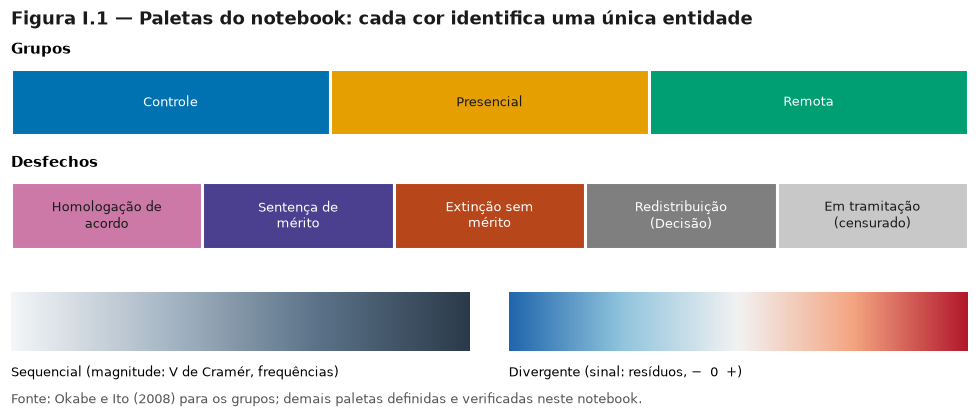

In [4]:
_MACHADO = {
    'protanopia': np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    'deuteranopia': np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
}


def _linear(cor):
    c = np.array(mpl.colors.to_rgb(cor))
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _oklab(rgb_linear):
    rgb_linear = np.clip(rgb_linear, 0, 1)
    lms = np.array([[0.4122214708, 0.5363325363, 0.0514459929], [0.2119034982, 0.6806995451, 0.1073969566],
                    [0.0883024619, 0.2817188376, 0.6299787005]]) @ rgb_linear
    return np.array([[0.2104542553, 0.7936177850, -0.0040720468], [1.9779984951, -2.4285922050, 0.4505937099],
                     [0.0259040371, 0.7827717662, -0.8086757660]]) @ np.cbrt(lms)


def delta_e(a, b, simulacao=None):
    """ΔE OKLab (×100) entre duas cores, opcionalmente sob simulação de daltonismo (Machado et al., 2009)."""
    A, B = _linear(a), _linear(b)
    if simulacao:
        A, B = _MACHADO[simulacao] @ A, _MACHADO[simulacao] @ B
    return 100 * float(np.linalg.norm(_oklab(A) - _oklab(B)))


def relatorio_cvd(nome, cores, pares):
    linhas = []
    for a, b in pares:
        d = {'Paleta': nome, 'Par': f'{a} × {b}', 'ΔE normal': delta_e(cores[a], cores[b])}
        for s in _MACHADO:
            d[f'ΔE {s}'] = delta_e(cores[a], cores[b], s)
        linhas.append(d)
    return linhas


_pares_grupo = [(a, b) for i, a in enumerate(ORDEM_GRUPO) for b in ORDEM_GRUPO[i + 1:]]
_pares_desf = list(zip(ORDEM_DESFECHO[:-1], ORDEM_DESFECHO[1:]))           # vizinhos nas barras empilhadas
_cromaticos = ['Homologação', 'Mérito', 'Sem mérito']
_cruzadas = {**{f'grupo {g}': CORES_GRUPO[g] for g in ORDEM_GRUPO}, **{f'desfecho {k}': CORES_DESFECHO[k] for k in _cromaticos}}
_pares_cruz = [(f'grupo {g}', f'desfecho {k}') for g in ORDEM_GRUPO for k in _cromaticos]
cvd = pd.DataFrame(relatorio_cvd('Grupos (todos os pares)', CORES_GRUPO, _pares_grupo)
                   + relatorio_cvd('Desfechos (vizinhos)', CORES_DESFECHO, _pares_desf)
                   + relatorio_cvd('Grupo × desfecho (mesmo gráfico)', _cruzadas, _pares_cruz))
cvd['Pior simulado'] = cvd[['ΔE protanopia', 'ΔE deuteranopia']].min(axis=1)
cvd['Situação'] = np.select([(cvd['Pior simulado'] >= 8) & (cvd['ΔE normal'] >= 15), cvd['Pior simulado'] >= 6],
                            ['passa', 'passa com rótulo/legenda'], 'exige 2º canal (forma, posição)')
resumo_cvd = cvd.groupby('Paleta', sort=False).agg(**{'Pares': ('Par', 'size'), 'Menor ΔE normal': ('ΔE normal', 'min'),
                                                      'Menor ΔE simulado': ('Pior simulado', 'min')})
tabela(resumo_cvd, 'cur_cvd_resumo', 'Distância perceptual mínima entre as cores de cada paleta (ΔE OKLab × 100)',
       secao='1.2.1', casas=1,
       nota='simulação de Machado, Oliveira e Fernandes (2009), severidade 1,0; alvo ≥ 8 sob simulação e ≥ 15 sem simulação. '
            'A linha "grupo × desfecho" é informativa: grupos e desfechos só dividem o mesmo gráfico quando a forma '
            '(linha × marcador) também os distingue.')
_fracos = cvd[cvd['Situação'] != 'passa']
if len(_fracos):
    print('Pares abaixo do alvo (exigem segundo canal):')
    for _, r in _fracos.iterrows():
        print(f"  {r['Par']}: ΔE normal {fmt_br(r['ΔE normal'])}; pior simulado {fmt_br(r['Pior simulado'])} → {r['Situação']}")

# Mapas sequencial e divergente: luminosidade OKLab monotônica
_L = lambda mapa, xs: [_oklab(_linear(mapa(x)))[0] for x in xs]
_seq_L = _L(SEQ, np.linspace(0, 1, 11))
_div_L = _L(DIV, np.linspace(0, 1, 11))
print('Sequencial: luminosidade decrescente (claro → escuro):', all(np.diff(_seq_L) < 0))
print('Divergente: luminosidade cresce até o meio e decresce depois:',
      all(np.diff(_div_L[:6]) > 0) and all(np.diff(_div_L[5:]) < 0))

fig, ax = plt.subplots(3, 1, figsize=(9, 3.4), gridspec_kw={'height_ratios': [1, 1, 0.8]})
for a, (nome, cores_) in zip(ax[:2], [('Grupos', {g: CORES_GRUPO[g] for g in ORDEM_GRUPO}),
                                       ('Desfechos', {ROTULO_DESFECHO[k]: CORES_DESFECHO[k] for k in ORDEM_DESFECHO})]):
    for i, (rot, cor) in enumerate(cores_.items()):
        a.barh(0, 1, left=i, color=cor, edgecolor='white', linewidth=2)
        a.text(i + 0.5, 0, quebra(rot, 14), ha='center', va='center', fontsize=8.5, color=_cor_texto(cor))
    a.set_xlim(0, len(cores_)); a.set_axis_off(); a.set_title(nome, loc='left', fontsize=10)
gradiente = np.linspace(0, 1, 256)[None, :]
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=SEQ, extent=(0, 0.48, 0, 1))
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=DIV, extent=(0.52, 1, 0, 1))
ax[2].set_xlim(0, 1); ax[2].set_axis_off()
ax[2].text(0, -0.25, 'Sequencial (magnitude: V de Cramér, frequências)', fontsize=8.5, va='top', transform=ax[2].transAxes)
ax[2].text(0.52, -0.25, 'Divergente (sinal: resíduos, −  0  +)', fontsize=8.5, va='top', transform=ax[2].transAxes)
figura(fig, 'cur_paletas', 'Paletas do notebook: cada cor identifica uma única entidade', secao='1.2.1',
       fonte='Fonte: Okabe e Ito (2008) para os grupos; demais paletas definidas e verificadas neste notebook.')

---

## 1.3 Formação do dataset bruto

### 1.3.1 As abas da planilha

O arquivo tem oito abas, mas só uma contém dados por processo. As demais são painéis, tabelas dinâmicas e listas de validação construídas **a partir** da aba `Processos`; servem apenas para conferência (seção 1.14).

In [5]:
livro = openpyxl.load_workbook(BRUTO, data_only=False)   # fórmulas, não valores
PAPEL_ABA = {
    'Processos': 'Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica',
    'Dash1': 'Painel (segmentações/gráficos), sem dados',
    'Dash2': 'Painel (segmentações/gráficos), sem dados',
    'Dash3': 'Painel (segmentações/gráficos), sem dados',
    'Tab_D': 'Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)',
    'Tabelas': 'Resumos com fórmulas (acordos, "eficiência" por rito)',
    'Resumo': 'Questionário de perguntas descritivas (valores vazios no cache)',
    'Lista': 'Listas das validações de dados (valores permitidos nas colunas)',
}
abas = pd.DataFrame([{
    'Aba': ws.title,
    'Visibilidade': 'oculta' if ws.sheet_state != 'visible' else 'visível',
    'Intervalo usado': ws.dimensions,
    'Células preenchidas': sum(c.value is not None for linha in ws.iter_rows() for c in linha),
    'Papel': PAPEL_ABA.get(ws.title, ''),
} for ws in livro.worksheets])
tabela(abas, 'cur_abas', 'Abas da planilha e o papel de cada uma: só a aba Processos tem dados por processo', secao='1.3.1')

ws = livro['Processos']
print('Tabela Excel na aba Processos:', {nome: ref for nome, ref in ws.tables.items()})
print('Colunas ocultas:', [c for c, d in ws.column_dimensions.items() if d.hidden])
print('Linha 1 (acima do cabeçalho):', [ws.cell(1, c).value for c in range(1, 16)])

Aba,Visibilidade,Intervalo usado,Células preenchidas,Papel
Processos,visível,A2:O946,13.317,Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica
Dash1,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash2,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash3,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Tab_D,oculta,A1:BG144,351,"Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)"
Tabelas,visível,A2:AL49,623,"Resumos com fórmulas (acordos, ""eficiência"" por rito)"
Resumo,visível,A2:C25,25,Questionário de perguntas descritivas (valores vazios no cache)
Lista,oculta,A1:I8,26,Listas das validações de dados (valores permitidos nas colunas)


Tabela Excel na aba Processos: {'TAB_DADOS': 'A2:O946'}
Colunas ocultas: ['J', 'M', 'P']
Linha 1 (acima do cabeçalho): [None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


### 1.3.2 Leitura da aba `Processos`

A linha 1 está vazia e o cabeçalho está na linha 2 (`header=1`). O índice de `dados_brutos` passa a ser o **número da linha no Excel** (`linha_excel`), o que permite rastrear cada tratamento até a célula de origem. `dados_brutos` não é modificado em nenhum momento.

In [6]:
dados_brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
dados_brutos.index = pd.RangeIndex(3, 3 + len(dados_brutos), name='linha_excel')

print(f'{dados_brutos.shape[0]} linhas × {dados_brutos.shape[1]} colunas (linhas 3 a {dados_brutos.index[-1]} do Excel)')
print('Nomes das colunas (repr, para ver espaços):')
print([c for c in dados_brutos.columns])
print(f'Linhas inteiramente vazias: {dados_brutos.isna().all(axis=1).sum()} | '
      f'números de processo distintos: {dados_brutos["NÚMERO DO PROCESSO"].nunique()}')
tabela(dados_brutos.head(5), 'cur_bruto_amostra', 'As cinco primeiras linhas da aba Processos, como lidas (dados brutos, sem tratamento)',
       secao='1.3.2', indice=True, exportar=False, nota='a primeira coluna (linha_excel) é o número da linha no Excel.')

944 linhas × 15 colunas (linhas 3 a 946 do Excel)
Nomes das colunas (repr, para ver espaços):
['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA', 'DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', ' DURAÇÃO DO PROCESSO', 'STATUS']
Linhas inteiramente vazias: 0 | números de processo distintos: 938


linha_excel,NÚMERO DO PROCESSO,DT. DISTRIBUIÇÃO,SORTEIO,HÍBRIDA,TEVE ACORDO NA AC?,TÉCNICA,TEVE ACORDO FORA DA AC?,SENTENÇA,DT. SENTENÇA,DURAÇÃO-SENT2,DURAÇÃO-TECN,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO DO PROCESSO,STATUS
3,0800001-35.2026.8.20.5004,01/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do feito sem julgamento de mérito,07/01/2026,6,–,6,6,6 dia(s),Encerrado
4,0800024-78.2026.8.20.5004,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,–,–,–,274,–,274,274,274 dia(s),Ativo
5,0808292-43.2025.8.20.5300,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito sem Julgamento de Mérito,09/01/2026,3,–,3,3,3 dia(s),Encerrado
6,0800038-62.2026.8.20.5004,07/01/2026,Ac Obrigatória Presencial,Não,Sim,Desconstrução da Verdade,Não,Extinção do Feito com Homologação do Acordo,22/02/2026,46,46,46,46,46 dia(s),Encerrado
7,0800035-10.2026.8.20.5004,07/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito com Julgamento de Mérito,27/02/2026,51,–,51,51,51 dia(s),Encerrado


**Leitura.**

- **Uma única aba tem dados.** A aba `Processos` (tabela Excel `TAB_DADOS`, intervalo A2:O946) é a fonte de tudo o que vem depois. As abas `Dash1` a `Dash3` estão vazias de dados (só segmentações e gráficos); `Tab_D` e `Lista` estão **ocultas** e contêm as tabelas dinâmicas e as listas de validação; `Tabelas` e `Resumo` são resumos calculados.
- **944 linhas, não 943.** A aba tem 944 linhas de dados (linhas 3 a 946 do Excel), com **938 números de processo distintos**: há números repetidos (seção 1.10). O enunciado fala em 943 processos porque uma linha (920) não tem as fórmulas de duração e de status (seção 1.4).
- **15 colunas, não 11.** Nove são digitadas pela unidade (A a I); seis são calculadas por fórmula (J a O), três delas ocultas (J, M e a coluna vazia P). O nome de uma coluna começa com espaço (`' DURAÇÃO DO PROCESSO'`), detalhe que quebra qualquer código que a procure pelo nome "limpo".

---

## 1.4 Colunas digitadas × colunas calculadas: a data de corte

As colunas J a O da planilha **não são dados**: são fórmulas. Ler as fórmulas (e não apenas os valores) é essencial, porque a duração dos processos sem sentença é calculada com `TODAY()`, uma função **volátil**: cada vez que o arquivo é aberto, o tempo dos processos ativos aumenta, sem que nenhuma informação nova tenha sido coletada. A célula mostra a fórmula de cada coluna calculada e conta quantas linhas têm fórmula.

In [7]:
COLUNAS_CALCULADAS = {'J': 'DURAÇÃO-SENT2', 'K': 'DURAÇÃO-TECN', 'L': 'DURAÇÃO-SORT', 'M': 'DURAÇÃO-PROC',
                      'N': 'DURAÇÃO DO PROCESSO', 'O': 'STATUS'}
ultima = 2 + len(dados_brutos)
formulas = []
for letra, nome in COLUNAS_CALCULADAS.items():
    valores = [ws[f'{letra}{r}'].value for r in range(3, ultima + 1)]
    com_formula = [isinstance(v, str) and v.startswith('=') for v in valores]
    formulas.append({'Coluna': letra, 'Nome': nome,
                     'Linhas com fórmula': sum(com_formula),
                     'Usa TODAY()': 'TODAY()' in str(valores[0]),
                     'Oculta': ws.column_dimensions[letra].hidden,
                     'Fórmula (linha 3)': valores[0]})
tabela(pd.DataFrame(formulas), 'cur_formulas', 'Colunas calculadas por fórmula (J a O): a duração dos ativos depende de TODAY()',
       secao='1.4')

sem_formula = [r for r in range(3, ultima + 1) if not str(ws[f'M{r}'].value or '').startswith('=')]
print('Linhas sem fórmula na coluna M:', sem_formula)
print('Conteúdo da linha', sem_formula[0], ':', [ws[f'{c}{sem_formula[0]}'].value for c in 'ABCDEFGHI'])

Coluna,Nome,Linhas com fórmula,Usa TODAY(),Oculta,Fórmula (linha 3)
J,DURAÇÃO-SENT2,943,Sim,Sim,"=IF(TAB_DADOS[[#This Row],[SENTENÇA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
K,DURAÇÃO-TECN,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[TÉCNICA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
L,DURAÇÃO-SORT,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[SORTEIO]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
M,DURAÇÃO-PROC,943,Sim,Sim,"=ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3))))"
N,DURAÇÃO DO PROCESSO,943,Não,Não,"=IF(TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]="""","""",TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]&"" dia(s)"")"
O,STATUS,943,Não,Não,"=IF(AND(B3="""",I3=""""),"""",IF(AND(NOT(ISBLANK(B3)),NOT(ISBLANK(I3))),""Encerrado"",""Ativo""))"


Linhas sem fórmula na coluna M: [920]
Conteúdo da linha 920 : ['0813782-27.2026.8.20.5004', datetime.datetime(2026, 7, 29, 0, 0), 'Ac Obrigatória Presencial', None, None, None, None, None, None]


Os **valores em cache** (o que o Excel calculou na última gravação e o que o `pandas` lê) revelam a data em que `TODAY()` foi avaliado: para cada processo ativo, `DT. DISTRIBUIÇÃO + DURAÇÃO-PROC` é essa data. Se ela for única, é a data de corte de fato usada pela pesquisadora.

In [8]:
ativos_bruto = dados_brutos['STATUS'].eq('Ativo')
data_referencia = (dados_brutos.loc[ativos_bruto, 'DT. DISTRIBUIÇÃO']
                   + pd.to_timedelta(dados_brutos.loc[ativos_bruto, 'DURAÇÃO-PROC'], unit='D'))
tabela(data_referencia.dt.strftime('%d/%m/%Y').value_counts().rename_axis('Data implícita de TODAY()').rename('Processos ativos').to_frame(),
       'cur_data_today', 'Data em que TODAY() foi avaliado, reconstituída dos valores em cache', secao='1.4')
assert data_referencia.nunique() == 1 and data_referencia.iloc[0] == DATA_CORTE

props = livro.properties
print(f'Última gravação do arquivo: {props.modified} (por {props.lastModifiedBy}); criado em {props.created:%d/%m/%Y}')
print(f'Sentença mais recente: {dados_brutos["DT. SENTENÇA"].max():%d/%m/%Y} | '
      f'distribuição mais recente: {dados_brutos["DT. DISTRIBUIÇÃO"].max():%d/%m/%Y}')
assert dados_brutos['DT. SENTENÇA'].max() <= DATA_CORTE and dados_brutos['DT. DISTRIBUIÇÃO'].max() <= DATA_CORTE

# As quatro durações são a mesma variável (E6): comparação célula a célula onde não nulas
DURACOES = ['DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT']
iguais = pd.DataFrame([{
    'Coluna': c,
    'Não nulas': int(dados_brutos[c].notna().sum()),
    'Iguais a DURAÇÃO-PROC': int((dados_brutos[c] == dados_brutos['DURAÇÃO-PROC']).sum()),
} for c in DURACOES])
texto_igual = (dados_brutos[' DURAÇÃO DO PROCESSO'].str.extract(r'(\d+)')[0].astype(float)
               == dados_brutos['DURAÇÃO-PROC']).sum()
tabela(iguais, 'cur_duracoes_iguais', 'As colunas de duração repetem DURAÇÃO-PROC (mesma variável, E6)', secao='1.4')
print(f'" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em {texto_igual} linhas')

Data implícita de TODAY(),Processos ativos
07/10/2026,209


Última gravação do arquivo: 2026-10-07 19:57:29 (por pvccr); criado em 28/01/2026
Sentença mais recente: 06/10/2026 | distribuição mais recente: 03/08/2026


Coluna,Não nulas,Iguais a DURAÇÃO-PROC
DURAÇÃO-SENT2,943,943
DURAÇÃO-TECN,428,428
DURAÇÃO-SORT,943,943


" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em 943 linhas


**Leitura. A data de corte é 07/10/2026, e precisa ser fixada.**

- **Todas as durações vêm de uma fórmula com `TODAY()`.** As 943 linhas com fórmula calculam `ABS(DT. SENTENÇA − DT. DISTRIBUIÇÃO)` quando há sentença e `ABS(TODAY() − DT. DISTRIBUIÇÃO)` quando não há.
- **Os 209 processos ativos apontam para uma única data: 07/10/2026.** É o dia da última gravação do arquivo (07/10/2026, 19h57) e o que está no nome do arquivo. A sentença mais recente é de 06/10/2026 e a última distribuição, de 03/08/2026, coerentes com essa data.
- **Por que fixar.** Se a planilha for aberta e recalculada hoje (12/11/2026), cada processo ativo "ganha" 36 dias sem nenhuma informação nova. O tempo é, por isso, recalculado em Python a partir das datas, com `DATA_CORTE = 07/10/2026`. O acompanhamento real vai de **65 dias** (distribuídos em 03/08) a **279 dias** (distribuídos em 01/01). A "janela de 218 dias" usada no notebook do professor não corresponde aos dados (E7).
- **As quatro colunas de duração são a mesma variável.** `DURAÇÃO-SENT2` e `DURAÇÃO-SORT` coincidem com `DURAÇÃO-PROC` nas 943 linhas; `DURAÇÃO-TECN` coincide nas 428 em que existe (é a mesma duração, apagada onde a técnica é `**`); o texto `"N dia(s)"` repete o número. Elas só serviam de filtro para as tabelas dinâmicas. Por isso a matriz de correlação do notebook do professor dá r = 1 em todos os pares (E6, E16): correlaciona uma variável consigo mesma.
- **O `ABS()` da fórmula esconderia datas trocadas** (sentença anterior à distribuição). A verificação direta nas datas (seção 1.14) mostra que não há nenhum caso.

---

## 1.5 Estrutura do dado bruto: o que o pandas leu

O `dtype` atribuído pelo `pandas` na leitura não é o tipo estatístico da variável. A coluna *tipos Python presentes* mostra o que realmente existe em cada coluna (por exemplo, `str` e `float` juntos indicam texto com células vazias, `NaN`).

In [9]:
def tipos_presentes(serie):
    """Tipos Python efetivamente presentes nas células não nulas, com contagem."""
    contagem = Counter(type(v).__name__ for v in serie.dropna())
    return ', '.join(f'{t} ({n})' for t, n in contagem.most_common())


perfil_bruto = pd.DataFrame({
    'dtype lido': dados_brutos.dtypes.astype(str),
    'tipos Python presentes': dados_brutos.apply(tipos_presentes),
    'não nulos': dados_brutos.notna().sum(),
    'NaN': dados_brutos.isna().sum(),
    'distintos': dados_brutos.nunique(),
    'exemplo (linha 3)': dados_brutos.iloc[0].astype(str).str.slice(0, 45),
})
tabela(perfil_bruto.rename_axis('Coluna bruta'), 'cur_perfil_bruto', 'Perfil das colunas como lidas pelo pandas: dtype, tipos presentes e ausências',
       secao='1.5', formatos={'dtype lido': 'texto'})

Coluna bruta,dtype lido,tipos Python presentes,não nulos,NaN,distintos,exemplo (linha 3)
NÚMERO DO PROCESSO,str,str (944),944,0,938,0800001-35.2026.8.20.5004
DT. DISTRIBUIÇÃO,datetime64[us],Timestamp (944),944,0,190,2026-01-01 00:00:00
SORTEIO,str,str (944),944,0,3,Rito Atual Ac Opcional
HÍBRIDA,str,str (872),872,72,2,Não
TEVE ACORDO NA AC?,str,str (869),869,75,2,Não
TÉCNICA,str,str (867),867,77,7,**
TEVE ACORDO FORA DA AC?,str,str (736),736,208,3,Não
SENTENÇA,str,str (734),734,210,5,Extinção do feito sem julgamento de mérito
DT. SENTENÇA,datetime64[us],Timestamp (734),734,210,179,2026-01-07 00:00:00
DURAÇÃO-SENT2,float64,float (943),943,1,189,6.0


---

## 1.6 Tipologia estatística das variáveis

A escolha de gráficos, medidas e testes depende do **tipo estatístico** de cada variável, não do `dtype`. A tabela classifica as colunas da planilha e indica o tipo `pandas` adequado a cada uma no dataset *tidy*:

- **nominal** → `category` (sem ordem); **ordinal** → `category` ordenada;
- **binária** → `boolean` (o tipo anulável do pandas, que aceita `<NA>` sem virar `object`);
- **quantitativa discreta** (contagem de dias) → `Int64` (inteiro anulável);
- **data** → `datetime64`; **identificador** → `string` (não é medida: não se calcula média de número de processo).

Note-se que o tempo em dias é discreto por registro, mas é tratado como **contínuo** nos modelos de sobrevivência (com empates). As colunas J a O são descartadas: são derivadas por fórmula, redundantes entre si e dependentes de `TODAY()`.

In [10]:
TIPOLOGIA_BRUTA = pd.DataFrame([
    ('NÚMERO DO PROCESSO', 'Identificador', '—', 'string', 'Mantida como `processo` (limpa e validada)'),
    ('DT. DISTRIBUIÇÃO', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Origem do tempo; gera mês, dia da semana, ordem'),
    ('SORTEIO', 'Qualitativa nominal (3 níveis)', 'nominal', 'category', 'Tratamento sorteado → `grupo`'),
    ('HÍBRIDA', 'Qualitativa binária', 'nominal', 'boolean', 'Adesão ao protocolo (pós-sorteio)'),
    ('TEVE ACORDO NA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('TÉCNICA', 'Qualitativa nominal (6 níveis + "**")', 'nominal', 'category', '`**` → AC não realizada (`ac_realizada`)'),
    ('TEVE ACORDO FORA DA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('SENTENÇA', 'Qualitativa nominal (4 níveis)', 'nominal', 'category', 'Tipo de desfecho; define o evento'),
    ('DT. SENTENÇA', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Fim do tempo quando há desfecho'),
    ('DURAÇÃO-SENT2', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-TECN', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: cópia filtrada de DURAÇÃO-PROC'),
    ('DURAÇÃO-SORT', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-PROC', 'Quantitativa discreta (dias)', 'razão', 'Int64', 'Recalculada pelas datas → `tempo` (com censura)'),
    (' DURAÇÃO DO PROCESSO', 'Texto ("N dia(s)")', '—', '—', 'Descartada: DURAÇÃO-PROC em texto'),
    ('STATUS', 'Qualitativa binária', 'nominal', 'boolean', 'Recalculada pela data → `encerrado`'),
], columns=['Coluna bruta', 'Tipo estatístico', 'Escala de medida', 'dtype adequado', 'Decisão'])
TIPOLOGIA_BRUTA.insert(1, 'dtype lido', TIPOLOGIA_BRUTA['Coluna bruta'].map(dados_brutos.dtypes.astype(str)))
tabela(TIPOLOGIA_BRUTA, 'cur_tipologia', 'Tipologia estatística das colunas da planilha e decisão de tratamento', secao='1.6')

Coluna bruta,dtype lido,Tipo estatístico,Escala de medida,dtype adequado,Decisão
NÚMERO DO PROCESSO,str,Identificador,—,string,Mantida como `processo` (limpa e validada)
DT. DISTRIBUIÇÃO,datetime64[us],Data,intervalar (tempo de calendário),datetime64,"Origem do tempo; gera mês, dia da semana, ordem"
SORTEIO,str,Qualitativa nominal (3 níveis),nominal,category,Tratamento sorteado → `grupo`
HÍBRIDA,str,Qualitativa binária,nominal,boolean,Adesão ao protocolo (pós-sorteio)
TEVE ACORDO NA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
TÉCNICA,str,"Qualitativa nominal (6 níveis + ""**"")",nominal,category,`**` → AC não realizada (`ac_realizada`)
TEVE ACORDO FORA DA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
SENTENÇA,str,Qualitativa nominal (4 níveis),nominal,category,Tipo de desfecho; define o evento
DT. SENTENÇA,datetime64[us],Data,intervalar (tempo de calendário),datetime64,Fim do tempo quando há desfecho
DURAÇÃO-SENT2,float64,Quantitativa discreta (dias),razão,—,"Descartada: fórmula, cópia de DURAÇÃO-PROC"


---

## 1.7 Ausências: `NaN`, `**` e células em branco

A planilha tem **três formas** de "não há valor", que não significam a mesma coisa e não podem ser fundidas:

| Forma | Significado | Exemplo |
|---|---|---|
| `NaN` (célula vazia) | **ainda não informado**: o processo não chegou àquela etapa (quase sempre em tramitação) | `SENTENÇA` vazia num processo ativo |
| `**` | **não se aplica**: a etapa não existe para aquele processo (zero estrutural) | `TÉCNICA = **` no Controle, que não tem audiência |
| texto vazio/espaços | erro de digitação | — |

O notebook do professor tratou `**` como categoria nos gráficos de Pareto e, no Controle, leu "Não" como resposta, quando a pergunta não se aplica (E4, E5).

In [11]:
COLUNAS_DIGITADAS = ['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?',
                     'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA']


def resumo_ausencias(df, colunas):
    linhas = []
    for c in colunas:
        s = df[c]
        texto = s.dropna().astype(str)
        linhas.append({'Coluna': c, 'NaN': int(s.isna().sum()), '"**"': int(texto.eq('**').sum()),
                       'Vazio/espaços': int(texto.str.strip().eq('').sum()),
                       'Válidos': int(s.notna().sum() - texto.eq('**').sum() - texto.str.strip().eq('').sum())})
    return pd.DataFrame(linhas).set_index('Coluna')


tabela(resumo_ausencias(dados_brutos, COLUNAS_DIGITADAS), 'cur_ausencias', 'Três formas de ausência por coluna digitada (linhas da planilha)',
       secao='1.7', nota='NaN = não informado; "**" = não se aplica (zero estrutural).')

Coluna,NaN,"""**""",Vazio/espaços,Válidos
NÚMERO DO PROCESSO,0,0,0,944
DT. DISTRIBUIÇÃO,0,0,0,944
SORTEIO,0,0,0,944
HÍBRIDA,72,0,0,872
TEVE ACORDO NA AC?,75,0,0,869
TÉCNICA,77,515,0,352
TEVE ACORDO FORA DA AC?,208,1,0,735
SENTENÇA,210,0,0,734
DT. SENTENÇA,210,0,0,734


### 1.7.1 Padrões de ausência

Se as ausências dependem da **etapa** do processo, elas aparecem em blocos: quem ainda não teve audiência não tem acordo na AC, técnica, acordo fora nem sentença. A tabela codifica, para cinco colunas, `1` = `NaN` e `0` = preenchido, e cruza o padrão com o status e o grupo sorteado.

In [12]:
COLUNAS_PADRAO = ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']
padrao = dados_brutos[COLUNAS_PADRAO].isna().astype(int).astype(str).agg(''.join, axis=1).rename('padrão')
tabela_padrao = pd.concat([
    pd.crosstab(padrao, dados_brutos['STATUS'].fillna('(vazio)')),
    pd.crosstab(padrao, dados_brutos['SORTEIO']),
], axis=1)
tabela_padrao['Total'] = padrao.value_counts()
tabela_padrao['Linhas (se ≤ 3)'] = padrao.groupby(padrao).apply(
    lambda s: ', '.join(map(str, s.index)) if len(s) <= 3 else '')
tabela(tabela_padrao.sort_values('Total', ascending=False).rename_axis('Padrão (1 = NaN)'), 'cur_padroes_ausencia',
       'Padrões de ausência em cinco colunas, por status e grupo sorteado: as lacunas acompanham a etapa do processo',
       secao='1.7.1', formatos={'Padrão (1 = NaN)': 'texto'},
       nota='ordem das posições no padrão: ' + ', '.join(COLUNAS_PADRAO) + '.')
print('Ordem das colunas no padrão:', COLUNAS_PADRAO)

Padrão (1 = NaN),(vazio),Ativo,Encerrado,Ac Obrigatória Presencial,Ac Remota,Rito Atual Ac Opcional,Total,Linhas (se ≤ 3)
00000,0,0,733,240,225,268,733,
00011,0,132,0,50,36,46,132,
11111,1,71,0,24,48,0,72,
01111,0,3,0,1,2,0,3,"268, 369, 832"
00001,0,2,0,0,2,0,2,"566, 607"
00111,0,1,0,0,1,0,1,249
00100,0,0,1,1,0,0,1,373


Ordem das colunas no padrão: ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']


O mapa abaixo mostra a mesma informação linha a linha, na ordem de chegada dos processos (eixo vertical). Cinza claro = preenchido; azul-acinzentado claro = `**` (não se aplica); ardósia escura = `NaN` (não informado).

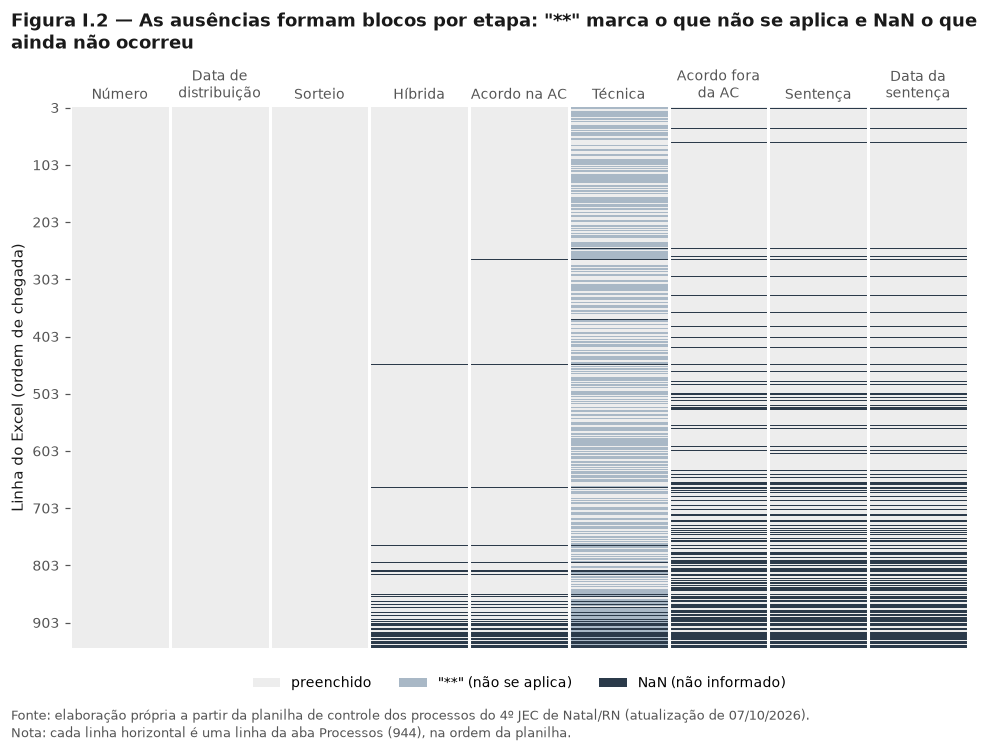

In [13]:
codigo_ausencia = pd.DataFrame({
    c: np.select([dados_brutos[c].isna(), dados_brutos[c].astype(str).eq('**')], [2, 1], 0)
    for c in COLUNAS_DIGITADAS})
CORES_AUSENCIA = ['#EDEDED', '#A9B8C6', '#2B3A4A']   # preenchido, "**", NaN (sem matizes de grupo/desfecho)
fig, ax = plt.subplots(figsize=(9, 6))
mapa = mpl.colors.ListedColormap(CORES_AUSENCIA)
ax.imshow(codigo_ausencia.to_numpy(), aspect='auto', cmap=mapa, interpolation='nearest', vmin=0, vmax=2)
ROTULOS_CURTOS = ['Número', 'Data de distribuição', 'Sorteio', 'Híbrida', 'Acordo na AC', 'Técnica', 'Acordo fora da AC',
                  'Sentença', 'Data da sentença']
ax.set_xticks(range(len(COLUNAS_DIGITADAS)), [quebra(r, 12) for r in ROTULOS_CURTOS])
ax.xaxis.tick_top()
ax.tick_params(axis='x', length=0)
ax.set_yticks(np.arange(0, len(codigo_ausencia), 100), dados_brutos.index[::100])
ax.set_ylabel('Linha do Excel (ordem de chegada)')
ax.grid(False)
for sp_ in ax.spines.values():
    sp_.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(COLUNAS_DIGITADAS)), minor=True)
ax.grid(which='minor', axis='x', color='white', lw=2)
ax.tick_params(which='minor', length=0)
legenda = [mpl.patches.Patch(color=c, label=r) for c, r in
           zip(CORES_AUSENCIA, ['preenchido', '"**" (não se aplica)', 'NaN (não informado)'])]
legenda_abaixo(ax, handles=legenda, ncol=3, dy=-0.03)
figura(fig, 'cur_mapa_ausencias',
       'As ausências formam blocos por etapa: "**" marca o que não se aplica e NaN o que ainda não ocorreu',
       secao='1.7.1', nota='cada linha horizontal é uma linha da aba Processos (944), na ordem da planilha.')

**Leitura. As ausências são estruturais: dependem da etapa em que o processo está.**

- **Não há texto vazio nem espaços soltos**; as ausências são `NaN` (célula vazia) ou o marcador `**`.
- **`**` aparece em duas colunas.** Em `TÉCNICA` (515 linhas) significa que a audiência não foi realizada: todo o Controle e parte dos tratados. Em `ACORDO FORA DA AC?` aparece uma única vez (linha 888), um erro de preenchimento.
- **Os `NaN` formam blocos coerentes com a tramitação:**
  - **733 linhas completas**, todas encerradas;
  - **132 ativos** com audiência já registrada, aguardando o acordo fora e a sentença (padrão `00011`);
  - **72 linhas sem nada após o sorteio** (padrão `11111`): 71 ativos e a linha 920, recém-distribuídos, **todos dos grupos com audiência** (24 Presencial, 48 Remota, 0 Controle). No Controle não há audiência a aguardar, e a unidade já preenche `Não`/`**` na distribuição;
  - **sete linhas com padrões isolados**, listadas na tabela e tratadas nas seções 1.11 e 1.12. A mais relevante é a linha 373: um processo encerrado com a técnica em branco.
- **No mapa, os `NaN` se concentram nas últimas linhas**, as de chegada mais recente. É a assinatura de uma ausência que depende do tempo de acompanhamento, e não de um sorteio ao acaso (não é MCAR).
- **Consequência.** Nenhuma imputação é necessária nem adequada. O desfecho principal (tempo até a sentença) trata a falta de sentença como **censura**. As variáveis de processo (híbrida, técnica, acordo na AC) são analisadas onde se aplicam, com a ausência declarada, e não por exclusão silenciosa de casos incompletos, como fazem os testes do notebook do professor (E5).

---

## 1.8 Cópia de trabalho, nomes das colunas e registro de tratamentos

A partir daqui as transformações acontecem em `trab`, uma cópia de `dados_brutos` com nomes em *snake_case* (minúsculas, sem acento, válidos como identificador Python). As colunas calculadas (J a O) são mantidas na cópia apenas para conferência e descartadas no dataset final.

Cada correção, exclusão ou recodificação é anotada pela função `registrar()` num **log de tratamentos**, com a linha do Excel, o processo, a variável, o valor original, o valor novo, o problema e a justificativa. O código `A`*n* remete ao catálogo de anomalias da auditoria dos dados.

In [14]:
RENOMEAR = {
    'NÚMERO DO PROCESSO': 'numero_bruto', 'DT. DISTRIBUIÇÃO': 'dt_distribuicao', 'SORTEIO': 'sorteio',
    'HÍBRIDA': 'hibrida_bruto', 'TEVE ACORDO NA AC?': 'acordo_ac_bruto', 'TÉCNICA': 'tecnica_bruto',
    'TEVE ACORDO FORA DA AC?': 'acordo_fora_bruto', 'SENTENÇA': 'sentenca_bruto', 'DT. SENTENÇA': 'dt_sentenca',
    'DURAÇÃO-SENT2': 'xl_duracao_sent2', 'DURAÇÃO-TECN': 'xl_duracao_tecn', 'DURAÇÃO-SORT': 'xl_duracao_sort',
    'DURAÇÃO-PROC': 'xl_duracao_proc', ' DURAÇÃO DO PROCESSO': 'xl_duracao_texto', 'STATUS': 'xl_status',
}
trab = dados_brutos.rename(columns=RENOMEAR).copy()
assert set(RENOMEAR) == set(dados_brutos.columns)
assert all(c.isidentifier() and c.isascii() for c in trab.columns)

_registros = []


def registrar(linhas, variavel, valor_novo, problema, tratamento, codigo, valor_original=None):
    """Anota um tratamento para cada linha do Excel informada (valor original lido de dados_brutos)."""
    linhas = [linhas] if np.isscalar(linhas) else list(linhas)
    coluna_bruta = {v: k for k, v in RENOMEAR.items()}.get(variavel)
    for linha in linhas:
        original = valor_original
        if original is None and coluna_bruta is not None:
            original = dados_brutos.at[linha, coluna_bruta]
        _registros.append({'codigo': codigo, 'linha_excel': int(linha),
                           'processo_bruto': dados_brutos.at[linha, 'NÚMERO DO PROCESSO'],
                           'variavel': variavel, 'valor_original': repr(original) if isinstance(original, str) else str(original),
                           'valor_novo': str(valor_novo), 'problema': problema, 'tratamento': tratamento})


def log_tratamentos():
    return pd.DataFrame(_registros)


tabela(pd.DataFrame({'Coluna original': [repr(k) for k in RENOMEAR], 'Nome na cópia de trabalho': list(RENOMEAR.values())}),
       'cur_renomear', 'Nomes das colunas na cópia de trabalho (o repr mostra espaços extras do original)', secao='1.8')

Coluna original,Nome na cópia de trabalho
'NÚMERO DO PROCESSO',numero_bruto
'DT. DISTRIBUIÇÃO',dt_distribuicao
'SORTEIO',sorteio
'HÍBRIDA',hibrida_bruto
'TEVE ACORDO NA AC?',acordo_ac_bruto
'TÉCNICA',tecnica_bruto
'TEVE ACORDO FORA DA AC?',acordo_fora_bruto
'SENTENÇA',sentenca_bruto
'DT. SENTENÇA',dt_sentenca
'DURAÇÃO-SENT2',xl_duracao_sent2


---

## 1.9 Número do processo (CNJ)

O número único segue a Resolução CNJ 65/2008: `NNNNNNN-DD.AAAA.J.TR.OOOO` (sequencial, dígito verificador, ano de ajuizamento, segmento da Justiça, tribunal e órgão de origem). O dígito verificador (DV) é calculado pelo **módulo 97** (ISO 7064): `DD = 98 − (NNNNNNN AAAA J TR OOOO 00 mod 97)`. Validar o DV detecta erros de digitação no número, a chave que permite cruzar a base com o PJe e o DataJud.

A limpeza tem três passos, cada um registrado:

1. remover espaços e quebras de linha nas bordas;
2. remover hífen final digitado por engano;
3. completar o órgão truncado com 3 dígitos, **somente se** o DV confirmar o órgão do estudo (5004 = 4º JEC de Natal).

In [15]:
PADRAO_CNJ = re.compile(r'^(\d{7})-(\d{2})\.(\d{4})\.(\d)\.(\d{2})\.(\d{4})$')


def dv_cnj(sequencial, ano, j, tr, orgao):
    """Dígito verificador CNJ (mod 97, ISO 7064)."""
    return 98 - int(f'{sequencial}{ano}{j}{tr}{orgao}00') % 97


def cnj_valido(numero):
    m = PADRAO_CNJ.fullmatch(str(numero))
    return bool(m) and int(m.group(2)) == dv_cnj(m.group(1), m.group(3), m.group(4), m.group(5), m.group(6))


numero = trab['numero_bruto'].astype('string')
fora = ~numero.map(lambda n: bool(PADRAO_CNJ.fullmatch(n))).astype(bool)
print('Fora do padrão antes da limpeza:', int(fora.sum()), '→ linhas', list(trab.index[fora]))
tabela(numero[fora].map(repr).rename('Valor bruto (repr)').to_frame().rename_axis('Linha do Excel'), 'cur_cnj_fora',
       'Números de processo fora do padrão CNJ antes da limpeza', secao='1.9', formatos={'Linha do Excel': 'texto'})

# Passo 1 — espaços e quebras de linha
passo1 = numero.str.strip()
alterado = trab.index[passo1 != numero]
registrar(alterado, 'numero_bruto', '(sem espaços)', 'Espaço ou quebra de linha no fim do número',
          'strip()', 'A7')

# Passo 2 — hífen final
passo2 = passo1.str.replace(r'\s*-\s*$', '', regex=True)
alterado = trab.index[passo2 != passo1]
registrar(alterado, 'numero_bruto', '(sem hífen final)', 'Hífen digitado após o número', 'Sufixo removido', 'A7')

# Passo 3 — órgão truncado (3 dígitos): candidatos que fecham o DV
truncado = passo2.str.match(r'^\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{3}$')
candidatos = {}
for linha in trab.index[truncado]:
    seq, dv, ano, j, tr, _ = re.split(r'[-.]', passo2[linha])
    candidatos[linha] = [o for o in range(5000, 5400) if dv_cnj(seq, ano, j, tr, o) == int(dv)]
tabela(pd.DataFrame({'Número truncado': passo2[truncado],
                     'Órgãos 5000–5399 com DV válido': pd.Series(candidatos).map(lambda l: ', '.join(map(str, l)))}
                    ).rename_axis('Linha do Excel'),
       'cur_cnj_truncado', 'Números com órgão truncado: órgãos candidatos que fecham o dígito verificador', secao='1.9',
       formatos={'Linha do Excel': 'texto'})
passo3 = passo2.copy()
for linha, lista in candidatos.items():
    assert 5004 in lista, f'linha {linha}: DV não fecha com 5004'
    passo3[linha] = passo2[linha] + '4'
registrar(list(candidatos), 'numero_bruto', '(órgão 5004)', 'Órgão de origem com 3 dígitos ("500")',
          'Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido', 'A8')

trab['processo'] = passo3
trab['cnj_corrigido'] = trab.index.isin(trab.index[(passo3 != numero.str.strip())])
partes = trab['processo'].str.extract(PADRAO_CNJ)
partes.columns = ['seq', 'dv', 'ano', 'j', 'tr', 'orgao']
trab['dv_valido'] = trab['processo'].map(cnj_valido)
trab['cnj_ano'] = partes['ano'].astype('Int64')
trab['cnj_orgao'] = partes['orgao']
print(f'Após a limpeza: {int(partes["seq"].notna().sum())} no padrão; DV válido em {int(trab["dv_valido"].sum())}; '
      f'J.TR = {sorted((partes["j"] + "." + partes["tr"]).unique())}')
assert trab['dv_valido'].all()

Fora do padrão antes da limpeza: 6 → linhas [55, 377, 443, 453, 692, 771]


Linha do Excel,Valor bruto (repr)
55,'0800780-87.2026.8.20.5004-'
377,'0805750-33.2026.8.20.5004\xa0-'
443,'0806633-77.2026.8.20.500'
453,'0806739-39.2026.8.20.500'
692,'0809702-20.2026.8.20.5004 '
771,'0811548-72.2026.8.20.5004\n'


Linha do Excel,Número truncado,Órgãos 5000–5399 com DV válido
443,0806633-77.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"
453,0806739-39.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"


Após a limpeza: 944 no padrão; DV válido em 944; J.TR = ['8.20']


### 1.9.1 Processos de outro órgão ou de ano anterior

O órgão `5004` é o 4º JEC de Natal e o ano esperado é 2026. Números de outro órgão ou de ano anterior indicam processos **ajuizados em outra unidade e redistribuídos** ao 4º JEC: a "data de distribuição" da planilha é a data de chegada à vara, não a do ajuizamento. Eles são mantidos (entraram no sorteio quando chegaram, e o relógio do estudo começa ali), marcados com `origem_externa` para análise de sensibilidade.

In [16]:
trab['origem_externa'] = trab['cnj_orgao'].ne('5004') | trab['cnj_ano'].lt(2026)
tabela(pd.crosstab([trab['cnj_ano'].astype(str).rename('Ano (CNJ)'), trab['cnj_orgao'].rename('Órgão (CNJ)')],
                   trab['sorteio'], margins=True, margins_name='Total'),
       'cur_cnj_orgao_ano', 'Ano e órgão de origem do número CNJ por grupo sorteado (linhas da planilha)', secao='1.9.1', indice=True)
registrar(trab.index[trab['origem_externa']], 'numero_bruto', 'origem_externa=True',
          'Número de outro órgão ou de ano anterior (processo redistribuído à vara)',
          'Mantido; flag origem_externa para sensibilidade', 'A9', valor_original='(órgão/ano)')
print(f'origem_externa: {int(trab["origem_externa"].sum())} linhas')

origem_externa: 12 linhas


---

## 1.10 Duplicidades e reentradas

A unidade experimental é o **processo**: cada um deve aparecer uma vez, com o grupo do seu sorteio. Depois da limpeza do número, há processos com mais de uma linha. A tabela mostra todos, para que a regra de decisão seja verificável:

In [17]:
duplicados = trab[trab['processo'].duplicated(keep=False)].sort_values(['processo', 'dt_distribuicao'])
tabela(duplicados[['processo', 'dt_distribuicao', 'sorteio', 'tecnica_bruto', 'sentenca_bruto', 'dt_sentenca', 'xl_status']]
       .rename_axis('Linha do Excel').rename(columns={'processo': 'Processo', 'dt_distribuicao': 'Distribuição', 'sorteio': 'Sorteio',
                                                       'tecnica_bruto': 'Técnica', 'sentenca_bruto': 'Sentença',
                                                       'dt_sentenca': 'Data da sentença', 'xl_status': 'STATUS'}),
       'cur_duplicados', 'Números de processo repetidos: reentradas após redistribuição, às vezes sorteadas para outro grupo',
       secao='1.10', formatos={'Linha do Excel': 'texto', 'Processo': 'texto'})
print(f'{duplicados["processo"].nunique()} números repetidos em {len(duplicados)} linhas; '
      f'{trab["processo"].nunique()} processos distintos')

Linha do Excel,Processo,Distribuição,Sorteio,Técnica,Sentença,Data da sentença,STATUS
162,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,**,Decisão,18/02/2026,Encerrado
164,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,–,–,–,Ativo
290,0804436-52.2026.8.20.5004,18/03/2026,Ac Obrigatória Presencial,**,Decisão,18/03/2026,Encerrado
322,0804436-52.2026.8.20.5004,24/03/2026,Ac Obrigatória Presencial,**,Decisão,09/04/2026,Encerrado
475,0804436-52.2026.8.20.5004,27/04/2026,Rito Atual Ac Opcional,**,Decisão,27/04/2026,Encerrado
591,0808905-44.2026.8.20.5004,20/05/2026,Ac Remota,**,Decisão,21/05/2026,Encerrado
607,0808905-44.2026.8.20.5004,22/05/2026,Ac Remota,**,–,–,Ativo
819,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,–,–,–,Ativo
822,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,**,Extinção do Feito com Homologação do Acordo,16/09/2026,Encerrado
851,0812839-10.2026.8.20.5004,15/07/2026,Ac Remota,Padrões Objetivos,–,–,Ativo


5 números repetidos em 11 linhas; 938 processos distintos


Há duas situações diferentes:

- **Duplicata de registro** (A3, A4): a segunda linha é uma cópia vazia ou desatualizada do mesmo processo, no mesmo grupo. Mantê-la criaria um **falso censurado** (por exemplo, a linha 164 ficaria "ativa" por 236 dias, embora o processo tenha sido redistribuído em 5 dias). → excluir a cópia e manter o registro mais antigo/completo.
- **Reentrada após `Decisão`** (A5): o processo saiu por redistribuição, voltou à vara e foi **sorteado de novo**; o `0804436-52` passou de Presencial para Controle. Reentradas violam a unicidade da unidade experimental e contaminam os grupos (E3). → na base primária, por **intenção de tratar**, vale só o **primeiro episódio**, com o grupo do primeiro sorteio. As alternativas (excluir o processo; unir os episódios) ficam para a análise de sensibilidade, a partir do arquivo com todas as linhas.

In [18]:
EXCLUIR_PRIMARIA = {
    164: ('A3', 'Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)'),
    819: ('A3', 'Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho'),
    857: ('A4', 'Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo'),
    322: ('A5', 'Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado'),
    475: ('A5', 'Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo'),
    607: ('A5', 'Reentrada de 0808905-44 um dia após a Decisão; re-sorteado'),
}
# Conferência: toda linha excluída tem o mesmo número que uma linha mantida, e esta é anterior ou igual na data
for linha, (codigo, motivo) in EXCLUIR_PRIMARIA.items():
    mesmos = trab.index[trab['processo'].eq(trab.at[linha, 'processo'])]
    mantidas = [m for m in mesmos if m not in EXCLUIR_PRIMARIA]
    assert len(mantidas) == 1 and trab.at[mantidas[0], 'dt_distribuicao'] <= trab.at[linha, 'dt_distribuicao']
    registrar(linha, 'processo', 'excluída da base primária', motivo,
              f'Excluída; mantida a linha {mantidas[0]} (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)',
              codigo, valor_original=trab.at[linha, 'processo'])

trab['base_primaria'] = ~trab.index.isin(list(EXCLUIR_PRIMARIA))
trab['motivo_exclusao'] = pd.Series({k: f'{v[0]}: {v[1]}' for k, v in EXCLUIR_PRIMARIA.items()},
                                    dtype='string').reindex(trab.index)
trab['duplicado_removido'] = trab['processo'].duplicated(keep=False) & trab['base_primaria']
trab['reentrada'] = trab['processo'].duplicated(keep='first')  # 2º episódio em diante (inclui duplicatas)
assert not trab.loc[trab['base_primaria'], 'processo'].duplicated().any()
print('Base primária:', int(trab['base_primaria'].sum()), 'processos')
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio'), trab['base_primaria'].map({True: 'Mantidas', False: 'Excluídas'}),
                   margins=True, margins_name='Total'),
       'cur_base_primaria', 'Linhas mantidas na base primária e excluídas (duplicata/reentrada), por grupo sorteado', secao='1.10')

Base primária: 938 processos


Sorteio,Excluídas,Mantidas,Total
Ac Obrigatória Presencial,2,314,316
Ac Remota,3,311,314
Rito Atual Ac Opcional,1,313,314
Total,6,938,944


**Leitura.**

- **São 5 números repetidos em 11 linhas**, ou seja, 6 linhas a mais que processos. O notebook do professor contou essas 6 linhas extras como "6 duplicatas" e não as tratou (E3).
- **Três são duplicatas de registro** (linhas 164, 819 e 857): cópias vazias ou desatualizadas do mesmo processo, no mesmo grupo. A linha 164, por exemplo, ficaria "em tramitação" por 236 dias, quando o processo foi redistribuído 5 dias depois de chegar (linha 162).
- **Três são reentradas re-sorteadas** (linhas 322, 475 e 607):
  - o processo `0804436-52` saiu por `Decisão` em 18/03, voltou em 24/03 (Presencial, nova Decisão em 09/04) e voltou de novo em 27/04, quando foi sorteado para o **Controle** (nova Decisão no mesmo dia);
  - o `0808905-44` foi redistribuído em 21/05 e voltou no dia 22/05, sorteado de novo.
- **Lição de desenho.** Um processo que sai e volta não deveria passar por novo sorteio: deveria herdar o grupo original.
- **Base primária: 938 processos** (Controle 313, Presencial 314, Remota 311), cada um com o grupo do primeiro sorteio (intenção de tratar). As 944 linhas ficam preservadas em `ed2_todas_linhas.pkl` para as análises de sensibilidade.

---

## 1.11 Categorias: grafia, partições e recodificações

### 1.11.1 Funções de normalização

Uma variável categórica bem construída é uma **partição** dos casos: exaustiva, disjunta, sem classes vazias e sem sinônimos (a mesma categoria com duas grafias). Três funções garantem isso:

- `limpar_texto` colapsa espaços e quebras de linha e converte texto vazio em `<NA>`;
- `normalizar_chave` gera uma chave de comparação sem acento, em maiúsculas e com espaços simples; duas grafias com a mesma chave são **sinônimos**;
- `para_categoria` aplica um **mapa explícito** (valor original → rótulo) e recusa valores não previstos; `verificar_particao` confere as propriedades com `assert`, de modo que um erro interrompe a execução em vez de passar despercebido.

In [19]:
def limpar_texto(serie):
    """Colapsa espaços/quebras de linha e converte vazio em NA (dtype string)."""
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().replace('', pd.NA)


def normalizar_chave(texto):
    """Chave de comparação: sem acentos, maiúscula, espaços simples (não altera o dado)."""
    if pd.isna(texto):
        return pd.NA
    texto = unicodedata.normalize('NFKD', str(texto))
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', texto).strip().upper()


def para_categoria(serie, mapa, ordem, ordenada=False):
    """Aplica um mapa exaustivo (valor original → rótulo) e devolve dtype category."""
    sem_mapa = sorted(set(serie.dropna().unique()) - set(mapa))
    assert not sem_mapa, f'Valores sem mapeamento: {sem_mapa}'
    rotulos = serie.map(mapa)
    assert set(rotulos.dropna()) <= set(ordem), 'Há rótulos fora da lista de categorias'
    return pd.Series(pd.Categorical(rotulos, categories=ordem, ordered=ordenada), index=serie.index, name=serie.name)


resumo_particoes = []


def verificar_particao(nova, nome, ausentes_permitidos=0):
    """Confere se uma variável category é partição: exaustiva, sem vazias e sem sinônimos."""
    contagem = nova.value_counts(sort=False, dropna=True)
    chaves = pd.Series(contagem.index.astype(str)).map(normalizar_chave)
    resultado = {'Variável': nome, 'Categorias': len(contagem), 'Vazias': int((contagem == 0).sum()),
                 'NA': int(nova.isna().sum()), 'Sinônimos': int(chaves.duplicated().sum()),
                 'Soma = n': int(contagem.sum() + nova.isna().sum()) == len(nova)}
    resultado['Partição válida'] = (resultado['Vazias'] == 0 and resultado['Sinônimos'] == 0
                                    and resultado['NA'] <= ausentes_permitidos and resultado['Soma = n'])
    assert resultado['Partição válida'], f'{nome} não é partição: {resultado}'
    resumo_particoes.append(resultado)
    return contagem


COLUNAS_TEXTO = ['sorteio', 'hibrida_bruto', 'acordo_ac_bruto', 'tecnica_bruto', 'acordo_fora_bruto', 'sentenca_bruto']
diagnostico = []
for c in COLUNAS_TEXTO:
    original = trab[c].astype('string')
    limpo = limpar_texto(trab[c])
    chaves = original.dropna().map(normalizar_chave)
    diagnostico.append({'Variável': c, 'Valores alterados pela limpeza': int((original != limpo).sum()),
                        'Grafias distintas': original.nunique(), 'Chaves distintas': chaves.nunique()})
    trab[c] = limpo
tabela(pd.DataFrame(diagnostico), 'cur_grafias', 'Grafias distintas e chaves normalizadas por coluna categórica', secao='1.11.1')

Variável,Valores alterados pela limpeza,Grafias distintas,Chaves distintas
sorteio,0,3,3
hibrida_bruto,0,2,2
acordo_ac_bruto,0,2,2
tecnica_bruto,0,7,7
acordo_fora_bruto,0,3,3
sentenca_bruto,0,5,4


### 1.11.2 Tipo de sentença: uma variante de caixa e o significado de "Decisão"

`SENTENÇA` tem cinco grafias, mas só quatro chaves: `Extinção do feito sem julgamento de mérito` (minúsculas, 11 casos de janeiro) é a mesma categoria que `Extinção do Feito sem Julgamento de Mérito`. A validação de lista do Excel não distingue maiúsculas, por isso a variante passou.

`Decisão` **não é sentença**. Segundo o pesquisador, é a decisão que remete o processo para redistribuição a outro juízo, por prevenção: o processo **sai da vara** e o seu desfecho deixa de ser observado. Contá-la como sentença, como faz o notebook do professor (E10), encurta artificialmente o tempo dos grupos. Aqui ela vira o desfecho `Redistribuição`, tratado como censura na análise principal e como risco competitivo na complementar (Parte IV).

In [20]:
tabela(trab['sentenca_bruto'].value_counts(dropna=False).rename_axis('Grafia').to_frame('Linhas')
       .assign(Chave=lambda t: t.index.map(normalizar_chave)),
       'cur_sentenca_grafias', 'Grafias do tipo de sentença na planilha e chave normalizada', secao='1.11.2')

MAPA_SENTENCA = {
    'Extinção do Feito com Homologação do Acordo': 'Homologação',
    'Extinção do Feito com Julgamento de Mérito': 'Mérito',
    'Extinção do Feito sem Julgamento de Mérito': 'Sem mérito',
    'Extinção do feito sem julgamento de mérito': 'Sem mérito',
    'Decisão': 'Redistribuição',
}
variante = trab['sentenca_bruto'].eq('Extinção do feito sem julgamento de mérito').fillna(False)
registrar(trab.index[variante], 'sentenca_bruto', 'Sem mérito', 'Variante de caixa (minúsculas)',
          'Recodificada para a forma canônica', 'A6')
decisao = trab['sentenca_bruto'].eq('Decisão').fillna(False)
registrar(trab.index[decisao], 'sentenca_bruto', 'Redistribuição',
          '"Decisão" = remessa para redistribuição por prevenção (não é sentença)',
          'Desfecho Redistribuição; evento=0 (censura) e evento_cr=2 (risco competitivo)', 'A-Dec')

desfecho = trab['sentenca_bruto'].map(MAPA_SENTENCA).where(trab['sentenca_bruto'].notna(), 'Ativo')
trab['tipo_desfecho'] = para_categoria(desfecho, {v: v for v in ORDEM_DESFECHO}, ORDEM_DESFECHO)
tabela(pd.crosstab(trab['sentenca_bruto'].fillna('(vazio)').rename('Sentença (planilha)'), trab['tipo_desfecho']),
       'cur_recod_desfecho', 'Recodificação da sentença da planilha no tipo de desfecho', secao='1.11.2')

Grafia,Linhas,Chave
Extinção do Feito com Julgamento de Mérito,341,EXTINCAO DO FEITO COM JULGAMENTO DE MERITO
Extinção do Feito sem Julgamento de Mérito,275,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO
–,210,–
Extinção do Feito com Homologação do Acordo,81,EXTINCAO DO FEITO COM HOMOLOGACAO DO ACORDO
Decisão,26,DECISAO
Extinção do feito sem julgamento de mérito,11,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO


Sentença (planilha),Homologação,Mérito,Sem mérito,Redistribuição,Ativo
(vazio),0,0,0,0,210
Decisão,0,0,0,26,0
Extinção do Feito com Homologação do Acordo,81,0,0,0,0
Extinção do Feito com Julgamento de Mérito,0,341,0,0,0
Extinção do Feito sem Julgamento de Mérito,0,0,275,0,0
Extinção do feito sem julgamento de mérito,0,0,11,0,0


### 1.11.3 Grupo sorteado

Os rótulos longos da planilha passam a códigos curtos (`Controle`, `Presencial`, `Remota`), com `Controle` como **categoria de referência** (primeira posição). O rótulo descritivo fica em `grupo_rotulo`, para tabelas e legendas.

In [21]:
MAPA_GRUPO = {'Rito Atual Ac Opcional': 'Controle', 'Ac Obrigatória Presencial': 'Presencial', 'Ac Remota': 'Remota'}
trab['grupo'] = para_categoria(trab['sorteio'], MAPA_GRUPO, ORDEM_GRUPO)
trab['grupo_rotulo'] = para_categoria(trab['grupo'].astype('string'), ROTULO_GRUPO, list(ROTULO_GRUPO.values()))
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio (planilha)'), trab['grupo']), 'cur_recod_grupo',
       'Recodificação do grupo sorteado', secao='1.11.3')

Sorteio (planilha),Controle,Presencial,Remota
Ac Obrigatória Presencial,0,316,0
Ac Remota,0,0,314
Rito Atual Ac Opcional,314,0,0


### 1.11.4 Respostas Sim/Não, o `**` em "acordo fora" e a técnica

- **`HÍBRIDA`, `TEVE ACORDO NA AC?`, `TEVE ACORDO FORA DA AC?`** → `boolean` (`Sim` = True, `Não` = False, `NaN` = `<NA>`).
- **`**` em "acordo fora" (linha 888, A10):** processo extinto sem mérito em 8 dias, sem homologação → `False`.
- **`TÉCNICA`:** `**` significa que a AC **não foi realizada** (todo o Controle e parte dos tratados); vira `ac_realizada = False` e `tecnica = <NA>`. `NaN` significa "ainda não informado" (processos ativos sem audiência) → `ac_realizada = <NA>`. Essa separação é a que o notebook do professor não fez (E4).
- **Linha 373 (A11):** processo Presencial **encerrado** sem mérito em 1 dia, com técnica vazia; não houve AC → `**`.
- **Linha 249 (A14):** processo Remota ativo com "acordo na AC = Não" e técnica vazia; mantido `<NA>` (não se imputa).

In [22]:
SIM_NAO = {'Sim': True, 'Não': False}
for bruto, novo in [('hibrida_bruto', 'hibrida'), ('acordo_ac_bruto', 'acordo_ac'), ('acordo_fora_bruto', 'acordo_fora')]:
    valores = trab[bruto]
    if bruto == 'acordo_fora_bruto':
        estrela = valores.eq('**').fillna(False)
        registrar(trab.index[estrela], bruto, False, '"**" em acordo fora da AC (desfecho sem mérito, sem homologação)',
                  'Recodificado para Não (False)', 'A10')
        valores = valores.mask(estrela, 'Não')
    assert set(valores.dropna().unique()) <= set(SIM_NAO), (bruto, valores.unique())
    trab[novo] = valores.map(SIM_NAO).astype('boolean')

tecnica = trab['tecnica_bruto'].copy()
linha_373 = trab.index[tecnica.isna() & trab['tipo_desfecho'].ne('Ativo')]
assert list(linha_373) == [373]
registrar(linha_373, 'tecnica_bruto', '**', 'Técnica vazia em processo encerrado (sem mérito em 1 dia)',
          'Recodificada para "**" (AC não realizada)', 'A11')
tecnica[linha_373] = '**'
registrar(249, 'tecnica_bruto', '<NA>', 'Processo ativo com acordo na AC = Não e técnica vazia',
          'Mantido NA (não imputado)', 'A14')

trab['ac_realizada'] = pd.Series(np.where(tecnica.isna(), pd.NA, tecnica.ne('**')), index=trab.index).astype('boolean')
ORDEM_TECNICA = ['Desconstrução da Verdade', 'Parafraseamento', 'Separação de Pessoas e Problemas',
                 'Padrões Objetivos', 'Teoria do Afago ou do Reforço Positivo',
                 'Análise da Comunicação Verbal e Não-Verbal das Partes']
CURTA_TECNICA = dict(zip(ORDEM_TECNICA, ['Desconstrução', 'Parafraseamento', 'Separação', 'Padrões objetivos',
                                         'Afago', 'Comunicação']))
trab['tecnica'] = para_categoria(tecnica.where(tecnica.ne('**')), {t: t for t in ORDEM_TECNICA}, ORDEM_TECNICA)
trab['tecnica_curta'] = para_categoria(trab['tecnica'].astype('string'), CURTA_TECNICA, list(CURTA_TECNICA.values()))

# Acordo em qualquer momento: lógica de Kleene (True se houve algum; False só se ambos False)
trab['acordo'] = trab['acordo_ac'] | trab['acordo_fora']

_sn = lambda s: s.map({True: 'Sim', False: 'Não'}).astype(object).fillna('<NA>')
tabela(pd.crosstab(trab['tecnica_bruto'].fillna('(NaN)').rename('Técnica (planilha)'),
                   _sn(trab['ac_realizada']).rename('AC realizada'), margins=True, margins_name='Total'),
       'cur_tecnica_ac', 'Técnica registrada × AC realizada: "**" indica que a audiência não ocorreu', secao='1.11.4')
tabela(pd.crosstab([_sn(trab['acordo_ac']).rename('Acordo na AC'), _sn(trab['acordo_fora']).rename('Acordo fora da AC')],
                   trab['tipo_desfecho']),
       'cur_acordos_desfecho', 'Acordo na AC e fora dela × tipo de desfecho', secao='1.11.4', indice=True)

Técnica (planilha),,Não,Sim,Total
(NaN),76,1,0,77
**,0,515,0,515
Análise da Comunicação Verbal e Não-Verbal das Partes,0,0,63,63
Desconstrução da Verdade,0,0,47,47
Padrões Objetivos,0,0,67,67
Parafraseamento,0,0,57,57
Separação de Pessoas e Problemas,0,0,60,60
Teoria do Afago ou do Reforço Positivo,0,0,58,58
Total,76,516,352,944


**Leitura.**

- **Uma só variante de grafia.** Nas seis colunas categóricas, a limpeza de espaços não alterou nenhum valor, e só `SENTENÇA` tem duas grafias para a mesma chave: 11 sentenças de janeiro escritas em minúsculas, unificadas na categoria `Sem mérito` (275 + 11 = **286**). As demais (grupo, híbrida, acordos, técnica) não têm sinônimos.
- **Desfechos nas 944 linhas:** 341 de mérito, 286 sem mérito, 81 homologações de acordo, 26 redistribuições (`Decisão`) e 210 sem desfecho.
- **Técnica e audiência.** 352 linhas têm técnica registrada (AC realizada), 516 têm `**` (as 515 originais mais a linha 373) e 76 seguem `<NA>`, por não haver ainda informação. As seis técnicas aparecem entre 47 (Desconstrução) e 67 (Padrões objetivos) vezes; o "53,85% de padrões objetivos" do resumo expandido não se reproduz nesta versão dos dados.
- **Acordo e sentença são perfeitamente coerentes.** As 81 homologações correspondem exatamente a 17 acordos na AC e 64 fora dela. Não há acordo marcado sem homologação, nem homologação sem acordo, nem acordo nos dois momentos. Por isso `acordo` (qualquer momento) é igual a "sentença homologatória" sempre que é conhecido.
- **`<NA>` nos acordos só ocorre em processos ativos:** 75 sem nenhuma das duas respostas e 133 com "Não" na AC e o acordo fora ainda em aberto. Para um processo em tramitação, "ainda não houve acordo" não é "não houve acordo", e a variável não é preenchida com `False`.

---

## 1.12 Desvios de protocolo e coerência do desenho

O protocolo define o que é possível em cada grupo. Três verificações:

- **Controle sem audiência (A18):** o grupo de rito atual não deveria ter AC, técnica nem acordo na AC. Se isso se confirma, o contraste real do experimento é "**com AC obrigatória × sem AC**".
- **Híbrida na Remota (A12):** por definição do pesquisador, a híbrida é uma AC *presencial* em que uma parte participou à distância (Res. CNJ 481). Uma híbrida no grupo Remota é incongruente.
- **Híbrida sem AC (A13):** marcar "híbrida = Sim" pressupõe que a audiência ocorreu; com técnica `**`, há contradição.

Os casos são **mantidos no grupo sorteado** (análise por intenção de tratar, ITT) e marcados com `desvio_protocolo` para a análise "conforme tratado". A variável `hibrida` é, ela mesma, **pós-sorteio** (decorre do pedido da parte): é adesão parcial ao rito presencial, não um quarto grupo aleatorizado (E11).

In [23]:
coerencia_grupo = pd.DataFrame({
    'AC realizada': trab.groupby('grupo', observed=True)['ac_realizada'].sum(),
    'Técnica registrada': trab.groupby('grupo', observed=True)['tecnica'].count(),
    'Acordo na AC': trab.groupby('grupo', observed=True)['acordo_ac'].sum(),
    'Acordo fora da AC': trab.groupby('grupo', observed=True)['acordo_fora'].sum(),
    'Híbrida = Sim': trab.groupby('grupo', observed=True)['hibrida'].sum(),
    'Linhas': trab.groupby('grupo', observed=True).size(),
})
tabela(coerencia_grupo, 'cur_coerencia', 'Coerência entre o grupo sorteado e o que ocorreu: o Controle não tem AC (zeros estruturais)',
       secao='1.12')
assert coerencia_grupo.loc['Controle', ['AC realizada', 'Técnica registrada', 'Acordo na AC', 'Híbrida = Sim']].eq(0).all()

trab['hibrida_remota'] = (trab['hibrida'].fillna(False) & trab['grupo'].eq('Remota')).astype(bool)
trab['hibrida_sem_ac'] = (trab['hibrida'].fillna(False) & trab['ac_realizada'].eq(False).fillna(False)).astype(bool)
trab['desvio_protocolo'] = trab['hibrida_remota'] | trab['hibrida_sem_ac']
registrar(trab.index[trab['hibrida_remota']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Audiência híbrida no grupo Remota (protocolo prevê híbrida só na presencial)',
          'Mantido no grupo sorteado (ITT); flag hibrida_remota', 'A12')
registrar(trab.index[trab['hibrida_sem_ac']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Híbrida = Sim com técnica "**" (AC não realizada): contraditório',
          'Mantido; flag hibrida_sem_ac; consultar a pesquisadora', 'A13')
tabela(trab.loc[trab['desvio_protocolo'], ['processo', 'grupo', 'hibrida', 'tecnica_bruto', 'tipo_desfecho',
                                           'hibrida_remota', 'hibrida_sem_ac']].rename_axis('Linha do Excel'),
       'cur_desvios', 'Processos com desvio de protocolo (marcados para análise de sensibilidade)', secao='1.12',
       formatos={'Linha do Excel': 'texto', 'processo': 'texto'})

grupo,AC realizada,Técnica registrada,Acordo na AC,Acordo fora da AC,Híbrida = Sim,Linhas
Controle,0,0,0,21,0,314
Presencial,178,178,9,16,28,316
Remota,174,174,8,27,3,314


Linha do Excel,processo,grupo,hibrida,tecnica_bruto,tipo_desfecho,hibrida_remota,hibrida_sem_ac
318,0804822-82.2026.8.20.5004,Remota,Sim,Separação de Pessoas e Problemas,Mérito,Sim,Não
433,0806545-39.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
455,0806829-47.2026.8.20.5004,Presencial,Sim,**,Homologação,Não,Sim
456,0806797-42.2026.8.20.5004,Remota,Sim,Teoria do Afago ou do Reforço Positivo,Ativo,Sim,Não
712,0810564-88.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
832,0812493-59.2026.8.20.5004,Remota,Sim,–,Ativo,Sim,Não


### 1.12.1 As redistribuições (`Decisão`)

Quando ocorrem as redistribuições? Se quase todas acontecem nos primeiros dias, antes de qualquer audiência, o processo saiu do estudo antes de poder receber o tratamento.

In [24]:
redist = trab[trab['tipo_desfecho'].eq('Redistribuição')].copy()
redist['dias'] = (redist['dt_sentenca'] - redist['dt_distribuicao']).dt.days
print(f'{len(redist)} redistribuições (todas as linhas); na base primária: {int(redist["base_primaria"].sum())}')
tabela(redist.groupby('grupo', observed=True)['dias'].describe()[['count', 'min', '50%', 'mean', 'max']]
       .rename(columns={'count': 'n', 'min': 'Mínimo (dias)', '50%': 'Mediana (dias)', 'mean': 'Média (dias)', 'max': 'Máximo (dias)'})
       .rename_axis('Grupo'),
       'cur_redistribuicoes', 'Dias da distribuição até a Decisão de redistribuição, por grupo (todas as linhas)',
       secao='1.12.1', casas=1)
tabela(redist.loc[redist['ac_realizada'].fillna(False), ['processo', 'grupo', 'tecnica', 'dias']]
       .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'tecnica': 'Técnica', 'dias': 'Dias até a Decisão'}),
       'cur_redist_com_ac', 'Redistribuições ocorridas depois de uma AC realizada', secao='1.12.1',
       indice=False, formatos={'Processo': 'texto'})

26 redistribuições (todas as linhas); na base primária: 24


Grupo,n,Mínimo (dias),Mediana (dias),Média (dias),Máximo (dias)
Controle,6,0,1,"4,2",20
Presencial,11,0,1,"3,0",16
Remota,9,1,8,"25,4",84


Processo,Grupo,Técnica,Dias até a Decisão
0805907-06.2026.8.20.5004,Remota,Teoria do Afago ou do Reforço Positivo,84
0808552-04.2026.8.20.5004,Remota,Padrões Objetivos,74


**Leitura.**

- **O Controle não teve nenhuma audiência.** São 0 audiências, 0 técnicas, 0 acordos na AC e 0 híbridas em 314 processos. O contraste real do experimento é, portanto, "**AC obrigatória × nenhuma AC**", e não "AC obrigatória × AC opcional". O acordo fora da audiência existe nos três grupos (21 no Controle, 16 na Presencial, 27 na Remota) e é o único desfecho de acordo comparável entre os três.
- **Nem todo tratado teve audiência.** Só 178 dos 316 processos da Presencial (56%) e 174 dos 314 da Remota (55%) têm técnica registrada. Os demais foram extintos antes da audiência (`**`) ou ainda a aguardam (`<NA>`). A análise por intenção de tratar (ITT) compara os **grupos sorteados**, não "quem teve audiência", para não quebrar a aleatorização.
- **Desvios de protocolo em 6 processos, todos mantidos no grupo sorteado e sinalizados:**
  - 3 híbridas no grupo **Remota** (linhas 318, 456 e 832), quando a híbrida, por definição, é uma variação da audiência presencial;
  - 3 híbridas na Presencial com técnica `**` (linhas 433, 455 e 712), o que é contraditório. Uma delas (455) terminou em homologação.
- **A híbrida é adesão parcial, não tratamento.** Ela ocorreu em 28 processos da Presencial, a pedido da parte, e não foi sorteada. Uma comparação "híbrida × presencial" é observacional.
- **As redistribuições são quase sempre imediatas.** A mediana é de 1 dia no Controle e na Presencial e de 8 dias na Remota. Só 2 ocorreram depois da audiência: as linhas 395 (84 dias) e 571 (74 dias), ambas da Remota, que puxam a média desse grupo para 25,4 dias. Em geral, o processo sai da vara antes que o tratamento possa agir, e por isso a `Decisão` é censura ou risco competitivo, nunca sentença (E10).

---

## 1.13 O dataset *tidy*: tempo, evento e variáveis derivadas

### 1.13.1 Tempo e evento

A análise de sobrevivência precisa de dois números por processo:

- **`tempo`** — dias corridos da distribuição até o desfecho (`dt_sentenca`), ou até a **data de corte** (07/10/2026) se não houve desfecho. É recalculado pelas datas; as colunas de duração do Excel não são usadas (A1, A17);
- **`evento`** — `1` se o processo foi **sentenciado** (mérito, sem mérito ou homologação de acordo); `0` se está **censurado**: em tramitação na data de corte ou **redistribuído** (sai da vara no dia da Decisão, sem sentença observada).

Duas codificações complementares:

- **`evento_cr`** (riscos competitivos): `0` = censurado (ativo), `1` = sentença, `2` = redistribuição;
- **`causa`** (desfecho específico): `0` = censurado, `1` = homologação, `2` = mérito, `3` = sem mérito, `4` = redistribuição. Permite estudar, por exemplo, o tempo até a homologação de acordo, que é onde a conciliação atua diretamente.

Há processos com tempo **zero** (desfecho no próprio dia da distribuição). Kaplan-Meier e Cox os aceitam; os modelos paramétricos (AFT) exigem tempo positivo, por isso `tempo_pos` substitui 0 por 0,5 dia (convenção documentada, não imputação; A15).

O **acompanhamento** (`followup`) é o tempo entre a distribuição e a data de corte: o máximo que cada processo poderia ser observado. Como a entrada é escalonada (janeiro a agosto), o acompanhamento varia de 65 a 279 dias, e é por isso que a média simples dos tempos, sem tratar a censura, não é um estimador válido (E7, E14).

In [25]:
CODIGO_CAUSA = {'Ativo': 0, 'Homologação': 1, 'Mérito': 2, 'Sem mérito': 3, 'Redistribuição': 4}
CODIGO_CR = {'Ativo': 0, 'Homologação': 1, 'Mérito': 1, 'Sem mérito': 1, 'Redistribuição': 2}
SENTENCAS = ['Homologação', 'Mérito', 'Sem mérito']

fim = trab['dt_sentenca'].fillna(DATA_CORTE)
trab['tempo'] = (fim - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_pos'] = trab['tempo'].astype('float64').mask(trab['tempo'].eq(0), 0.5)
trab['evento'] = trab['tipo_desfecho'].isin(SENTENCAS).astype('Int64')
trab['evento_cr'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CR).astype('Int64')
trab['causa'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CAUSA).astype('Int64')
trab['encerrado'] = trab['dt_sentenca'].notna().astype('boolean')
trab['followup'] = (DATA_CORTE - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_zero'] = trab['tempo'].eq(0).astype('boolean')
trab['sem_formula_excel'] = trab['xl_duracao_proc'].isna().astype('boolean')

registrar(trab.index[trab['tipo_desfecho'].eq('Ativo')], 'xl_duracao_proc', 'tempo = 07/10/2026 − distribuição',
          'Duração dos ativos calculada com TODAY() (volátil)', 'Censurado em DATA_CORTE fixa; evento=0', 'A1')
registrar(trab.index[trab['sem_formula_excel']], 'xl_duracao_proc', 'tempo = 70; evento = 0',
          'Linha sem nenhuma fórmula (STATUS vazio)', 'Mantida: ativo censurado em 07/10/2026 (data de distribuição válida)', 'A2')
registrar(trab.index[trab['tempo_zero']], 'tempo', 'tempo=0; tempo_pos=0,5',
          'Desfecho no próprio dia da distribuição', 'Mantido; tempo_pos=0,5 só para modelos paramétricos', 'A15',
          valor_original='0')

# Conferência com a coluna DURAÇÃO-PROC do Excel (valores em cache)
confere = trab['tempo'].astype('float64').eq(trab['xl_duracao_proc'])
print(f'tempo recalculado = DURAÇÃO-PROC do Excel em {int(confere.sum())} de {len(trab)} linhas; '
      f'divergentes: {list(trab.index[~confere])} (sem fórmula no Excel)')

tempo recalculado = DURAÇÃO-PROC do Excel em 943 de 944 linhas; divergentes: [920] (sem fórmula no Excel)


### 1.13.2 Variáveis de calendário e ordem de chegada

Segundo o pesquisador, o sorteio "seguiu rigorosamente a ordem de chegada" dos processos, e as linhas da planilha estão nessa ordem (a data de distribuição nunca decresce de uma linha para a seguinte). Derivam-se:

- **`ordem_chegada`** — posição do processo na sequência de chegada da base primária (1 = primeiro); variável **ordinal**, usada na questão 2.7;
- **`dia_estudo`** — dias desde 01/01/2026 (tempo de calendário da entrada, quantitativo);
- **`mes_distribuicao`** — mês de entrada (ordinal); como a censura depende do mês de entrada, é a covariável natural de estratificação;
- **`ciclo`** — os "dois ciclos" do resumo expandido: 01/01–28/04 e 29/04–03/08/2026;
- **`dia_semana_distribuicao`** e **`sentenca_fim_semana`** — sentenças em sábado ou domingo sugerem que a data registrada pode ser a de **lançamento** no sistema (ou de mutirão), não a da assinatura (A16).

In [26]:
assert trab['dt_distribuicao'].is_monotonic_increasing, 'linhas fora da ordem cronológica'
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
MESES = {1: 'jan', 2: 'fev', 3: 'mar', 4: 'abr', 5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago'}

trab['dia_estudo'] = (trab['dt_distribuicao'] - DATA_INICIO).dt.days.astype('Int64')
trab['mes_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.month.map(MESES),
                                          categories=list(MESES.values()), ordered=True)
trab['ciclo'] = pd.Categorical(np.where(trab['dt_distribuicao'] <= pd.Timestamp('2026-04-28'), '1º ciclo', '2º ciclo'),
                               categories=['1º ciclo', '2º ciclo'], ordered=True)
trab['dia_semana_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.dayofweek.map(dict(enumerate(DIAS))),
                                                 categories=DIAS, ordered=True)
trab['sentenca_fim_semana'] = pd.Series(pd.NA, index=trab.index, dtype='boolean')
tem_data = trab['dt_sentenca'].notna()
trab.loc[tem_data, 'sentenca_fim_semana'] = trab.loc[tem_data, 'dt_sentenca'].dt.dayofweek.ge(5)
registrar(trab.index[trab['sentenca_fim_semana'].fillna(False)], 'dt_sentenca', '(mantida)',
          'Sentença datada em sábado ou domingo (possível data de lançamento/lote)',
          'Mantida; flag sentenca_fim_semana; limitação a validar no DataJud', 'A16', valor_original='(fim de semana)')

trab['ordem_chegada'] = pd.Series(pd.NA, index=trab.index, dtype='Int64')
trab.loc[trab['base_primaria'], 'ordem_chegada'] = np.arange(1, int(trab['base_primaria'].sum()) + 1)
print('Sentenças em fim de semana:', int(trab['sentenca_fim_semana'].sum()), 'de', int(tem_data.sum()))
tabela(trab.loc[tem_data].groupby(trab['dt_sentenca'].dt.dayofweek.map(dict(enumerate(DIAS))))
       .size().reindex(DIAS).rename('Sentenças').to_frame().T, 'cur_sentenca_dia_semana',
       'Sentenças por dia da semana da data registrada', secao='1.13.2', indice=False)

Sentenças em fim de semana: 135 de 734


seg,ter,qua,qui,sex,sáb,dom
91,186,149,85,88,70,65


### 1.13.3 Montagem e tipos finais

O dataset final tem uma linha por processo e as colunas na ordem: identificação → calendário → tratamento → processo (audiência, acordo) → desfecho e tempo → *flags* de qualidade. São produzidos dois objetos:

- **`dados_todas`** — as 944 linhas, com `base_primaria` e `motivo_exclusao` (para as análises de sensibilidade);
- **`dados`** — a **base primária** (`base_primaria == True`), usada em todo o restante do notebook.

In [27]:
COLUNAS_TIDY = [
    'processo', 'linha_excel', 'ordem_chegada',
    'dt_distribuicao', 'dia_estudo', 'mes_distribuicao', 'ciclo', 'dia_semana_distribuicao',
    'grupo', 'grupo_rotulo',
    'ac_realizada', 'tecnica', 'tecnica_curta', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo',
    'tipo_desfecho', 'dt_sentenca', 'encerrado', 'tempo', 'tempo_pos', 'evento', 'evento_cr', 'causa', 'followup',
    'cnj_ano', 'cnj_orgao', 'cnj_corrigido', 'origem_externa', 'duplicado_removido', 'sem_formula_excel',
    'sentenca_fim_semana', 'tempo_zero', 'hibrida_remota', 'hibrida_sem_ac', 'desvio_protocolo',
]
dados_todas = trab.reset_index()[COLUNAS_TIDY + ['base_primaria', 'motivo_exclusao', 'reentrada']].copy()
TIPOS = {
    'processo': 'string', 'linha_excel': 'Int64', 'dt_distribuicao': 'datetime64[ns]',
    'dt_sentenca': 'datetime64[ns]', 'cnj_orgao': 'category',
    'cnj_corrigido': 'boolean', 'origem_externa': 'boolean', 'duplicado_removido': 'boolean',
    'hibrida_remota': 'boolean', 'hibrida_sem_ac': 'boolean', 'desvio_protocolo': 'boolean',
    'base_primaria': 'boolean', 'reentrada': 'boolean', 'motivo_exclusao': 'string',
}
dados_todas = dados_todas.astype(TIPOS)
dados = dados_todas.loc[dados_todas['base_primaria'], COLUNAS_TIDY].reset_index(drop=True)

print(f'dados_todas: {dados_todas.shape} | dados (base primária): {dados.shape}')
tabela(dados.dtypes.astype(str).rename('dtype').rename_axis('Variável').to_frame(), 'cur_dtypes_tidy',
       'Tipos finais das variáveis do dataset tidy', secao='1.13.3', formatos={'dtype': 'texto'})
tabela(dados.head(5), 'cur_tidy_amostra', 'As cinco primeiras linhas do dataset tidy (base primária)', secao='1.13.3',
       exportar=False, indice=False)

dados_todas: (944, 40) | dados (base primária): (938, 37)


Variável,dtype
processo,string
linha_excel,Int64
ordem_chegada,Int64
dt_distribuicao,datetime64[ns]
dia_estudo,Int64
mes_distribuicao,category
ciclo,category
dia_semana_distribuicao,category
grupo,category
grupo_rotulo,category


processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
0800001-35.2026.8.20.5004,3,1,01/01/2026,0,jan,1º ciclo,qui,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,07/01/2026,Sim,6,6,1,1,3,279,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não
0800024-78.2026.8.20.5004,4,2,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,–,–,Ativo,–,Não,274,274,0,0,0,274,2.026,5004,Não,Não,Não,Não,–,Não,Não,Não,Não
0808292-43.2025.8.20.5300,5,3,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,09/01/2026,Sim,3,3,1,1,3,274,2.025,5300,Não,Sim,Não,Não,Não,Não,Não,Não,Não
0800038-62.2026.8.20.5004,6,4,07/01/2026,6,jan,1º ciclo,qua,Presencial,AC presencial obrigatória,Sim,Desconstrução da Verdade,Desconstrução,Não,Sim,Não,Sim,Homologação,22/02/2026,Sim,46,46,1,1,1,273,2.026,5004,Não,Não,Não,Não,Sim,Não,Não,Não,Não
0800035-10.2026.8.20.5004,7,5,07/01/2026,6,jan,1º ciclo,qua,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Mérito,27/02/2026,Sim,51,51,1,1,2,273,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não


---

## 1.14 Verificações

### 1.14.1 Asserções de integridade

Cada propriedade que as análises seguintes pressupõem é verificada com `assert`: se alguma falhar, a execução para aqui. Entre elas: unicidade do processo, tempos não negativos e nunca maiores que o acompanhamento, coerência entre `evento`, `evento_cr`, `causa`, `tipo_desfecho` e a data da sentença, e as partições das variáveis categóricas.

In [28]:
n = len(dados)
assert n == 938 and dados['processo'].is_unique
assert dados['grupo'].value_counts().to_dict() == {'Controle': 313, 'Presencial': 314, 'Remota': 311}
assert dados['tempo'].notna().all() and (dados['tempo'] >= 0).all()
assert (dados['tempo'] <= dados['followup']).all() and (dados['followup'] >= 65).all()
assert (dados['dt_sentenca'].dropna() >= dados.loc[dados['dt_sentenca'].notna(), 'dt_distribuicao']).all()
# evento e desfecho
assert (dados['evento'].eq(1) == dados['tipo_desfecho'].isin(SENTENCAS)).all()
assert (dados['evento_cr'].eq(0) == dados['tipo_desfecho'].eq('Ativo')).all()
assert (dados['evento_cr'].eq(2) == dados['tipo_desfecho'].eq('Redistribuição')).all()
assert (dados['encerrado'] == dados['dt_sentenca'].notna()).all()
assert (dados['encerrado'] == dados['evento_cr'].ne(0)).all()
assert (dados.loc[dados['evento_cr'].eq(0), 'tempo'] == dados.loc[dados['evento_cr'].eq(0), 'followup']).all()
assert (dados['causa'].map({0: 'Ativo', 1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'})
        == dados['tipo_desfecho'].astype(str)).all()
# acordo e audiência
assert (dados['acordo'].fillna(False) == dados['tipo_desfecho'].eq('Homologação')).all()
assert not (dados['acordo_ac'].fillna(False) & dados['acordo_fora'].fillna(False)).any()
assert not dados.loc[dados['grupo'].eq('Controle'), 'ac_realizada'].fillna(False).any()
assert (dados['tecnica'].notna() == dados['ac_realizada'].fillna(False)).all()
assert not (dados['acordo_ac'].fillna(False) & ~dados['ac_realizada'].fillna(False)).any()
# ordem e calendário
assert dados['ordem_chegada'].tolist() == list(range(1, n + 1))
assert dados['dt_distribuicao'].between(DATA_INICIO, FIM_RECRUTAMENTO).all()

for coluna, na in [('grupo', 0), ('grupo_rotulo', 0), ('tipo_desfecho', 0), ('mes_distribuicao', 0),
                   ('ciclo', 0), ('dia_semana_distribuicao', 0), ('tecnica', n), ('tecnica_curta', n)]:
    verificar_particao(dados[coluna], coluna, ausentes_permitidos=na)
tabela(pd.DataFrame(resumo_particoes), 'cur_particoes', 'Verificação das partições: cada variável categórica cobre todos os processos',
       secao='1.14.1')
print('Todas as verificações passaram.')

Variável,Categorias,Vazias,NA,Sinônimos,Soma = n,Partição válida
grupo,3,0,0,0,Sim,Sim
grupo_rotulo,3,0,0,0,Sim,Sim
tipo_desfecho,5,0,0,0,Sim,Sim
mes_distribuicao,8,0,0,0,Sim,Sim
ciclo,2,0,0,0,Sim,Sim
dia_semana_distribuicao,7,0,0,0,Sim,Sim
tecnica,6,0,586,0,Sim,Sim
tecnica_curta,6,0,586,0,Sim,Sim


Todas as verificações passaram.


### 1.14.2 Fluxo dos processos e composição dos desfechos

À maneira de um diagrama CONSORT, a tabela acompanha os processos desde as linhas da planilha até a base primária e a situação na data de corte, por grupo.

In [29]:
def contar(df, grupo):
    sub = df[df['grupo'].eq(grupo)] if grupo != 'Total' else df
    return sub


fluxo = {}
for g in ORDEM_GRUPO + ['Total']:
    todas = contar(dados_todas, g)
    prim = contar(dados, g)
    fluxo[g] = {
        'Linhas na planilha': len(todas),
        'Excluídas (duplicata/reentrada)': int((~todas['base_primaria']).sum()),
        'Base primária': len(prim),
        'Sentença — homologação de acordo': int(prim['causa'].eq(1).sum()),
        'Sentença — mérito': int(prim['causa'].eq(2).sum()),
        'Sentença — sem mérito': int(prim['causa'].eq(3).sum()),
        'Eventos (sentenças)': int(prim['evento'].sum()),
        'Redistribuição (censura / risco competitivo)': int(prim['evento_cr'].eq(2).sum()),
        'Em tramitação em 07/10/2026 (censurado)': int(prim['evento_cr'].eq(0).sum()),
        'Acompanhamento mediano (dias)': fmt_br(float(prim['followup'].median()), 1),
        'origem_externa': int(prim['origem_externa'].sum()),
        'desvio_protocolo': int(prim['desvio_protocolo'].sum()),
    }
fluxo = pd.DataFrame(fluxo).astype(object)
tabela(fluxo.rename_axis('Etapa'), 'cur_fluxo', 'Fluxo dos processos, da planilha à situação em 07/10/2026, por grupo',
       secao='1.14.2', formatos={c: 'texto' for c in fluxo.columns})
assert fluxo.loc['Base primária', 'Total'] == (fluxo.loc['Eventos (sentenças)', 'Total']
                                               + fluxo.loc['Redistribuição (censura / risco competitivo)', 'Total']
                                               + fluxo.loc['Em tramitação em 07/10/2026 (censurado)', 'Total'])

Etapa,Controle,Presencial,Remota,Total
Linhas na planilha,314,316,314,944
Excluídas (duplicata/reentrada),1,2,3,6
Base primária,313,314,311,938
Sentença — homologação de acordo,21,25,35,81
Sentença — mérito,162,96,83,341
Sentença — sem mérito,79,109,98,286
Eventos (sentenças),262,230,216,708
Redistribuição (censura / risco competitivo),5,10,9,24
Em tramitação em 07/10/2026 (censurado),46,74,86,206
Acompanhamento mediano (dias),"170,0","162,0","161,0","164,0"


### 1.14.3 Conferência com os números da pesquisadora

As abas `Tab_D` e `Tabelas` e o resumo expandido trazem contagens que podem ser refeitas com o dataset *tidy*. A conferência usa **todas as 944 linhas** (como a pesquisadora) e mostra, ao lado, o valor na base primária. Diferenças em relação ao resumo expandido refletem a data da versão (o texto usou uma extração anterior, com mais processos ativos).

In [30]:
t = dados_todas
conf = pd.DataFrame([
    ('Processos (linhas com STATUS)', '943 (Tab_D)', int(t['linha_excel'].ne(920).sum()), n),
    ('Encerrados (STATUS)', '734 (Tab_D)', int(t['encerrado'].sum()), int(dados['encerrado'].sum())),
    ('Ativos (STATUS preenchido; a base primária inclui a linha 920)', '209 (Tab_D)',
     int((~t['encerrado'] & ~t['sem_formula_excel']).sum()), int((~dados['encerrado']).sum())),
    ('Acordos (homologações)', '81 (Tabelas)', int(t['acordo'].fillna(False).sum()), int(dados['acordo'].fillna(False).sum())),
    ('Acordos na AC — P / R / O', '9 / 8 / 0 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Acordos fora da AC — P / R / O', '16 / 27 / 21 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Sentenciados / ativos (resumo expandido)', '668 / 275 (DOCX)',
     f'{int(t["evento"].sum())} / {int(t["evento_cr"].eq(0).sum())}', f'{int(dados["evento"].sum())} / {int(dados["evento_cr"].eq(0).sum())}'),
], columns=['Indicador', 'Pesquisadora', 'Recalculado (944 linhas)', 'Base primária (938)'])
tabela(conf.astype(str), 'cur_conferencia', 'Conferência com os números divulgados pela pesquisadora', secao='1.14.3')

Indicador,Pesquisadora,Recalculado (944 linhas),Base primária (938)
Processos (linhas com STATUS),943 (Tab_D),943,938
Encerrados (STATUS),734 (Tab_D),734,732
Ativos (STATUS preenchido; a base primária inclui a linha 920),209 (Tab_D),209,206
Acordos (homologações),81 (Tabelas),81,81
Acordos na AC — P / R / O,9 / 8 / 0 (Tabelas),9 / 8 / 0,9 / 8 / 0
Acordos fora da AC — P / R / O,16 / 27 / 21 (Tabelas),16 / 27 / 21,16 / 27 / 21
Sentenciados / ativos (resumo expandido),668 / 275 (DOCX),708 / 210,708 / 206


**Leitura.**

- **Todas as asserções passaram.** Isso garante, entre outros pontos:
  - um processo por linha;
  - nenhum tempo negativo (portanto, o `ABS()` do Excel não escondia nada);
  - nenhum tempo maior que o acompanhamento;
  - acompanhamento mínimo de 65 dias;
  - `evento`, `evento_cr`, `causa`, `tipo_desfecho`, `encerrado` e a data da sentença mutuamente coerentes;
  - nenhuma audiência no Controle.

  As oito variáveis categóricas formam partições válidas.
- **Base primária: 938 processos, com 708 sentenças (eventos), 24 redistribuições e 206 em tramitação em 07/10/2026.**

| Grupo | n | Homologação | Mérito | Sem mérito | Redistribuição | Em tramitação |
|---|---|---|---|---|---|---|
| Controle | 313 | 21 | 162 | 79 | 5 | 46 |
| Presencial | 314 | 25 | 96 | 109 | 10 | 74 |
| Remota | 311 | 35 | 83 | 98 | 9 | 86 |

- **A censura é desigual entre os grupos:** 46 processos em tramitação no Controle, 74 na Presencial e 86 na Remota. O acompanhamento mediano é parecido (170, 162 e 161 dias), mas uma censura desigual invalida a comparação de **médias simples** dos tempos, como as do resumo expandido e do notebook do professor. Exige métodos de sobrevivência (Parte IV).
- **Os perfis de desfecho já sugerem diferenças.** O Controle tem mais sentenças de mérito (162) e os grupos com audiência têm mais extinções sem mérito (109 e 98) e mais homologações (25 e 35). É um retrato descritivo, que a Parte III testa formalmente.
- **Os números da pesquisadora são reproduzidos exatamente** com as 944 linhas: 943 com status, 734 encerrados, 209 ativos, 81 acordos, acordos na AC 9 / 8 / 0 e fora da AC 16 / 27 / 21 (P / R / O). Os valores do resumo expandido (668 sentenciados e 275 ativos) não se reproduzem nesta versão da planilha: o texto usou uma extração anterior, com menos desfechos registrados.

---

## 1.15 Log de tratamentos

O log reúne, linha a linha, todas as intervenções feitas sobre os dados brutos. O resumo por código mostra o alcance de cada tratamento; o log completo é exportado em `dat/processado/ed2_log_tratamentos.csv`.

In [31]:
log = log_tratamentos()
resumo_log = (log.groupby(['codigo', 'problema', 'tratamento'], sort=False)
              .agg(linhas=('linha_excel', 'size'),
                   exemplos=('linha_excel', lambda s: ', '.join(map(str, s.head(6))) + (' …' if len(s) > 6 else '')))
              .reset_index())
tabela(resumo_log, 'cur_log_resumo', 'Resumo do log de tratamentos por anomalia e ação', secao='1.15')
print(f'{len(log)} registros no log, {log["linha_excel"].nunique()} linhas distintas do Excel afetadas')

codigo,problema,tratamento,linhas,exemplos
A7,Espaço ou quebra de linha no fim do número,strip(),2,"692, 771"
A7,Hífen digitado após o número,Sufixo removido,2,"55, 377"
A8,"Órgão de origem com 3 dígitos (""500"")",Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido,2,"443, 453"
A9,Número de outro órgão ou de ano anterior (processo redistribuído à vara),Mantido; flag origem_externa para sensibilidade,12,"5, 21, 49, 184, 215, 234 …"
A3,"Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)","Excluída; mantida a linha 162 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,164
A3,"Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho","Excluída; mantida a linha 822 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,819
A4,"Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo","Excluída; mantida a linha 851 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,857
A5,Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,322
A5,Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,475
A5,Reentrada de 0808905-44 um dia após a Decisão; re-sorteado,"Excluída; mantida a linha 591 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,607


455 registros no log, 428 linhas distintas do Excel afetadas


---

## 1.16 Dicionário de variáveis e exportação

### 1.16.1 Dicionário de variáveis

O dicionário descreve cada coluna do dataset *tidy*: significado, tipo estatístico, `dtype`, regra de construção e valores. É exportado junto com os dados e é a referência para as Partes II a VII.

In [32]:
DICIONARIO = [
    ('processo', 'Número CNJ do processo (limpo e validado pelo DV mod 97)', 'Identificador', 'A (NÚMERO DO PROCESSO)'),
    ('linha_excel', 'Linha da aba Processos de origem (rastreabilidade)', 'Identificador', 'posição na planilha'),
    ('ordem_chegada', 'Posição na sequência de chegada (1 = primeiro) na base primária', 'Qualitativa ordinal', 'ordem das linhas'),
    ('dt_distribuicao', 'Data de distribuição ao 4º JEC (início do tempo; = sorteio)', 'Data', 'B'),
    ('dia_estudo', 'Dias desde 01/01/2026 até a distribuição', 'Quantitativa discreta', 'B − 01/01/2026'),
    ('mes_distribuicao', 'Mês da distribuição (jan a ago/2026)', 'Qualitativa ordinal', 'B'),
    ('ciclo', '1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido', 'Qualitativa ordinal', 'B'),
    ('dia_semana_distribuicao', 'Dia da semana da distribuição', 'Qualitativa ordinal', 'B'),
    ('grupo', 'Grupo sorteado: Controle (referência), Presencial, Remota', 'Qualitativa nominal', 'C (SORTEIO)'),
    ('grupo_rotulo', 'Rótulo descritivo do grupo', 'Qualitativa nominal', 'C'),
    ('ac_realizada', 'Audiência de conciliação realizada (técnica registrada); False se "**"; NA se não informado', 'Binária', 'F'),
    ('tecnica', 'Técnica de conciliação sorteada (6 níveis); NA se não houve AC ou não informado', 'Qualitativa nominal', 'F'),
    ('tecnica_curta', 'Rótulo curto da técnica (para gráficos)', 'Qualitativa nominal', 'F'),
    ('hibrida', 'AC presencial com participação remota de uma parte (Res. CNJ 481); pós-sorteio', 'Binária', 'D'),
    ('acordo_ac', 'Acordo obtido na audiência de conciliação', 'Binária', 'E'),
    ('acordo_fora', 'Acordo obtido fora da audiência (petição das partes)', 'Binária', 'G ("**" → False)'),
    ('acordo', 'Acordo em qualquer momento (acordo_ac OU acordo_fora; lógica de Kleene)', 'Binária', 'E, G'),
    ('tipo_desfecho', 'Homologação, Mérito, Sem mérito, Redistribuição (Decisão) ou Ativo', 'Qualitativa nominal', 'H (variantes unificadas)'),
    ('dt_sentenca', 'Data do desfecho (sentença ou Decisão de redistribuição); NaT se ativo', 'Data', 'I'),
    ('encerrado', 'Saiu da vara até 07/10/2026 (sentença ou redistribuição) = STATUS Encerrado', 'Binária', 'I preenchida'),
    ('tempo', 'Dias da distribuição ao desfecho ou, se ativo, até 07/10/2026', 'Quantitativa discreta (tratada como contínua)', 'I − B ou DATA_CORTE − B'),
    ('tempo_pos', 'tempo com 0 substituído por 0,5 dia (só para modelos paramétricos/AFT)', 'Quantitativa contínua', 'tempo'),
    ('evento', '1 = sentença (homologação, mérito, sem mérito); 0 = censurado (ativo ou redistribuído)', 'Binária (0/1)', 'tipo_desfecho'),
    ('evento_cr', '0 = censurado (ativo), 1 = sentença, 2 = redistribuição (risco competitivo)', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('causa', '0 = censurado, 1 = homologação, 2 = mérito, 3 = sem mérito, 4 = redistribuição', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('followup', 'Acompanhamento máximo possível: dias de 07/10/2026 − distribuição', 'Quantitativa discreta', 'DATA_CORTE − B'),
    ('cnj_ano', 'Ano de ajuizamento no número CNJ', 'Quantitativa discreta', 'A'),
    ('cnj_orgao', 'Órgão de origem no número CNJ (5004 = 4º JEC de Natal)', 'Qualitativa nominal', 'A'),
    ('cnj_corrigido', 'Número com hífen final ou órgão truncado corrigido', 'Binária', 'A7/A8'),
    ('origem_externa', 'Órgão ≠ 5004 ou ano < 2026 (processo redistribuído à vara)', 'Binária', 'A9'),
    ('duplicado_removido', 'Registro mantido cujo número tinha outra(s) linha(s), excluída(s) da base primária', 'Binária', 'A3–A5'),
    ('sem_formula_excel', 'Linha sem fórmulas no Excel (linha 920)', 'Binária', 'A2'),
    ('sentenca_fim_semana', 'Desfecho datado em sábado ou domingo; NA se ativo', 'Binária', 'A16'),
    ('tempo_zero', 'Desfecho no próprio dia da distribuição', 'Binária', 'A15'),
    ('hibrida_remota', 'Híbrida = Sim no grupo Remota (incongruente com o protocolo)', 'Binária', 'A12'),
    ('hibrida_sem_ac', 'Híbrida = Sim com técnica "**" (AC não realizada)', 'Binária', 'A13'),
    ('desvio_protocolo', 'hibrida_remota OU hibrida_sem_ac', 'Binária', 'A12/A13'),
]
dicionario = pd.DataFrame(DICIONARIO, columns=['variavel', 'descricao', 'tipo_estatistico', 'origem_regra'])
assert dicionario['variavel'].tolist() == list(dados.columns)
dicionario.insert(2, 'dtype', dicionario['variavel'].map(dados.dtypes.astype(str)))
dicionario['nao_nulos'] = dicionario['variavel'].map(dados.notna().sum())


def valores_resumo(serie):
    if isinstance(serie.dtype, pd.CategoricalDtype):
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts(sort=False).items())[:160]
    if isinstance(serie.dtype, pd.BooleanDtype):
        return f'True: {int(serie.sum())} | False: {int((~serie).sum())} | NA: {int(serie.isna().sum())}'
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f'{serie.min():%d/%m/%Y} a {serie.max():%d/%m/%Y}'
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() <= 5:
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts().sort_index().items())
    if pd.api.types.is_numeric_dtype(serie):
        return f'mín {serie.min()} | mediana {serie.median()} | máx {serie.max()}'
    return f'{serie.nunique()} distintos'


dicionario['valores'] = dicionario['variavel'].map(lambda v: valores_resumo(dados[v]))
tabela(dicionario, 'cur_dicionario', 'Dicionário de variáveis do dataset tidy', secao='1.16.1')

variavel,descricao,dtype,tipo_estatistico,origem_regra,nao_nulos,valores
processo,Número CNJ do processo (limpo e validado pelo DV mod 97),string,Identificador,A (NÚMERO DO PROCESSO),938,938 distintos
linha_excel,Linha da aba Processos de origem (rastreabilidade),Int64,Identificador,posição na planilha,938,mín 3 | mediana 473.5 | máx 946
ordem_chegada,Posição na sequência de chegada (1 = primeiro) na base primária,Int64,Qualitativa ordinal,ordem das linhas,938,mín 1 | mediana 469.5 | máx 938
dt_distribuicao,Data de distribuição ao 4º JEC (início do tempo; = sorteio),datetime64[ns],Data,B,938,01/01/2026 a 03/08/2026
dia_estudo,Dias desde 01/01/2026 até a distribuição,Int64,Quantitativa discreta,B − 01/01/2026,938,mín 0 | mediana 115.0 | máx 214
mes_distribuicao,Mês da distribuição (jan a ago/2026),category,Qualitativa ordinal,B,938,jan: 103 | fev: 106 | mar: 151 | abr: 137 | mai: 146 | jun: 132 | jul: 157 | ago: 6
ciclo,"1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido",category,Qualitativa ordinal,B,938,1º ciclo: 485 | 2º ciclo: 453
dia_semana_distribuicao,Dia da semana da distribuição,category,Qualitativa ordinal,B,938,seg: 181 | ter: 181 | qua: 181 | qui: 182 | sex: 157 | sáb: 28 | dom: 28
grupo,"Grupo sorteado: Controle (referência), Presencial, Remota",category,Qualitativa nominal,C (SORTEIO),938,Controle: 313 | Presencial: 314 | Remota: 311
grupo_rotulo,Rótulo descritivo do grupo,category,Qualitativa nominal,C,938,"Controle (rito atual, AC opcional): 313 | AC presencial obrigatória: 314 | AC remota obrigatória: 311"


### 1.16.2 Exportação

Os arquivos vão para `dat/processado/`:

| Arquivo | Conteúdo | Uso |
|---|---|---|
| `ed2_tidy.pkl` | base primária (938), com todos os `dtypes` preservados (`category` ordenada, `boolean`, `Int64`, `datetime64`) | **leitura nas Partes II a VII** |
| `ed2_tidy.csv` | a mesma base, `;` como separador e vírgula decimal (UTF-8 com BOM, abre no Excel) | consulta humana |
| `ed2_todas_linhas.pkl` | as 944 linhas, com `base_primaria`, `motivo_exclusao` e `reentrada` | análises de sensibilidade |
| `ed2_log_tratamentos.csv` | log de tratamentos (seção 1.15) | auditoria |
| `dicionario_variaveis.csv` | dicionário (seção 1.16.1) | documentação |

O formato pickle é usado porque o ambiente não tem `pyarrow` (Parquet). A leitura de volta é conferida.

In [33]:
ARQ_TIDY = PROC / 'ed2_tidy.pkl'
dados.to_pickle(ARQ_TIDY)
dados_todas.to_pickle(PROC / 'ed2_todas_linhas.pkl')
dados.to_csv(PROC / 'ed2_tidy.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
log.to_csv(PROC / 'ed2_log_tratamentos.csv', sep=';', index=False, encoding='utf-8-sig')
dicionario.to_csv(PROC / 'dicionario_variaveis.csv', sep=';', index=False, encoding='utf-8-sig')

pd.testing.assert_frame_equal(pd.read_pickle(ARQ_TIDY), dados)
pd.testing.assert_frame_equal(pd.read_pickle(PROC / 'ed2_todas_linhas.pkl'), dados_todas)
for arquivo in ['ed2_tidy.pkl', 'ed2_tidy.csv', 'ed2_todas_linhas.pkl', 'ed2_log_tratamentos.csv', 'dicionario_variaveis.csv']:
    print(f'{arquivo:28s} {(PROC / arquivo).stat().st_size / 1024:8,.1f} KiB')

ed2_tidy.pkl                    165.1 KiB


ed2_tidy.csv                    233.0 KiB
ed2_todas_linhas.pkl            172.4 KiB
ed2_log_tratamentos.csv          89.3 KiB
dicionario_variaveis.csv          5.7 KiB


**Síntese da Parte I.**

O dataset analítico (`dados`, 938 processos × 37 variáveis) está pronto e documentado. Os tratamentos aplicados, todos registrados no log (455 registros, 428 linhas do Excel afetadas), foram:

| Código | Tratamento | Linhas |
|---|---|---|
| A1 | Censura dos ativos fixada em 07/10/2026; tempo recalculado pelas datas (a fórmula usava `TODAY()`) | 210 |
| A2 | Linha 920 (sem fórmulas, status vazio) mantida como ativa e censurada (70 dias) | 1 |
| A3/A4 | Duplicatas de registro excluídas da base primária | 3 |
| A5 | Reentradas re-sorteadas excluídas da base primária (vale o 1º sorteio) | 3 |
| A6 | Variante de caixa em `SENTENÇA` unificada | 11 |
| A7/A8 | Número CNJ: espaços, hífen final e órgão truncado (5004, confirmado pelo DV) | 6 |
| A9 | Processos de outro órgão ou ano anterior sinalizados (`origem_externa`) | 12 |
| A10 | `**` em "acordo fora" → Não | 1 |
| A11 | Técnica vazia em processo encerrado → `**` (AC não realizada) | 1 |
| A12/A13 | Híbridas incongruentes sinalizadas (`desvio_protocolo`) | 6 |
| A14 | Ausência mantida sem imputação | 1 |
| A15 | Tempo zero mantido; `tempo_pos` = 0,5 dia só para modelos paramétricos | 39 |
| A16 | Sentenças datadas em fim de semana sinalizadas (possível data de lançamento) | 135 |
| Dec. | `Decisão` = redistribuição: censura (`evento = 0`) ou risco competitivo (`evento_cr = 2`) | 26 |

O número CNJ é válido (DV mod 97) em 100% das linhas. A auditoria preliminar apontava 16 processos de origem externa; a contagem refeita aqui é **12**.

**Como as próximas partes devem usar a base.**

- **Desfecho principal:** `tempo` e `evento`, com `grupo` (referência = Controle).
- **Riscos competitivos:** `evento_cr` (redistribuição como causa concorrente) e `causa` (homologação × mérito × sem mérito).
- **Modelos paramétricos:** `tempo_pos`.
- **Estratificação pela data de entrada**, da qual a censura depende: `mes_distribuicao` ou `ciclo`.
- **Questão 2.7:** `ordem_chegada`.
- **Sensibilidade:** excluir `origem_externa` e `desvio_protocolo`, e usar `ed2_todas_linhas.pkl` para as regras alternativas de duplicidade.

**O que a curadoria não resolve.**

- A data de sentença pode refletir lançamentos em lote (135 sentenças em fins de semana).
- O mecanismo exato do sorteio não está documentado.
- As covariáveis previstas no projeto (tipo de ação, valor da causa, número de partes) não foram coletadas.

---

# PARTE IV — ANÁLISE DE SOBREVIVÊNCIA

Esta é a parte central do estudo. A pergunta de pesquisa 2 — *a audiência de conciliação (AC) obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?* — é uma pergunta sobre **tempo até um evento** observado de forma incompleta: em 07/10/2026, 206 processos ainda não tinham sentença. A análise de sobrevivência é o conjunto de métodos construído exatamente para esse tipo de dado (COLOSIMO; GIOLO, 2006, cap. 1; MORETTIN; SINGER, 2021, cap. 7). O notebook do professor anunciava o Kaplan-Meier como "imprescindível", mas ele nunca era executado por um erro de importação (E1), e todas as comparações de tempo eram feitas com testes que ignoram a censura (E14, E17, E26).

**Roteiro.**

| Seção | Conteúdo | Pergunta respondida |
|---|---|---|
| 4.1 | Conceitos e estrutura dos dados | O que é censura aqui, e ela é "inofensiva"? |
| 4.2 | Kaplan-Meier, Nelson-Aalen, risco suavizado | Como evolui a proporção de processos ainda sem sentença? |
| 4.3 | Testes de comparação de curvas e RMST | As curvas dos três grupos diferem? Onde (no início, no fim)? |
| 4.4 | Diagnóstico de riscos proporcionais | Uma única razão de riscos resume a diferença? |
| 4.5 | Modelos de Cox | Qual o efeito do grupo, ajustado pelo calendário? Ele muda com o tempo? |
| 4.6 | Modelos paramétricos AFT | Em quanto a AC obrigatória alonga ou encurta o tempo (razão de tempos)? |
| 4.7 | Riscos competitivos | O rito muda **o tipo** de sentença (acordo, mérito, sem mérito)? |
| 4.8 | Subconjunto com AC realizada | Presencial × remota, técnica e híbrida entre quem teve audiência |
| 4.9 | Análises de sensibilidade | As conclusões resistem a decisões de curadoria? |
| 4.10 | Síntese | Resposta à pergunta de pesquisa |

**Convenção de sinal (vale para toda a Parte IV).** O "evento" é a **sentença**, que aqui é algo desejável: encerra o conflito. Por isso:

- S(t) = P(processo **ainda sem sentença** após t dias): curva mais alta = rito **mais lento**;
- razão de riscos (HR) > 1 = sentença **mais rápida** que no Controle; **HR < 1 = sentença mais lenta**;
- razão de tempos (AFT) > 1 = tempo **mais longo** que no Controle.

## 4.1 Conceitos e estrutura dos dados

### 4.1.1 Tempo, evento, censura e função de risco

**O par (T, δ).** Para cada processo i observa-se o tempo T_i = min(X_i, C_i), em dias desde a distribuição, e o indicador δ_i = 1 se X_i ≤ C_i (a sentença foi observada) ou δ_i = 0 caso contrário. X_i é o tempo até a sentença e C_i é o tempo até a censura (COLOSIMO; GIOLO, 2006, p. 6-12; MORETTIN; SINGER, 2021, p. 243-244). No dataset *tidy*, T é a coluna `tempo` e δ é a coluna `evento`.

**Censura à direita.** Sabe-se apenas que X_i > C_i: o processo ainda estava em curso na data de corte. Colosimo e Giolo (2006, p. 8-11) distinguem três mecanismos:

- **tipo I**: o estudo termina numa data fixa, e todos os não sentenciados são censurados nela;
- **tipo II**: o estudo termina quando se observa um número pré-fixado de eventos;
- **aleatória**: cada unidade tem o seu próprio tempo de censura, por exemplo porque **entrou no estudo em datas diferentes**.

Aqui a censura é **administrativa, do tipo I em calendário** (todos os ativos são censurados em 07/10/2026), mas como a distribuição se estendeu de 01/01 a 03/08/2026 (**entrada escalonada**), na escala do tempo de processo cada unidade tem um tempo potencial de censura diferente: C_i = 07/10/2026 − data de distribuição, de 65 a 279 dias (coluna `followup`). É o caso da figura 1.1 de Colosimo e Giolo (2006, p. 9): na escala do processo, a censura comporta-se como **aleatória**.

**Funções básicas** (COLOSIMO; GIOLO, 2006, p. 18-25):

- função de sobrevivência S(t) = P(X > t): proporção ainda sem sentença após t dias;
- função de risco (*hazard*) h(t) = lim P(t ≤ X < t + Δt | X ≥ t)/Δt: "taxa instantânea de sentenças" entre os processos que ainda estão pendentes no dia t. Não é uma probabilidade, e sim uma taxa por dia;
- risco acumulado Λ(t) = ∫₀ᵗ h(u) du, com S(t) = exp{−Λ(t)}.

**A hipótese de censura não informativa (independente).** Todos os estimadores e testes desta parte supõem que, condicionalmente às covariáveis, o fato de um processo estar censurado não informa sobre o seu tempo restante. Ela é **plausível para a censura administrativa** deste estudo: um processo está ativo em 07/10 porque foi distribuído tarde (data fixada pelo calendário) e não porque seja mais ou menos "difícil". Há duas ressalvas:

1. **Tendência de calendário.** O tempo potencial de censura depende do mês de distribuição. Se o ritmo da vara mudou ao longo de 2026 (férias, pauta de audiências, curva de aprendizado do novo rito), a censura fica associada ao prognóstico pelo calendário. A solução é **condicionar no mês** (estrato ou covariável), como fazem as seções 4.3.4 e 4.5.
2. **Redistribuição não é censura.** Os 24 processos "Decisão" foram remetidos a outro juízo e **nunca** terão sentença no 4º JEC: o evento passou a ser impossível, o que é bem diferente de "ainda não ocorreu". Isso é um **risco competitivo** (PUTTER; FIOCCO; GESKUS, 2007). Tratá-los como censura supõe que eles teriam o mesmo risco de sentença dos que ficaram, e o 1 − KM então superestima a probabilidade acumulada de sentença. Na análise principal (seções 4.2 a 4.6) a redistribuição é censurada em T (é o padrão da literatura para a pergunta "taxa de sentença enquanto o processo está no juízo"); a seção 4.7 a trata como risco competitivo e mostra que, com só 24 casos e quase todos em 0 a 8 dias, o viés é pequeno.

### 4.1.2 Preparação da base de sobrevivência

A célula abaixo cria as colunas numéricas que o `lifelines` e o `statsmodels` exigem (as colunas `Int64`/`boolean` da base *tidy* são convertidas para `float`/`int`) e as variáveis indicadoras do modelo:

- `Presencial`, `Remota`: indicadoras de grupo (referência = Controle);
- `mes`: mês de distribuição, com **agosto unido a julho** (agosto tem só 6 processos e seguimento de 65 dias; um estrato com 1 processo por grupo não teria informação);
- `origem_ext`: processo recebido de outro órgão (12 casos; A9).

Também são definidas funções auxiliares usadas em toda a Parte IV: um Kaplan-Meier/Aalen-Johansen vetorizado na grade de dias inteiros (para *bootstrap* e testes de permutação rápidos), a tabela de razões de risco e o gráfico de floresta. As figuras e tabelas usam a camada de visualização da seção 1.2 (`figura`, `tabela`, `plot_km`).

> **Nota técnica.** A função `lifelines.plotting.add_at_risk_counts` falha com o pandas 3.0.5 deste ambiente (`TypeError: only 0-dimensional arrays...`). A tabela de número em risco sob as curvas de Kaplan-Meier é, por isso, desenhada pela função `plot_km` da seção 1.2, que reproduz a mesma convenção do `lifelines` (em risco em t = processos com T ≥ t).

In [34]:
from lifelines import NelsonAalenFitter, CoxTimeVaryingFitter, WeibullAFTFitter, LogNormalAFTFitter, LogLogisticAFTFitter
from lifelines.statistics import survival_difference_at_fixed_point_in_time_test, proportional_hazard_test
from lifelines.utils import median_survival_times, restricted_mean_survival_time
from statsmodels.duration.survfunc import survdiff, CumIncidenceRight
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

MESES_SOB = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul-ago']
COLS_MES = ['mes_fev', 'mes_mar', 'mes_abr', 'mes_mai', 'mes_jun', 'mes_julago']
CAUSAS = {1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'}
ROTULO_TERMO = {'Presencial': 'AC presencial × Controle', 'Remota': 'AC remota × Controle',
                'origem_ext': 'Origem externa × 4º JEC',
                **{c: f'{m} × jan' for c, m in zip(COLS_MES, MESES_SOB[1:])}}
H_MAX = 280            # grade de dias inteiros 0..H_MAX (tempo máximo observado = 274)
TEMPOS_TAB = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270]


def preparar_sob(df):
    """Base de sobrevivência com colunas numéricas e indicadoras (ver 4.1.2)."""
    s = df.copy()
    s['grupo'] = pd.Categorical(s['grupo'].astype(str), categories=ORDEM_GRUPO)
    s['T'] = s['tempo'].astype(float)
    s['T_pos'] = s['tempo_pos'].astype(float)
    s['E'] = s['evento'].astype(int)
    s['CR'] = s['evento_cr'].astype(int)
    s['K'] = s['causa'].astype(int)
    s['FU'] = s['followup'].astype(float)
    s['Presencial'] = (s['grupo'] == 'Presencial').astype(int)
    s['Remota'] = (s['grupo'] == 'Remota').astype(int)
    mes = s['mes_distribuicao'].astype(str).replace({'jul': 'jul-ago', 'ago': 'jul-ago'})
    s['mes'] = pd.Categorical(mes, categories=MESES_SOB)
    for c, m in zip(COLS_MES, MESES_SOB[1:]):
        s[c] = (s['mes'] == m).astype(int)
    s['mes_cod'] = s['mes'].cat.codes.astype(int)
    s['origem_ext'] = s['origem_externa'].astype(int)
    s['ordem'] = s['ordem_chegada'].astype(float)
    return s


sob = preparar_sob(dados)


# ---------------------------------------------------------------- estimadores vetorizados (grade diária)
def aj_grade(T, K, causas=(1,), H=H_MAX):
    """Kaplan-Meier global S(t) e incidências acumuladas de Aalen-Johansen F_k(t) em t = 0..H.
    T: tempos inteiros; K: código do desfecho (0 = censura). Com uma só causa (K = evento), 1 − S = F."""
    T = np.asarray(T, dtype=int)
    K = np.asarray(K, dtype=int)
    n_sai = np.bincount(T, minlength=H + 1)[:H + 1]
    risco = len(T) - np.concatenate([[0], np.cumsum(n_sai)[:-1]])          # n(t) = #{T >= t}
    d = {k: np.bincount(T[K == k], minlength=H + 1)[:H + 1] for k in causas}
    d_tot = np.sum([d[k] for k in causas], axis=0)
    with np.errstate(divide='ignore', invalid='ignore'):
        haz = np.where(risco > 0, d_tot / risco, 0.0)
        S = np.cumprod(1 - haz)
        S_ant = np.concatenate([[1.0], S[:-1]])
        cif = {k: np.cumsum(S_ant * np.where(risco > 0, d[k] / risco, 0.0)) for k in causas}
    return S, cif


def rmst_grade(T, E, tau):
    """RMST = ∫_0^tau S(t) dt para S em degraus nos dias inteiros."""
    S, _ = aj_grade(T, E)
    return S[:tau].sum()


def km_greenwood(T, E, t0):
    """Ŝ(t0) de Kaplan-Meier e erro-padrão de Greenwood (COLOSIMO; GIOLO, 2006, eq. 2.7)."""
    T = np.asarray(T, float); E = np.asarray(E, int)
    tempos = np.unique(T[(E == 1) & (T <= t0)])
    S, soma = 1.0, 0.0
    for t in tempos:
        n = (T >= t).sum(); d = ((T == t) & (E == 1)).sum()
        S *= 1 - d / n
        soma += d / (n * (n - d)) if n > d else 0.0
    return S, S * np.sqrt(soma)


def quantil_tempo(serie, p):
    """Primeiro t com S(t) <= p (inf se não atingido) — a convenção do lifelines."""
    abaixo = serie[serie <= p]
    return float(abaixo.index[0]) if len(abaixo) else np.inf


# ---------------------------------------------------------------- gráficos e tabelas
def tabela_hr(modelo, termos=None, rotulo='HR'):
    """Razões de risco (ou de tempos) com IC 95% e p-valor de Wald, a partir de um fitter do lifelines."""
    s = modelo.summary.copy()
    if isinstance(s.index, pd.MultiIndex):
        s = s.loc[s.index.get_level_values(0)[0]]
    if termos is not None:
        s = s.loc[[t for t in termos if t in s.index]]
    return pd.DataFrame({rotulo: s['exp(coef)'].values, 'IC 95% inf.': s['exp(coef) lower 95%'].values,
                         'IC 95% sup.': s['exp(coef) upper 95%'].values, 'p (Wald)': s['p'].values},
                        index=[ROTULO_TERMO.get(t, t) for t in s.index])


def floresta(ax, tab, rotulo='HR', cores=None, titulo='', col_p='p (Wald)', cor_de=None, xlabel=None, ticks=None,
             marcadores=None):
    """Gráfico de floresta (escala log) para uma tabela no formato de tabela_hr.

    Cada linha traz, à direita do IC, a estimativa (IC 95%) e o valor-p de Wald. `cor_de` = função nome -> cor
    (padrão: `cores[nome]`); `marcadores` = função nome -> marcador."""
    y = np.arange(len(tab))[::-1]
    for yi, (nome, r) in zip(y, tab.iterrows()):
        cor = cor_de(nome) if cor_de else (cores or {}).get(nome, TINTA)
        mk = marcadores(nome) if marcadores else 'o'
        ax.errorbar(r[rotulo], yi, xerr=[[r[rotulo] - r['IC 95% inf.']], [r['IC 95% sup.'] - r[rotulo]]],
                    fmt=mk, color=cor, capsize=3, ms=6)
        txt = f"{fmt_br(r[rotulo], 2)} [{fmt_br(r['IC 95% inf.'], 2)}; {fmt_br(r['IC 95% sup.'], 2)}]"
        if col_p and col_p in r.index:
            txt += f"; p {'< 0,001' if r[col_p] < 0.001 else '= ' + fmt_p(r[col_p])}"
        ax.annotate(txt, (r['IC 95% sup.'], yi), xytext=(6, 0), textcoords='offset points', va='center',
                    fontsize=8.5, color=TINTA_2, bbox=CAIXA_TXT)
    ax.axvline(1, color=TINTA_2, ls='--', lw=1)
    ax.set_xscale('log')
    ax.set_yticks(y, tab.index)
    ax.set_ylim(-0.6, len(tab) - 0.4)
    ax.grid(axis='y', visible=False)
    ax.grid(axis='x', visible=True)
    ax.set_xlabel(xlabel or rotulo + ' vs. Controle (IC 95%; escala log)')
    if titulo:
        ax.set_title(titulo)
    if ticks is not None:
        ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: fmt_br(v, 2)))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())


def sob_tabela(df, id, titulo, secao, casas=3, colunas_p=(), destaque='auto', formatos=None, nota=None, **kw):
    """tabela() da Parte IV: colunas de valor-p em pt-BR e linhas com p < 0,05 em destaque."""
    fmts = {c: 'p' for c in colunas_p if c in df.columns}
    fmts.update(formatos or {})
    if destaque == 'auto':
        destaque = next((c for c in ('p (Holm, 7 testes)', 'p (Holm, 6 testes)', 'p (Holm, 4 testes)', 'p (Holm)',
                                     'p (Wald)', 'p') if c in df.columns), None)
    tabela(df, id, titulo, secao=secao, casas=casas, formatos=fmts, destaque=destaque, nota=nota, **kw)


def p_txt(p):
    """'p < 0,001' ou 'p = 0,034' (para rótulos dentro dos gráficos)."""
    return 'p < 0,001' if p < 0.001 else f'p = {fmt_p(p)}'


CAIXA_TXT = dict(boxstyle='square,pad=0.15', fc='white', ec='none', alpha=0.85)   # fundo de rótulos sobre linhas
COR_TERMO = {'AC presencial × Controle': CORES_GRUPO['Presencial'], 'AC remota × Controle': CORES_GRUPO['Remota']}
GRUPO_TERMO = {'AC presencial × Controle': 'Presencial', 'AC remota × Controle': 'Remota'}
LEG_GRUPO = lambda ordem=ORDEM_GRUPO, longo=False: [Line2D([], [], color=CORES_GRUPO[g], lw=2.2,
                                                           label=ROTULO_GRUPO[g] if longo else g) for g in ordem]

print(f'Base de sobrevivência: {len(sob)} processos | sentenças (δ = 1): {sob.E.sum()} | '
      f'censurados: {(sob.E == 0).sum()} (ativos {(sob.CR == 0).sum()} + redistribuídos {(sob.CR == 2).sum()})')
print('Conferência do estimador vetorizado contra o lifelines (Ŝ em 30/90/180 dias, Controle):')
_c = sob[sob.grupo == 'Controle']
_S, _ = aj_grade(_c['T'], _c['E'])
_k = KaplanMeierFitter().fit(_c['T'], _c['E'])
print('  grade  :', np.round(_S[[30, 90, 180]], 4), '\n  lifelines:', np.round(_k.survival_function_at_times([30, 90, 180]).values, 4))

Base de sobrevivência: 938 processos | sentenças (δ = 1): 708 | censurados: 230 (ativos 206 + redistribuídos 24)
Conferência do estimador vetorizado contra o lifelines (Ŝ em 30/90/180 dias, Controle):
  grade  : [0.8064 0.3964 0.0694] 
  lifelines: [0.8064 0.3964 0.0694]


### 4.1.3 Entrada escalonada e censura administrativa: o diagrama de seguimento

O gráfico abaixo mostra 45 processos sorteados (15 por grupo) em duas escalas. À esquerda, na **escala de calendário**, cada linha vai da distribuição ao desfecho: todas as censuras (círculos vazios) ocorrem na mesma data, 07/10/2026 (censura tipo I). À direita, na **escala do processo** (dias desde a distribuição), todas as linhas começam em zero e as censuras se espalham entre 65 e 279 dias: os processos distribuídos mais tarde têm seguimento mais curto. É por isso que um "tempo médio" calculado tratando os ativos como encerrados (E14) é viesado para baixo, e que o mês de distribuição precisa entrar nos modelos.

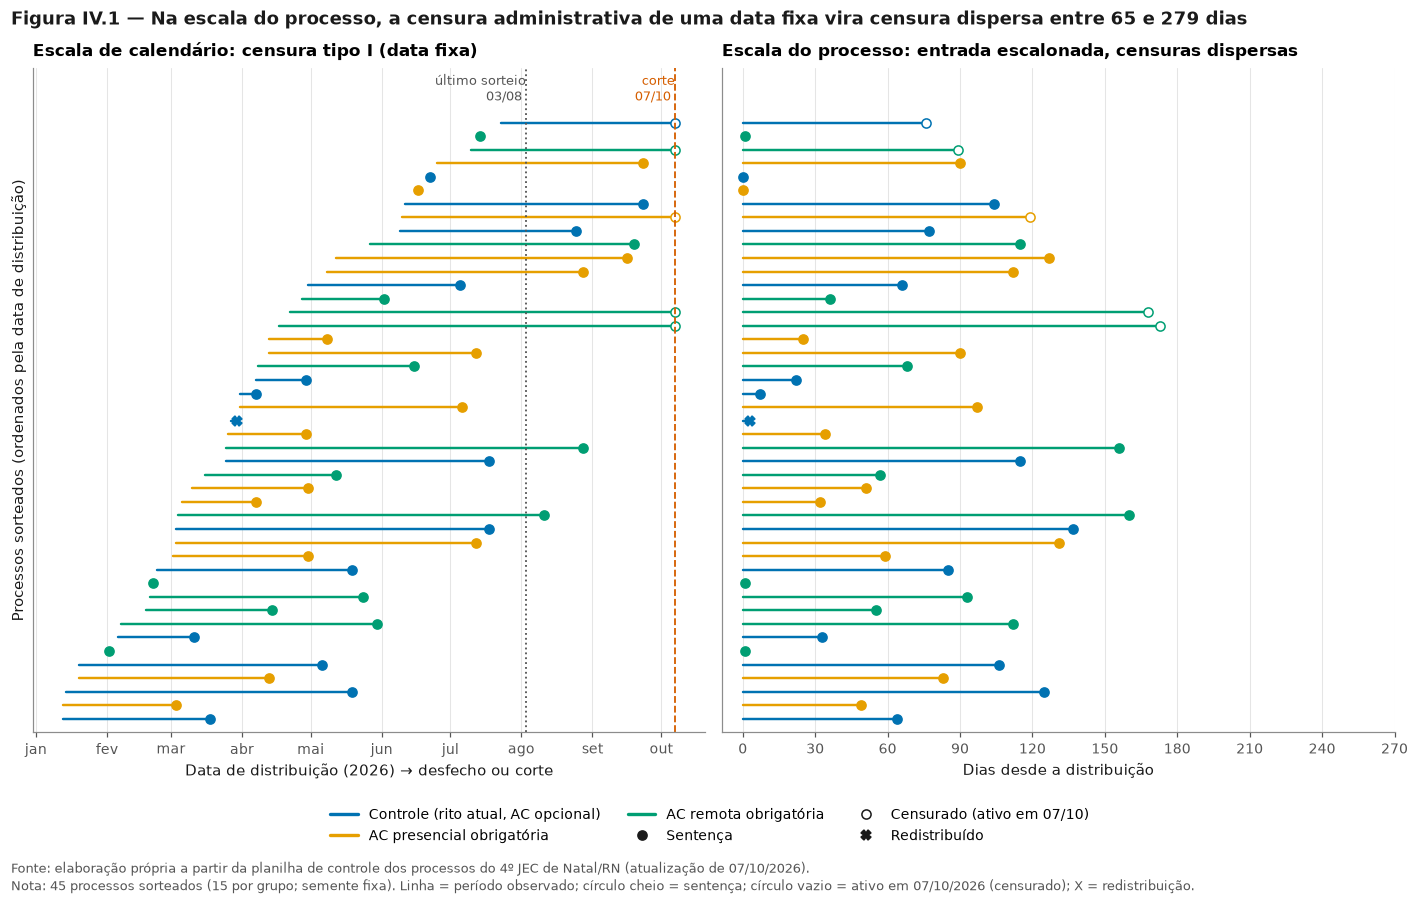

In [35]:
_rng = np.random.default_rng(SEMENTE + 4)
amostra = (pd.concat([sob[sob.grupo == g].iloc[_rng.choice((sob.grupo == g).sum(), 15, replace=False)] for g in ORDEM_GRUPO])
           .sort_values('dt_distribuicao').reset_index(drop=True))
fim = amostra['dt_sentenca'].where(amostra['CR'] > 0, DATA_CORTE)
MARCA = {0: dict(marker='o', mfc='white'), 1: dict(marker='o'), 2: dict(marker='X')}

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for i, r in amostra.iterrows():
    cor = CORES_GRUPO[r['grupo']]
    axes[0].plot([r['dt_distribuicao'], fim[i]], [i, i], color=cor, lw=1.6)
    axes[0].plot(fim[i], i, color=cor, ms=6, ls='', **MARCA[r['CR']])
    axes[1].plot([0, r['T']], [i, i], color=cor, lw=1.6)
    axes[1].plot(r['T'], i, color=cor, ms=6, ls='', **MARCA[r['CR']])
axes[0].axvline(DATA_CORTE, color=DESTAQUE, ls='--', lw=1.2); axes[0].axvline(FIM_RECRUTAMENTO, color=TINTA_2, ls=':', lw=1.2)
axes[0].text(DATA_CORTE, len(amostra) + 0.3, 'corte\n07/10 ', fontsize=8.5, color=DESTAQUE, ha='right', va='bottom')
axes[0].text(FIM_RECRUTAMENTO, len(amostra) + 0.3, 'último sorteio\n03/08 ', fontsize=8.5, color=TINTA_2, ha='right', va='bottom')
axes[0].set_ylim(-1, len(amostra) + 3)
axes[0].set_title('Escala de calendário: censura tipo I (data fixa)')
eixo_meses(axes[0])
axes[0].set_xlabel(ROTULOS['dt_distribuicao'] + ' → desfecho ou corte')
axes[1].set_title('Escala do processo: entrada escalonada, censuras dispersas')
axes[1].set_xlabel(ROTULOS['dias'])
axes[1].set_xticks(np.arange(0, 281, 30))
axes[0].set_yticks([]); axes[0].set_ylabel('Processos sorteados (ordenados pela data de distribuição)')
for ax in axes:
    ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
leg = LEG_GRUPO(longo=True) + [
    Line2D([], [], color=TINTA, marker='o', ls='', label='Sentença'),
    Line2D([], [], color=TINTA, marker='o', mfc='white', ls='', label='Censurado (ativo em 07/10)'),
    Line2D([], [], color=TINTA, marker='X', ls='', label='Redistribuído')]
fig.legend(handles=leg, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 0.0))
figura(fig, 'sob_diagrama_seguimento',
       'Na escala do processo, a censura administrativa de uma data fixa vira censura dispersa entre 65 e 279 dias',
       secao='4.1.3', nota='45 processos sorteados (15 por grupo; semente fixa). Linha = período observado; '
                           'círculo cheio = sentença; círculo vazio = ativo em 07/10/2026 (censurado); X = redistribuição.')

### 4.1.4 Estrutura dos dados por grupo

A tabela resume, por grupo, o que cada processo contribui: sentença (evento), censura administrativa (ativo) ou redistribuição. O **seguimento potencial** é o tempo máximo que cada processo poderia ter sido observado (07/10/2026 − distribuição). O seguimento mediano pelo **KM reverso** (KM com a censura como "evento") é a forma usual de resumir o acompanhamento em estudos com censura. Como todas as censuras aqui são administrativas, ele deve ficar próximo da mediana do seguimento potencial dos que ainda estavam em risco.

O gráfico de barras mostra a **proporção censurada por mês de distribuição e grupo**. Ela cresce fortemente com o mês: é a assinatura da entrada escalonada. Se um grupo tivesse mais processos nos meses tardios (julho concentra Remota: 67 × 44 × 46), ele teria mais censura por puro calendário, o que é mais um motivo para o ajuste por mês.

Medida,Controle,Presencial,Remota,Total
n,313,314,311,938
Sentenças (δ = 1),262,230,216,708
Ativos (censura adm.),46,74,86,206
Redistribuídos,5,10,9,24
% censurado,"16,3%","26,8%","30,5%","24,5%"
Seguimento potencial mediano (d),170,162,161,164
Seguimento potencial mín.–máx.,65–279,65–273,65–273,65–279
"Seguimento mediano, KM reverso (d)",167,140,147,154


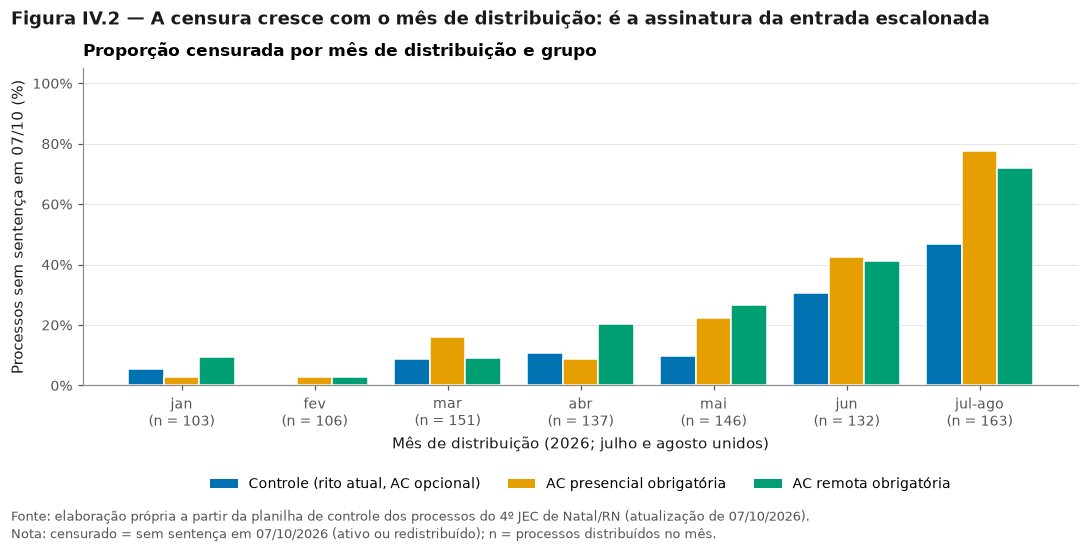

In [36]:
def resumo_estrutura(s):
    kmr = KaplanMeierFitter().fit(s['T'], 1 - s['E'])        # KM reverso (censura como "evento")
    return pd.Series({'n': len(s), 'Sentenças (δ = 1)': int(s['E'].sum()),
                      'Ativos (censura adm.)': int((s['CR'] == 0).sum()),
                      'Redistribuídos': int((s['CR'] == 2).sum()),
                      '% censurado': pct_br(1 - s['E'].mean()),
                      'Seguimento potencial mediano (d)': fmt_br(s['FU'].median(), 0),
                      'Seguimento potencial mín.–máx.': f"{int(s['FU'].min())}–{int(s['FU'].max())}",
                      'Seguimento mediano, KM reverso (d)': fmt_br(kmr.median_survival_time_, 0)})

estrutura = pd.concat({g: resumo_estrutura(sob[sob.grupo == g]) for g in ORDEM_GRUPO} | {'Total': resumo_estrutura(sob)}, axis=1)
tabela(estrutura.rename_axis('Medida'), 'sob_estrutura', 'Contribuição de cada processo à análise: sentença, censura ou redistribuição',
       secao='4.1.4', nota='seguimento potencial = 07/10/2026 − data de distribuição; KM reverso = Kaplan-Meier com a censura '
                           'como "evento".')

cens_mes = (sob.assign(cens=1 - sob['E']).groupby(['mes', 'grupo'], observed=True)['cens'].mean().unstack() * 100)
n_mes = sob.groupby('mes', observed=True).size()
_cm = cens_mes.copy()
_cm.columns = [str(c) for c in _cm.columns]
_cm.index = [f'{m}\n(n = {fmt_br(n_mes[m], 0)})' for m in _cm.index]
fig, ax = plt.subplots(figsize=(10, 4.6))
barras_agrupadas(ax, _cm, cores=CORES_GRUPO, rotular=False, quebrar=20,
                 ylabel='Processos sem sentença em 07/10 (%)', xlabel='Mês de distribuição (2026; julho e agosto unidos)',
                 legenda=False)
eixo_pct(ax, escala=1)
ax.set_ylim(0, 105)
ax.set_title('Proporção censurada por mês de distribuição e grupo')
legenda_abaixo(ax, ncol=3, dy=-0.25, handles=[Patch(color=CORES_GRUPO[g], label=ROTULO_GRUPO[g]) for g in ORDEM_GRUPO])
figura(fig, 'sob_censura_mes', 'A censura cresce com o mês de distribuição: é a assinatura da entrada escalonada',
       secao='4.1.4', nota='censurado = sem sentença em 07/10/2026 (ativo ou redistribuído); n = processos distribuídos no mês.')

### 4.1.5 Tabela de vida: número em risco, eventos e censuras por intervalo

A tabela de vida (atuarial) por intervalos de 30 dias é a forma mais transparente de ver de onde vem a informação: **n em risco** no início do intervalo, **sentenças** e **censuras** dentro dele. Note que, a partir de ~180 dias, o número em risco cai rapidamente, e a censura passa a dominar: as estimativas da cauda direita (> 180 dias) são imprecisas, o que orienta a escolha do horizonte τ do RMST (seção 4.3.6).

In [37]:
def tabela_vida(s, cortes=TEMPOS_TAB):
    linhas = []
    for a, b in zip(cortes, cortes[1:] + [np.inf]):
        no_int = (s['T'] >= a) & (s['T'] < b)
        linhas.append({'intervalo (d)': f'[{a}, {b})' if np.isfinite(b) else f'≥ {a}',
                       'em risco': int((s['T'] >= a).sum()),
                       'sentenças': int((no_int & (s['E'] == 1)).sum()),
                       'censuras': int((no_int & (s['E'] == 0)).sum())})
    return pd.DataFrame(linhas).set_index('intervalo (d)')

vida = pd.concat({g: tabela_vida(sob[sob.grupo == g]) for g in ORDEM_GRUPO}, axis=1)
tabela(vida.rename_axis('Intervalo (dias)'), 'sob_tabela_vida', 'Tabela de vida por grupo: em risco no início, sentenças e censuras '
       'em cada intervalo de 30 dias', secao='4.1.5', indice=True,
       nota='em risco = processos com T ≥ início do intervalo; censuras = ativos em 07/10/2026 ou redistribuídos.')

**Interpretação (estrutura dos dados).**

- **A censura é desigual entre os grupos:** 16,3% no Controle, 26,8% na AC presencial e 30,5% na AC remota. Os três grupos têm seguimento potencial quase igual (mediana de 170, 162 e 161 dias; mínimo de 65 dias em todos), então a diferença **não** vem do calendário de entrada. Ela vem do próprio desfecho: mais processos com AC ainda aguardavam sentença em 07/10. Isso já antecipa que os ritos com AC são mais lentos, e mostra por que comparar médias só dos encerrados (E14) favorece artificialmente os grupos com AC: os processos lentos deles estão justamente entre os censurados.
- O seguimento mediano pelo KM reverso (167, 140 e 147 dias) é menor nos grupos com AC pelo mesmo motivo. Os processos que continuam ativos são os distribuídos mais tarde.
- **A censura cresce com o mês de distribuição** em todos os grupos (gráfico de barras): é a assinatura da entrada escalonada. Em julho e agosto, a maior parte ainda está ativa. A análise precisa, portanto, condicionar no mês (seções 4.3.4 e 4.5).
- **A informação se esgota depois de ~180 dias.** A tabela de vida mostra 9 a 10 processos em risco por grupo aos 180 dias e 1 a 5 aos 210 dias. Estimativas além de 180 dias são frágeis, e por isso τ = 180 dias é o horizonte máximo do RMST.
- **Plausibilidade da censura não informativa.** Todos os 206 censurados estão ativos na data de corte, e o tempo potencial de censura é fixado pela data de distribuição, não pelo andamento do processo. A hipótese é razoável, **desde que o mês entre no modelo**, porque a seção 4.5.4 mostra uma tendência de calendário (processos mais recentes tramitam mais devagar). As 24 redistribuições (5, 10 e 9 por grupo) são outro mecanismo e são tratadas na seção 4.7.

---

## 4.2 Estimação não paramétrica: Kaplan-Meier e Nelson-Aalen

### 4.2.1 O estimador de Kaplan-Meier

O estimador de Kaplan-Meier (KAPLAN; MEIER, 1958) é o produto, sobre os tempos de evento t_j < t, das probabilidades condicionais de "sobreviver" (continuar sem sentença) a cada t_j:

Ŝ(t) = ∏_{j: t_j ≤ t} (1 − d_j / n_j),

em que d_j é o número de sentenças no dia t_j e n_j é o número em risco (ainda pendentes e não censurados) imediatamente antes de t_j (COLOSIMO; GIOLO, 2006, eq. 2.6, p. 37; MORETTIN; SINGER, 2021, p. 247-248). Cada censurado contribui para os denominadores enquanto está em observação, e depois sai do risco: é assim que o KM usa a informação parcial que a média ingênua desperdiça.

- **Variância de Greenwood:** Var[Ŝ(t)] = Ŝ(t)² Σ d_j/[n_j(n_j − d_j)] (eq. 2.7, p. 41).
- **IC 95% log-log** ("Greenwood exponencial"): o IC simples Ŝ ± 1,96·EP pode sair de [0, 1] nos extremos; a transformação Û = log[−log Ŝ(t)] produz [Ŝ(t)]^{exp(±1,96·√Var Û)}, sempre dentro de [0, 1] (eq. 2.8, p. 41-42). É o padrão do `lifelines`.
- **Propriedades:** não viciado em amostras grandes, consistente, assintoticamente normal e estimador de máxima verossimilhança não paramétrico (p. 40).

Como pedido, a curva é sempre a **descendente** S(t). As marcas verticais (|) são as censuras; a tabela sob o gráfico dá o número em risco.

Mediana global: 89 dias (IC 95%: 83–94)


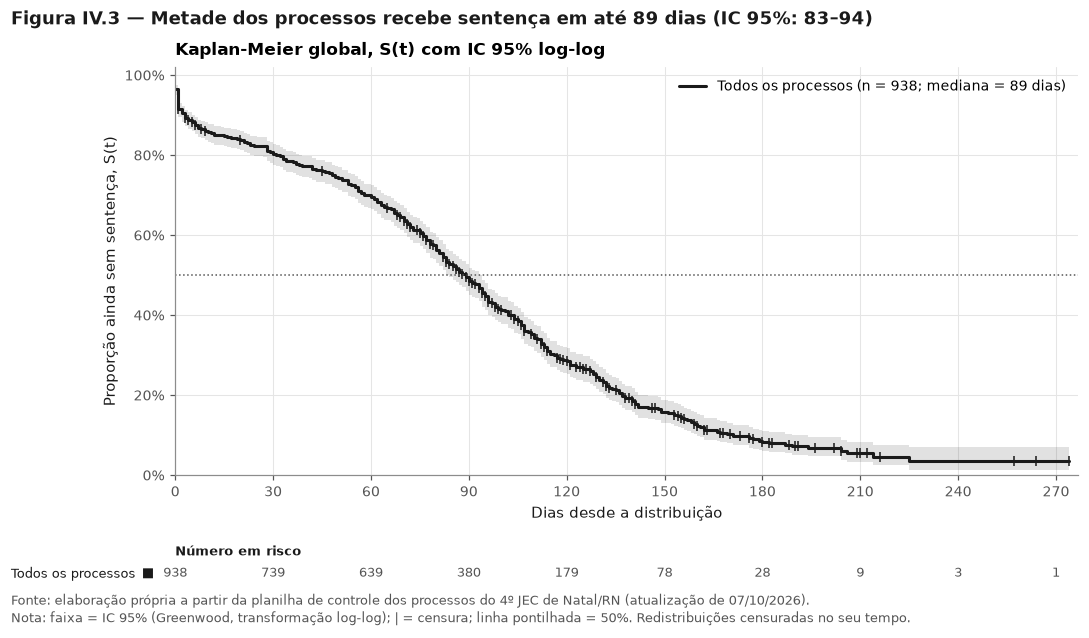

In [38]:
km_total = KaplanMeierFitter(label='Todos os processos').fit(sob['T'], sob['E'])
med_ic = median_survival_times(km_total.confidence_interval_)
print(f'Mediana global: {fmt_br(km_total.median_survival_time_, 0)} dias '
      f'(IC 95%: {fmt_br(med_ic.iloc[0, 0], 0)}–{fmt_br(med_ic.iloc[0, 1], 0)})')

fig, ax = plt.subplots(figsize=(10, 5.2))
plot_km(ax, sob, tempo='T', evento='E', grupo=None, passo=30, rotulos={'Todos': 'Todos os processos'})
ax.axhline(0.5, color=TINTA_2, ls=':', lw=1)
eixo_pct(ax)
ax.set_title('Kaplan-Meier global, S(t) com IC 95% log-log')
figura(fig, 'sob_km_global',
       f'Metade dos processos recebe sentença em até {fmt_br(km_total.median_survival_time_, 0)} dias '
       f'(IC 95%: {fmt_br(med_ic.iloc[0, 0], 0)}–{fmt_br(med_ic.iloc[0, 1], 0)})',
       secao='4.2.1', nota='faixa = IC 95% (Greenwood, transformação log-log); | = censura; linha pontilhada = 50%. '
                           'Redistribuições censuradas no seu tempo.')

### 4.2.2 Kaplan-Meier por grupo

As três curvas com IC 95% (faixas) e marcas de censura. Leitura: a curva mais **alta** em um dado t é a do grupo com mais processos **ainda pendentes** nesse dia, ou seja, o rito mais lento até ali. A distância vertical entre as curvas em t é a diferença na proporção já sentenciada; a distância horizontal na altura 50% é a diferença de medianas.

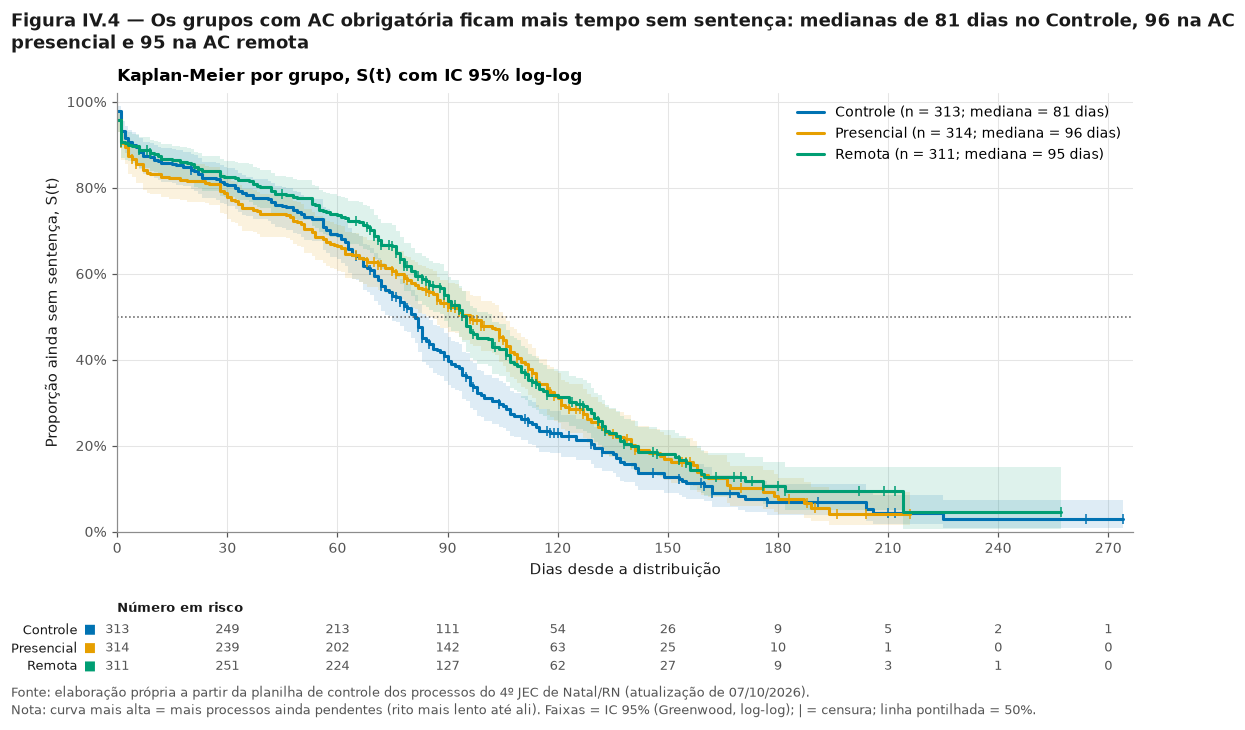

In [39]:
km_g = {g: KaplanMeierFitter(label=ROTULO_GRUPO[g]).fit(sob.loc[sob.grupo == g, 'T'], sob.loc[sob.grupo == g, 'E'])
        for g in ORDEM_GRUPO}
fig, ax = plt.subplots(figsize=(10.5, 5.8))
plot_km(ax, sob, tempo='T', evento='E', grupo='grupo', passo=30)
ax.axhline(0.5, color=TINTA_2, ls=':', lw=1)
eixo_pct(ax)
ax.set_title('Kaplan-Meier por grupo, S(t) com IC 95% log-log')
_md = {g: km_g[g].median_survival_time_ for g in ORDEM_GRUPO}
figura(fig, 'sob_km_grupos',
       f'Os grupos com AC obrigatória ficam mais tempo sem sentença: medianas de {fmt_br(_md["Controle"], 0)} dias no Controle, '
       f'{fmt_br(_md["Presencial"], 0)} na AC presencial e {fmt_br(_md["Remota"], 0)} na AC remota',
       secao='4.2.2', nota='curva mais alta = mais processos ainda pendentes (rito mais lento até ali). Faixas = IC 95% '
                           '(Greenwood, log-log); | = censura; linha pontilhada = 50%.')

### 4.2.3 Mediana e quartis com IC 95%

A mediana é t̂₀,₅ = inf{t: Ŝ(t) ≤ 0,5} (MORETTIN; SINGER, 2021, p. 248). Os quartis seguem a mesma regra: o **1º quartil** (Q1) é o dia em que 25% dos processos já tiveram sentença (Ŝ ≤ 0,75) e o **3º quartil** (Q3), o dia em que 75% já tiveram (Ŝ ≤ 0,25). A variância da mediana depende da densidade f(t), desconhecida; o IC é obtido **invertendo as bandas** de confiança de Ŝ (o tempo em que cada limite do IC cruza o nível p), procedimento próximo ao de Brookmeyer e Crowley (1982) descrito por Colosimo e Giolo (2006, p. 49-50). É o que faz `median_survival_times(kmf.confidence_interval_)`.

O **tempo médio** ∫S(t)dt não é estimável: com censura na cauda, a média fica subestimada e "deve ser interpretada com cautela ou evitada" (COLOSIMO; GIOLO, 2006, p. 50). O substituto é o RMST (seção 4.3.6).

In [40]:
def quantis_km(kmf):
    ic = kmf.confidence_interval_
    linha = {}
    for nome, p in [('Q1 (25% sentenciados)', 0.75), ('Mediana', 0.5), ('Q3 (75% sentenciados)', 0.25)]:
        est = quantil_tempo(kmf.survival_function_.iloc[:, 0], p)
        inf = quantil_tempo(ic.iloc[:, 0], p)       # limite inferior de S cruza antes
        sup = quantil_tempo(ic.iloc[:, 1], p)
        linha[nome] = f'{fmt_br(est, 0)} ({fmt_br(inf, 0)}–{fmt_br(sup, 0) if np.isfinite(sup) else "∞"})'
    return pd.Series(linha)

quartis = pd.DataFrame({ROTULO_GRUPO[g]: quantis_km(km_g[g]) for g in ORDEM_GRUPO} | {'Todos': quantis_km(km_total)}).T
tabela(quartis.rename_axis('Grupo'), 'sob_quartis', 'Dias até a sentença: quartis de Kaplan-Meier, estimativa (IC 95%)',
       secao='4.2.3', formatos={c: 'texto' for c in quartis.columns},
       nota='IC por inversão das bandas log-log de Ŝ(t); ∞ = o limite do IC não cruza o nível dentro do seguimento.')
MEDIANAS = {g: km_g[g].median_survival_time_ for g in ORDEM_GRUPO}

Grupo,Q1 (25% sentenciados),Mediana,Q3 (75% sentenciados)
"Controle (rito atual, AC opcional)",48 (33–57),81 (75–84),114 (104–130)
AC presencial obrigatória,37 (28–53),96 (85–106),131 (121–141)
AC remota obrigatória,55 (42–70),95 (89–102),132 (123–142)
Todos,48 (38–55),89 (83–94),129 (121–133)


### 4.2.4 Ŝ(t) em horizontes fixos de gestão

Para o gestor, a pergunta natural é "que fração dos processos ainda está sem sentença depois de 1, 2, 3, 4 e 6 meses?". A tabela traz Ŝ(t) com IC 95% log-log em 30, 60, 90, 120 e 180 dias; o gráfico mostra as mesmas estimativas em barras verticais com o IC. Os testes formais de diferença nesses pontos estão na seção 4.3.5.

Horizonte,Controle,Presencial,Remota
30 dias,"80,6% (75,8%–84,6%) [n=249]","77,9% (72,8%–82,1%) [n=239]","82,5% (77,8%–86,3%) [n=251]"
60 dias,"68,9% (63,4%–73,8%) [n=213]","66,3% (60,7%–71,3%) [n=202]","73,6% (68,3%–78,2%) [n=224]"
90 dias,"39,6% (34,0%–45,2%) [n=111]","52,3% (46,5%–57,9%) [n=142]","53,7% (47,6%–59,3%) [n=127]"
120 dias,"23,0% (18,3%–28,1%) [n=54]","31,0% (25,4%–36,9%) [n=63]","31,3% (25,4%–37,3%) [n=62]"
180 dias,"6,9% (3,9%–11,1%) [n=9]","7,5% (4,0%–12,6%) [n=10]","10,7% (6,4%–16,2%) [n=9]"


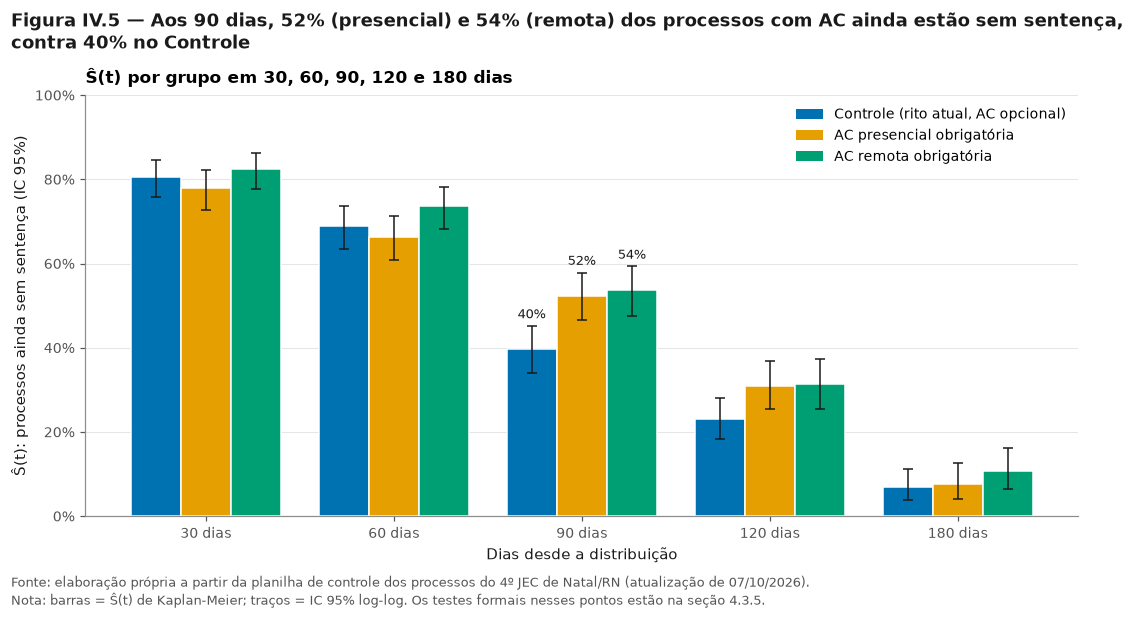

In [41]:
HORIZONTES = [30, 60, 90, 120, 180]
linhas = []
for g in ORDEM_GRUPO:
    k = km_g[g]
    S = k.survival_function_at_times(HORIZONTES).values
    ic = k.confidence_interval_
    for t, s_t in zip(HORIZONTES, S):
        li = ic.iloc[:, 0][ic.index <= t].iloc[-1]; ls = ic.iloc[:, 1][ic.index <= t].iloc[-1]
        linhas.append({'grupo': g, 't': t, 'S': s_t, 'inf': li, 'sup': ls, 'em risco': int((sob.loc[sob.grupo == g, 'T'] >= t).sum())})
s_horiz = pd.DataFrame(linhas)
tab = s_horiz.assign(txt=lambda d: [f'{pct_br(a)} ({pct_br(b)}–{pct_br(c)}) [n={n}]' for a, b, c, n in zip(d.S, d['inf'], d['sup'], d['em risco'])]
                     ).pivot(index='t', columns='grupo', values='txt')[ORDEM_GRUPO]
tab.index = [f'{t} dias' for t in tab.index]
tab.columns = [str(c) for c in tab.columns]
tabela(tab.rename_axis('Horizonte'), 'sob_S_horizontes', 'Proporção ainda sem sentença, Ŝ(t), em horizontes fixos: '
       'estimativa (IC 95%) [n em risco]', secao='4.2.4', formatos={c: 'texto' for c in tab.columns},
       nota='IC 95% log-log (Greenwood).')

_sh = s_horiz.pivot(index='t', columns='grupo', values='S')[ORDEM_GRUPO]
_sh.index = [f'{t} dias' for t in _sh.index]
_sh.columns = [str(c) for c in _sh.columns]
_erro = {g: (s_horiz.loc[s_horiz.grupo == g, 'inf'].to_numpy(), s_horiz.loc[s_horiz.grupo == g, 'sup'].to_numpy())
         for g in ORDEM_GRUPO}
fig, ax = plt.subplots(figsize=(10, 4.8))
barras_agrupadas(ax, _sh, cores=CORES_GRUPO, erro=_erro, legenda=False, ylabel='Ŝ(t): processos ainda sem sentença (IC 95%)',
                 xlabel='Dias desde a distribuição')
eixo_pct(ax); ax.set_ylim(0, 1)
for j, g in enumerate(ORDEM_GRUPO):         # rótulo só no horizonte de 90 dias (onde as curvas mais se separam)
    v = _sh.loc['90 dias', g]; hi = _erro[g][1][HORIZONTES.index(90)]
    ax.annotate(pct_br(v, 0), (HORIZONTES.index(90) + (j - 1) * 0.8 / 3, hi), xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=8.5, color=TINTA)
ax.set_title('Ŝ(t) por grupo em 30, 60, 90, 120 e 180 dias')
ax.legend(handles=[Patch(color=CORES_GRUPO[g], label=ROTULO_GRUPO[g]) for g in ORDEM_GRUPO], loc='upper right')
figura(fig, 'sob_S_horizontes', f'Aos 90 dias, {pct_br(_sh.loc["90 dias", "Presencial"], 0)} (presencial) e '
       f'{pct_br(_sh.loc["90 dias", "Remota"], 0)} (remota) dos processos com AC ainda estão sem sentença, '
       f'contra {pct_br(_sh.loc["90 dias", "Controle"], 0)} no Controle',
       secao='4.2.4', nota='barras = Ŝ(t) de Kaplan-Meier; traços = IC 95% log-log. Os testes formais nesses pontos estão na seção 4.3.5.')

### 4.2.5 Nelson-Aalen e risco suavizado

O estimador de **Nelson-Aalen** do risco acumulado é Λ̃(t) = Σ_{t_j ≤ t} d_j/n_j, com variância de Aalen Σ d_j/n_j² (COLOSIMO; GIOLO, 2006, eq. 2.9-2.10, p. 43-44). Ele dá S̃(t) = exp{−Λ̃(t)} ≥ Ŝ(t) e serve sobretudo para ver a **forma do risco**: Λ(t) reto indica risco constante; côncavo, risco decrescente; convexo, crescente (p. 45; p. 96-99).

A **taxa de sentença por dia** h(t) é a derivada de Λ(t). Estima-se por suavização por núcleo (Ramlau-Hansen) dos incrementos d_j/n_j, com núcleo de Epanechnikov e banda de 20 dias (`NelsonAalenFitter.smoothed_hazard_`). A banda é uma escolha de compromisso: menor deixa a curva ruidosa, maior apaga a estrutura. A curva é cortada em 180 dias: depois disso há menos de 10 processos em risco por grupo, e a estimativa vira ruído. É a figura que mostra **quando** cada rito sentencia mais.

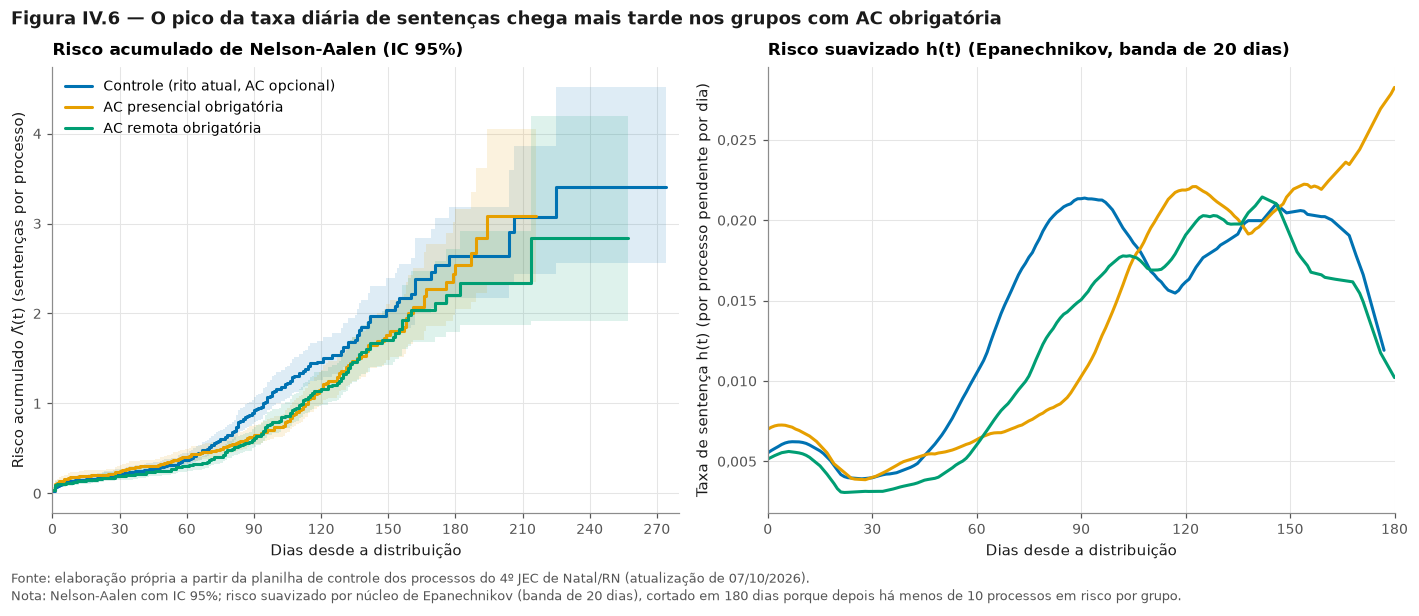

In [42]:
na_g = {g: NelsonAalenFitter(label=ROTULO_GRUPO[g]).fit(sob.loc[sob.grupo == g, 'T'], sob.loc[sob.grupo == g, 'E'])
        for g in ORDEM_GRUPO}
BANDA = 20
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for g in ORDEM_GRUPO:
    ch = na_g[g].cumulative_hazard_.iloc[:, 0]
    ci = na_g[g].confidence_interval_
    axes[0].step(ch.index, ch.values, where='post', color=CORES_GRUPO[g], lw=2, label=ROTULO_GRUPO[g])
    axes[0].fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=CORES_GRUPO[g], alpha=0.13, lw=0)
    hz = na_g[g].smoothed_hazard_(bandwidth=BANDA)
    hz = hz[hz.index <= 180]
    axes[1].plot(hz.index, hz.iloc[:, 0], color=CORES_GRUPO[g], lw=2, label=ROTULO_GRUPO[g])
axes[0].set_xlim(0, 280); axes[0].set_xticks(np.arange(0, 281, 30))
axes[0].set_xlabel(ROTULOS['dias']); axes[0].set_ylabel('Risco acumulado Λ̃(t) (sentenças por processo)')
axes[0].set_title('Risco acumulado de Nelson-Aalen (IC 95%)')
axes[0].legend(loc='upper left')
axes[1].set_xlim(0, 180); axes[1].set_xticks(np.arange(0, 181, 30))
axes[1].set_xlabel(ROTULOS['dias']); axes[1].set_ylabel('Taxa de sentença h(t) (por processo pendente por dia)')
axes[1].set_title(f'Risco suavizado h(t) (Epanechnikov, banda de {BANDA} dias)')
for ax in axes:
    ax.grid(axis='both', visible=True)
figura(fig, 'sob_nelson_aalen_risco', 'O pico da taxa diária de sentenças chega mais tarde nos grupos com AC obrigatória',
       secao='4.2.5', nota=f'Nelson-Aalen com IC 95%; risco suavizado por núcleo de Epanechnikov (banda de {BANDA} dias), '
                           'cortado em 180 dias porque depois há menos de 10 processos em risco por grupo.')

**Interpretação (Kaplan-Meier e risco).**

- **Mediana global:** 89 dias (IC 95%: 83–94). Metade dos processos do 4º JEC recebeu sentença em cerca de três meses.
- **Medianas por grupo:**

  | Grupo | Mediana (IC 95%) |
  |---|---|
  | Controle | 81 dias (75–84) |
  | AC presencial | 96 dias (85–106) |
  | AC remota | 95 dias (89–102) |

  Os intervalos do Controle não se sobrepõem aos da AC remota e só tocam os da presencial. A **AC obrigatória atrasou a mediana em cerca de 15 dias**. O notebook do professor, com o Kruskal-Wallis sobre tempos censurados (E17), concluía "sem diferença".
- **O formato das curvas importa mais que as medianas.** Até cerca de 60 dias, as três curvas praticamente coincidem: Ŝ(30) = 80,6%, 77,9% e 82,5%; Ŝ(60) = 68,9%, 66,3% e 73,6%. A separação acontece **entre 60 e 120 dias**:
  - aos 90 dias, 39,6% dos processos do Controle ainda estão sem sentença, contra 52,3% na AC presencial e 53,7% na remota;
  - aos 120 dias, 23,0% contra 31,0% e 31,3%;
  - aos 180 dias as curvas voltam a se aproximar (6,9%, 7,5% e 10,7%), com ICs largos.
- **Quartis.** O 1º quartil da AC presencial é o *menor* (37 dias, contra 48 no Controle): uma parte dos processos presenciais termina **mais cedo**, e a seção 4.7 mostra que são extinções sem mérito. O 3º quartil é 17 a 18 dias maior nos grupos com AC (131–132 contra 114).
- **Risco suavizado.** A taxa diária de sentenças do Controle atinge o pico por volta de 90 dias (≈ 0,021 sentença por processo pendente por dia). Nos grupos com AC, o pico é **deslocado para 120–150 dias**. É o retrato de um rito com uma etapa a mais: o julgamento de mérito espera a audiência, e a "onda" de sentenças chega mais tarde. Nos primeiros 30 dias, a AC presencial tem taxa um pouco maior que a dos outros grupos.

---

## 4.3 Comparação das curvas de sobrevivência

**Hipóteses (para toda a família de testes de k amostras):**

- H₀: S_Controle(t) = S_Presencial(t) = S_Remota(t) para todo t (equivalentemente, mesmas funções de risco);
- H₁: ao menos uma curva difere em algum t.

**Por que testar.** O desenho é um experimento com sorteio: diferenças sistemáticas entre as curvas, além do acaso, são atribuíveis ao rito. Os grupos são **independentes** (processos distintos, alocação aleatória; questão 2.3), o que justifica testes de k amostras independentes. **Pré-especificação:** o teste principal é o **log-rank** de 3 grupos (2 g.l.); os testes ponderados, os pares, o estratificado, os pontos fixos e o RMST são análises de apoio, cada uma respondendo a uma pergunta mais específica.

### 4.3.1 Teste log-rank

O log-rank compara, em cada tempo de evento t_j, o número observado de sentenças em cada grupo com o esperado sob H₀ (w_gj = n_gj d_j/n_j) e soma as diferenças ao longo do tempo. Com r = 3 grupos, a estatística T = v′V⁻¹v tem distribuição χ² com r − 1 = 2 g.l. (COLOSIMO; GIOLO, 2006, eq. 2.12-2.13, p. 56-59; MORETTIN; SINGER, 2021, p. 253). Ele coincide com o teste escore do modelo de Cox com o grupo como covariável (COLOSIMO; GIOLO, 2006, p. 56) e é o **mais poderoso quando os riscos são proporcionais** (p. 55).

**Pressupostos:** censura não informativa (4.1.1) e independência entre processos. **Gráfico do teste:** barras de sentenças **observadas (O)** e **esperadas sob H₀ (E)** por grupo; O < E significa que o grupo sentenciou menos (foi mais lento) do que sentenciaria se não houvesse diferença.

Log-rank (3 grupos): χ² = 7,52, g.l. = 2, p = 0,023


Grupo,Observadas (O),Esperadas sob H₀ (E),O/E
Controle,262,"229,21","1,14"
Presencial,230,"239,10","0,96"
Remota,216,"239,69","0,90"


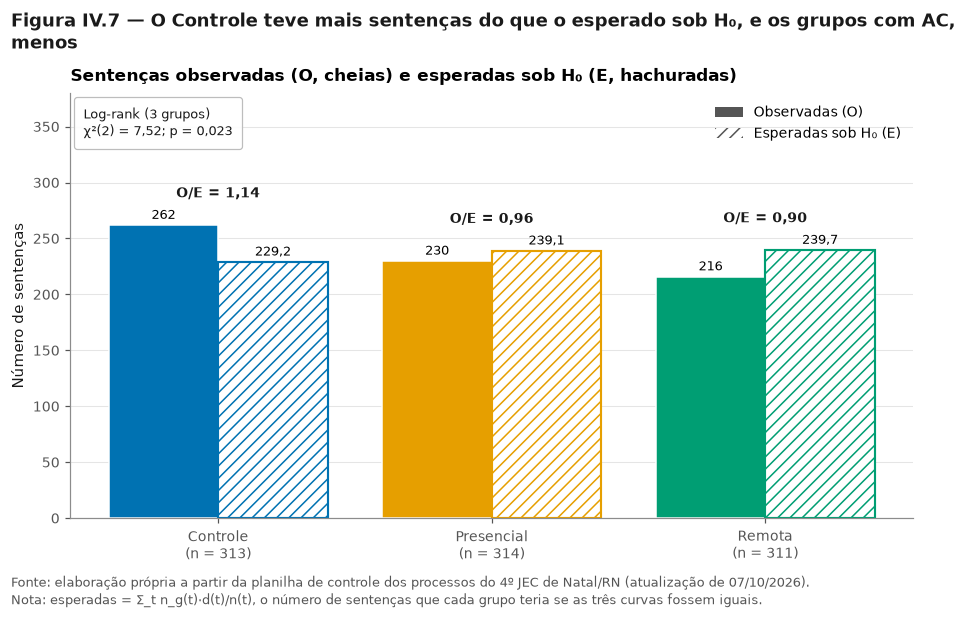

In [43]:
def obs_esperados(T, E, G, grupos=ORDEM_GRUPO):
    """Sentenças observadas e esperadas sob H0 (log-rank) por grupo."""
    T = np.asarray(T, float); E = np.asarray(E, int); G = np.asarray(G)
    tempos = np.unique(T[E == 1])
    n_tot = np.array([(T >= t).sum() for t in tempos]); d_tot = np.array([((T == t) & (E == 1)).sum() for t in tempos])
    res = {}
    for g in grupos:
        Tg = T[G == g]
        n_g = np.array([(Tg >= t).sum() for t in tempos])
        res[g] = {'Observadas (O)': int(E[G == g].sum()), 'Esperadas sob H₀ (E)': float((n_g * d_tot / n_tot).sum())}
    out = pd.DataFrame(res).T
    out['O/E'] = out.iloc[:, 0] / out.iloc[:, 1]
    return out

lr_global = multivariate_logrank_test(sob['T'], sob['grupo'].astype(str), sob['E'])
oe = obs_esperados(sob['T'], sob['E'], sob['grupo'].astype(str))
print(f"Log-rank (3 grupos): χ² = {fmt_br(lr_global.test_statistic, 2)}, g.l. = {lr_global.degrees_of_freedom}, p = {p_br(lr_global.p_value)}")
sob_tabela(oe.rename_axis('Grupo'), 'sob_logrank_oe', 'Log-rank de 3 grupos: sentenças observadas e esperadas sob H₀',
           secao='4.3.1', casas=2, destaque=None, formatos={'Observadas (O)': 'int'},
           nota=f'log-rank: χ² = {fmt_br(lr_global.test_statistic, 2)} ({lr_global.degrees_of_freedom} g.l.); '
                f'{p_txt(lr_global.p_value)}. O/E < 1 = menos sentenças que o esperado (grupo mais lento).')

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(3)
ax.bar(x - 0.2, oe['Observadas (O)'], 0.4, color=[CORES_GRUPO[g] for g in ORDEM_GRUPO], edgecolor='white', lw=1)
ax.bar(x + 0.2, oe['Esperadas sob H₀ (E)'], 0.4, color='white', edgecolor=[CORES_GRUPO[g] for g in ORDEM_GRUPO],
       hatch='///', lw=1.4)
for xi, (o, e) in zip(x, oe.iloc[:, :2].values):
    ax.annotate(fmt_br(o, 0), (xi - 0.2, o), xytext=(0, 2), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
    ax.annotate(fmt_br(e, 1), (xi + 0.2, e), xytext=(0, 2), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
    ax.annotate(f'O/E = {fmt_br(o / e, 2)}', (xi, max(o, e)), xytext=(0, 16), textcoords='offset points', ha='center',
                va='bottom', fontsize=9, fontweight='bold', color=TINTA)
ax.set_xticks(x, [rotulo_grupo(g, com_n=True, base=sob, quebrar=True) for g in ORDEM_GRUPO])
ax.grid(axis='x', visible=False)
ax.set_ylabel('Número de sentenças'); ax.set_ylim(0, oe.iloc[:, :2].to_numpy().max() * 1.45)
ax.set_title('Sentenças observadas (O, cheias) e esperadas sob H₀ (E, hachuradas)')
ax.legend(handles=[Patch(facecolor=TINTA_2, label='Observadas (O)'),
                   Patch(facecolor='white', edgecolor=TINTA_2, hatch='///', label='Esperadas sob H₀ (E)')],
          loc='upper right')
anotar_teste(ax, texto_teste('Log-rank (3 grupos)', f'χ²({lr_global.degrees_of_freedom}) = {fmt_br(lr_global.test_statistic, 2)}',
                             lr_global.p_value), loc='upper left')
figura(fig, 'sob_logrank_oe', 'O Controle teve mais sentenças do que o esperado sob H₀, e os grupos com AC, menos',
       secao='4.3.1', nota='esperadas = Σ_t n_g(t)·d(t)/n(t), o número de sentenças que cada grupo teria se as três curvas fossem iguais.')

### 4.3.2 A família ponderada: Wilcoxon, Tarone-Ware, Peto-Prentice e Fleming-Harrington

Todos os testes da família têm a forma S = [Σ u_j (d_gj − w_gj)]² / Σ u_j² V_gj, e diferem apenas no **peso u_j** dado a cada tempo de evento (COLOSIMO; GIOLO, 2006, eq. 2.14-2.15, p. 61-63):

| Teste | Peso u_j | Onde tem mais poder |
|---|---|---|
| Log-rank | 1 | diferenças constantes (riscos proporcionais) |
| Wilcoxon / Gehan-Breslow | n_j | diferenças **precoces**; mas depende do padrão de censura |
| Tarone-Ware | √n_j | meio-termo |
| Peto-Prentice | S̃(t_{j−1})·n_j/(n_j + 1), com S̃(t) = ∏(1 − d_j/(n_j + 1)) | precoces, sem depender da censura |
| Fleming-Harrington (p, q) | Ŝ(t_{j−1})^p [1 − Ŝ(t_{j−1})]^q | (1, 0) precoce; (0, 1) **tardia**; (1, 1) intermediária |

**Por que fazer todos.** Se o efeito do rito muda ao longo do tempo (por exemplo, a AC obrigatória acelera extinções e acordos no início e atrasa os julgamentos de mérito depois), as diferenças de sinais opostos se cancelam no log-rank e o teste perde poder (p. 62-63). Comparar testes com pesos precoces e tardios mostra **onde** está a diferença. Como a censura aqui varia entre grupos e meses, Colosimo e Giolo recomendam preferir Peto ou FH ao Gehan (p. 63). Os testes são **sensibilidade** do teste principal, não uma família para escolher o menor p.

**Implementação.** A estatística de k amostras é calculada por uma função própria (`teste_k_ponderado`, fórmulas de Colosimo e Giolo), porque a opção `weightings='fleming-harrington'` do `lifelines` 0.30 falha com o pandas 3. A coluna "χ² lifelines" confere a implementação nos testes em que o `lifelines` funciona; a pequena diferença no Peto-Prentice vem da definição do peso (o `lifelines` usa S̃ no próprio t_j, e aqui se usa S̃(t_{j−1}), como no livro).

**Gráfico do teste:** à esquerda, os pesos relativos u(t)/max u(t) ao longo do tempo (onde cada teste "olha"); à direita, as estatísticas χ²₂ com o valor crítico de 5%.

Teste,χ² (2 g.l.),p,χ² lifelines (conferência),"p (Holm, 7 testes)"
Log-rank,"7,52","0,023","7,52","0,120"
Wilcoxon (Gehan-Breslow),"6,40","0,041","6,40","0,136"
Tarone-Ware,"7,82","0,020","7,82","0,120"
Peto-Prentice,"6,77","0,034","6,96","0,136"
"Fleming-Harrington (1, 0)","6,77","0,034",–,"0,136"
"Fleming-Harrington (0, 1)","4,91","0,086",–,"0,136"
"Fleming-Harrington (1, 1)","13,80","0,001",–,"0,007"


Fleming-Harrington: o lifelines 0.30 falha com o pandas 3 (ValueError de alinhamento); usa-se a implementação própria, conferida contra o lifelines nos quatro testes em que ele funciona.


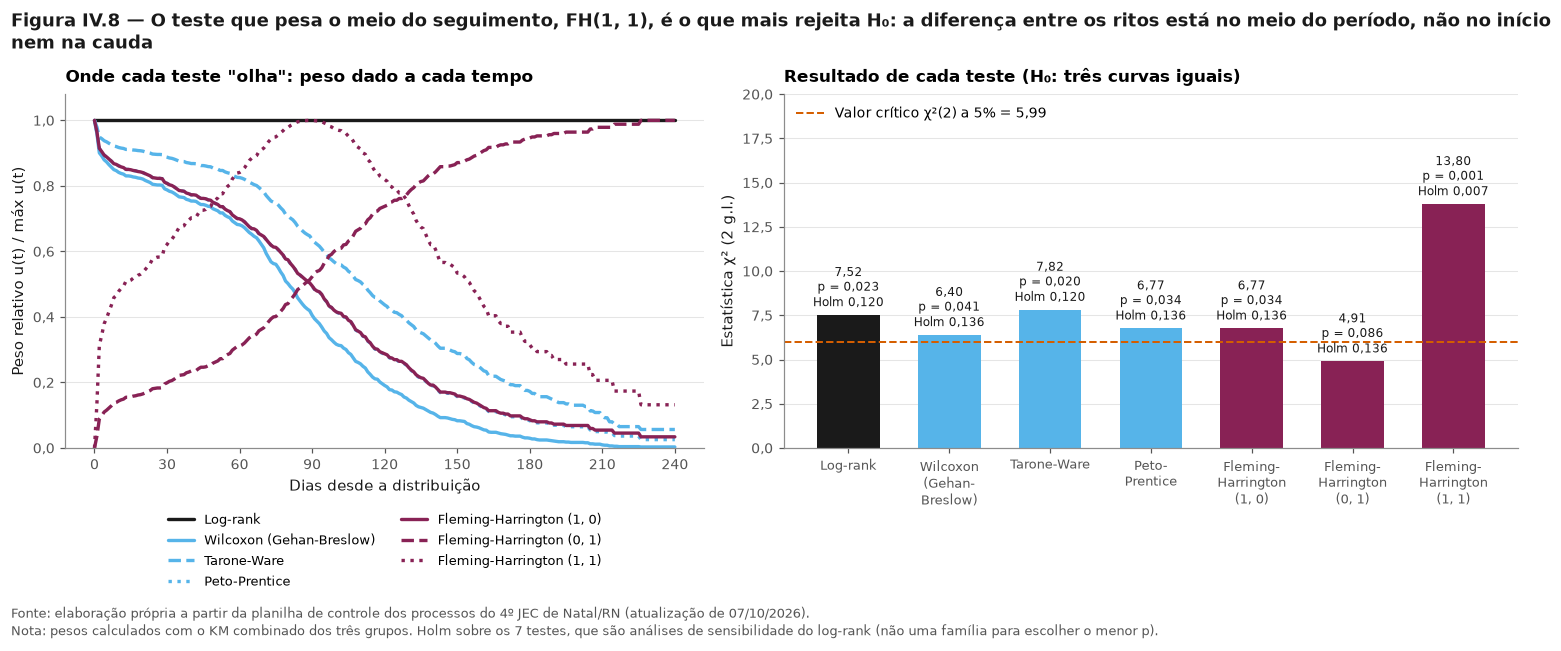

In [44]:
def teste_k_ponderado(T, E, G, peso='logrank', p=0, q=0, grupos=ORDEM_GRUPO):
    """Teste de k amostras da família ponderada (COLOSIMO; GIOLO, 2006, eq. 2.13-2.15): χ² = Z'V⁻¹Z, k − 1 g.l."""
    T = np.asarray(T, float); E = np.asarray(E, int); G = np.asarray(G)
    tj = np.unique(T[E == 1])
    n = np.array([(T >= t).sum() for t in tj]); d = np.array([((T == t) & (E == 1)).sum() for t in tj])
    S_km = np.cumprod(1 - d / n); S_km_ant = np.concatenate([[1.0], S_km[:-1]])
    S_peto_ant = np.concatenate([[1.0], np.cumprod(1 - d / (n + 1))[:-1]])
    u = {'logrank': np.ones_like(n, float), 'wilcoxon': n.astype(float), 'tarone-ware': np.sqrt(n),
         'peto': S_peto_ant * n / (n + 1), 'fh': S_km_ant ** p * (1 - S_km_ant) ** q}[peso]
    ng = np.array([[(T[G == g] >= t).sum() for t in tj] for g in grupos[:-1]])
    dg = np.array([[((T[G == g] == t) & (E[G == g] == 1)).sum() for t in tj] for g in grupos[:-1]])
    Z = (u * (dg - ng * d / n)).sum(axis=1)
    fator = np.where(n > 1, d * (n - d) / np.maximum(n - 1, 1), 0.0) * u ** 2
    V = np.empty((len(grupos) - 1,) * 2)
    for a in range(len(grupos) - 1):
        for b in range(len(grupos) - 1):
            V[a, b] = (fator * (ng[a] / n) * ((a == b) - ng[b] / n)).sum()
    chi = float(Z @ np.linalg.solve(V, Z))
    return chi, stats.chi2.sf(chi, len(grupos) - 1)

PONDERACOES = [('Log-rank', ('logrank', {}), {}), ('Wilcoxon (Gehan-Breslow)', ('wilcoxon', {}), {'weightings': 'wilcoxon'}),
               ('Tarone-Ware', ('tarone-ware', {}), {'weightings': 'tarone-ware'}), ('Peto-Prentice', ('peto', {}), {'weightings': 'peto'}),
               ('Fleming-Harrington (1, 0)', ('fh', {'p': 1, 'q': 0}), None),
               ('Fleming-Harrington (0, 1)', ('fh', {'p': 0, 'q': 1}), None),
               ('Fleming-Harrington (1, 1)', ('fh', {'p': 1, 'q': 1}), None)]
res_pond = []
Gs = sob['grupo'].astype(str)
for nome, (peso, kwp), kw_ll in PONDERACOES:
    chi, pv = teste_k_ponderado(sob['T'], sob['E'], Gs, peso, **kwp)
    chi_ll = multivariate_logrank_test(sob['T'], Gs, sob['E'], **kw_ll).test_statistic if kw_ll is not None else np.nan
    res_pond.append({'Teste': nome, 'χ² (2 g.l.)': chi, 'p': pv, 'χ² lifelines (conferência)': chi_ll})
res_pond = pd.DataFrame(res_pond).set_index('Teste')
res_pond['p (Holm, 7 testes)'] = multipletests(res_pond['p'], method='holm')[1]
sob_tabela(res_pond, 'sob_testes_ponderados', 'Família ponderada de testes de k amostras (3 grupos, 2 g.l.)', secao='4.3.2',
           casas=2, colunas_p=('p', 'p (Holm, 7 testes)'),
           nota='implementação própria (COLOSIMO; GIOLO, 2006, eq. 2.13-2.15); "χ² lifelines" confere os quatro testes em que o '
                'lifelines 0.30 funciona com o pandas 3 (– = não disponível). Destaque: p de Holm < 0,05.')
print('Fleming-Harrington: o lifelines 0.30 falha com o pandas 3 (ValueError de alinhamento); usa-se a implementação própria,'
      ' conferida contra o lifelines nos quatro testes em que ele funciona.')

# pesos ao longo do tempo (KM combinado)
S_comb, _ = aj_grade(sob['T'], sob['E'])
tt = np.arange(0, 241)
n_t = np.array([(sob['T'] >= t).sum() for t in tt]); S_ant = np.concatenate([[1.0], S_comb[:-1]])[tt]
pesos = {'Log-rank': np.ones_like(tt, float), 'Wilcoxon (Gehan-Breslow)': n_t, 'Tarone-Ware': np.sqrt(n_t),
         'Peto-Prentice': S_ant * n_t / (n_t + 1), 'Fleming-Harrington (1, 0)': S_ant,
         'Fleming-Harrington (0, 1)': 1 - S_ant, 'Fleming-Harrington (1, 1)': S_ant * (1 - S_ant)}
# cor = família do peso (Gehan/Tarone/Peto: azul-céu; Fleming-Harrington: vinho), estilo = variante; sem cores de grupo
ESTILO_TESTE = {'Log-rank': (TINTA, '-'), 'Wilcoxon (Gehan-Breslow)': ('#56B4E9', '-'), 'Tarone-Ware': ('#56B4E9', '--'),
                'Peto-Prentice': ('#56B4E9', ':'), 'Fleming-Harrington (1, 0)': ('#882255', '-'),
                'Fleming-Harrington (0, 1)': ('#882255', '--'), 'Fleming-Harrington (1, 1)': ('#882255', ':')}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})
for nome, u in pesos.items():
    cor, ls = ESTILO_TESTE[nome]
    axes[0].plot(tt, u / u.max(), color=cor, ls=ls, lw=2.2, label=nome)
axes[0].set_xlabel(ROTULOS['dias']); axes[0].set_ylabel('Peso relativo u(t) / máx u(t)')
axes[0].set_xticks(np.arange(0, 241, 30)); axes[0].set_ylim(0, 1.08)
axes[0].set_title('Onde cada teste "olha": peso dado a cada tempo')
legenda_abaixo(axes[0], ncol=2, dy=-0.15, fontsize=8.5)
nomes = list(res_pond.index)
xb = np.arange(len(nomes))
cores_b = [ESTILO_TESTE[n][0] for n in nomes]
axes[1].bar(xb, res_pond['χ² (2 g.l.)'], color=cores_b, width=0.62, edgecolor='white')
crit = stats.chi2.ppf(0.95, 2)
axes[1].axhline(crit, color=DESTAQUE, ls='--', lw=1.3, label=f'Valor crítico χ²(2) a 5% = {fmt_br(crit, 2)}')
axes[1].legend(loc='upper left')
for xi, (c, p, ph) in zip(xb, res_pond[['χ² (2 g.l.)', 'p', 'p (Holm, 7 testes)']].values):
    axes[1].annotate(f'{fmt_br(c, 2)}\n{p_txt(p)}\nHolm {fmt_p(ph)}', (xi, c), xytext=(0, 3), textcoords='offset points',
                     ha='center', va='bottom', fontsize=8, color=TINTA)
axes[1].set_xticks(xb, [quebra(n.replace('Fleming-Harrington', 'Fleming-\nHarrington'), 12) for n in nomes], fontsize=8.5)
axes[1].grid(axis='x', visible=False)
axes[1].set_ylim(0, res_pond['χ² (2 g.l.)'].max() * 1.45)
axes[1].set_ylabel('Estatística χ² (2 g.l.)'); axes[1].set_title('Resultado de cada teste (H₀: três curvas iguais)')
figura(fig, 'sob_testes_ponderados', 'O teste que pesa o meio do seguimento, FH(1, 1), é o que mais rejeita H₀: '
       'a diferença entre os ritos está no meio do período, não no início nem na cauda',
       secao='4.3.2', nota='pesos calculados com o KM combinado dos três grupos. Holm sobre os 7 testes, que são análises de '
                           'sensibilidade do log-rank (não uma família para escolher o menor p).')

### 4.3.3 Comparações par a par (Holm e Bonferroni)

Rejeitado (ou não) o teste global, interessa saber **quais pares** diferem: Presencial × Controle e Remota × Controle respondem à pergunta do efeito da AC obrigatória; Presencial × Remota, à pergunta da modalidade. São 3 testes log-rank de 2 grupos (1 g.l. cada). Colosimo e Giolo (2006, p. 59-61) usam Bonferroni (α/3 = 0,017); aqui reporta-se também **Holm**, que controla a mesma taxa de erro da família e é uniformemente mais poderoso. O gráfico mostra −log₁₀(p) de cada par, com as linhas de corte de 5% (sem correção) e de Bonferroni.

**Teste de tendência: não se aplica.** O teste de tendência do log-rank (Cox com escore ordinal) pressupõe uma **ordenação a priori** dos grupos (dose crescente, por exemplo). Controle, AC presencial e AC remota são categorias **nominais**: não há razão substantiva para supor que a remota esteja "entre" o controle e a presencial, ou além dela. Um teste de tendência aqui dependeria de uma ordenação arbitrária e não responderia a nenhuma pergunta do estudo. (Um teste de tendência faz sentido para o **mês** de distribuição, que é ordinal; isso é avaliado pelos resíduos martingal na seção 4.5.4.)

Par,χ² (1 g.l.),p,p (Bonferroni),p (Holm)
Presencial × Controle,"3,50","0,061","0,184","0,123"
Remota × Controle,"7,15","0,008","0,023","0,023"
Remota × Presencial,"0,41","0,519","1,000","0,519"


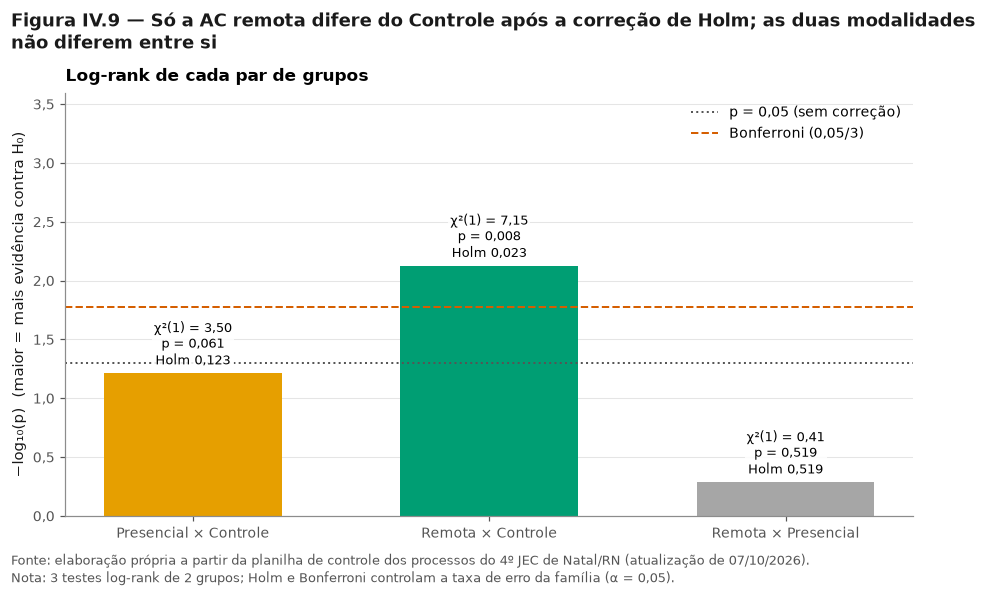

In [45]:
PARES = [('Controle', 'Presencial'), ('Controle', 'Remota'), ('Presencial', 'Remota')]
res_par = []
for a, b in PARES:
    sa, sb = sob[sob.grupo == a], sob[sob.grupo == b]
    r = logrank_test(sa['T'], sb['T'], sa['E'], sb['E'])
    res_par.append({'Par': f'{b} × {a}', 'χ² (1 g.l.)': r.test_statistic, 'p': r.p_value})
res_par = pd.DataFrame(res_par).set_index('Par')
res_par['p (Bonferroni)'] = multipletests(res_par['p'], method='bonferroni')[1]
res_par['p (Holm)'] = multipletests(res_par['p'], method='holm')[1]
sob_tabela(res_par, 'sob_logrank_pares', 'Log-rank par a par (2 grupos, 1 g.l.), com correção de Bonferroni e de Holm',
           secao='4.3.3', casas=2, colunas_p=('p', 'p (Bonferroni)', 'p (Holm)'), nota='destaque: p de Holm < 0,05.')

fig, ax = plt.subplots(figsize=(8.5, 4.6))
cores_par = [CORES_GRUPO['Presencial'], CORES_GRUPO['Remota'], CINZA]
xp = np.arange(len(res_par))
ax.bar(xp, -np.log10(res_par['p']), color=cores_par, width=0.6, edgecolor='white')
ax.axhline(-np.log10(0.05), color=TINTA_2, ls=':', lw=1.3, label='p = 0,05 (sem correção)')
ax.axhline(-np.log10(0.05 / 3), color=DESTAQUE, ls='--', lw=1.3, label='Bonferroni (0,05/3)')
for i, (c, p, ph) in enumerate(res_par[['χ² (1 g.l.)', 'p', 'p (Holm)']].values):
    ax.annotate(f'χ²(1) = {fmt_br(c, 2)}\n{p_txt(p)}\nHolm {fmt_p(ph)}', (i, -np.log10(p)), xytext=(0, 3),
                textcoords='offset points', ha='center', va='bottom', fontsize=8.5, bbox=CAIXA_TXT)
ax.set_xticks(xp, res_par.index); ax.grid(axis='x', visible=False)
ax.set_ylabel('−log₁₀(p)  (maior = mais evidência contra H₀)'); ax.set_title('Log-rank de cada par de grupos')
ax.legend(loc='upper right')
ax.set_ylim(0, max(-np.log10(res_par['p'])) * 1.55 + 0.3)
figura(fig, 'sob_logrank_pares', 'Só a AC remota difere do Controle após a correção de Holm; as duas modalidades não diferem entre si',
       secao='4.3.3', nota='3 testes log-rank de 2 grupos; Holm e Bonferroni controlam a taxa de erro da família (α = 0,05).')

### 4.3.4 Log-rank estratificado pelo mês de distribuição

O log-rank estratificado calcula O − E e a variância **dentro de cada mês** e só depois soma os estratos. Assim, compara cada grupo apenas com processos distribuídos no mesmo mês, com o mesmo seguimento potencial e o mesmo "momento" da vara. Isso neutraliza (i) a diferença de composição mensal dos grupos (julho com mais Remota) e (ii) qualquer tendência de calendário. Se o resultado estratificado for parecido com o não estratificado, o calendário não confunde a comparação — o esperado num experimento sorteado. O `lifelines` não oferece estratificação; usa-se `statsmodels.duration.survfunc.survdiff(..., strata=mês)`.

**Gráfico do teste:** Kaplan-Meier por grupo **dentro de cada mês** (os estratos que o teste combina).

Teste,χ² não estratificado,p não estratificado,χ² estratificado por mês,p estratificado por mês
Log-rank,"7,52","0,023","6,21","0,045"
Gehan-Breslow,"6,40","0,041","8,16","0,017"
Tarone-Ware,"7,82","0,020","8,09","0,018"


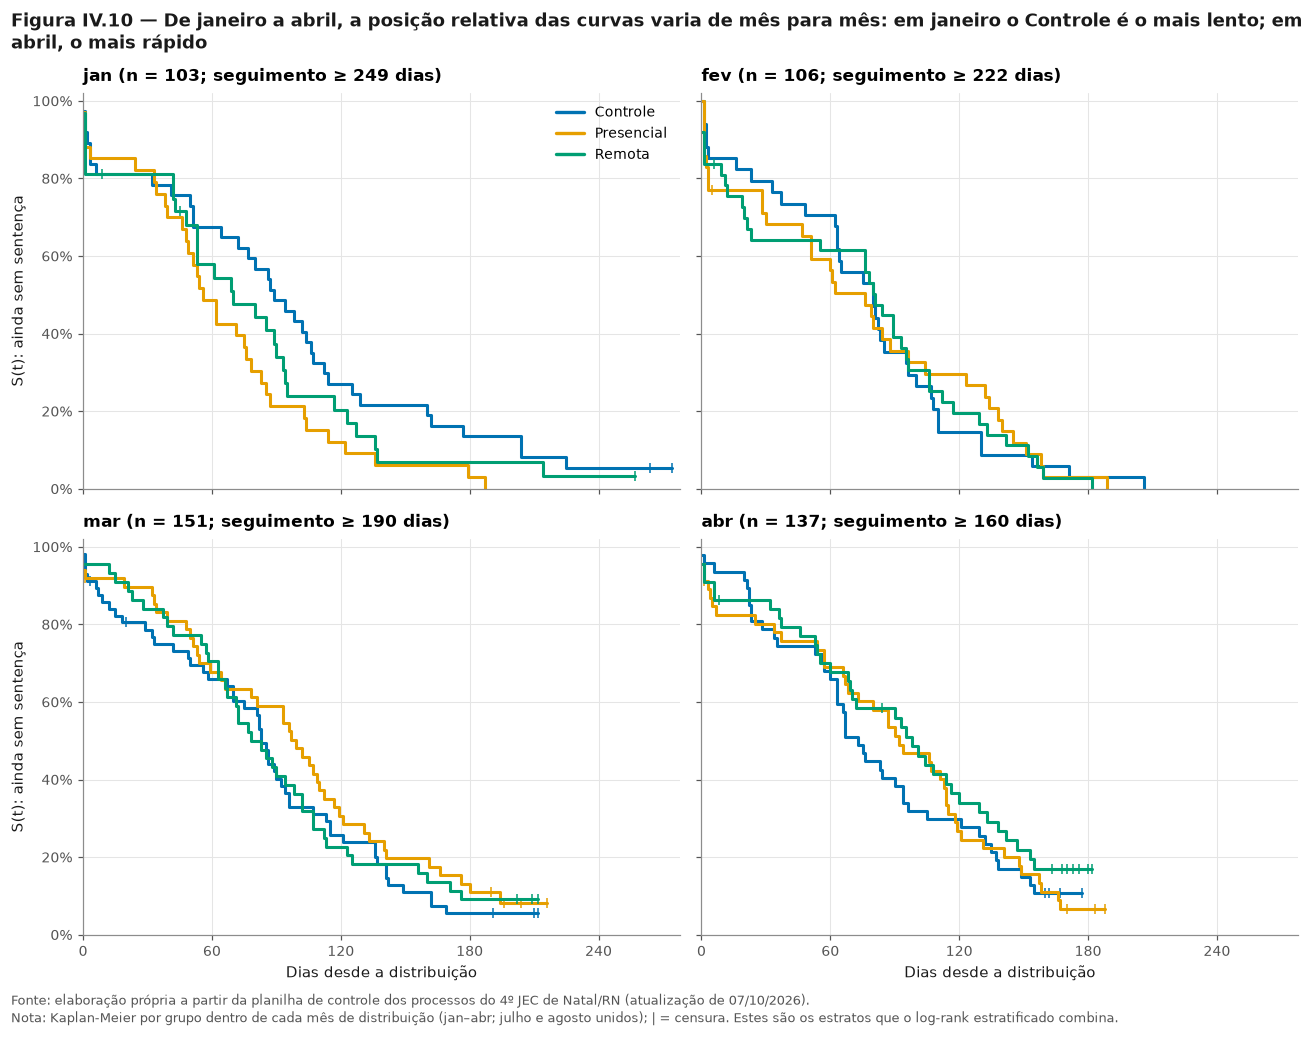

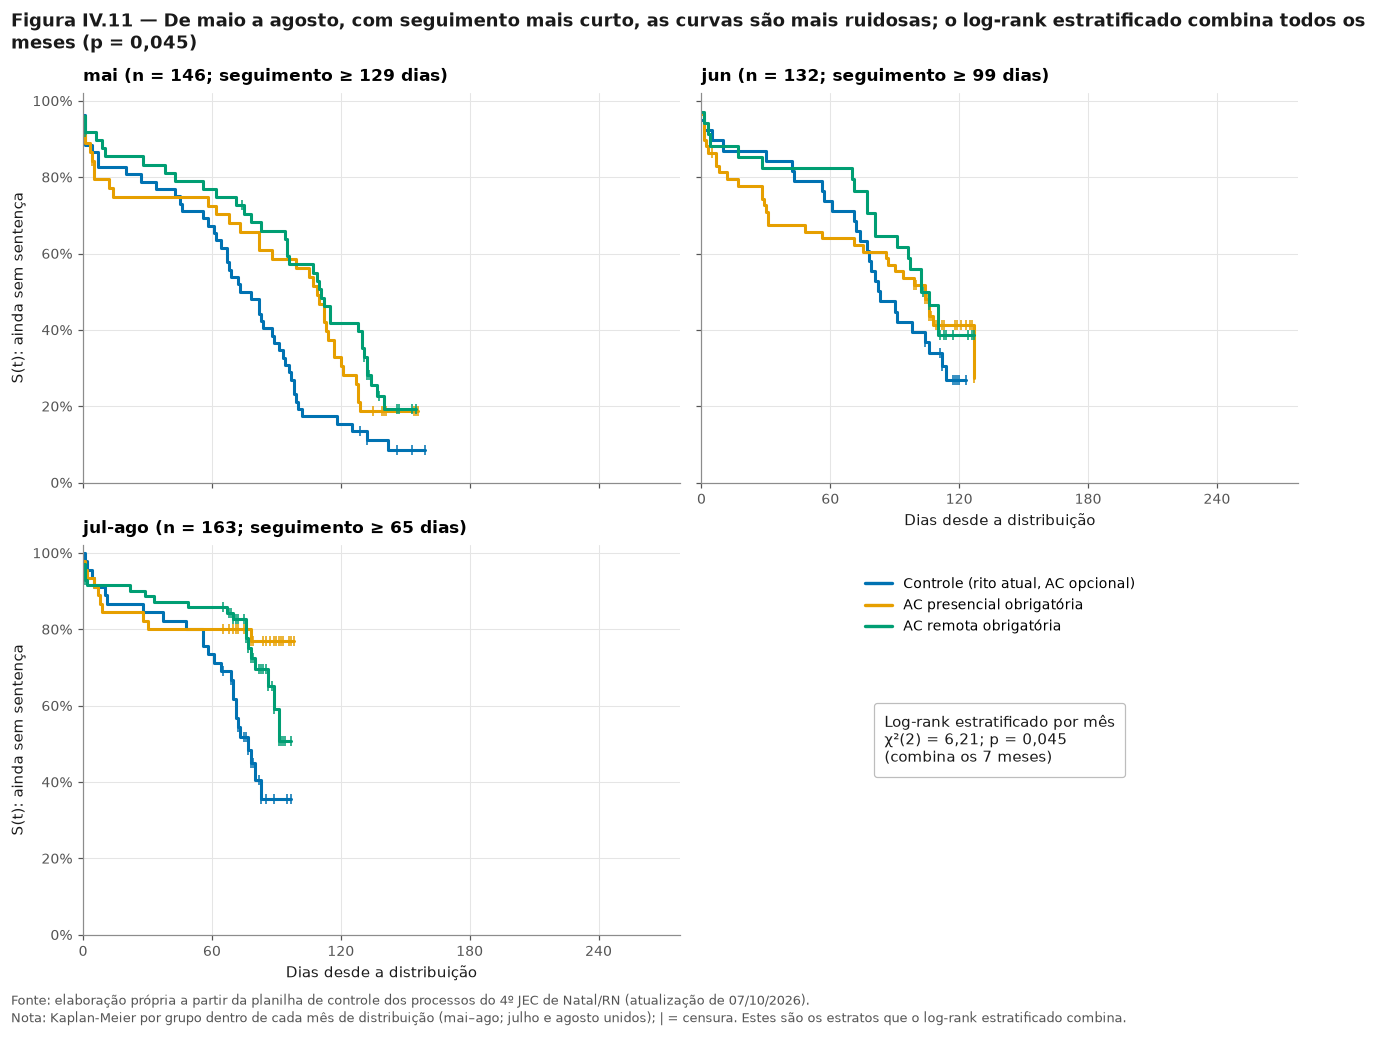

In [46]:
g_num = sob['grupo'].cat.codes.values
estr = []
for nome, kw in [('Log-rank', {}), ('Gehan-Breslow', {'weight_type': 'gb'}), ('Tarone-Ware', {'weight_type': 'tw'})]:
    chi_ne, p_ne = survdiff(sob['T'].values, sob['E'].values, g_num, **kw)
    chi_e, p_e = survdiff(sob['T'].values, sob['E'].values, g_num, strata=sob['mes_cod'].values, **kw)
    estr.append({'Teste': nome, 'χ² não estratificado': chi_ne, 'p não estratificado': p_ne,
                 'χ² estratificado por mês': chi_e, 'p estratificado por mês': p_e})
estr = pd.DataFrame(estr).set_index('Teste')
sob_tabela(estr, 'sob_logrank_estratificado', 'Testes de 3 grupos sem e com estratificação pelo mês de distribuição (2 g.l.)',
           secao='4.3.4', casas=2, colunas_p=('p não estratificado', 'p estratificado por mês'),
           destaque='p estratificado por mês', nota='statsmodels.duration.survfunc.survdiff; estratos = 7 meses (julho e agosto unidos).')
LR_ESTRAT_P = estr.loc['Log-rank', 'p estratificado por mês']
_ch_e = estr.loc['Log-rank', 'χ² estratificado por mês']

for parte, meses in [(1, MESES_SOB[:4]), (2, MESES_SOB[4:])]:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.6), sharex=True, sharey=True)
    for ax, m in zip(axes.flat, meses):
        sm_ = sob[sob.mes == m]
        plot_km(ax, sm_, tempo='T', evento='E', grupo='grupo', ic=False, tabela_risco=False, legenda=False,
                passo=60, tmax=275, xlabel=ROTULOS['dias'], ylabel='S(t): ainda sem sentença')
        eixo_pct(ax)
        ax.set_title(f'{m} (n = {len(sm_)}; seguimento ≥ {int(sm_.FU.min())} dias)')
        ax.label_outer()
    if len(meses) < 4:
        for ax in axes.flat[len(meses):]:
            ax.axis('off')
        axes.flat[-1].legend(handles=LEG_GRUPO(longo=True), loc='upper center', bbox_to_anchor=(0.5, 0.95))
        anotar_teste(axes.flat[-1], texto_teste('Log-rank estratificado por mês', f'χ²(2) = {fmt_br(_ch_e, 2)}', LR_ESTRAT_P,
                                                 extra='(combina os 7 meses)'), loc='center', tamanho=9.5)
        axes.flat[1].tick_params(labelbottom=True); axes.flat[1].set_xlabel(ROTULOS['dias'])
    else:
        axes.flat[0].legend(handles=LEG_GRUPO(), loc='upper right')
    titulo_mes = ('De janeiro a abril, a posição relativa das curvas varia de mês para mês: em janeiro o Controle é o mais '
                  'lento; em abril, o mais rápido' if parte == 1 else
                  f'De maio a agosto, com seguimento mais curto, as curvas são mais ruidosas; o log-rank estratificado '
                  f'combina todos os meses ({p_txt(LR_ESTRAT_P)})')
    figura(fig, f'sob_km_por_mes_{parte}', titulo_mes, secao='4.3.4',
           nota=f'Kaplan-Meier por grupo dentro de cada mês de distribuição ({"jan–abr" if parte == 1 else "mai–ago"}; '
                'julho e agosto unidos); | = censura. Estes são os estratos que o log-rank estratificado combina.')

### 4.3.5 Testes em pontos fixos do tempo (60, 90 e 120 dias)

Em vez de comparar as curvas inteiras, compara-se Ŝ(t₀) entre dois grupos num horizonte fixo. H₀: S_A(t₀) = S_B(t₀). A estatística é a diferença padronizada pelas variâncias de Greenwood (qui-quadrado com 1 g.l.; `survival_difference_at_fixed_point_in_time_test`). É um teste **sem hipótese de riscos proporcionais**, com leitura direta para gestão ("aos 90 dias, X% a mais dos processos ainda estão sem sentença"). Os horizontes de 60, 90 e 120 dias cobrem o período em que a AC já ocorreu e em que a maioria das sentenças acontece, e todos os processos da base têm seguimento potencial ≥ 65 dias (os de 90 e 120 dias perdem os distribuídos mais tarde, o que o KM corrige). São 6 testes (2 contrastes com o Controle × 3 horizontes), corrigidos por Holm.

**Gráfico do teste:** diferença Ŝ_tratado(t₀) − Ŝ_Controle(t₀) com IC 95% (Greenwood): valores **positivos** = mais processos pendentes no grupo com AC (mais lento).

t₀ (dias),Contraste,Ŝ grupo,Ŝ Controle,Diferença,IC 95% inf.,IC 95% sup.,χ² (1 g.l.),p,"p (Holm, 6 testes)"
60,Presencial − Controle,"66,3%","68,9%","-0,026","-0,1","0,0","0,47","0,491","0,491"
60,Remota − Controle,"73,6%","68,9%","0,047","-0,0","0,1","1,62","0,203","0,405"
90,Presencial − Controle,"52,3%","39,6%","0,127","0,0","0,2","9,54","0,002","0,010"
90,Remota − Controle,"53,7%","39,6%","0,140","0,1","0,2","11,16","< 0,001","0,005"
120,Presencial − Controle,"31,0%","23,0%","0,080","0,0","0,2","4,22","0,040","0,149"
120,Remota − Controle,"31,3%","23,0%","0,082","0,0","0,2","4,34","0,037","0,149"


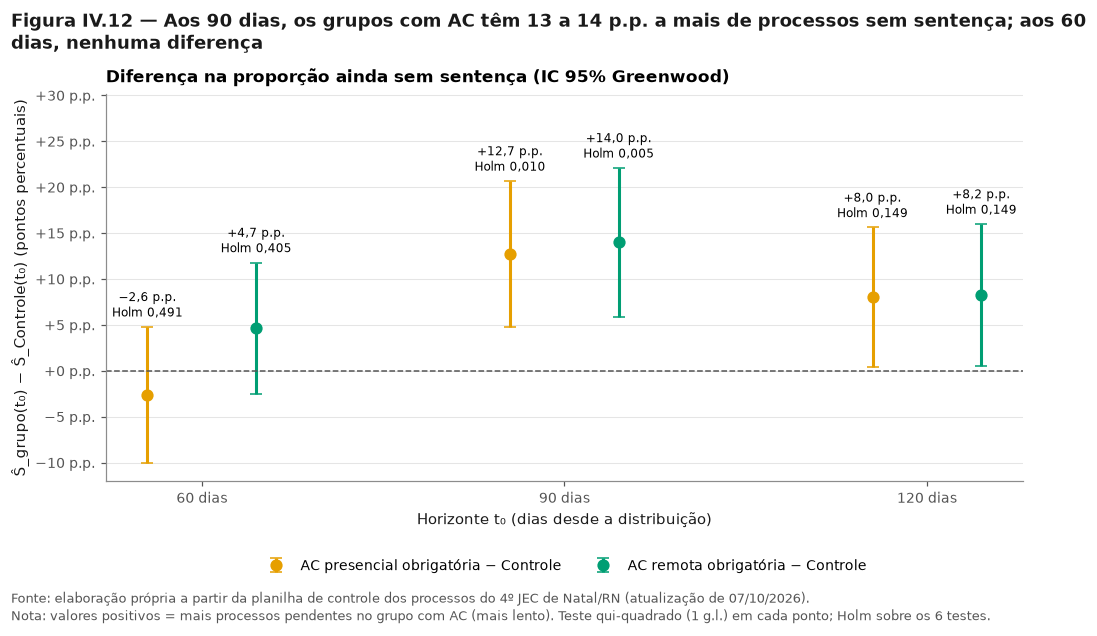

In [47]:
res_fix = []
for t0 in [60, 90, 120]:
    for g in ['Presencial', 'Remota']:
        r = survival_difference_at_fixed_point_in_time_test(t0, km_g[g], km_g['Controle'])
        sg, eg = km_greenwood(sob.loc[sob.grupo == g, 'T'], sob.loc[sob.grupo == g, 'E'], t0)
        sc, ec = km_greenwood(sob.loc[sob.grupo == 'Controle', 'T'], sob.loc[sob.grupo == 'Controle', 'E'], t0)
        dif, ep = sg - sc, np.sqrt(eg ** 2 + ec ** 2)
        res_fix.append({'t₀ (dias)': t0, 'Contraste': f'{g} − Controle', 'Ŝ grupo': sg, 'Ŝ Controle': sc,
                        'Diferença': dif, 'IC 95% inf.': dif - 1.96 * ep, 'IC 95% sup.': dif + 1.96 * ep,
                        'χ² (1 g.l.)': r.test_statistic, 'p': r.p_value})
res_fix = pd.DataFrame(res_fix)
res_fix['p (Holm, 6 testes)'] = multipletests(res_fix['p'], method='holm')[1]
sob_tabela(res_fix, 'sob_pontos_fixos', 'Diferença na proporção ainda sem sentença em 60, 90 e 120 dias (grupo com AC − Controle)',
           secao='4.3.5', casas=3, colunas_p=('p', 'p (Holm, 6 testes)'),
           formatos={'t₀ (dias)': 'int', 'Ŝ grupo': 'pct', 'Ŝ Controle': 'pct', 'χ² (1 g.l.)': 2},
           nota='diferença e IC 95% na escala de proporção (0,127 = 12,7 p.p.), com EP de Greenwood; χ² de '
                'survival_difference_at_fixed_point_in_time_test. Destaque: p de Holm < 0,05.')

fig, ax = plt.subplots(figsize=(9.5, 5))
for j, g in enumerate(['Presencial', 'Remota']):
    d = res_fix[res_fix.Contraste.str.startswith(g)]
    xs = np.arange(3) + (j - 0.5) * 0.3
    ax.errorbar(xs, d['Diferença'], yerr=[d['Diferença'] - d['IC 95% inf.'], d['IC 95% sup.'] - d['Diferença']],
                fmt='o', ms=7, color=CORES_GRUPO[g], capsize=4, label=f'{ROTULO_GRUPO[g]} − Controle')
    for xi, (v, dif, ph) in zip(xs, d[['IC 95% sup.', 'Diferença', 'p (Holm, 6 testes)']].values):
        ax.annotate(f'{100 * dif:+.1f} p.p.'.replace('.', ',', 1).replace('-', '−') + f'\nHolm {fmt_p(ph)}',
                    (xi, v), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=8)
ax.axhline(0, color=TINTA_2, ls='--', lw=1); ax.set_xticks(range(3), ['60 dias', '90 dias', '120 dias'])
ax.grid(axis='x', visible=False)
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{100 * v:+.0f} p.p.'.replace('-', '−')))
ax.set_ylim(min(-0.08, res_fix['IC 95% inf.'].min() - 0.02), res_fix['IC 95% sup.'].max() + 0.08)
ax.set_xlabel('Horizonte t₀ (dias desde a distribuição)')
ax.set_ylabel('Ŝ_grupo(t₀) − Ŝ_Controle(t₀) (pontos percentuais)')
ax.set_title('Diferença na proporção ainda sem sentença (IC 95% Greenwood)')
legenda_abaixo(ax, ncol=2, dy=-0.17)
figura(fig, 'sob_pontos_fixos', 'Aos 90 dias, os grupos com AC têm 13 a 14 p.p. a mais de processos sem sentença; aos 60 dias, nenhuma diferença',
       secao='4.3.5', nota='valores positivos = mais processos pendentes no grupo com AC (mais lento). Teste qui-quadrado (1 g.l.) '
                           'em cada ponto; Holm sobre os 6 testes.')

### 4.3.6 Tempo médio restrito (RMST)

O **RMST** até o horizonte τ é a área sob a curva de Kaplan-Meier, μ_τ = ∫₀^τ S(t) dt (MORETTIN; SINGER, 2021, p. 248; ROYSTON; PARMAR, 2013). Leitura: "em média, nos primeiros τ dias após a distribuição, o processo permaneceu μ_τ dias sem sentença". A **diferença de RMST** entre grupos é uma medida de efeito em **dias**, que não exige riscos proporcionais e capta diferenças de qualquer forma (inclusive curvas que se cruzam). É o substituto correto do "tempo médio" que o notebook do professor calculava ignorando a censura (E14, E30).

**Escolha de τ.** O τ deve ser no máximo o menor dos seguimentos máximos dos grupos (273 dias), e com gente suficiente em risco para que Ŝ(t) seja estável até ele. Usam-se **τ = 150 dias** (cerca de 5 meses; > 30% de cada grupo ainda em observação) e **τ = 180 dias** (6 meses, o horizonte de gestão mais longo com informação razoável; ver a tabela de vida em 4.1.5). τ = 90 dias é mostrado como horizonte curto.

**Inferência.** O RMST é calculado com `restricted_mean_survival_time` do `lifelines` (conferido contra a soma da curva na grade diária). O IC de cada RMST **e** das diferenças vem de *bootstrap* (a opção `return_variance=True` do `lifelines` devolve a variância de min(T, τ) na população, e não a variância do estimador, e não serve para IC). As **diferenças** têm IC por *bootstrap* não paramétrico (2.000 reamostras **dentro de cada grupo**, preservando os tamanhos sorteados; IC percentil) e p-valor pela aproximação normal com o erro-padrão bootstrap. H₀: μ_τ,grupo = μ_τ,Controle.

**Gráficos do teste:** no primeiro, a área entre as curvas de cada grupo com AC e a do Controle é a diferença de RMST até 180 dias (com o resultado do teste anotado); no segundo, as diferenças com IC bootstrap para os três horizontes.

Conferência: RMST(180) Controle — lifelines 82,140 | grade diária 82,140


τ (dias),Grupo,RMST (dias),EP (bootstrap),IC 95% inf.,IC 95% sup.
90,Controle,"65,0","1,77","61,5","68,4"
90,Presencial,"64,9","1,96","61,0","68,7"
90,Remota,"69,2","1,75","65,9","72,6"
150,Controle,"79,3","2,76","73,8","84,7"
150,Presencial,"84,9","3,10","78,8","90,8"
150,Remota,"88,9","2,88","83,4","94,8"
180,Controle,"82,1","3,10","76,0","88,0"
180,Presencial,"88,6","3,40","82,0","95,3"
180,Remota,"92,9","3,24","86,9","99,4"


τ (dias),Contraste,Diferença (dias),IC 95% inf. (bootstrap),IC 95% sup. (bootstrap),"p (normal, EP bootstrap)"
90,Presencial − Controle,"-0,12","-5,0","5,3","0,965"
90,Remota − Controle,"4,21","-0,7","9,1","0,089"
90,Remota − Presencial,"4,32","-0,8","9,9","0,101"
150,Presencial − Controle,"5,64","-2,9","13,6","0,179"
150,Remota − Controle,"9,59","2,2","17,8","0,016"
150,Remota − Presencial,"3,95","-3,9","12,7","0,349"
180,Presencial − Controle,"6,46","-2,1","15,8","0,161"
180,Remota − Controle,"10,73","1,9","19,5","0,016"
180,Remota − Presencial,"4,26","-4,7","13,4","0,367"


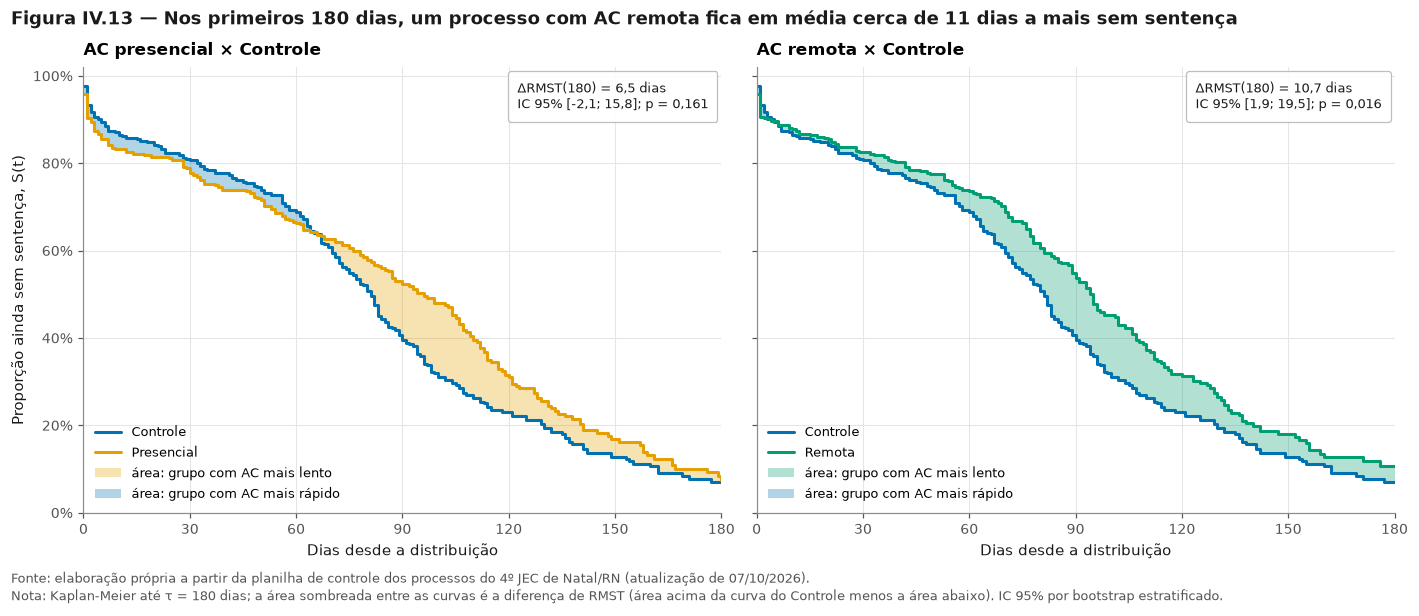

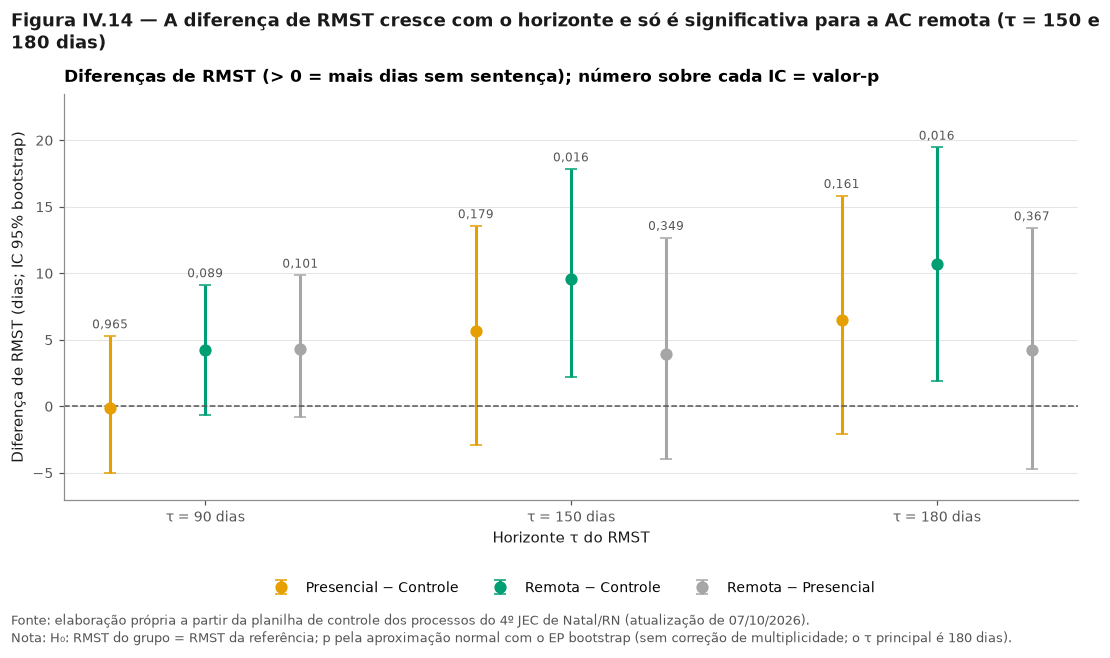

In [48]:
TAUS = [90, 150, 180]
B_BOOT = 2000
rng_boot = np.random.default_rng(SEMENTE + 41)
idx_g = {g: np.where(sob.grupo == g)[0] for g in ORDEM_GRUPO}
T_arr, E_arr = sob['T'].values.astype(int), sob['E'].values.astype(int)

linhas_rmst, dif_rmst, boot_rmst = [], [], {}
for tau in TAUS:
    # bootstrap estratificado por grupo
    bs = {g: np.empty(B_BOOT) for g in ORDEM_GRUPO}
    for b in range(B_BOOT):
        for g in ORDEM_GRUPO:
            ii = rng_boot.choice(idx_g[g], len(idx_g[g]), replace=True)
            bs[g][b] = rmst_grade(T_arr[ii], E_arr[ii], tau)
    boot_rmst[tau] = bs
    for g in ORDEM_GRUPO:
        m = restricted_mean_survival_time(km_g[g], t=tau)
        linhas_rmst.append({'τ (dias)': tau, 'Grupo': g, 'RMST (dias)': m, 'EP (bootstrap)': bs[g].std(ddof=1),
                            'IC 95% inf.': np.percentile(bs[g], 2.5), 'IC 95% sup.': np.percentile(bs[g], 97.5)})
    for a, b_ in [('Controle', 'Presencial'), ('Controle', 'Remota'), ('Presencial', 'Remota')]:
        est = rmst_grade(T_arr[idx_g[b_]], E_arr[idx_g[b_]], tau) - rmst_grade(T_arr[idx_g[a]], E_arr[idx_g[a]], tau)
        dist = bs[b_] - bs[a]; ep = dist.std(ddof=1)
        dif_rmst.append({'τ (dias)': tau, 'Contraste': f'{b_} − {a}', 'Diferença (dias)': est,
                         'IC 95% inf. (bootstrap)': np.percentile(dist, 2.5), 'IC 95% sup. (bootstrap)': np.percentile(dist, 97.5),
                         'p (normal, EP bootstrap)': 2 * stats.norm.sf(abs(est / ep))})
rmst_tab = pd.DataFrame(linhas_rmst)
dif_rmst = pd.DataFrame(dif_rmst)
print('Conferência: RMST(180) Controle — lifelines', fmt_br(rmst_tab.query('`τ (dias)` == 180 and Grupo == "Controle"')['RMST (dias)'].iloc[0], 3),
      '| grade diária', fmt_br(rmst_grade(T_arr[idx_g["Controle"]], E_arr[idx_g["Controle"]], 180), 3))
tabela(rmst_tab, 'sob_rmst_grupos', 'RMST por grupo e horizonte τ: dias, em média, sem sentença nos primeiros τ dias',
       secao='4.3.6', casas=1, formatos={'τ (dias)': 'int', 'EP (bootstrap)': 2},
       nota=f'RMST = área sob o Kaplan-Meier até τ (lifelines); EP e IC 95% percentil por bootstrap estratificado por grupo '
            f'({fmt_br(B_BOOT, 0)} reamostras).')
sob_tabela(dif_rmst, 'sob_rmst_diferencas', 'Diferenças de RMST entre grupos (dias; > 0 = mais dias sem sentença no 1º grupo)',
           secao='4.3.6', casas=2, colunas_p=('p (normal, EP bootstrap)',), formatos={'τ (dias)': 'int'},
           nota='IC 95% percentil por bootstrap; p pela aproximação normal com o EP bootstrap. Destaque: p < 0,05.')

# (a) a área entre as curvas é a diferença de RMST até 180 dias
tau = 180
tg = np.arange(0, tau + 1)
Sc, _ = aj_grade(T_arr[idx_g['Controle']], E_arr[idx_g['Controle']])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, g in zip(axes, ['Presencial', 'Remota']):
    Sg, _ = aj_grade(T_arr[idx_g[g]], E_arr[idx_g[g]])
    ax.step(tg, Sc[tg], where='post', color=CORES_GRUPO['Controle'], lw=2, label='Controle')
    ax.step(tg, Sg[tg], where='post', color=CORES_GRUPO[g], lw=2, label=g)
    ax.fill_between(tg, Sc[tg], Sg[tg], step='post', where=Sg[tg] >= Sc[tg], color=CORES_GRUPO[g], alpha=0.3, lw=0,
                    label='área: grupo com AC mais lento')
    ax.fill_between(tg, Sc[tg], Sg[tg], step='post', where=Sg[tg] < Sc[tg], color=CORES_GRUPO['Controle'], alpha=0.3, lw=0,
                    label='área: grupo com AC mais rápido')
    d = dif_rmst.query('`τ (dias)` == @tau and Contraste == @g + " − Controle"').iloc[0]
    ax.set_title(f'AC {g.lower()} × Controle')
    ax.set_xlabel(ROTULOS['dias']); ax.set_xlim(0, tau); ax.set_xticks(np.arange(0, tau + 1, 30))
    ax.set_ylim(0, 1.02); eixo_pct(ax); ax.grid(axis='both', visible=True)
    ax.legend(loc='lower left', fontsize=8.5)
    anotar_teste(ax, texto_teste(f'ΔRMST({tau}) = {fmt_br(d["Diferença (dias)"], 1)} dias',
                                 f'IC 95% [{fmt_br(d["IC 95% inf. (bootstrap)"], 1)}; {fmt_br(d["IC 95% sup. (bootstrap)"], 1)}]',
                                 d['p (normal, EP bootstrap)']), loc='upper right')
axes[0].set_ylabel(ROTULOS['S'])
figura(fig, 'sob_rmst_areas', 'Nos primeiros 180 dias, um processo com AC remota fica em média cerca de 11 dias a mais sem sentença',
       secao='4.3.6', nota='Kaplan-Meier até τ = 180 dias; a área sombreada entre as curvas é a diferença de RMST (área '
                           'acima da curva do Controle menos a área abaixo). IC 95% por bootstrap estratificado.')

# (b) diferenças de RMST com IC bootstrap nos três horizontes
fig, ax = plt.subplots(figsize=(10, 5.2))
CONTRASTES_RMST = ['Presencial − Controle', 'Remota − Controle', 'Remota − Presencial']
for j, c in enumerate(CONTRASTES_RMST):
    d = dif_rmst[dif_rmst.Contraste == c]
    cor = [CORES_GRUPO['Presencial'], CORES_GRUPO['Remota'], CINZA][j]
    xs = np.arange(len(TAUS)) + (j - 1) * 0.26
    ax.errorbar(xs, d['Diferença (dias)'], yerr=[d['Diferença (dias)'] - d['IC 95% inf. (bootstrap)'],
                d['IC 95% sup. (bootstrap)'] - d['Diferença (dias)']], fmt='o', ms=7, color=cor, capsize=4, label=c)
    for xi, (hi, pv) in zip(xs, d[['IC 95% sup. (bootstrap)', 'p (normal, EP bootstrap)']].values):
        ax.annotate(fmt_p(pv), (xi, hi), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom',
                    fontsize=8, color=TINTA_2)
ax.axhline(0, color=TINTA_2, ls='--', lw=1)
ax.set_xticks(range(len(TAUS)), [f'τ = {t} dias' for t in TAUS]); ax.grid(axis='x', visible=False)
ax.set_xlabel('Horizonte τ do RMST')
ax.set_ylabel('Diferença de RMST (dias; IC 95% bootstrap)')
ax.set_title('Diferenças de RMST (> 0 = mais dias sem sentença); número sobre cada IC = valor-p')
ax.set_ylim(dif_rmst['IC 95% inf. (bootstrap)'].min() - 2, dif_rmst['IC 95% sup. (bootstrap)'].max() + 4)
legenda_abaixo(ax, ncol=3, dy=-0.17)
figura(fig, 'sob_rmst', 'A diferença de RMST cresce com o horizonte e só é significativa para a AC remota (τ = 150 e 180 dias)',
       secao='4.3.6', nota='H₀: RMST do grupo = RMST da referência; p pela aproximação normal com o EP bootstrap (sem correção '
                           'de multiplicidade; o τ principal é 180 dias).')

**Interpretação (comparação das curvas).**

**Teste principal.** Log-rank de 3 grupos: χ²₂ = 7,52, **p = 0,023**. Rejeita-se H₀ de curvas iguais a 5%. O gráfico O/E mostra a direção: o Controle teve 14% **mais** sentenças do que o esperado sob H₀ (O/E = 1,14), e os grupos com AC tiveram menos (0,96 presencial; 0,90 remota).

**Família ponderada (sensibilidade).**

| Teste | Peso | χ²₂ | p |
|---|---|---|---|
| Wilcoxon | início | 6,40 | 0,041 |
| Tarone-Ware | meio-termo | 7,82 | 0,020 |
| Peto-Prentice | início | 6,77 | 0,034 |
| FH(0,1) | final | 4,91 | 0,086 |
| **FH(1,1)** | **meio do seguimento** | **13,80** | **0,001** (Holm 0,007) |

O teste mais forte é o que dá mais peso ao **meio** do seguimento. Isso confirma o que o KM mostra: a diferença está concentrada na faixa de 60 a 120 dias, e não no início nem na cauda. O log-rank, que pesa tudo igualmente, perde parte do poder porque nos extremos as curvas quase coincidem.

**Pares (Holm).**

- **Remota × Controle: p = 0,008 (Holm 0,023)**, significativo;
- Presencial × Controle: p = 0,061 (Holm 0,123), não significativo isoladamente, mas na mesma direção;
- Remota × Presencial: p = 0,519. Não há evidência de diferença entre as modalidades.

**Estratificado por mês.** O log-rank estratificado dá χ²₂ = 6,21, **p = 0,045**; o Gehan-Breslow e o Tarone-Ware estratificados dão p = 0,017 e 0,018. O resultado sobrevive à comparação dentro de cada mês: não é artefato da composição mensal (por exemplo, julho com mais Remota).

**Pontos fixos (Holm sobre 6 testes).**

- Aos 60 dias não há diferença (p ≥ 0,2).
- **Aos 90 dias**, a proporção ainda sem sentença é **12,7 p.p. maior** na AC presencial (IC 95%: 4,7 a 20,7; p Holm = 0,010) e **14,0 p.p. maior** na remota (5,9 a 22,1; p Holm = 0,005).
- Aos 120 dias a diferença cai para cerca de 8 p.p. (p = 0,040 e 0,037 sem correção; 0,149 com Holm).

**RMST.** O efeito médio em dias é modesto.

| τ | RMST Controle | Remota − Controle | Presencial − Controle |
|---|---|---|---|
| 180 d | 82,1 dias | **+10,7 dias** (IC bootstrap 1,9 a 19,5; p = 0,016) | +6,5 dias (−2,1 a 15,8; p = 0,16) |
| 150 d | — | +9,6 dias (p = 0,016) | — |
| 90 d | — | +4,2 dias (ns) | −0,1 dia |

A τ = 90 dias, o atraso dos grupos com AC no fim do intervalo é compensado pelos processos presenciais que terminam mais cedo. Em linguagem de gestão: **nos primeiros seis meses, um processo do rito com AC remota passou, em média, cerca de 11 dias a mais sem sentença** do que no rito atual. Na presencial, cerca de 6 dias a mais, sem significância.

---

## 4.4 Diagnóstico da hipótese de riscos proporcionais

O modelo de Cox (seção 4.5) resume o efeito do grupo numa única razão de riscos, **constante no tempo**: λ(t | x) = λ₀(t) exp(x′β). Antes de interpretar esse número, verifica-se se a hipótese é razoável. Se não for, o HR estimado é uma média ponderada de efeitos que mudam ao longo do tempo, e pode até esconder efeitos de sinais opostos.

### 4.4.1 Método gráfico: log[−log Ŝ(t)] × log t

Sob riscos proporcionais, S_g(t) = S₀(t)^{exp(β_g)}, logo log[−log S_g(t)] = log[−log S₀(t)] + β_g: as curvas dos grupos devem ser **paralelas** (distância vertical constante = β_g). Curvas que se cruzam ou convergem indicam violação (COLOSIMO; GIOLO, 2006, p. 167). Se, além de paralelas, forem retas, o modelo de Weibull é indicado (p. 96-99). O método é subjetivo, por isso é complementado pelo teste formal.

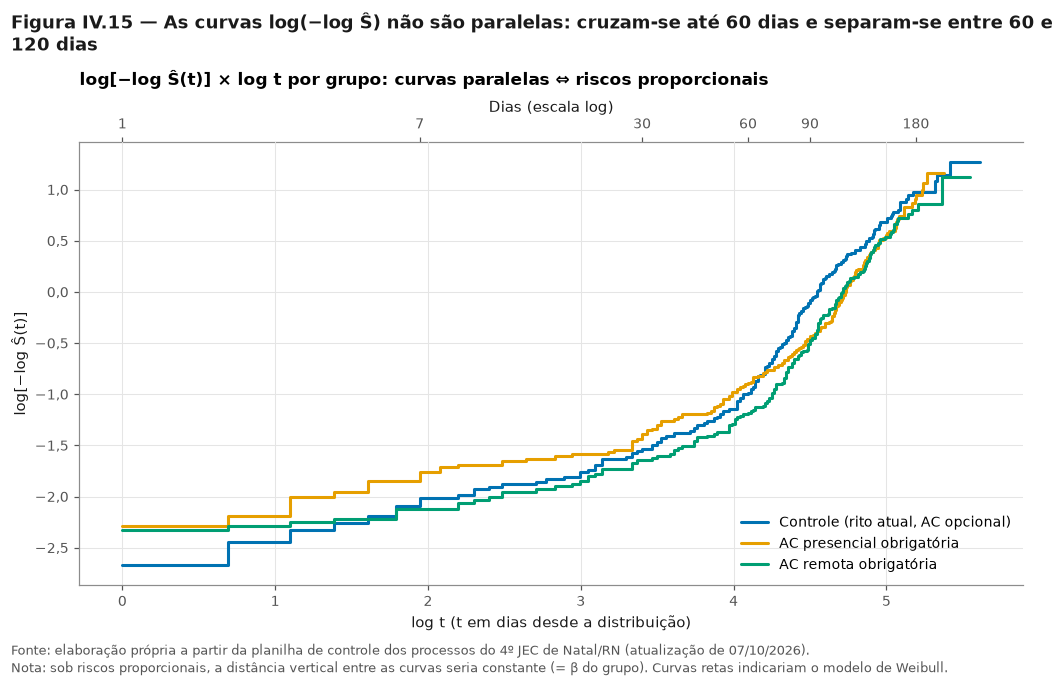

In [49]:
fig, ax = plt.subplots(figsize=(9.5, 5.4))
for g in ORDEM_GRUPO:
    sf_ = km_g[g].survival_function_.iloc[:, 0]
    sf_ = sf_[(sf_ > 0) & (sf_ < 1) & (sf_.index > 0)]
    ax.step(np.log(sf_.index), np.log(-np.log(sf_.values)), where='post', color=CORES_GRUPO[g], lw=2, label=ROTULO_GRUPO[g])
ax.set_xlabel('log t (t em dias desde a distribuição)'); ax.set_ylabel('log[−log Ŝ(t)]')
ax.grid(axis='both', visible=True)
sec = ax.secondary_xaxis('top', functions=(np.exp, np.log)); sec.set_xticks([1, 7, 30, 60, 90, 180])
sec.set_xlabel('Dias (escala log)')
sec.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: fmt_br(v, 0)))
ax.set_title('log[−log Ŝ(t)] × log t por grupo: curvas paralelas ⇔ riscos proporcionais', pad=10)
ax.legend(loc='lower right')
figura(fig, 'sob_loglog', 'As curvas log(−log Ŝ) não são paralelas: cruzam-se até 60 dias e separam-se entre 60 e 120 dias',
       secao='4.4.1', nota='sob riscos proporcionais, a distância vertical entre as curvas seria constante (= β do grupo). '
                           'Curvas retas indicariam o modelo de Weibull.')

### 4.4.2 Resíduos de Schoenfeld e teste de Grambsch-Therneau

Os **resíduos de Schoenfeld** comparam, em cada sentença, a covariável do processo sentenciado com a média ponderada das covariáveis dos que estavam em risco. Grambsch e Therneau (1994) mostraram que os resíduos **padronizados** s*_k somados a β̂ estimam β(t): se o efeito é constante, o gráfico de s*_k + β̂ contra uma função do tempo g(t) é **horizontal** (COLOSIMO; GIOLO, 2006, eq. 5.10, p. 167-169). O **teste** correspondente verifica a correlação entre os resíduos e g(t), por covariável (χ²₁) e globalmente (p. 169-170). As escolhas usuais de g(t) são t, log t, posto (*rank*) e 1 − KM ("na prática há pouca diferença"; o padrão do R é km, p. 170). O teste é aplicado ao modelo de Cox com grupo + mês (o modelo ajustado da seção 4.5), com as transformações posto, km e identidade (log t não é usado porque há sentenças no dia 0, e log 0 não existe).

- H₀: β_q(t) = β_q (efeito constante; riscos proporcionais);
- H₁: β_q(t) varia monotonicamente com g(t).

**Gráfico do teste:** s*_k + β̂ contra o posto do tempo e contra o tempo em dias, com suavização *lowess*; a linha tracejada é o β̂ constante do Cox. O eixo vertical está na escala do log-HR: **acima de 0 = sentença mais rápida que no Controle naquele momento; abaixo = mais lenta**.

g(t),Termo,χ² (1 g.l.),p
posto,AC presencial × Controle,"0,48","0,488"
posto,AC remota × Controle,"0,00","0,980"
1 − KM,AC presencial × Controle,"0,09","0,764"
1 − KM,AC remota × Controle,"0,04","0,841"
t (identidade),AC presencial × Controle,"0,27","0,600"
t (identidade),AC remota × Controle,"0,00","0,979"


Termo,χ² (1 g.l.),p
fev × jan,"2,08","0,149"
mar × jan,"1,53","0,215"
abr × jan,"1,14","0,286"
mai × jan,"2,98","0,084"
jun × jan,"0,74","0,389"
jul-ago × jan,"2,40","0,121"


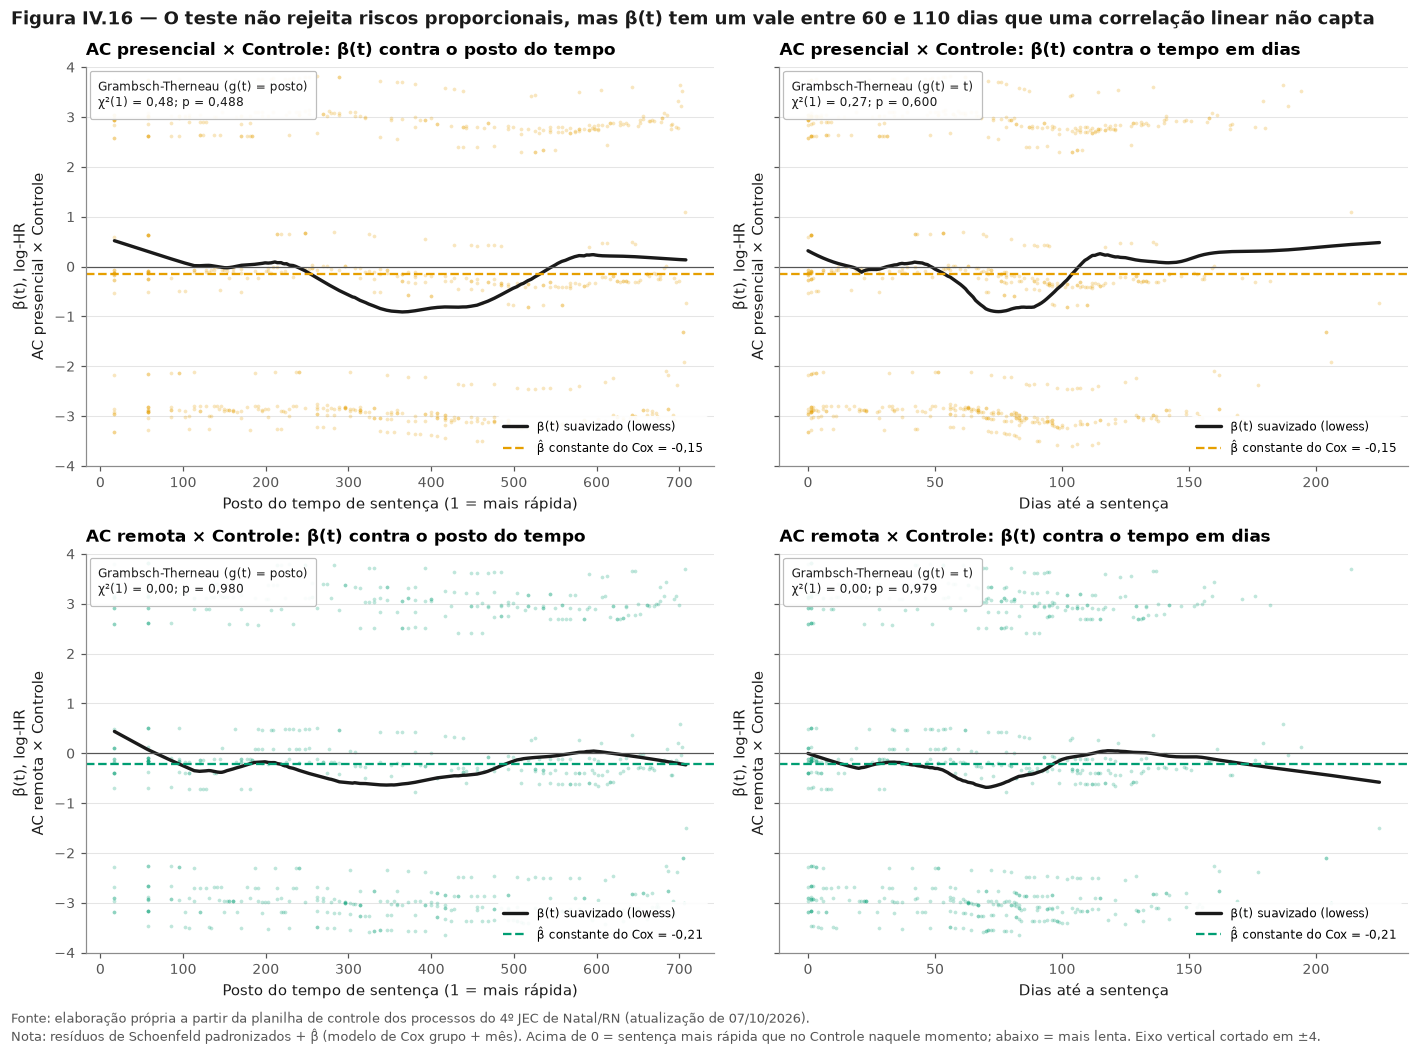

In [50]:
X_BASE = ['Presencial', 'Remota']
X_AJ = X_BASE + COLS_MES + ['origem_ext']
cox_ph = CoxPHFitter().fit(sob[['T', 'E'] + X_BASE + COLS_MES], 'T', 'E')
res_ph = []
for tr in ['rank', 'km', 'identity']:
    r = proportional_hazard_test(cox_ph, sob[['T', 'E'] + X_BASE + COLS_MES], time_transform=tr)
    sm_ = r.summary
    for termo in X_BASE:
        res_ph.append({'g(t)': tr, 'Termo': ROTULO_TERMO[termo], 'χ² (1 g.l.)': sm_.loc[termo, 'test_statistic'], 'p': sm_.loc[termo, 'p']})
res_ph = pd.DataFrame(res_ph)
NOME_GT = {'rank': 'posto', 'km': '1 − KM', 'identity': 't (identidade)'}
sob_tabela(res_ph.assign(**{'g(t)': res_ph['g(t)'].map(NOME_GT)}), 'sob_schoenfeld_grupo',
           'Teste de Grambsch-Therneau (resíduos de Schoenfeld) para os termos de grupo, por transformação do tempo',
           secao='4.4.2', casas=2, colunas_p=('p',), nota='modelo de Cox grupo + mês; H₀: efeito constante no tempo (riscos proporcionais).')
_r = proportional_hazard_test(cox_ph, sob[['T', 'E'] + X_BASE + COLS_MES], time_transform='rank').summary
sob_tabela(_r.loc[COLS_MES, ['test_statistic', 'p']].rename(index=ROTULO_TERMO, columns={'test_statistic': 'χ² (1 g.l.)'})
           .rename_axis('Termo'), 'sob_schoenfeld_meses',
           'Teste de Grambsch-Therneau para os termos de mês (transformação posto)', secao='4.4.2', casas=2, colunas_p=('p',))

sch = cox_ph.compute_residuals(sob[['T', 'E'] + X_BASE + COLS_MES], kind='scaled_schoenfeld')
t_ev = sob.loc[sch.index, 'T'].values
ordem_t = stats.rankdata(t_ev)
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey='row')
for i, termo in enumerate(X_BASE):
    beta = cox_ph.params_[termo]
    yv = sch[termo].values + beta
    for j, (xv, nome) in enumerate([(ordem_t, 'Posto do tempo de sentença (1 = mais rápida)'), (t_ev, 'Dias até a sentença')]):
        ax = axes[i, j]
        ax.scatter(xv, yv, s=6, color=CORES_GRUPO[termo], alpha=0.25, lw=0)
        lw = lowess(yv, xv, frac=0.3)
        ax.plot(lw[:, 0], lw[:, 1], color=TINTA, lw=2.2, label='β(t) suavizado (lowess)')
        ax.axhline(beta, color=CORES_GRUPO[termo], ls='--', lw=1.5, label=f'β̂ constante do Cox = {fmt_br(beta, 2)}')
        ax.axhline(0, color=TINTA_2, lw=0.8)
        ax.set_ylim(-4, 4); ax.set_xlabel(nome); ax.set_ylabel(f'β(t), log-HR\n{ROTULO_TERMO[termo]}')
        tr = 'rank' if j == 0 else 'identity'
        linha = res_ph[(res_ph['g(t)'] == tr) & (res_ph.Termo == ROTULO_TERMO[termo])].iloc[0]
        ax.set_title(f'{ROTULO_TERMO[termo]}: β(t) contra {"o posto do tempo" if j == 0 else "o tempo em dias"}')
        ax.legend(fontsize=8, loc='lower right', framealpha=0.9, frameon=True)
        anotar_teste(ax, texto_teste(f'Grambsch-Therneau (g(t) = {'posto' if tr == 'rank' else 't'})',
                                     f'χ²(1) = {fmt_br(linha["χ² (1 g.l.)"], 2)}', linha['p']), loc='upper left', tamanho=8)
figura(fig, 'sob_schoenfeld', 'O teste não rejeita riscos proporcionais, mas β(t) tem um vale entre 60 e 110 dias que '
       'uma correlação linear não capta', secao='4.4.2',
       nota='resíduos de Schoenfeld padronizados + β̂ (modelo de Cox grupo + mês). Acima de 0 = sentença mais rápida que no '
            'Controle naquele momento; abaixo = mais lenta. Eixo vertical cortado em ±4.')

**Interpretação (riscos proporcionais).**

- **Gráfico log(−log Ŝ).** As curvas **não são paralelas**:
  - nos primeiros ~30 dias, a AC presencial está *acima* das demais (mais sentenças precoces);
  - entre 30 e 60 dias as curvas se cruzam;
  - entre ~60 e 120 dias o Controle se afasta para cima (mais sentenças);
  - depois de ~150 dias as curvas voltam a se juntar.

  Esse é um padrão de efeito que **muda de sinal e de intensidade com o tempo**.
- **Teste de Grambsch-Therneau.** Não rejeita a proporcionalidade para nenhum termo: p = 0,49, 0,76 e 0,60 para a presencial (posto, km, t) e 0,98, 0,84 e 0,98 para a remota. Os meses também não violam a hipótese (p entre 0,08 e 0,39).
- **Por que o teste não detecta o que o gráfico mostra.** O teste mede a **correlação linear** entre os resíduos e g(t), ou seja, uma tendência *monótona* de β(t). A suavização *lowess* dos resíduos de Schoenfeld mostra outra forma: β(t) perto de zero no início, um **vale** entre ~60 e ~110 dias (β(t) ≈ −0,9, isto é, HR ≈ 0,4 na presencial) e retorno a zero depois. Um desvio em "U" tem correlação quase nula com o tempo, e o teste perde poder. Colosimo e Giolo (2006, p. 167-170) recomendam ler o gráfico junto com o teste.
- **Consequência.** O HR único do Cox (seção 4.5.1) é uma **média** de um efeito que se concentra numa janela. Por isso a seção 4.5.2 estima o efeito por janela de tempo, e o RMST e os pontos fixos (4.3), que não supõem proporcionalidade, são relatados ao lado do HR.

---

## 4.5 Modelos de Cox

O modelo de riscos proporcionais de Cox (COX, 1972) é λ(t | x) = λ₀(t) exp(x′β), com λ₀(t) não especificado. β é estimado pela verossimilhança parcial L(β) = ∏ [exp(x_i′β) / Σ_{j ∈ R(t_i)} exp(x_j′β)]^{δ_i} (COLOSIMO; GIOLO, 2006, eq. 5.6, p. 161). Como o tempo é medido em dias, há muitos **empates** (vários processos sentenciados no mesmo dia); usa-se a aproximação de **Efron** (1977), melhor que a de Breslow quando os empates são numerosos (p. 161-162), que é o padrão do `CoxPHFitter`.

**Interpretação.** exp(β_g) é a razão de riscos (HR) do grupo g em relação ao Controle (referência), constante no tempo (p. 162-164). Na linguagem do processo: HR = 0,80 significa que, a cada dia, um processo do grupo com AC que ainda está pendente tem 20% **menos** "chance instantânea" de receber sentença do que um processo do Controle também pendente, ou seja, **tramita mais devagar**.

**Modelos ajustados.**

| Modelo | Covariáveis | Para quê |
|---|---|---|
| (a) | grupo | efeito total do rito (o sorteio dispensa ajuste para não haver viés) |
| (b) | grupo + mês de distribuição + origem externa | precisão e controle do calendário (composição mensal, seguimento) |
| (b′) | grupo + origem externa, **estratificado por mês** | risco basal próprio de cada mês, sem supor efeito proporcional do mês |
| (c) | grupo × janela de tempo + mês + origem | efeito do rito **variando no tempo** (se os riscos não forem proporcionais) |

O **dia da semana** da distribuição não entra: não há mecanismo plausível pelo qual ele altere a duração (é apenas o dia do protocolo) e, com 7 níveis, só gastaria graus de liberdade. Os **acordos** (`acordo_ac`, `acordo_fora`) **não** entram como covariáveis: ocorrem durante o processo e definem o tipo de desfecho; usá-los como covariável fixa criaria viés de tempo imortal (seção 4.7 os trata como desfecho).

### 4.5.1 Modelos (a), (b) e (b′)

Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
AC presencial × Controle,"0,839","0,7","1,0","0,053"
AC remota × Controle,"0,787","0,7","0,9","0,009"


Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
AC presencial × Controle,"0,867","0,7","1,0","0,117"
AC remota × Controle,"0,809","0,7","1,0","0,022"
fev × jan,"1,134","0,9","1,5","0,379"
mar × jan,"0,825","0,6","1,1","0,154"
abr × jan,"0,806","0,6","1,1","0,120"
mai × jan,"0,832","0,6","1,1","0,192"
jun × jan,"0,703","0,5","1,0","0,023"
jul-ago × jan,"0,575","0,4","0,8","0,002"
Origem externa × 4º JEC,"0,776","0,4","1,5","0,455"


Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
AC presencial × Controle,"0,856","0,7","1,0","0,091"
AC remota × Controle,"0,801","0,7","1,0","0,017"
Origem externa × 4º JEC,"0,847","0,4","1,6","0,624"


Modelo,log-verossimilhança parcial,TRV vs. nulo (χ²),g.l.,p (TRV),AIC parcial,Concordância (C de Harrell)
(a) grupo,"-4.232,6","7,36",2,"0,025","8.469,2","0,529"
(b) grupo + mês + origem,"-4.221,3","29,92",9,"< 0,001","8.460,7","0,564"
"(b′) grupo + origem, estrato = mês","-2.924,5","6,29",3,"0,098","5.855,1","0,531"


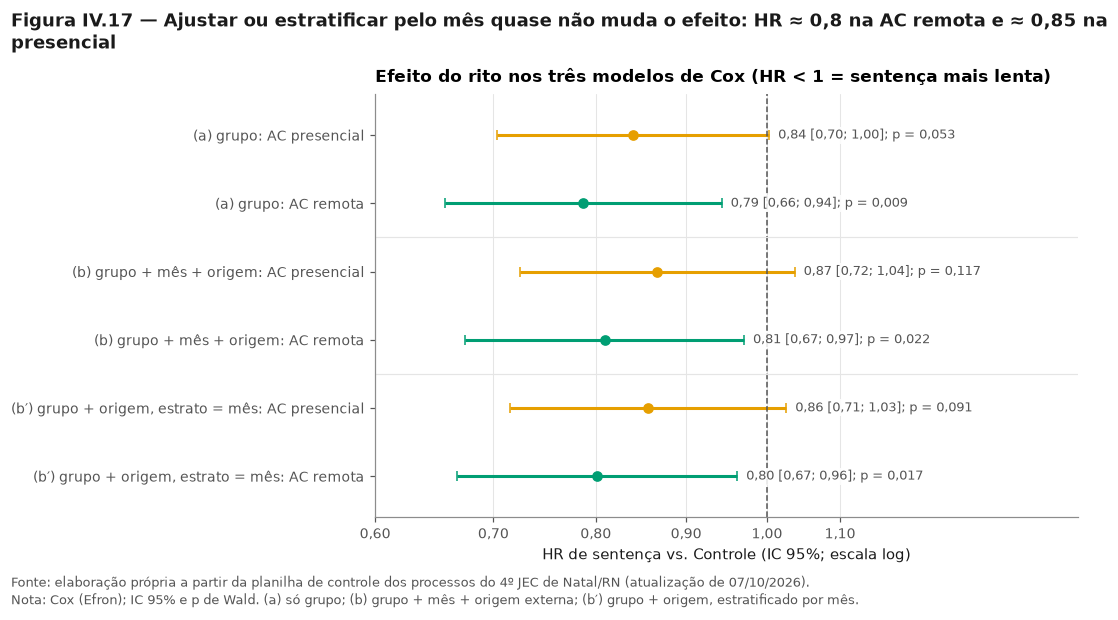

In [51]:
cox_a = CoxPHFitter().fit(sob[['T', 'E'] + X_BASE], 'T', 'E')
cox_b = CoxPHFitter().fit(sob[['T', 'E'] + X_AJ], 'T', 'E')
cox_bs = CoxPHFitter().fit(sob[['T', 'E', 'mes_cod'] + X_BASE + ['origem_ext']], 'T', 'E', strata=['mes_cod'])
MODELOS_COX = {'(a) grupo': cox_a, '(b) grupo + mês + origem': cox_b, "(b′) grupo + origem, estrato = mês": cox_bs}

for (nome, m), id_ in zip(MODELOS_COX.items(), ['sob_cox_a', 'sob_cox_b', 'sob_cox_bs']):
    sob_tabela(tabela_hr(m).rename_axis('Termo'), id_, f'Modelo de Cox {nome}: razões de risco de sentença (Efron)',
               secao='4.5.1', casas=3, colunas_p=('p (Wald)',),
               nota='HR < 1 = sentença mais lenta que na referência; IC 95% e p de Wald. Destaque: p < 0,05.')

def resumo_ajuste(m):
    lr = m.log_likelihood_ratio_test()
    return pd.Series({'log-verossimilhança parcial': m.log_likelihood_, 'TRV vs. nulo (χ²)': lr.test_statistic,
                      'g.l.': lr.degrees_freedom, 'p (TRV)': lr.p_value,
                      'AIC parcial': m.AIC_partial_, 'Concordância (C de Harrell)': m.concordance_index_})
ajuste_cox = pd.DataFrame({n: resumo_ajuste(m) for n, m in MODELOS_COX.items()}).T
sob_tabela(ajuste_cox.rename_axis('Modelo'), 'sob_cox_ajuste', 'Ajuste dos modelos de Cox: verossimilhança, TRV contra o nulo, '
           'AIC parcial e concordância', secao='4.5.1', casas=3, colunas_p=('p (TRV)',), destaque=None,
           formatos={'g.l.': 'int', 'log-verossimilhança parcial': 1, 'AIC parcial': 1, 'TRV vs. nulo (χ²)': 2},
           nota='o AIC parcial do modelo estratificado (b′) não é comparável ao dos outros (verossimilhança por estrato).')

_flor = pd.concat({nome: tabela_hr(m, X_BASE) for nome, m in MODELOS_COX.items()})
_flor.index = [f'{nome}: {termo.replace(" × Controle", "")}' for nome, termo in _flor.index]
fig, ax = plt.subplots(figsize=(10, 4.8))
floresta(ax, _flor, cor_de=lambda n: CORES_GRUPO['Presencial'] if 'presencial' in n else CORES_GRUPO['Remota'],
         xlabel='HR de sentença vs. Controle (IC 95%; escala log)', ticks=[0.6, 0.7, 0.8, 0.9, 1, 1.1])
ax.set_xlim(0.6, 1.5)
for yi in (1.5, 3.5):
    ax.axhline(yi, color=GRADE, lw=0.8)
ax.set_title('Efeito do rito nos três modelos de Cox (HR < 1 = sentença mais lenta)')
figura(fig, 'sob_cox_floresta', 'Ajustar ou estratificar pelo mês quase não muda o efeito: HR ≈ 0,8 na AC remota e ≈ 0,85 na presencial',
       secao='4.5.1', nota='Cox (Efron); IC 95% e p de Wald. (a) só grupo; (b) grupo + mês + origem externa; '
                           '(b′) grupo + origem, estratificado por mês.')
HR_B = tabela_hr(cox_b, X_BASE)

**Curvas de sobrevivência ajustadas.** Para mostrar o que o modelo (b) implica em escala de tempo, calcula-se a curva **padronizada** de cada grupo: atribui-se o grupo g a todos os 938 processos (mantidos o mês e a origem de cada um), prevê-se Ŝ(t | x) = Ŝ₀(t)^{exp(x′β̂)} (COLOSIMO; GIOLO, 2006, p. 164-165) e tira-se a média. É a curva que se observaria se toda a amostra tivesse sido alocada ao grupo g. As curvas de KM aparecem tracejadas para comparação: se o Cox é adequado, as duas devem estar próximas.

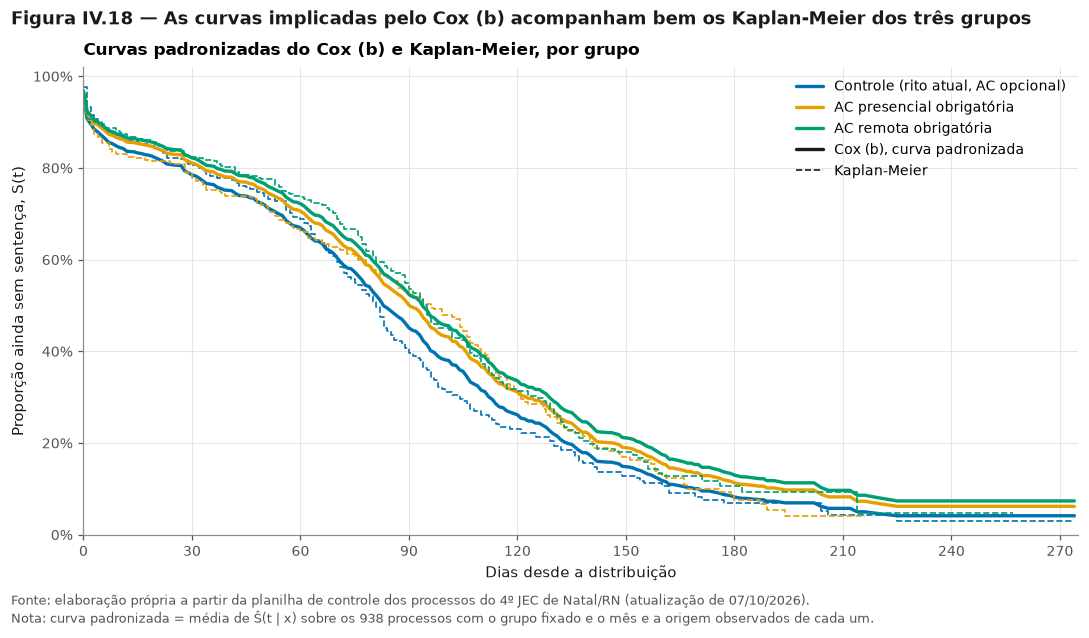

In [52]:
grade_t = np.arange(0, 275)
fig, ax = plt.subplots(figsize=(10, 5.2))
for g in ORDEM_GRUPO:
    x_g = sob[X_AJ].copy(); x_g['Presencial'] = int(g == 'Presencial'); x_g['Remota'] = int(g == 'Remota')
    S_pad = cox_b.predict_survival_function(x_g, times=grade_t).mean(axis=1)
    ax.plot(grade_t, S_pad, color=CORES_GRUPO[g], lw=2.2)
    sf_ = km_g[g].survival_function_.iloc[:, 0]
    ax.step(sf_.index, sf_.values, where='post', color=CORES_GRUPO[g], ls='--', lw=1.1)
ax.set_xlim(0, 275); ax.set_xticks(np.arange(0, 271, 30)); ax.set_ylim(0, 1.02); eixo_pct(ax)
ax.grid(axis='both', visible=True)
ax.set_xlabel(ROTULOS['dias']); ax.set_ylabel(ROTULOS['S'])
ax.set_title('Curvas padronizadas do Cox (b) e Kaplan-Meier, por grupo')
ax.legend(handles=LEG_GRUPO(longo=True) + [Line2D([], [], color=TINTA, lw=2.2, label='Cox (b), curva padronizada'),
                                           Line2D([], [], color=TINTA, lw=1.1, ls='--', label='Kaplan-Meier')],
          loc='upper right')
figura(fig, 'sob_cox_curvas', 'As curvas implicadas pelo Cox (b) acompanham bem os Kaplan-Meier dos três grupos',
       secao='4.5.1', nota='curva padronizada = média de Ŝ(t | x) sobre os 938 processos com o grupo fixado e o mês e a origem '
                           'observados de cada um.')

### 4.5.2 Efeito do rito variando no tempo: modelo (c) com janelas

Se os resíduos de Schoenfeld (4.4.2) mostram que o efeito do grupo muda com o tempo, um único HR é um resumo enganoso. A solução recomendada é permitir um coeficiente por **janela de tempo** (COLOSIMO; GIOLO, 2006, p. 170-172; MORETTIN; SINGER, 2021, p. 256, nota 2): cada processo é dividido em episódios (0, 30], (30, 90] e (90, ∞) dias, e o grupo entra interagido com a janela. Os cortes têm justificativa substantiva:

- **até 30 dias**: fase anterior à AC na maioria dos casos (citação, intimação e pauta); concentra as extinções imediatas e as redistribuições;
- **30 a 90 dias**: período em que as audiências obrigatórias ocorrem e em que se dão a ausência do autor (extinção, art. 51, I, da Lei 9.099/1995) e os acordos;
- **após 90 dias**: fase de instrução e julgamento de mérito.

O modelo é ajustado em formato de **processo de contagem** (início, fim] com o `CoxTimeVaryingFitter` (Efron). Como o `lifelines` exige início < fim, os tempos são deslocados em +0,5 dia (só a ordem dos tempos importa na verossimilhança parcial, logo o deslocamento não altera nada). A primeira célula confere que o modelo sem interação reproduz exatamente o Cox (b). O TRV compara (c) com (b): H₀: o HR de cada grupo é o mesmo nas três janelas (4 g.l.).

Conferência: HR Presencial, Cox (b) = 0,8666 | contagem sem interação = 0,8666
TRV (c) × (b): χ² = 11,04, 4 g.l., p = 0,026  |  AIC parcial (b) = 8.460,7; (c) = 8.457,6


Janela de tempo,Controle,Presencial,Remota
0–30 d,60,68,54
30–90 d,122,75,80
> 90 d,80,87,82


Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
"AC presencial × Controle, 0–30 d","1,191","0,8","1,7","0,324"
"AC presencial × Controle, 30–90 d","0,616","0,5","0,8","< 0,001"
"AC presencial × Controle, > 90 d","1,010","0,7","1,4","0,947"
"AC remota × Controle, 0–30 d","0,934","0,6","1,4","0,718"
"AC remota × Controle, 30–90 d","0,634","0,5","0,8","0,002"
"AC remota × Controle, > 90 d","0,982","0,7","1,3","0,907"


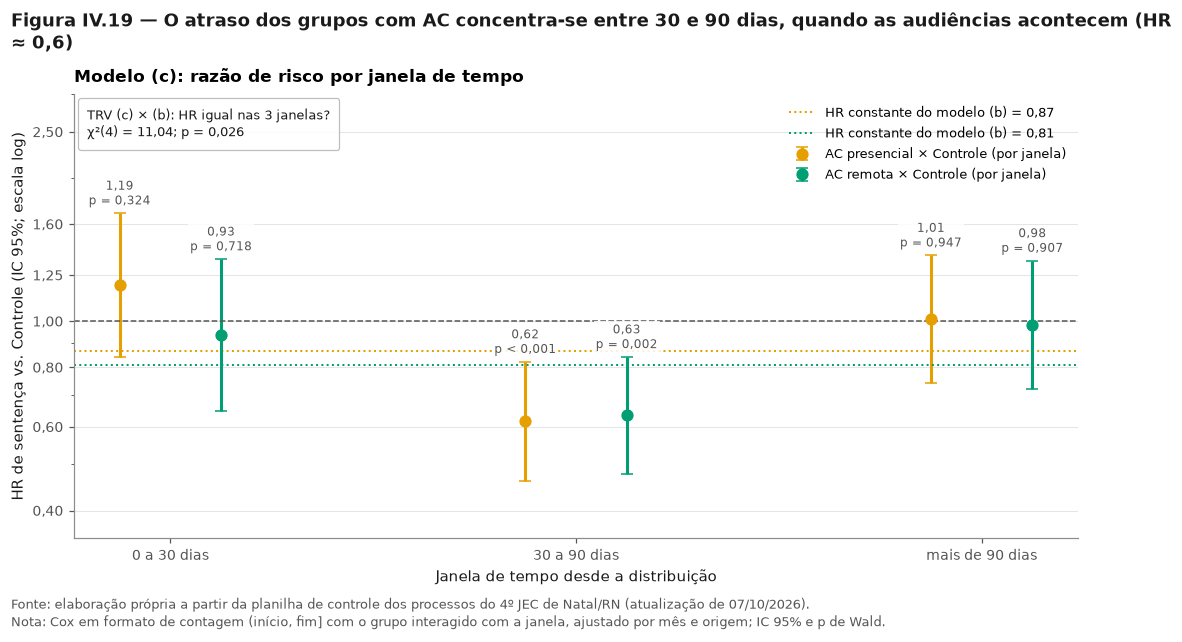

In [53]:
CORTES = [30, 90]
JANELAS = ['0–30 d', '30–90 d', '> 90 d']

def dividir_episodios(df, cortes=CORTES, desloc=0.5):
    """Formato de contagem (start, stop] com uma linha por processo e janela de tempo."""
    lim = [0.0] + [c + desloc for c in cortes] + [np.inf]
    partes = []
    for j in range(len(lim) - 1):
        a, b = lim[j], lim[j + 1]
        T = df['T'] + desloc
        sub = df[T > a].copy()
        Ts = sub['T'] + desloc
        sub['start'] = a; sub['stop'] = np.minimum(Ts, b)
        sub['ev'] = ((sub['E'] == 1) & (Ts <= b)).astype(int)
        sub['janela'] = j
        partes.append(sub)
    ep = pd.concat(partes).reset_index().rename(columns={'index': 'id'})
    for j in range(len(lim) - 1):
        for g in X_BASE:
            ep[f'{g}_j{j}'] = ep[g] * (ep['janela'] == j)
    return ep

ep = dividir_episodios(sob)
COLS_INT = [f'{g}_j{j}' for g in X_BASE for j in range(3)]
ctv_b = CoxTimeVaryingFitter().fit(ep[['id', 'start', 'stop', 'ev'] + X_AJ], id_col='id', event_col='ev', start_col='start', stop_col='stop')
ctv_c = CoxTimeVaryingFitter().fit(ep[['id', 'start', 'stop', 'ev'] + COLS_INT + COLS_MES + ['origem_ext']],
                                   id_col='id', event_col='ev', start_col='start', stop_col='stop')
print(f'Conferência: HR Presencial, Cox (b) = {fmt_br(np.exp(cox_b.params_["Presencial"]), 4)} | '
      f'contagem sem interação = {fmt_br(np.exp(ctv_b.params_["Presencial"]), 4)}')
trv_c = 2 * (ctv_c.log_likelihood_ - ctv_b.log_likelihood_)
P_TRV_C = stats.chi2.sf(trv_c, 4)
print(f'TRV (c) × (b): χ² = {fmt_br(trv_c, 2)}, 4 g.l., p = {p_br(P_TRV_C)}  |  '
      f'AIC parcial (b) = {fmt_br(-2 * ctv_b.log_likelihood_ + 2 * len(ctv_b.params_), 1)}; (c) = {fmt_br(-2 * ctv_c.log_likelihood_ + 2 * len(ctv_c.params_), 1)}')

hr_c = ctv_c.summary.loc[COLS_INT]
HR_C = pd.DataFrame({'HR': hr_c['exp(coef)'], 'IC 95% inf.': hr_c['exp(coef) lower 95%'], 'IC 95% sup.': hr_c['exp(coef) upper 95%'],
                     'p (Wald)': hr_c['p']})
HR_C.index = [f'{ROTULO_TERMO[g]}, {JANELAS[j]}' for g in X_BASE for j in range(3)]
eventos_jan = ep.groupby(['janela', 'grupo'], observed=True)['ev'].sum().unstack()
eventos_jan.index = JANELAS
_ej = eventos_jan.copy(); _ej.columns = [str(c) for c in _ej.columns]
tabela(_ej.rename_axis('Janela de tempo'), 'sob_cox_janelas_eventos', 'Sentenças em cada janela de tempo, por grupo',
       secao='4.5.2', formatos={c: 'int' for c in _ej.columns})
sob_tabela(HR_C.rename_axis('Termo'), 'sob_cox_janelas', 'Modelo (c): razão de risco de sentença por janela de tempo (Cox em '
           'formato de contagem, ajustado por mês e origem)', secao='4.5.2', casas=3, colunas_p=('p (Wald)',),
           nota=f'TRV (c) × (b): χ² = {fmt_br(trv_c, 2)}, 4 g.l., {p_txt(P_TRV_C)}. Destaque: p < 0,05.')

fig, ax = plt.subplots(figsize=(10, 5))
for i, g in enumerate(X_BASE):
    d = HR_C.iloc[3 * i:3 * i + 3]
    xs = np.arange(3) + (i - 0.5) * 0.25
    ax.errorbar(xs, d['HR'], yerr=[d['HR'] - d['IC 95% inf.'], d['IC 95% sup.'] - d['HR']], fmt='o', ms=7,
                color=CORES_GRUPO[g], capsize=4, label=f'{ROTULO_TERMO[g]} (por janela)')
    for xi, (hr, hi, pv) in zip(xs, d[['HR', 'IC 95% sup.', 'p (Wald)']].values):
        ax.annotate(f'{fmt_br(hr, 2)}\n{p_txt(pv)}', (xi, hi), xytext=(0, 3), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, color=TINTA_2, bbox=CAIXA_TXT)
    ax.axhline(np.exp(cox_b.params_[g]), color=CORES_GRUPO[g], ls=':', lw=1.3,
               label=f'HR constante do modelo (b) = {fmt_br(np.exp(cox_b.params_[g]), 2)}')
ax.axhline(1, color=TINTA_2, ls='--', lw=1); ax.set_yscale('log')
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: fmt_br(v, 2))); ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_yticks([0.4, 0.6, 0.8, 1, 1.25, 1.6, 2.5]); ax.set_ylim(0.35, 3)
ax.set_xticks(range(3), ['0 a 30 dias', '30 a 90 dias', 'mais de 90 dias']); ax.grid(axis='x', visible=False)
ax.set_xlabel('Janela de tempo desde a distribuição')
ax.set_ylabel('HR de sentença vs. Controle (IC 95%; escala log)')
ax.set_title('Modelo (c): razão de risco por janela de tempo')
ax.legend(loc='upper right', fontsize=8.5)
anotar_teste(ax, texto_teste('TRV (c) × (b): HR igual nas 3 janelas?', f'χ²(4) = {fmt_br(trv_c, 2)}', P_TRV_C), loc='upper left')
figura(fig, 'sob_cox_janelas', 'O atraso dos grupos com AC concentra-se entre 30 e 90 dias, quando as audiências acontecem (HR ≈ 0,6)',
       secao='4.5.2', nota='Cox em formato de contagem (início, fim] com o grupo interagido com a janela, ajustado por mês e '
                           'origem; IC 95% e p de Wald.')

### 4.5.3 Adequação global: resíduos de Cox-Snell

Os resíduos de Cox-Snell são ê_i = Λ̂₀(t_i) exp(x_i′β̂) (risco acumulado estimado de cada processo no seu próprio tempo). Se o modelo está bem ajustado, eles se comportam como uma amostra censurada de uma exponencial padrão, e o risco acumulado de Nelson-Aalen **dos próprios resíduos** fica sobre a reta de inclinação 1 (COLOSIMO; GIOLO, 2006, p. 166; eq. 4.11, p. 124). Esse resíduo avalia o ajuste global; **não** serve para testar riscos proporcionais (p. 166). Calcula-se como ê_i = δ_i − m̂_i, sendo m̂_i o resíduo martingal.

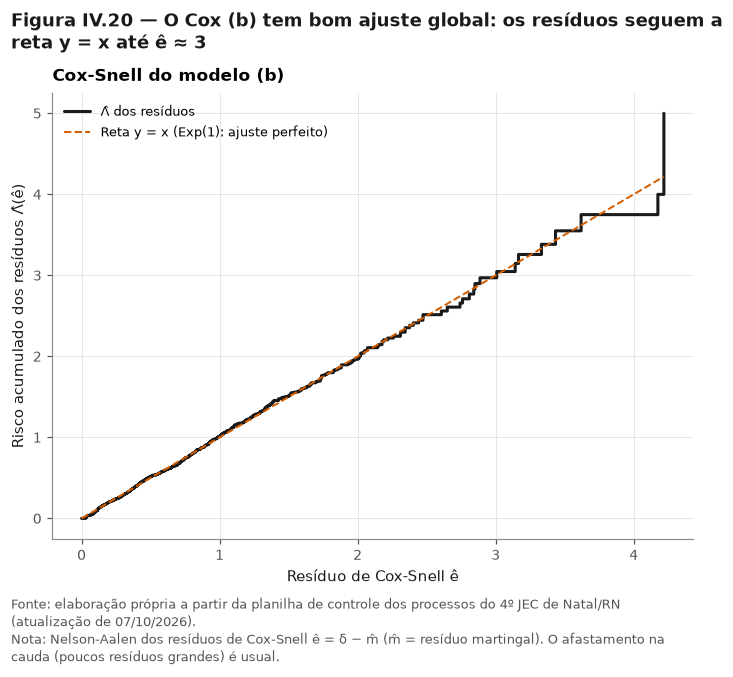

In [54]:
def cox_snell_plot(ax, ei, delta, titulo, cor=TINTA):
    na = NelsonAalenFitter().fit(ei, delta)
    ax.step(na.cumulative_hazard_.index, na.cumulative_hazard_.iloc[:, 0], where='post', color=cor, lw=2, label='Λ̂ dos resíduos')
    lim = float(np.nanmax(na.cumulative_hazard_.index[np.isfinite(na.cumulative_hazard_.iloc[:, 0])]))
    ax.plot([0, lim], [0, lim], color=DESTAQUE, ls='--', lw=1.3, label='Reta y = x (Exp(1): ajuste perfeito)')
    ax.set_xlabel('Resíduo de Cox-Snell ê'); ax.set_ylabel('Risco acumulado dos resíduos Λ̂(ê)')
    ax.set_title(titulo); ax.legend(fontsize=8.5, loc='upper left'); ax.grid(axis='both', visible=True)

mart_b = cox_b.compute_residuals(sob[['T', 'E'] + X_AJ], kind='martingale')
cs_b = sob.loc[mart_b.index, 'E'] - mart_b['martingale']
fig, ax = plt.subplots(figsize=(6.5, 5))
cox_snell_plot(ax, cs_b.values, sob.loc[mart_b.index, 'E'].values, 'Cox-Snell do modelo (b)')
figura(fig, 'sob_cox_snell', 'O Cox (b) tem bom ajuste global: os resíduos seguem a reta y = x até ê ≈ 3',
       secao='4.5.3', nota='Nelson-Aalen dos resíduos de Cox-Snell ê = δ − m̂ (m̂ = resíduo martingal). '
                           'O afastamento na cauda (poucos resíduos grandes) é usual.')

### 4.5.4 Resíduos martingal (forma funcional), deviance (atípicos) e dfbeta (influência)

- **Martingal** m̂_i = δ_i − ê_i: diferença entre o número observado de eventos do processo (0 ou 1) e o esperado pelo modelo. Contra uma covariável **não incluída**, a curva suavizada sugere a sua forma funcional (COLOSIMO; GIOLO, 2006, p. 172-173). Aqui, contra a **ordem de chegada** (1 a 938), ajustando um modelo só com o grupo: uma curva plana indica que não há tendência de calendário residual; uma curva inclinada indica que processos mais antigos/recentes têm mais/menos sentenças que o esperado, justificando o mês no modelo. É também o teste de tendência do calendário mencionado em 4.3.3.
- **Deviance** d̂_i = sinal(m̂_i)·√{−2[m̂_i + δ_i log(δ_i − m̂_i)]}: versão simétrica do martingal; valores com |d̂| > 2,5 apontam processos mal ajustados (eq. 5.11, p. 172-173).
- **dfbeta** Δβ̂_(i): variação no coeficiente do grupo quando o processo i é retirado (p. 173). Mede influência; destacam-se os processos com |Δβ̂| > 2/√n.

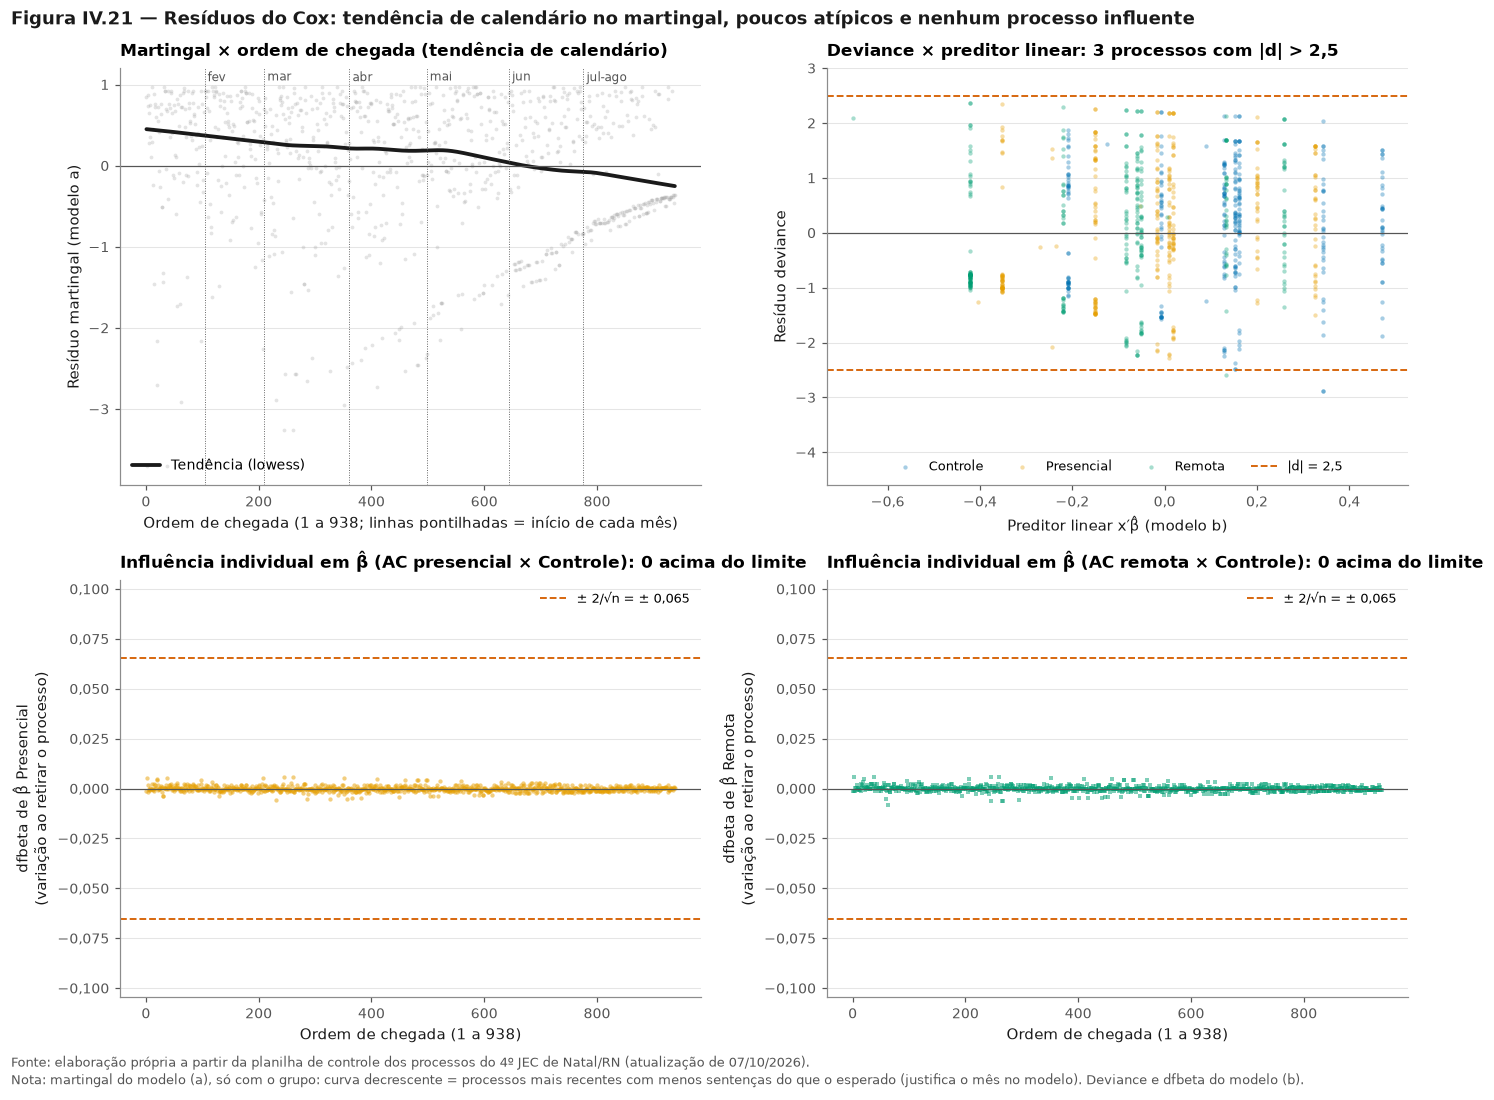

Deviance |d| > 2,5: 3 processos | |dfbeta| > 2/√n (= 0,065): Presencial 0, Remota 0
Maior |dfbeta| (Presencial): 0,0056 — frente a β̂ = -0,143 (EP 0,091)


Processo,Grupo,Mês,Desfecho,Tempo (dias),Sentença (δ),dfbeta Presencial,dfbeta Remota
0800987-86.2026.8.20.5004,Remota,jan,Ativo,257,0,"-0,0014","-0,0082"
0804047-67.2026.8.20.5004,Remota,mar,Ativo,209,0,"0,0000","-0,0061"
0804094-41.2026.8.20.5004,Remota,mar,Ativo,209,0,"0,0000","-0,0061"
0803708-11.2026.8.20.5004,Remota,mar,Ativo,212,0,"0,0000","-0,0061"
0800545-23.2026.8.20.5004,Controle,jan,Ativo,264,0,"0,0052","0,0058"


In [55]:
mart_a = cox_a.compute_residuals(sob[['T', 'E'] + X_BASE], kind='martingale')['martingale']
dev_b = cox_b.compute_residuals(sob[['T', 'E'] + X_AJ], kind='deviance')['deviance']
dfb_b = cox_b.compute_residuals(sob[['T', 'E'] + X_AJ], kind='delta_beta')
lp_b = cox_b.predict_log_partial_hazard(sob[X_AJ])

lim_dfb = 2 / np.sqrt(len(sob))
fig, axes = plt.subplots(2, 2, figsize=(13, 9.4))
ax = axes[0, 0]
ordem_m = sob.loc[mart_a.index, 'ordem'].values
ax.scatter(ordem_m, mart_a.values, s=6, alpha=0.3, color=CINZA, lw=0)
lw = lowess(mart_a.values, ordem_m, frac=0.3); ax.plot(lw[:, 0], lw[:, 1], color=TINTA, lw=2.5, label='Tendência (lowess)')
ax.axhline(0, color=TINTA_2, lw=0.8)
for m in MESES_SOB[1:]:
    x0 = sob.loc[sob.mes == m, 'ordem'].min()
    ax.axvline(x0, color=TINTA_2, lw=0.6, ls=':')
    ax.annotate(m, (x0, 1), xycoords=('data', 'axes fraction'), xytext=(2, -2), textcoords='offset points',
                fontsize=8, color=TINTA_2, va='top')
ax.set_xlabel('Ordem de chegada (1 a 938; linhas pontilhadas = início de cada mês)'); ax.set_ylabel('Resíduo martingal (modelo a)')
ax.set_title('Martingal × ordem de chegada (tendência de calendário)'); ax.legend(loc='lower left')

ax = axes[0, 1]
for g in ORDEM_GRUPO:
    ii = sob.loc[dev_b.index, 'grupo'] == g
    ax.scatter(lp_b.loc[dev_b.index][ii.values], dev_b.values[ii.values], s=8, alpha=0.35, color=CORES_GRUPO[g], lw=0, label=g)
ax.axhline(2.5, color=DESTAQUE, ls='--', lw=1.2, label='|d| = 2,5'); ax.axhline(-2.5, color=DESTAQUE, ls='--', lw=1.2)
ax.axhline(0, color=TINTA_2, lw=0.8)
ax.set_xlabel("Preditor linear x′β̂ (modelo b)"); ax.set_ylabel('Resíduo deviance')
ax.set_title(f'Deviance × preditor linear: {(dev_b.abs() > 2.5).sum()} processos com |d| > 2,5')
ax.set_ylim(-4.6, 3.0); ax.legend(loc='lower center', fontsize=8.5, ncol=4)

for ax, termo, mk in [(axes[1, 0], 'Presencial', 'o'), (axes[1, 1], 'Remota', 's')]:
    ax.scatter(sob.loc[dfb_b.index, 'ordem'], dfb_b[termo], s=8, alpha=0.5, marker=mk, color=CORES_GRUPO[termo], lw=0)
    ax.axhline(lim_dfb, color=DESTAQUE, ls='--', lw=1.2, label=f'± 2/√n = ± {fmt_br(lim_dfb, 3)}')
    ax.axhline(-lim_dfb, color=DESTAQUE, ls='--', lw=1.2)
    ax.axhline(0, color=TINTA_2, lw=0.8)
    ax.set_xlabel(ROTULOS['ordem_chegada'])
    ax.set_ylabel(f'dfbeta de β̂ {termo}\n(variação ao retirar o processo)')
    ax.set_title(f'Influência individual em β̂ ({ROTULO_TERMO[termo]}): '
                 f'{(dfb_b[termo].abs() > lim_dfb).sum()} acima do limite')
    ax.set_ylim(-lim_dfb * 1.6, lim_dfb * 1.6)
    ax.legend(loc='upper right', fontsize=8.5)
figura(fig, 'sob_cox_residuos', 'Resíduos do Cox: tendência de calendário no martingal, poucos atípicos e nenhum processo influente',
       secao='4.5.4', nota='martingal do modelo (a), só com o grupo: curva decrescente = processos mais recentes com menos sentenças '
                           'do que o esperado (justifica o mês no modelo). Deviance e dfbeta do modelo (b).')

print(f'Deviance |d| > 2,5: {(dev_b.abs() > 2.5).sum()} processos | |dfbeta| > 2/√n (= {fmt_br(lim_dfb, 3)}): '
      f'Presencial {(dfb_b["Presencial"].abs() > lim_dfb).sum()}, Remota {(dfb_b["Remota"].abs() > lim_dfb).sum()}')
print(f'Maior |dfbeta| (Presencial): {fmt_br(dfb_b["Presencial"].abs().max(), 4)} — frente a β̂ = {fmt_br(cox_b.params_["Presencial"], 3)} '
      f'(EP {fmt_br(cox_b.standard_errors_["Presencial"], 3)})')
top = dfb_b[X_BASE].abs().max(axis=1).sort_values(ascending=False).head(5).index
_top = (sob.loc[top, ['processo', 'grupo', 'mes', 'tipo_desfecho', 'T', 'E']]
        .assign(dfbeta_Presencial=dfb_b.loc[top, 'Presencial'], dfbeta_Remota=dfb_b.loc[top, 'Remota'])
        .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'mes': 'Mês', 'tipo_desfecho': 'Desfecho',
                         'T': 'Tempo (dias)', 'E': 'Sentença (δ)', 'dfbeta_Presencial': 'dfbeta Presencial',
                         'dfbeta_Remota': 'dfbeta Remota'})
        .reset_index(drop=True))
tabela(_top, 'sob_cox_influentes', 'Os cinco processos de maior influência (|dfbeta|) nos coeficientes do grupo, modelo (b)',
       secao='4.5.4', formatos={'dfbeta Presencial': 4, 'dfbeta Remota': 4, 'Tempo (dias)': 'int', 'Sentença (δ)': 'int'},
       nota=f'limite de referência 2/√n = {fmt_br(lim_dfb, 3)}; processos acima dele: '
            f'{int((dfb_b[X_BASE].abs() > lim_dfb).any(axis=1).sum())}.')

**Interpretação (modelos de Cox).**

**Efeito do rito (HR < 1 = sentença mais lenta).**

| Modelo | AC presencial × Controle | AC remota × Controle |
|---|---|---|
| (a) só grupo | HR = 0,84 (IC 95%: 0,70–1,00; p = 0,053) | **HR = 0,79 (0,66–0,94; p = 0,009)** |
| (b) + mês + origem | 0,87 (0,72–1,04; p = 0,117) | **0,81 (0,68–0,97; p = 0,022)** |
| (b′) estratificado por mês | 0,86 (p = 0,091) | **0,80 (p = 0,017)** |

O ajuste pelo calendário quase não altera os HRs, o que é o esperado num experimento sorteado: o mês melhora a precisão, mas não confunde o efeito. Em linguagem jurídica: **a cada dia, um processo pendente no rito com AC remota tem cerca de 19% menos "chance" de ser sentenciado** do que um processo pendente no rito atual. Na AC presencial, a redução é de cerca de 13%, compatível com zero.

**Calendário.** Os processos distribuídos em junho (HR = 0,70; p = 0,023) e em julho–agosto (HR = 0,58; p = 0,002) tramitam mais devagar que os de janeiro. Possíveis razões: o acúmulo de pauta ao longo do ano e o recesso/férias de julho. O resíduo martingal contra a ordem de chegada (modelo só com grupo) tem tendência decrescente, o que confirma essa tendência de calendário e justifica o mês no modelo. É o "teste de tendência" que faz sentido aqui (o do grupo não faz; ver 4.3.3). A origem externa não tem efeito detectável (HR = 0,78; p = 0,46; só 12 processos).

**Ajuste e discriminação.**

- O TRV do modelo (b) contra o nulo é χ²₉ = 29,9 (p < 0,001); o AIC parcial cai de 8.469,2 em (a) para 8.460,7 em (b).
- A concordância é baixa (C = 0,53 a 0,56). O grupo e o mês **explicam pouco da variação individual** do tempo: o rito desloca a distribuição, mas a duração de cada processo depende sobretudo de fatores não medidos (complexidade, comportamento das partes, pauta).
- O Cox-Snell do modelo (b) fica sobre a reta y = x até ê ≈ 3, o que indica bom ajuste global.
- Há 3 resíduos deviance além de ±2,5, e nenhum processo tem |dfbeta| acima de 2/√n (o maior é 0,006, frente a um β̂ de −0,14 e EP de 0,09). **Nenhum processo isolado sustenta o resultado.**
- As curvas padronizadas do Cox acompanham bem os KMs.

**Efeito por janela de tempo, modelo (c).** O efeito do rito **não é constante**. O TRV contra o modelo (b) dá χ²₄ = 11,04 (p = 0,026), e o AIC parcial cai de 8.460,7 para 8.457,6.

| Janela | AC presencial × Controle | AC remota × Controle |
|---|---|---|
| 0–30 dias | 1,19 (0,84–1,69) | 0,93 (0,65–1,35) |
| **30–90 dias** | **0,62 (0,46–0,82; p < 0,001)** | **0,63 (0,48–0,84; p = 0,002)** |
| > 90 dias | 1,01 (0,74–1,38) | 0,98 (0,72–1,34) |

Entre 30 e 90 dias, o Controle produziu 122 sentenças, contra 75 e 80 nos grupos com AC. Leitura: **no período em que as audiências obrigatórias acontecem, os processos dos grupos com AC são sentenciados a uma taxa cerca de 37% menor**. Antes disso, a taxa é igual (ou ligeiramente maior na presencial). Depois de 90 dias, a taxa volta a ser a mesma do Controle, mas os grupos com AC **não recuperam** o atraso acumulado. O efeito da AC obrigatória é, portanto, uma **etapa adicional que retarda as sentenças por cerca de dois meses**, e não uma lentidão uniforme.

---

## 4.6 Modelos paramétricos de tempo de vida acelerado (AFT)

O modelo AFT escreve o **logaritmo do tempo** como uma regressão: log T = α + x′β + σν, isto é, T = exp(x′β)·T₀. As covariáveis **esticam ou encolhem** a escala do tempo, e exp(β) é a **razão de tempos** (TR): TR = 1,20 significa que os quantis do tempo até a sentença (inclusive a mediana) são 20% **maiores** no grupo (COLOSIMO; GIOLO, 2006, eq. 4.10, p. 122; interpretação na seção 4.4, p. 127-129; MORETTIN; SINGER, 2021, p. 254-255). É a apresentação mais intuitiva para gestores, e não depende da hipótese de riscos proporcionais, mas sim de uma **forma distribucional** para ν.

A escolha da distribuição **marginal** do tempo foi feita na Parte II; aqui ajustam-se as três famílias candidatas **condicionalmente** a grupo + mês:

- **Weibull**: risco monótono; é o único modelo que é ao mesmo tempo AFT e de riscos proporcionais (COLOSIMO; GIOLO, 2006, p. 198);
- **log-normal** e **log-logística**: risco que sobe e depois desce (p. 75-79).

Usa-se `tempo_pos` (os 38 tempos zero viram 0,5 dia, pois log 0 não existe). A comparação é pelo **AIC** (modelos não encaixados; p. 100-101), e a adequação pelos **resíduos de Cox-Snell** ê_i = −log Ŝ(t_i | x_i) (seção 4.3, p. 123-125). A mediana prevista por grupo é **padronizada** (média das curvas previstas sobre a distribuição observada dos meses), como em 4.5.1.

Modelo,Termo,Razão de tempos,IC 95% inf.,IC 95% sup.,p (Wald)
Weibull,AC presencial × Controle,"1,112","0,9","1,3","0,258"
Weibull,AC remota × Controle,"1,205","1,0","1,5","0,051"
Log-normal,AC presencial × Controle,"1,013","0,8","1,4","0,934"
Log-normal,AC remota × Controle,"1,218","0,9","1,6","0,198"
Log-logística,AC presencial × Controle,"1,102","0,9","1,4","0,436"
Log-logística,AC remota × Controle,"1,247","1,0","1,6","0,074"


Modelo,log-verossimilhança,nº parâmetros,AIC,ΔAIC
Weibull,"-3.969,0",10,"7.958,0","0,0"
Log-normal,"-4.126,5",10,"8.273,0","315,0"
Log-logística,"-4.075,1",10,"8.170,2","212,2"


Modelo,Controle,Presencial,Remota
Weibull,68,75,82
Log-normal,61,62,74
Log-logística,72,79,89
Kaplan-Meier (não paramétrico),81,96,95


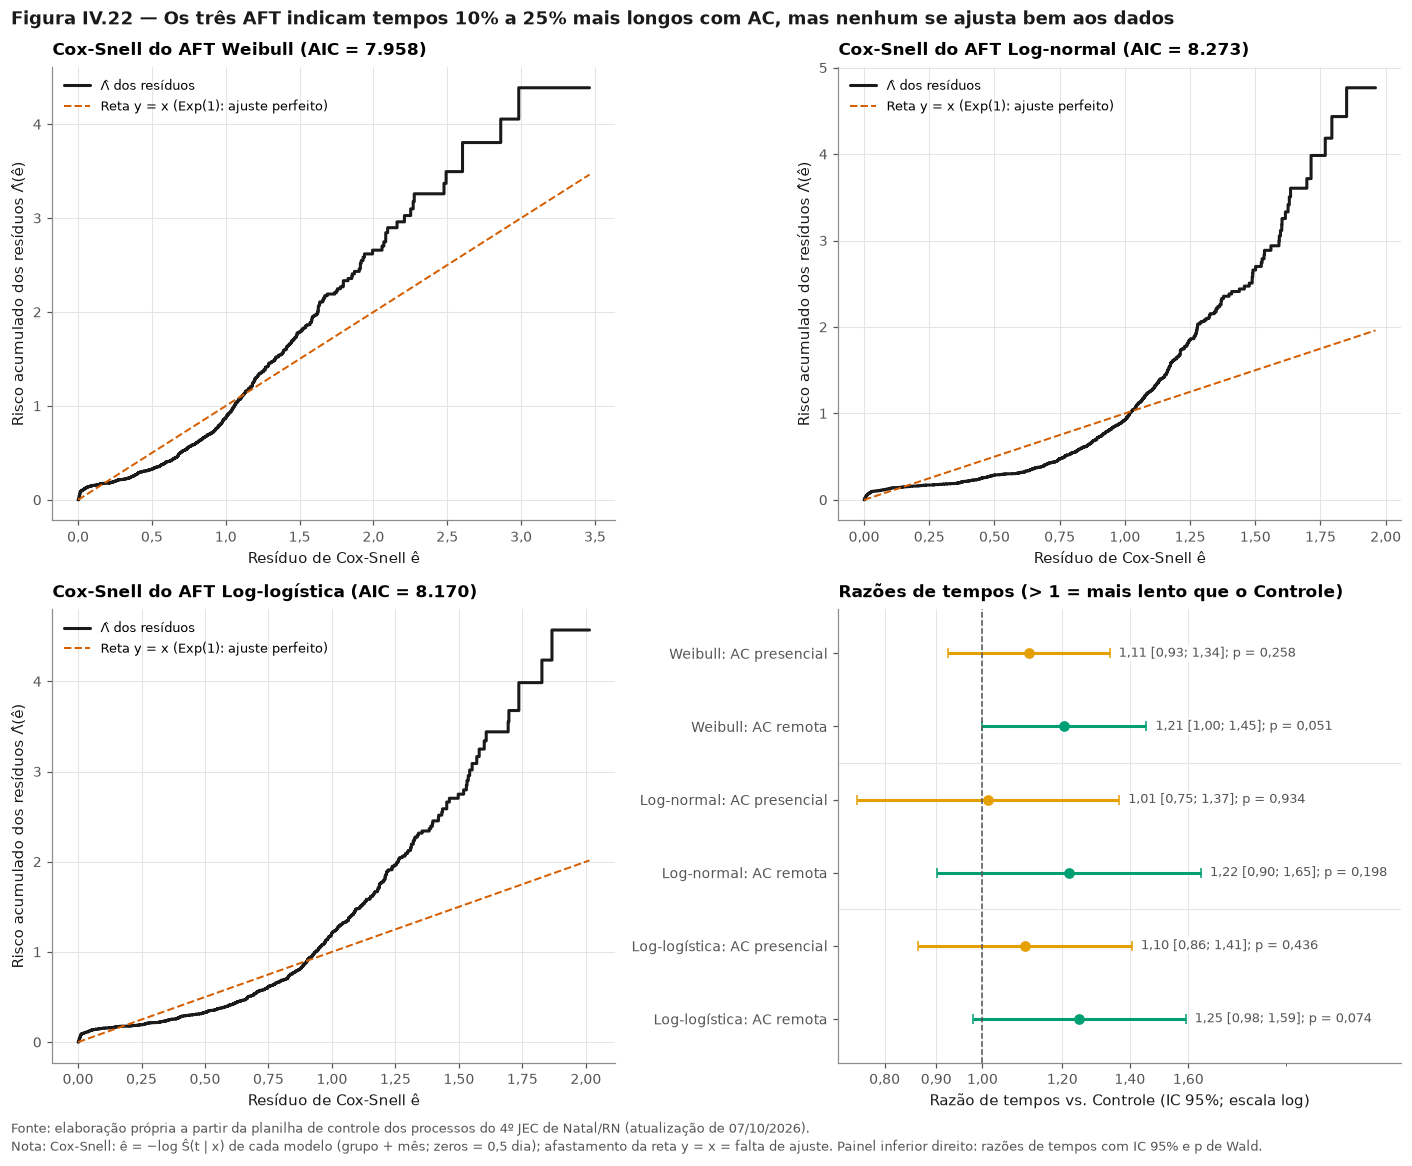

In [56]:
X_AFT = X_BASE + COLS_MES
base_aft = sob[['T_pos', 'E'] + X_AFT]
AFTS = {'Weibull': WeibullAFTFitter(), 'Log-normal': LogNormalAFTFitter(), 'Log-logística': LogLogisticAFTFitter()}
for m in AFTS.values():
    m.fit(base_aft, 'T_pos', 'E')

tr_linhas, aic = [], {}
for nome, m in AFTS.items():
    t = tabela_hr(m, X_BASE, rotulo='Razão de tempos')
    t.insert(0, 'Modelo', nome)
    tr_linhas.append(t)
    aic[nome] = {'log-verossimilhança': m.log_likelihood_, 'nº parâmetros': len(m.params_), 'AIC': m.AIC_}
aic = pd.DataFrame(aic).T
aic['ΔAIC'] = aic['AIC'] - aic['AIC'].min()
TR_AFT = pd.concat(tr_linhas)
sob_tabela(TR_AFT.rename_axis('Termo').reset_index()[['Modelo', 'Termo', 'Razão de tempos', 'IC 95% inf.', 'IC 95% sup.', 'p (Wald)']],
           'sob_aft_tr', 'Razões de tempos dos grupos com AC vs. Controle nos três modelos AFT (ajustados por mês)',
           secao='4.6', casas=3, colunas_p=('p (Wald)',),
           nota='razão de tempos > 1 = tempo até a sentença mais longo que no Controle; IC 95% e p de Wald. Destaque: p < 0,05.')
sob_tabela(aic.rename_axis('Modelo'), 'sob_aft_aic', 'Comparação dos modelos AFT pelo AIC', secao='4.6', casas=1, destaque=None,
           formatos={'nº parâmetros': 'int'}, nota='ΔAIC = AIC − menor AIC; modelos não encaixados.')
MELHOR_AFT = aic['AIC'].idxmin()

# mediana padronizada por grupo
med_aft = {}
grade_aft = np.arange(1, 400)
for nome, m in AFTS.items():
    med_aft[nome] = {}
    for g in ORDEM_GRUPO:
        x_g = sob[X_AFT].copy(); x_g['Presencial'] = int(g == 'Presencial'); x_g['Remota'] = int(g == 'Remota')
        S_pad = m.predict_survival_function(x_g, times=grade_aft).mean(axis=1)
        med_aft[nome][g] = float(S_pad.index[np.argmax(S_pad.values <= 0.5)])
med_aft = pd.DataFrame(med_aft).T
med_aft.loc['Kaplan-Meier (não paramétrico)'] = [MEDIANAS[g] for g in ORDEM_GRUPO]
_ma = med_aft.copy(); _ma.columns = [str(c) for c in _ma.columns]
tabela(_ma.rename_axis('Modelo'), 'sob_aft_medianas', 'Mediana prevista do tempo até a sentença (dias), padronizada pela '
       'distribuição dos meses, comparada à do Kaplan-Meier', secao='4.6', casas=0)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
T_u = np.unique(sob['T_pos'])
for ax, (nome, m) in zip(axes.flat[:3], AFTS.items()):
    ch = m.predict_cumulative_hazard(base_aft[X_AFT], times=T_u)       # (tempos × processos)
    pos = np.searchsorted(T_u, sob['T_pos'].values)
    ei = ch.values[pos, np.arange(len(sob))]
    cox_snell_plot(ax, ei, sob['E'].values, f'Cox-Snell do AFT {nome} (AIC = {fmt_br(m.AIC_, 0)})')
ax = axes.flat[3]
_tr = TR_AFT.copy()
_tr.index = [f'{n}: {t.replace(" × Controle", "")}' for n, t in zip(_tr['Modelo'], _tr.index)]
floresta(ax, _tr, rotulo='Razão de tempos', cor_de=lambda n: CORES_GRUPO['Presencial'] if 'presencial' in n else CORES_GRUPO['Remota'],
         xlabel='Razão de tempos vs. Controle (IC 95%; escala log)', ticks=[0.8, 0.9, 1, 1.2, 1.4, 1.6])
ax.set_xlim(0.72, 2.6)
for yi in (1.5, 3.5):
    ax.axhline(yi, color=GRADE, lw=0.8)
ax.set_title('Razões de tempos (> 1 = mais lento que o Controle)')
figura(fig, 'sob_aft', 'Os três AFT indicam tempos 10% a 25% mais longos com AC, mas nenhum se ajusta bem aos dados',
       secao='4.6', nota='Cox-Snell: ê = −log Ŝ(t | x) de cada modelo (grupo + mês; zeros = 0,5 dia); afastamento da reta y = x = '
                         'falta de ajuste. Painel inferior direito: razões de tempos com IC 95% e p de Wald.')

**Interpretação (AFT).**

- **Razões de tempos (TR > 1 = mais lento):**

  | Modelo | AC presencial × Controle | AC remota × Controle |
  |---|---|---|
  | Weibull | 1,11 (0,93–1,34; p = 0,26) | 1,21 (1,00–1,45; p = 0,051) |
  | Log-normal | 1,01 (0,75–1,37) | 1,22 (0,90–1,65; p = 0,20) |
  | Log-logística | 1,10 (0,86–1,41) | 1,25 (0,98–1,59; p = 0,074) |

  A direção é a mesma do Cox e do RMST: a AC remota **alonga o tempo em cerca de 20%**, e a presencial em cerca de 10%. O resultado da log-normal coincide com o da Parte V (TR da remota ≈ 1,2, não significativo).
- **O ajuste dos três modelos é ruim.** A Weibull tem o menor AIC (7.958, contra 8.170 da log-logística e 8.273 da log-normal), mas os gráficos de Cox-Snell se afastam claramente da reta y = x nos três modelos.
- **As medianas previstas mostram o problema.** A Weibull prevê 68, 75 e 82 dias, contra 81, 96 e 95 do KM; a log-normal, 61, 62 e 74. A razão é estrutural: a distribuição do tempo é uma **mistura** de extinções muito precoces (dezenas de processos em 0 a 10 dias; os tempos zero viram 0,5 dia) com julgamentos de mérito concentrados entre 80 e 130 dias. Nenhuma família unimodal de 2 parâmetros acomoda as duas massas.
- **Conclusão.** As razões de tempos servem como **resumo descritivo da direção e da ordem de grandeza** do efeito ("cerca de +10% a +20%"), mas os seus ICs e p-valores dependem de um modelo mal especificado. As medidas não paramétricas (KM, RMST) e semiparamétricas (Cox) são as preferíveis, e a seção 4.7 modela explicitamente os tipos de desfecho que formam a mistura.

---

## 4.7 Riscos competitivos

Até aqui, o evento foi "sentença de qualquer tipo". Mas uma sentença homologatória de acordo, um julgamento de mérito e uma extinção sem resolução do mérito são **resultados jurídicos muito diferentes**, produzidos por mecanismos diferentes. Se a AC obrigatória acelera certos desfechos e atrasa outros, a comparação do tempo total pode esconder **mecanismos opostos**. A ferramenta adequada é a de **riscos competitivos**: cada processo termina por exatamente uma de várias causas, e a ocorrência de uma impede as demais (PUTTER; FIOCCO; GESKUS, 2007; AUSTIN; LEE; FINE, 2016). Os livros-texto da disciplina não tratam do tema (COLOSIMO; GIOLO, 2006 cobrem censura, truncamento e fragilidade, mas não a incidência acumulada).

**Duas quantidades, duas perguntas.**

1. **Risco causa-específico** h_k(t): taxa instantânea de desfechos do tipo k entre os processos **ainda pendentes**. Estimado pelo Cox causa-específico (as outras causas são censuradas). Pergunta **etiológica**: "o rito acelera a ocorrência de acordos entre os processos em curso?".
2. **Função de incidência acumulada (FIA)** F_k(t) = P(T ≤ t, causa = k): proporção de **todos** os processos que terminou pela causa k até t. Estimada por **Aalen-Johansen** (AALEN; JOHANSEN, 1978): F̂_k(t) = Σ_{t_j ≤ t} Ŝ(t_{j−1}) d_kj/n_j, em que Ŝ é o KM de "qualquer desfecho". As FIA somadas mais Ŝ(t) dão 1. A regressão correspondente é a de **Fine e Gray** (1999). Pergunta **prognóstica/gestão**: "que fração dos processos do rito X termina em acordo até 90 dias?".

**Por que não usar 1 − KM censurando as outras causas.** O 1 − KM de uma causa trata quem saiu por outra causa como se ainda pudesse sofrer aquela causa no futuro: estima uma probabilidade num mundo hipotético sem os demais desfechos e, por isso, **superestima** a incidência real.

### 4.7.1 Redistribuição como risco competitivo da sentença

Primeiro, o caso simples com duas causas: **sentença** (708) e **redistribuição** (24). Compara-se a FIA de sentença (Aalen-Johansen, redistribuição como competidora) com o 1 − KM da análise principal (redistribuição censurada). A diferença entre as duas curvas é o **viés de censurar a redistribuição**.

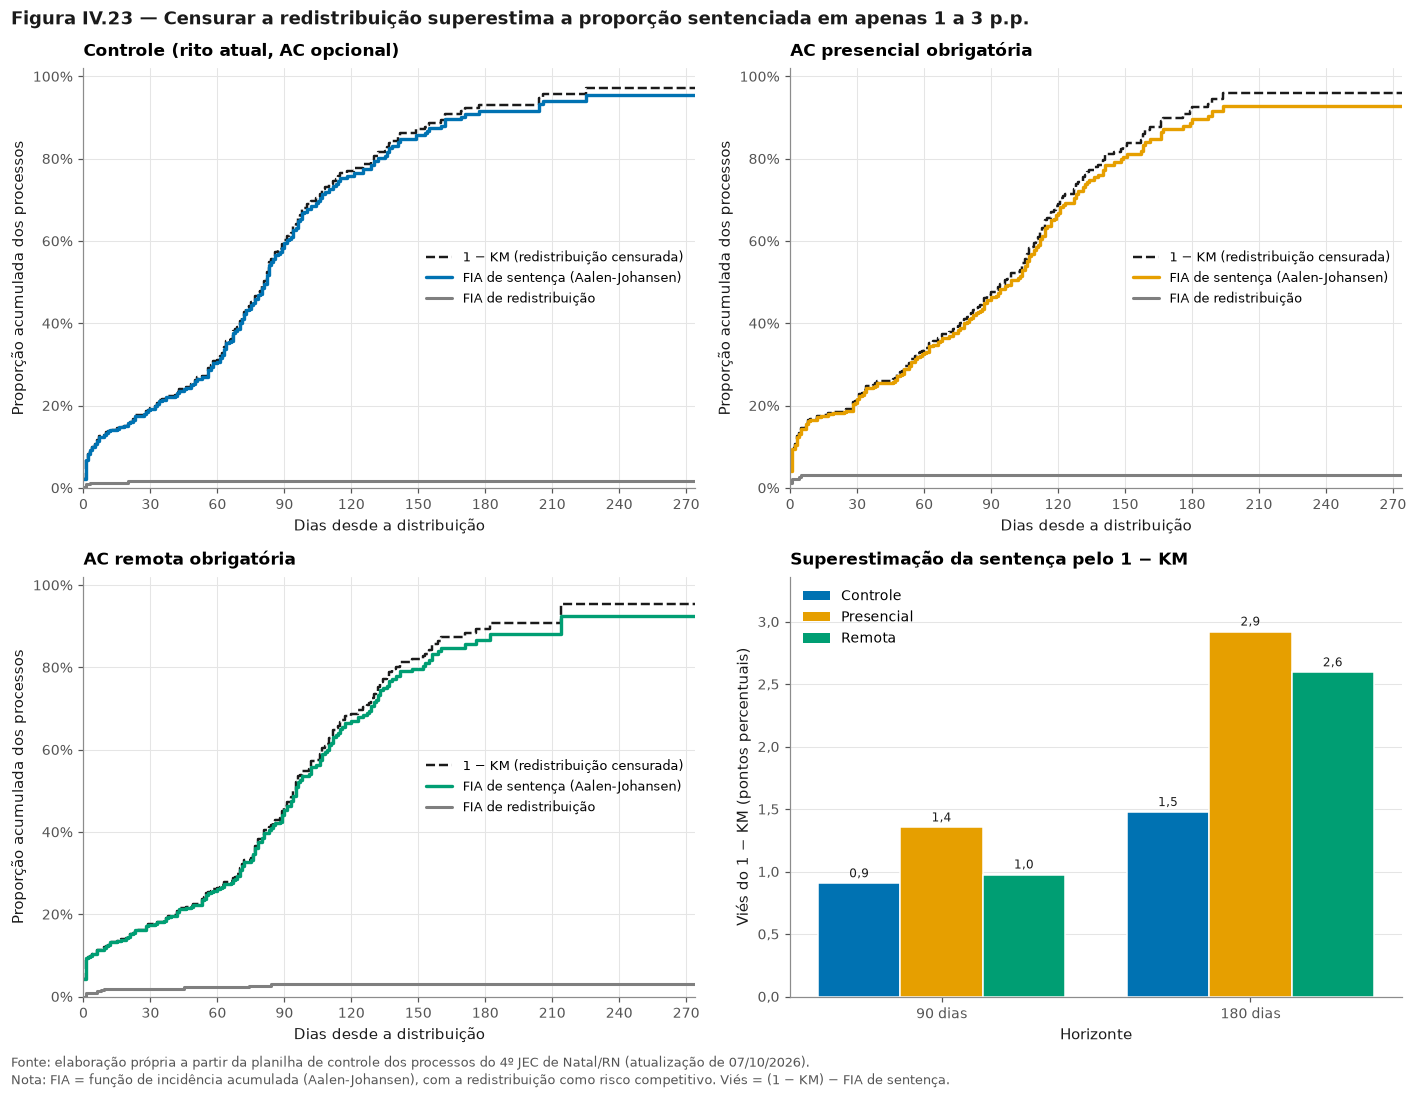

Grupo,t (dias),1 − KM,FIA sentença (AJ),FIA redistribuição,Viés (p.p.)
Controle,90,"60,4%","59,5%","1,6%","0,91"
Controle,180,"93,1%","91,6%","1,6%","1,48"
Presencial,90,"47,7%","46,3%","3,2%","1,35"
Presencial,180,"92,5%","89,5%","3,2%","2,92"
Remota,90,"46,3%","45,4%","3,0%","0,98"
Remota,180,"89,3%","86,7%","3,0%","2,60"


In [57]:
def cif_statsmodels(T, K):
    """FIA de Aalen-Johansen com EP (statsmodels, sem jitter). Retorna dict causa -> DataFrame(t, F, inf, sup)."""
    ci = CumIncidenceRight(np.asarray(T, float), np.asarray(K, int))
    out = {}
    for j, k in enumerate(sorted(set(np.asarray(K, int)) - {0})):
        F = ci.cinc[j]; se = ci.cinc_se[j]
        out[k] = pd.DataFrame({'t': ci.times, 'F': F, 'inf': np.clip(F - 1.96 * se, 0, 1), 'sup': np.clip(F + 1.96 * se, 0, 1)})
    return out

def F_em(df_cif, t):
    d = df_cif[df_cif.t <= t]
    return d.iloc[-1] if len(d) else pd.Series({'t': t, 'F': 0.0, 'inf': 0.0, 'sup': 0.0})

fig, axes = plt.subplots(2, 2, figsize=(13, 9.4))
vies = []
for ax, g in zip(axes.flat[:3], ORDEM_GRUPO):
    s = sob[sob.grupo == g]
    S_g, cif_g = aj_grade(s['T'], s['CR'], causas=(1, 2))
    Skm, _ = aj_grade(s['T'], s['E'])
    tg = np.arange(0, 275)
    ax.step(tg, 1 - Skm[tg], where='post', color=TINTA, ls='--', lw=1.6, label='1 − KM (redistribuição censurada)')
    ax.step(tg, cif_g[1][tg], where='post', color=CORES_GRUPO[g], lw=2.2, label='FIA de sentença (Aalen-Johansen)')
    ax.step(tg, cif_g[2][tg], where='post', color=CORES_DESFECHO['Redistribuição'], lw=2, label='FIA de redistribuição')
    ax.set_title(ROTULO_GRUPO[g]); ax.set_xlabel(ROTULOS['dias']); ax.set_xlim(0, 274); ax.set_xticks(np.arange(0, 271, 30))
    ax.set_ylim(0, 1.02); eixo_pct(ax); ax.set_ylabel('Proporção acumulada dos processos')
    ax.grid(axis='both', visible=True)
    ax.legend(fontsize=8.5, loc='center right')
    for t in [90, 180]:
        vies.append({'Grupo': g, 't (dias)': t, '1 − KM': 1 - Skm[t], 'FIA sentença (AJ)': cif_g[1][t],
                     'FIA redistribuição': cif_g[2][t], 'Viés (p.p.)': 100 * ((1 - Skm[t]) - cif_g[1][t])})
VIES_CR = pd.DataFrame(vies)
ax = axes.flat[3]
_vb = VIES_CR.pivot(index='t (dias)', columns='Grupo', values='Viés (p.p.)')[ORDEM_GRUPO]
_vb.index = [f'{t} dias' for t in _vb.index]
barras_agrupadas(ax, _vb, cores=CORES_GRUPO, rotular=True, fmt=lambda v: fmt_br(v, 1), legenda=False,
                 ylabel='Viés do 1 − KM (pontos percentuais)', xlabel='Horizonte')
ax.set_title('Superestimação da sentença pelo 1 − KM')
ax.legend(handles=[Patch(color=CORES_GRUPO[g], label=g) for g in ORDEM_GRUPO], loc='upper left')
figura(fig, 'sob_cr_redistribuicao', 'Censurar a redistribuição superestima a proporção sentenciada em apenas 1 a 3 p.p.',
       secao='4.7.1', nota='FIA = função de incidência acumulada (Aalen-Johansen), com a redistribuição como risco competitivo. '
                           'Viés = (1 − KM) − FIA de sentença.')
sob_tabela(VIES_CR, 'sob_cr_vies', 'Proporção sentenciada aos 90 e 180 dias: 1 − KM × FIA de Aalen-Johansen', secao='4.7.1',
           casas=3, destaque=None, formatos={'t (dias)': 'int', '1 − KM': 'pct', 'FIA sentença (AJ)': 'pct',
                                             'FIA redistribuição': 'pct', 'Viés (p.p.)': 2})

### 4.7.2 O tipo de sentença como desfecho competitivo: FIA por grupo

Agora a análise substantiva principal: quatro causas de saída — **homologação de acordo** (1), **julgamento de mérito** (2), **extinção sem mérito** (3) e **redistribuição** (4) —, mais a censura administrativa. A figura empilhada mostra, para cada grupo, como a massa de processos se distribui ao longo do tempo: a faixa de cada cor é a FIA da causa, e o que sobra no topo (cinza) é Ŝ(t), a proporção ainda pendente. A segunda figura sobrepõe os três grupos em cada causa, com IC 95% (erro-padrão do `statsmodels.CumIncidenceRight`, sem o *jitter* que o `AalenJohansenFitter` do `lifelines` introduz nos empates).

**Hipótese a investigar** (seção 3 e E21): a AC obrigatória **acelera** as extinções sem mérito — a ausência do autor à audiência de conciliação extingue o processo (art. 51, I, da Lei 9.099/1995) — e os acordos, mas **atrasa** os julgamentos de mérito, que passam a esperar a audiência antes da contestação e da conclusão para sentença. Se for assim, a comparação do tempo total mistura um efeito que encurta com outro que alonga.

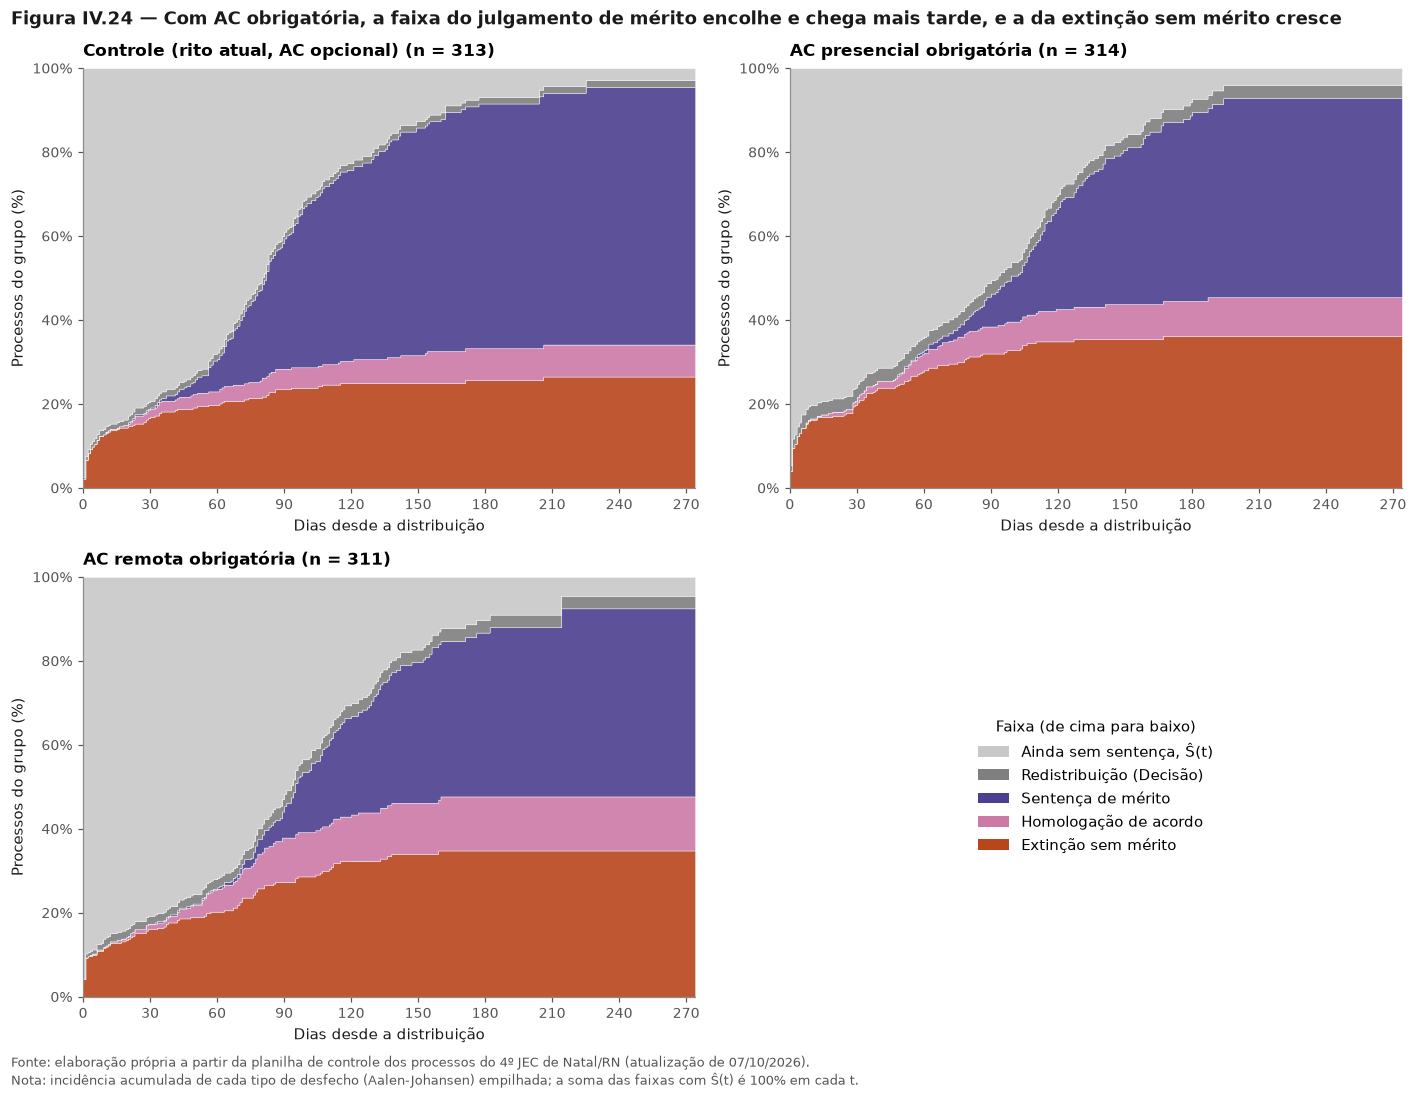

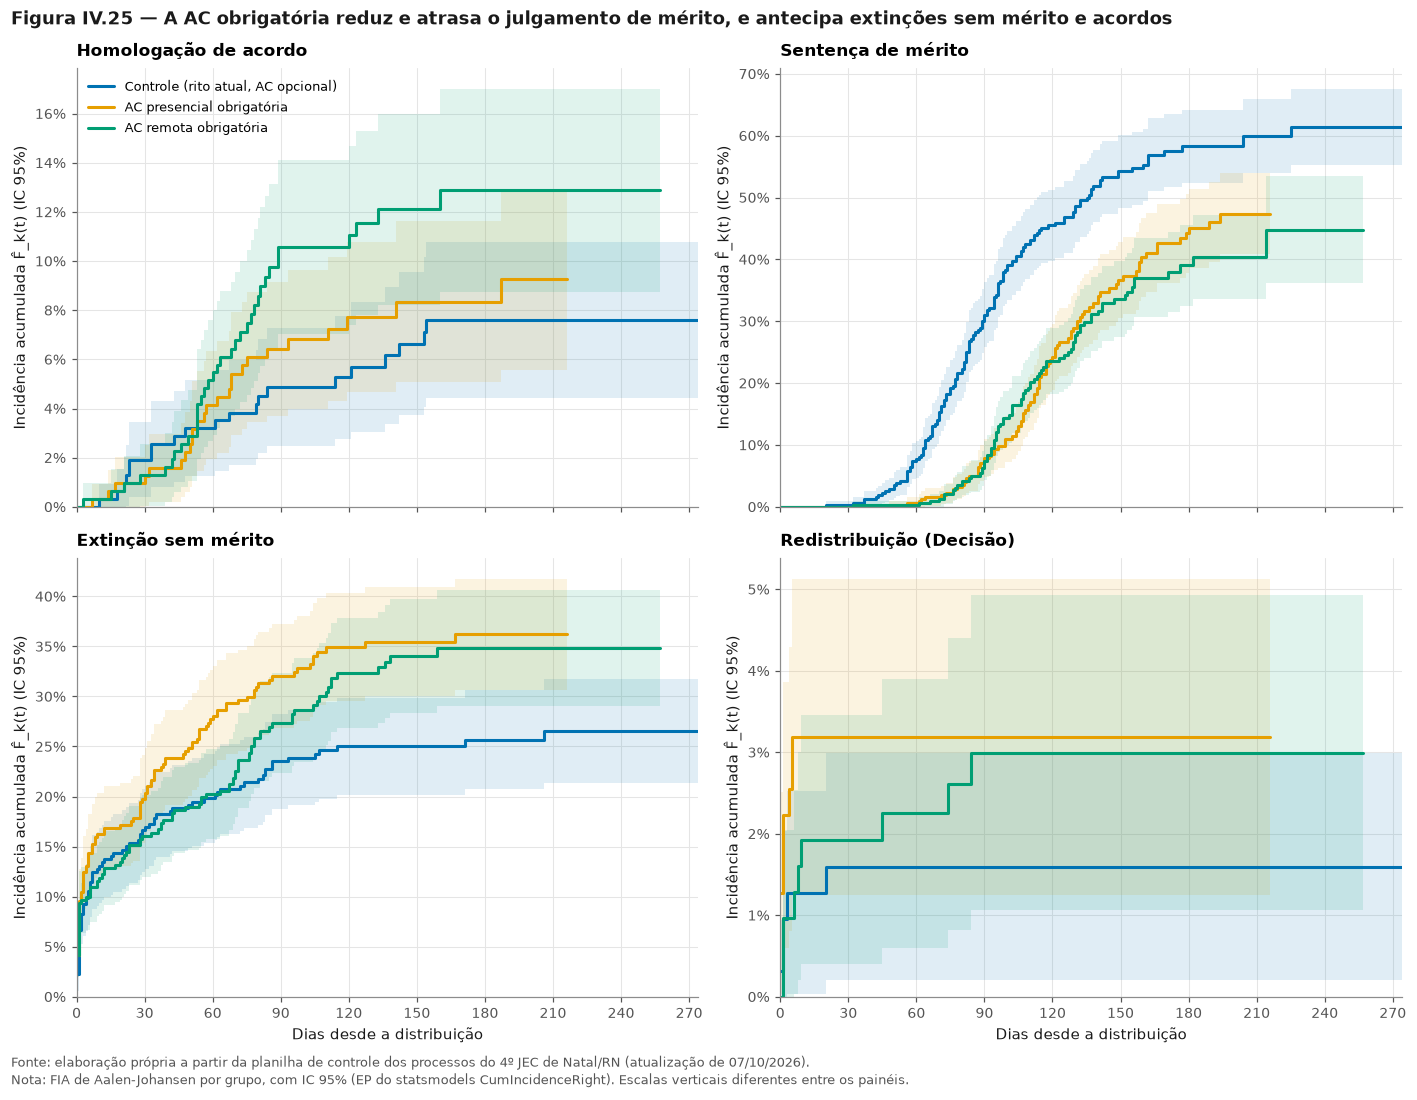

Desfecho,t (dias),Controle,Presencial,Remota
Homologação,30,"1,9% (0,4%–3,4%)","1,3% (0,0%–2,5%)","1,3% (0,0%–2,5%)"
Homologação,60,"3,2% (1,2%–5,1%)","4,1% (1,9%–6,3%)","5,5% (2,9%–8,0%)"
Homologação,90,"4,9% (2,5%–7,3%)","6,4% (3,7%–9,2%)","10,6% (7,0%–14,1%)"
Homologação,120,"5,3% (2,7%–7,8%)","7,7% (4,7%–10,8%)","11,1% (7,4%–14,7%)"
Homologação,180,"7,6% (4,4%–10,8%)","8,4% (5,1%–11,6%)","12,9% (8,8%–17,0%)"
Mérito,30,"0,3% (0,0%–0,9%)","0,0% (0,0%–0,0%)","0,0% (0,0%–0,0%)"
Mérito,60,"7,7% (4,7%–10,6%)","0,6% (0,0%–1,5%)","0,3% (0,0%–1,0%)"
Mérito,90,"31,1% (25,8%–36,3%)","7,8% (4,8%–10,9%)","7,5% (4,3%–10,6%)"
Mérito,120,"45,5% (39,8%–51,2%)","24,2% (19,0%–29,5%)","23,5% (18,2%–28,9%)"
Mérito,180,"58,3% (52,3%–64,2%)","45,0% (38,6%–51,4%)","39,0% (32,4%–45,6%)"


In [58]:
CAUSAS_SENT = (1, 2, 3, 4)
cif_sm = {g: cif_statsmodels(sob.loc[sob.grupo == g, 'T'], sob.loc[sob.grupo == g, 'K']) for g in ORDEM_GRUPO}
tg = np.arange(0, 275)
ORDEM_PILHA = [3, 1, 2, 4]         # sem mérito (precoce), homologação, mérito, redistribuição
fig, axes = plt.subplots(2, 2, figsize=(13, 9.4))
for ax, g in zip(axes.flat[:3], ORDEM_GRUPO):
    s = sob[sob.grupo == g]
    S_g, cif_g = aj_grade(s['T'], s['K'], causas=CAUSAS_SENT)
    camadas = [cif_g[k][tg] for k in ORDEM_PILHA] + [S_g[tg]]
    ax.stackplot(tg, *camadas, step='post', colors=[CORES_DESFECHO[CAUSAS[k]] for k in ORDEM_PILHA] + [CORES_DESFECHO['Ativo']],
                 alpha=0.9, edgecolor='white', lw=0.3)
    ax.set_title(f'{ROTULO_GRUPO[g]} (n = {len(s)})'); ax.set_xlabel(ROTULOS['dias']); ax.set_xlim(0, 274); ax.set_ylim(0, 1)
    ax.set_xticks(np.arange(0, 271, 30)); eixo_pct(ax); ax.set_ylabel('Processos do grupo (%)')
    ax.grid(visible=False)
axes.flat[3].axis('off')
axes.flat[3].legend(handles=[Patch(color=CORES_DESFECHO['Ativo'], label='Ainda sem sentença, Ŝ(t)')] +
                    [Patch(color=CORES_DESFECHO[CAUSAS[k]], label=ROTULO_DESFECHO[CAUSAS[k]]) for k in ORDEM_PILHA[::-1]],
                    loc='center', title='Faixa (de cima para baixo)', fontsize=10, title_fontsize=10)
figura(fig, 'sob_cif_empilhada', 'Com AC obrigatória, a faixa do julgamento de mérito encolhe e chega mais tarde, e a da extinção '
       'sem mérito cresce', secao='4.7.2', nota='incidência acumulada de cada tipo de desfecho (Aalen-Johansen) empilhada; '
                                                'a soma das faixas com Ŝ(t) é 100% em cada t.')

fig, axes = plt.subplots(2, 2, figsize=(13, 9.4), sharex=True)
for ax, k in zip(axes.flat, CAUSAS_SENT):
    for g in ORDEM_GRUPO:
        d = cif_sm[g][k]
        ax.step(d.t, d.F, where='post', color=CORES_GRUPO[g], lw=2, label=ROTULO_GRUPO[g])
        ax.fill_between(d.t, d['inf'], d['sup'], step='post', color=CORES_GRUPO[g], alpha=0.12, lw=0)
    ax.set_title(f'{ROTULO_DESFECHO[CAUSAS[k]]}'); ax.set_xlim(0, 274); ax.set_xticks(np.arange(0, 271, 30))
    ax.set_ylim(0, None); eixo_pct(ax); ax.grid(axis='both', visible=True)
    ax.set_ylabel('Incidência acumulada F̂_k(t) (IC 95%)')
for ax in axes[1]:
    ax.set_xlabel(ROTULOS['dias'])
axes[0, 0].legend(loc='upper left', fontsize=8.5)
figura(fig, 'sob_cif_causas', 'A AC obrigatória reduz e atrasa o julgamento de mérito, e antecipa extinções sem mérito e acordos',
       secao='4.7.2', nota='FIA de Aalen-Johansen por grupo, com IC 95% (EP do statsmodels CumIncidenceRight). Escalas verticais '
                           'diferentes entre os painéis.')

linhas = []
for k in CAUSAS_SENT:
    for t in [30, 60, 90, 120, 180]:
        linha = {'Desfecho': CAUSAS[k], 't (dias)': t}
        for g in ORDEM_GRUPO:
            r = F_em(cif_sm[g][k], t)
            linha[g] = f"{pct_br(r['F'])} ({pct_br(r['inf'])}–{pct_br(r['sup'])})"
        linhas.append(linha)
CIF_TAB = pd.DataFrame(linhas).set_index(['Desfecho', 't (dias)'])
tabela(CIF_TAB.reset_index(), 'sob_cif_tabela', 'Incidência acumulada de cada tipo de desfecho por grupo, F̂_k(t) (IC 95%)',
       secao='4.7.2', formatos={'t (dias)': 'int', **{g: 'texto' for g in ORDEM_GRUPO}},
       nota='Aalen-Johansen (statsmodels CumIncidenceRight); IC 95% pela aproximação normal, truncado em [0, 1].')

### 4.7.3 Teste de igualdade das FIA entre grupos (tipo Gray, por permutação)

O teste de Gray (1988) compara as FIA de uma causa entre k grupos. Ele não existe no `lifelines` nem no `statsmodels` (e os pacotes `pycmprsk`/`pycrr` não estão instalados). Implementa-se um **teste de permutação** com a mesma hipótese nula:

- H₀: F_k,Controle(t) = F_k,Presencial(t) = F_k,Remota(t) para todo t ≤ τ;
- estatística: D_k = Σ_g n_g ∫₀^τ [F̂_k,g(t) − F̂_k(t)]² dt, a distância quadrática integrada entre a FIA de cada grupo e a FIA combinada, com τ = 180 dias;
- distribuição sob H₀: 2.000 permutações dos rótulos de grupo **dentro de cada mês de distribuição**. A permutação estratificada respeita o desenho (o sorteio foi feito ao longo do calendário) e preserva a estrutura de censura de cada mês, que é o que torna a censura comparável entre os rótulos permutados. Sob H₀ de nenhum efeito do rito, os rótulos são permutáveis dentro do mês: o p-valor é exato (a menos do erro de Monte Carlo).

São 4 testes (um por causa), corrigidos por Holm. **Gráfico do teste:** distribuição de permutação de D_k com o valor observado.

Desfecho,D observado,p (permutação),"p (Holm, 4 testes)"
Homologação,"53,33","0,055","0,110"
Mérito,"1.007,95","< 0,001","0,002"
Sem mérito,"228,64","0,020","0,061"
Redistribuição,"8,30","0,359","0,359"


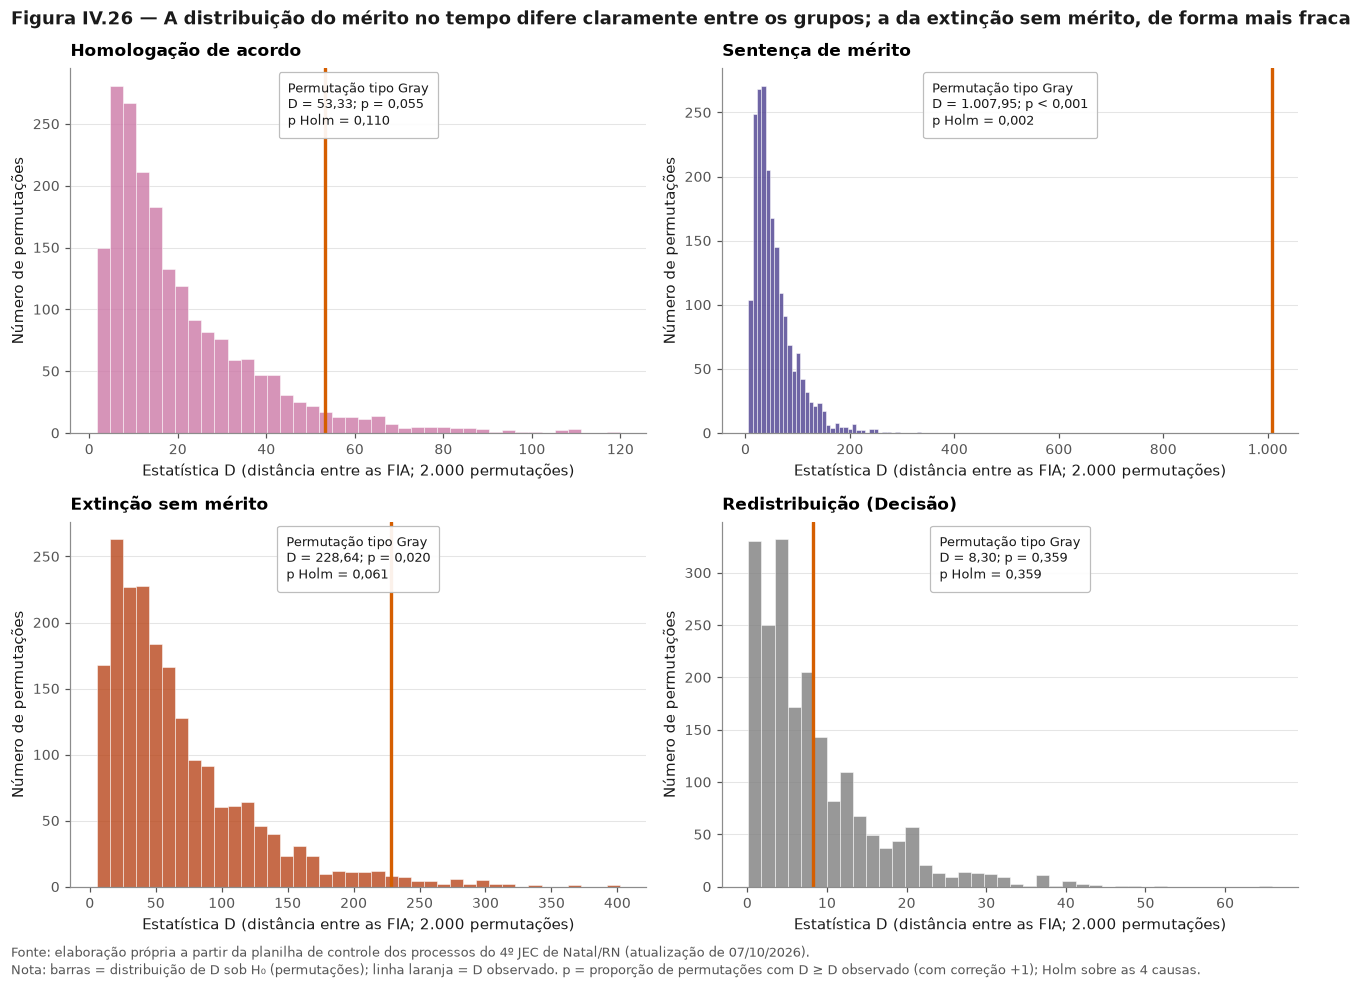

In [59]:
def estat_gray_perm(T, K, G, k, tau=180, grupos=(0, 1, 2)):
    _, cif_all = aj_grade(T, K, causas=CAUSAS_SENT)
    Fbar = cif_all[k][:tau]
    D = 0.0
    for g in grupos:
        m = G == g
        _, cg = aj_grade(T[m], K[m], causas=CAUSAS_SENT)
        D += m.sum() * np.sum((cg[k][:tau] - Fbar) ** 2)
    return D

B_PERM = 2000
rng_perm = np.random.default_rng(SEMENTE + 47)
T_i, K_i, G_i, M_i = sob['T'].values.astype(int), sob['K'].values.astype(int), sob['grupo'].cat.codes.values, sob['mes_cod'].values
obs_D = {k: estat_gray_perm(T_i, K_i, G_i, k) for k in CAUSAS_SENT}
perm_D = {k: np.empty(B_PERM) for k in CAUSAS_SENT}
idx_mes = [np.where(M_i == m)[0] for m in np.unique(M_i)]
for b in range(B_PERM):
    Gp = G_i.copy()
    for ii in idx_mes:
        Gp[ii] = rng_perm.permutation(G_i[ii])
    for k in CAUSAS_SENT:
        perm_D[k][b] = estat_gray_perm(T_i, K_i, Gp, k)
gray = pd.DataFrame({'Desfecho': [CAUSAS[k] for k in CAUSAS_SENT],
                     'D observado': [obs_D[k] for k in CAUSAS_SENT],
                     'p (permutação)': [(1 + (perm_D[k] >= obs_D[k]).sum()) / (B_PERM + 1) for k in CAUSAS_SENT]}).set_index('Desfecho')
gray['p (Holm, 4 testes)'] = multipletests(gray['p (permutação)'], method='holm')[1]
sob_tabela(gray, 'sob_gray_permutacao', 'Teste de igualdade das FIA entre os três grupos (tipo Gray, por permutação no mês)',
           secao='4.7.3', casas=2, colunas_p=('p (permutação)', 'p (Holm, 4 testes)'),
           nota=f'D = Σ_g n_g ∫₀^180 [F̂_k,g(t) − F̂_k(t)]² dt; {fmt_br(B_PERM, 0)} permutações dos rótulos de grupo dentro do mês. '
                'Destaque: p de Holm < 0,05.')

fig, axes = plt.subplots(2, 2, figsize=(12, 8.4))
for ax, k in zip(axes.flat, CAUSAS_SENT):
    ax.hist(perm_D[k], bins=40, color=CORES_DESFECHO[CAUSAS[k]], alpha=0.8, edgecolor='white', lw=0.4)
    ax.axvline(obs_D[k], color=DESTAQUE, lw=2.2)
    ax.set_title(ROTULO_DESFECHO[CAUSAS[k]])
    ax.set_xlabel(f'Estatística D (distância entre as FIA; {fmt_br(B_PERM, 0)} permutações)')
    ax.set_ylabel('Número de permutações')
    ax.grid(axis='x', visible=False)
    r = gray.loc[CAUSAS[k]]
    lado = 'upper right' if obs_D[k] < np.percentile(perm_D[k], 60) else 'upper center'
    anotar_teste(ax, texto_teste('Permutação tipo Gray', f'D = {fmt_br(r["D observado"], 2)}', r['p (permutação)'],
                                 f'p Holm = {fmt_p(r["p (Holm, 4 testes)"])}'), loc=lado)
figura(fig, 'sob_gray_permutacao', 'A distribuição do mérito no tempo difere claramente entre os grupos; a da extinção sem mérito, '
       'de forma mais fraca', secao='4.7.3', nota='barras = distribuição de D sob H₀ (permutações); linha laranja = D observado. p = proporção de permutações '
                                     'com D ≥ D observado (com correção +1); Holm sobre as 4 causas.')

### 4.7.4 Cox causa-específico por tipo de desfecho

Para cada causa k, ajusta-se um Cox (grupo + mês, Efron) em que o evento é "desfecho do tipo k" e os desfechos de outros tipos são **censurados** no seu tempo. O HR causa-específico responde: entre os processos ainda pendentes no dia t, quanto maior (HR > 1) ou menor (HR < 1) é a taxa diária de desfechos do tipo k no grupo com AC em relação ao Controle? Censurar as outras causas é correto para o risco causa-específico (não para a FIA): o risco causa-específico é definido justamente entre os que ainda estão em risco de todas as causas.

In [60]:
X_CS = X_BASE + COLS_MES
cs_tabs, cs_modelos = [], {}
for k in CAUSAS_SENT:
    base_k = sob[['T'] + X_CS].assign(Ek=(sob['K'] == k).astype(int))
    m = CoxPHFitter().fit(base_k, 'T', 'Ek')
    cs_modelos[k] = m
    t = tabela_hr(m, X_BASE); t.insert(0, 'Desfecho', CAUSAS[k]); t.insert(1, 'eventos', int(base_k['Ek'].sum()))
    cs_tabs.append(t)
HR_CS = pd.concat(cs_tabs)
sob_tabela(HR_CS.rename_axis('Termo').reset_index()[['Desfecho', 'eventos', 'Termo', 'HR', 'IC 95% inf.', 'IC 95% sup.', 'p (Wald)']]
           .rename(columns={'eventos': 'Eventos'}), 'sob_cox_causa_especifica',
           'Cox causa-específico por tipo de desfecho: razão de risco dos grupos com AC vs. Controle (ajustado por mês)',
           secao='4.7.4', casas=3, colunas_p=('p (Wald)',), formatos={'Eventos': 'int'},
           nota='desfechos de outros tipos censurados no seu tempo; HR > 1 = desfecho mais frequente por dia entre os pendentes. '
                'Destaque: p < 0,05.')

Desfecho,Eventos,Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
Homologação,81,AC presencial × Controle,"1,235","0,7","2,2","0,478"
Homologação,81,AC remota × Controle,"1,710","1,0","2,9","0,053"
Mérito,341,AC presencial × Controle,"0,547","0,4","0,7","< 0,001"
Mérito,341,AC remota × Controle,"0,474","0,4","0,6","< 0,001"
Sem mérito,286,AC presencial × Controle,"1,400","1,0","1,9","0,023"
Sem mérito,286,AC remota × Controle,"1,259","0,9","1,7","0,130"
Redistribuição,24,AC presencial × Controle,"2,157","0,7","6,3","0,161"
Redistribuição,24,AC remota × Controle,"1,889","0,6","5,7","0,256"


### 4.7.5 Modelo de Fine-Gray (subdistribuição) implementado à mão

O modelo de **Fine e Gray (1999)** modela diretamente a FIA: o risco da **subdistribuição** λ̄_k(t) = −d log[1 − F_k(t)]/dt segue um modelo de riscos proporcionais, λ̄_k(t | x) = λ̄_k0(t) exp(x′γ). O exp(γ) (sHR) > 1 indica **maior incidência acumulada** da causa k (mais processos terminando por k até cada t). A diferença em relação ao Cox causa-específico está no **conjunto de risco**: no Fine-Gray, quem saiu por **outra causa** continua no conjunto de risco da causa k (com peso), porque não pode mais ter a causa k "a tempo".

O modelo não está no `lifelines` nem no `statsmodels`. Duas implementações equivalentes:

1. **Censura completamente conhecida** (FINE; GRAY, 1999, seção 3). Aqui toda censura é administrativa, e o tempo potencial de censura de **todos** os processos é conhecido (C_i = `followup` = 07/10/2026 − distribuição). Nesse caso, o estimador de Fine-Gray é exato e simples: quem teve desfecho competitivo permanece no conjunto de risco **até o seu C_i**, com peso 1. Basta um Cox com o tempo do competidor substituído por C_i e o evento k = 0. Erros-padrão robustos (sanduíche), como recomendam os autores.
2. **Ponderação IPCW** (GESKUS, 2011), a forma geral usada pelo `survival::finegray()` do R. Quem tem desfecho competitivo em T_i é mantido em risco depois de T_i em episódios (início, fim] entre os tempos de censura observados, com peso w_i(t) = Ĝ(t)/Ĝ(T_i), sendo Ĝ o KM da distribuição de censura (censura como "evento"). Cox ponderado em formato de contagem, com variância robusta agrupada por processo (`cluster_col`).

As duas devem dar resultados muito próximos; a versão 2 é aplicada, como conferência, aos dois desfechos centrais (mérito e sem mérito), porque o ajuste ponderado com variância agrupada sobre ~30 mil episódios é lento. A versão 1 é a principal, porque usa a informação exata do desenho. Covariáveis: grupo + mês (como no Cox causa-específico).

In [61]:
def fine_gray_censura_conhecida(df, k, X):
    """Fine-Gray com tempos potenciais de censura conhecidos (followup)."""
    b = df[['T', 'K', 'FU'] + X].copy()
    compet = (b['K'] != k) & (b['K'] != 0)
    b['T_fg'] = np.where(compet, b['FU'], b['T'])
    b['E_fg'] = (b['K'] == k).astype(int)
    return CoxPHFitter().fit(b[['T_fg', 'E_fg'] + X], 'T_fg', 'E_fg', robust=True)


def fine_gray_ipcw(df, k, X):
    """Fine-Gray por IPCW (Geskus, 2011), como survival::finegray. Tempos deslocados +1 dia (start < stop)."""
    b = df[['T', 'K'] + X].copy().reset_index(drop=True)
    b['id'] = np.arange(len(b))
    T1 = b['T'].values + 1.0
    kmG = KaplanMeierFitter().fit(T1, (b['K'] == 0).astype(int))     # censura como "evento"
    G = kmG.survival_function_.iloc[:, 0]
    G_t, G_v = G.index.values, G.values
    G_em = lambda t: G_v[np.searchsorted(G_t, t, side='right') - 1]
    cortes = np.unique(T1[b['K'] == 0])
    linhas = [pd.DataFrame({'id': b['id'], 'start': 0.0, 'stop': T1, 'ev': (b['K'] == k).astype(int).values, 'w': 1.0})]
    comp = b.index[(b['K'] != k) & (b['K'] != 0)]
    ext = []
    for i in comp:
        Ti = T1[i]; Gi = G_em(Ti)
        cs = cortes[cortes > Ti]
        inicios = np.concatenate([[Ti], cs[:-1]]) if len(cs) else np.array([])
        for a_, b_ in zip(inicios, cs):
            ext.append((i, a_, b_, 0, G_em(a_) / Gi))
    linhas.append(pd.DataFrame(ext, columns=['id', 'start', 'stop', 'ev', 'w']))
    long = pd.concat(linhas, ignore_index=True).merge(b[['id'] + X], on='id')
    long = long[long['w'] > 0]
    m = CoxPHFitter().fit(long[['start', 'stop', 'ev', 'w', 'id'] + X], 'stop', 'ev', entry_col='start',
                          weights_col='w', cluster_col='id', robust=True)
    return m, len(long)


fg_tabs, FG_MODELOS = [], {}
for k in CAUSAS_SENT:
    m1 = fine_gray_censura_conhecida(sob, k, X_CS)
    FG_MODELOS[k] = m1
    versoes = [('censura conhecida', m1)]
    if k in (2, 3):          # conferência IPCW só para os dois desfechos centrais (cada ajuste leva ~1–2 min)
        m2, n_long = fine_gray_ipcw(sob, k, X_CS)
        versoes.append((f'IPCW ({n_long:,} episódios)'.replace(',', '.'), m2))
    for nome, m in versoes:
        t = tabela_hr(m, X_BASE, rotulo='sHR'); t.insert(0, 'Desfecho', CAUSAS[k]); t.insert(1, 'Implementação', nome)
        fg_tabs.append(t)
SHR_FG = pd.concat(fg_tabs)
sob_tabela(SHR_FG.rename_axis('Termo').reset_index()[['Desfecho', 'Implementação', 'Termo', 'sHR', 'IC 95% inf.', 'IC 95% sup.', 'p (Wald)']],
           'sob_fine_gray', 'Modelo de Fine-Gray por tipo de desfecho: razão de riscos da subdistribuição (sHR) vs. Controle',
           secao='4.7.5', casas=3, colunas_p=('p (Wald)',),
           nota='sHR > 1 = maior incidência acumulada do desfecho; EP robusto (sanduíche). Ajustado por mês. Destaque: p < 0,05.')

Desfecho,Implementação,Termo,sHR,IC 95% inf.,IC 95% sup.,p (Wald)
Homologação,censura conhecida,AC presencial × Controle,"1,250","0,7","2,3","0,457"
Homologação,censura conhecida,AC remota × Controle,"1,868","1,1","3,2","0,026"
Mérito,censura conhecida,AC presencial × Controle,"0,463","0,4","0,6","< 0,001"
Mérito,censura conhecida,AC remota × Controle,"0,416","0,3","0,5","< 0,001"
Mérito,IPCW (33.989 episódios),AC presencial × Controle,"0,483","0,3","0,7","< 0,001"
Mérito,IPCW (33.989 episódios),AC remota × Controle,"0,428","0,3","0,6","< 0,001"
Sem mérito,censura conhecida,AC presencial × Controle,"1,457","1,1","2,0","0,011"
Sem mérito,censura conhecida,AC remota × Controle,"1,318","1,0","1,8","0,070"
Sem mérito,IPCW (30.497 episódios),AC presencial × Controle,"1,466","1,0","2,2","0,052"
Sem mérito,IPCW (30.497 episódios),AC remota × Controle,"1,325","0,9","2,0","0,162"


**Gráfico dos dois modelos.** Para cada tipo de desfecho, o HR causa-específico (Cox) e o sHR de Fine-Gray (censura conhecida) dos dois grupos com AC em relação ao Controle. Quando os dois apontam na mesma direção, o rito muda tanto a **velocidade** daquele desfecho entre os pendentes quanto a **fração** de processos que termina por ele.

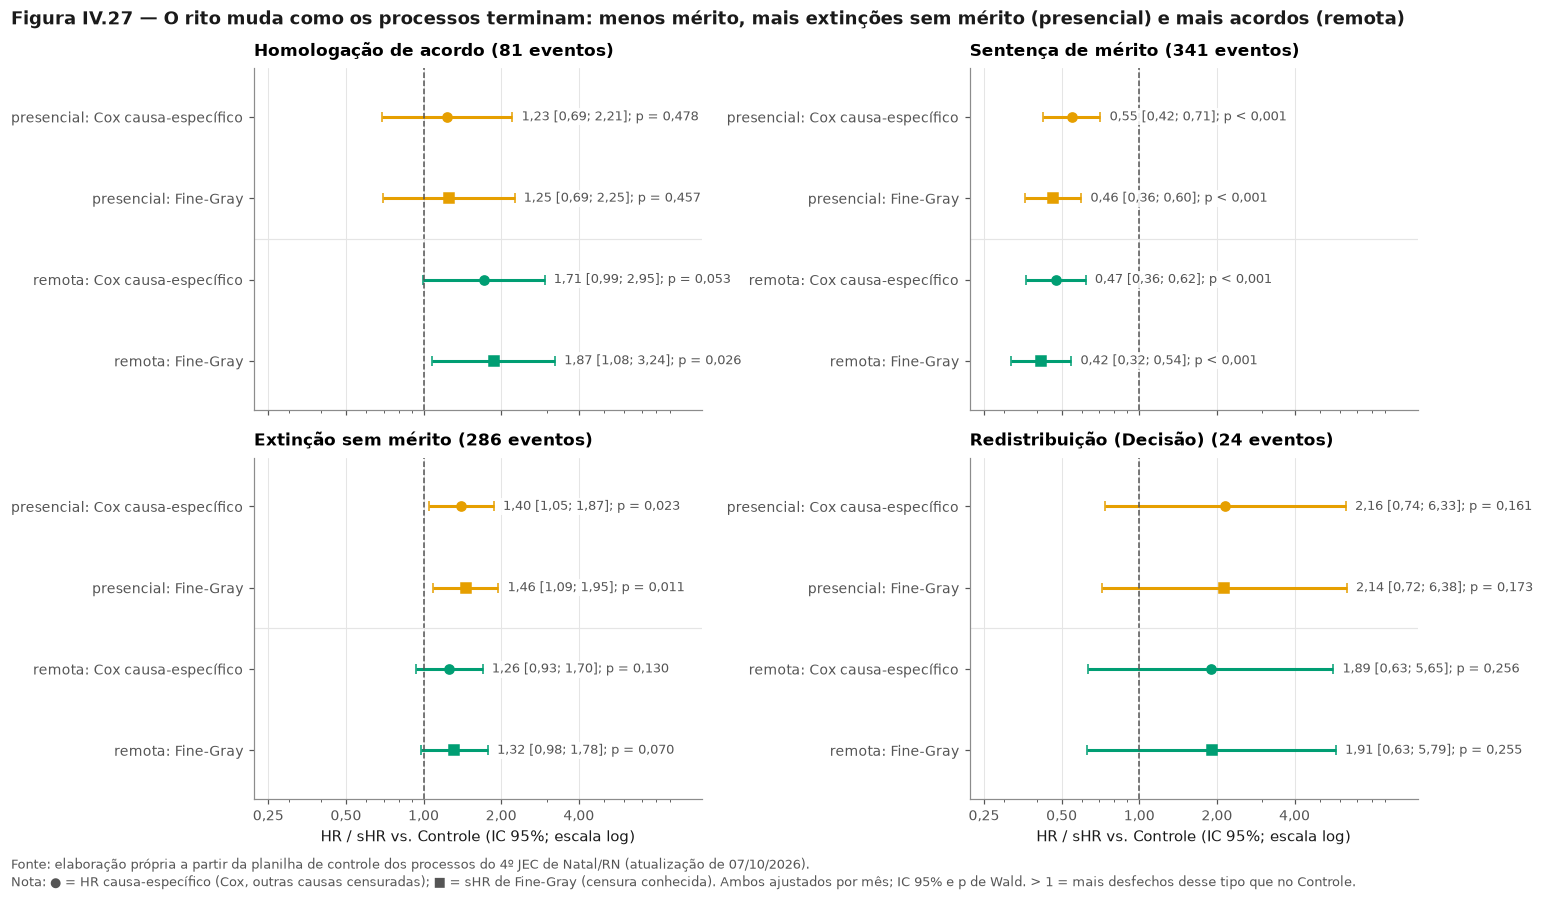

In [62]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.6), sharex=True)
for ax, k in zip(axes.flat, CAUSAS_SENT):
    cs = HR_CS[HR_CS.Desfecho == CAUSAS[k]].rename(columns={'HR': 'v'})
    fg = SHR_FG[(SHR_FG.Desfecho == CAUSAS[k]) & (SHR_FG['Implementação'] == 'censura conhecida')].rename(columns={'sHR': 'v'})
    linhas_f, cores_f, mks_f = [], {}, {}
    for termo in cs.index:
        for tab_, nome, mk in [(cs, 'Cox causa-específico', 'o'), (fg, 'Fine-Gray', 's')]:
            rot = f"{termo.split(' ×')[0].replace('AC ', '')}: {nome}"
            linhas_f.append(tab_.loc[termo, ['v', 'IC 95% inf.', 'IC 95% sup.', 'p (Wald)']].rename(rot))
            cores_f[rot] = COR_TERMO[termo]; mks_f[rot] = mk
    floresta(ax, pd.DataFrame(linhas_f), rotulo='v', cor_de=cores_f.get, marcadores=mks_f.get,
             xlabel='HR / sHR vs. Controle (IC 95%; escala log)', ticks=[0.25, 0.5, 1, 2, 4])
    ax.axhline(1.5, color=GRADE, lw=0.8)
    ax.set_xlim(0.22, 12)
    ax.set_title(f'{ROTULO_DESFECHO[CAUSAS[k]]} ({int(cs["eventos"].iloc[0])} eventos)')
for ax in axes[0]:
    ax.set_xlabel('')
figura(fig, 'sob_cr_floresta', 'O rito muda como os processos terminam: menos mérito, mais extinções sem mérito (presencial) '
       'e mais acordos (remota)', secao='4.7.5',
       nota='● = HR causa-específico (Cox, outras causas censuradas); ■ = sHR de Fine-Gray (censura conhecida). Ambos ajustados '
            'por mês; IC 95% e p de Wald. > 1 = mais desfechos desse tipo que no Controle.')

**Interpretação (riscos competitivos).**

**(a) Redistribuição.** O 1 − KM que censura a redistribuição superestima a proporção sentenciada em 0,9 a 1,4 p.p. aos 90 dias e em 1,5 a 2,9 p.p. aos 180 dias. O viés é maior nos grupos com AC, que têm o dobro de redistribuições (3,2% na presencial e 3,0% na remota, contra 1,6% no Controle, todas nos primeiros dias). É pequeno e não altera nenhuma conclusão, mas tem sentido conhecido.

**(b) Tipo de sentença: aqui está o mecanismo.** As FIAs aos 90 dias:

| Desfecho | Controle | AC presencial | AC remota |
|---|---|---|---|
| Mérito | 31,1% | 7,8% | 7,5% |
| Sem mérito | 23,5% | 32,0% | 27,3% |
| Homologação | 4,9% | 6,4% | 10,6% |

- **Julgamento de mérito: fortemente atrasado e reduzido pela AC.** Aos 120 dias, 45,5% dos processos do Controle já tinham sentença de mérito, contra 24,2% e 23,5%; aos 180 dias, 58,3% contra 45,0% e 39,0%.
  - Teste tipo Gray (permutação no mês): **p < 0,001** (Holm 0,002).
  - Cox causa-específico: **HR = 0,55 (0,42–0,71)** na presencial e **0,47 (0,36–0,62)** na remota. Entre os processos pendentes, a taxa de julgamento de mérito cai à metade.
  - Fine-Gray: sHR = 0,46 (0,36–0,60) e 0,42 (0,32–0,55). A versão IPCW dá 0,48 e 0,43, o que confirma a implementação.
- **Extinção sem mérito: acelerada e aumentada pela AC, sobretudo a presencial.** Aos 60 dias, 28,0% na presencial contra 19,8% no Controle; aos 180 dias, 36,2% e 34,8% contra 25,7%.
  - Cox causa-específico: presencial **HR = 1,40 (1,05–1,87; p = 0,023)**; remota 1,26 (0,94–1,70; p = 0,13).
  - Fine-Gray: presencial **sHR = 1,46 (1,09–1,95; p = 0,011)**; remota 1,32 (p = 0,07).
  - Teste de permutação: p = 0,020 (Holm 0,061).

  É o padrão previsto pela hipótese da **extinção por ausência do autor à audiência** (art. 51, I, da Lei 9.099/1995): no Controle não há audiência a que faltar.
- **Acordo homologado: aumentado na AC remota.** Aos 90 dias, 10,6% contra 4,9% no Controle e 6,4% na presencial; aos 180 dias, 12,9% contra 7,6%.
  - Fine-Gray da remota: **sHR = 1,87 (1,08–3,24; p = 0,026)**; Cox causa-específico 1,71 (p = 0,053).
  - Teste de permutação: p = 0,055.
  - A AC presencial não difere do Controle (sHR = 1,25; p = 0,46).
  - Com 81 acordos no total, a evidência é moderada, coerente com a razão de chances de acordo de 2,15 (remota × Controle) da Parte V.

**A hipótese se confirma: o tempo total esconde mecanismos opostos.** A AC obrigatória **acelera** dois tipos de encerramento — extinções (presencial) e acordos (remota) —, mas **atrasa fortemente** o julgamento de mérito, que passa a esperar a audiência. Como o mérito é o desfecho mais frequente (341 de 708 sentenças), o efeito líquido sobre o tempo total é de atraso (HR ≈ 0,8 a 0,87). Juridicamente, o rito com AC muda **como** os processos terminam, e não só **quando**:

- menos decisões de mérito;
- mais extinções sem resolução do conflito, que deixam o autor sem solução e podem gerar reajuizamento;
- e, na modalidade remota, mais acordos.

Uma avaliação do rito que olhe só a duração perde a parte mais importante do efeito.

---

## 4.8 Subconjunto com AC realizada: modalidade, técnica e audiência híbrida

**Atenção ao que esta análise pode e não pode dizer.** A AC só ocorre nos grupos com AC obrigatória (no Controle não houve nenhuma: zero estrutural), e mesmo neles só para os processos que **chegaram vivos** até a audiência. Restringir a análise a quem teve AC é **condicionar numa variável posterior ao sorteio**:

- quem teve AC "sobreviveu" (sem sentença, sem redistribuição, sem extinção precoce) até a data da audiência. O tempo entre a distribuição e a AC é **tempo imortal** para esse subconjunto: um processo não pode ter sentença antes de entrar nele. Comparar com processos sem AC daria uma vantagem artificial de sobrevivência a quem teve AC;
- a realização da AC pode depender de características do processo (partes presentes, interesse em conciliar), que diferem entre presencial e remota. A comparação Presencial × Remota dentro do subconjunto **não é mais protegida pelo sorteio**: é observacional.

A solução canônica é a **análise de *landmark***: escolher um tempo L, manter apenas quem ainda está em risco em L e classificar pela situação em L. Ela exige a **data da AC**, que a planilha não registra; o tempo é medido desde a distribuição. Por isso, as comparações abaixo restringem-se a processos que tiveram AC (todos passaram pelo tempo imortal) e se leem como **descritivas/associativas**. A técnica de conciliação, essa sim, foi **sorteada** entre as audiências realizadas: a comparação entre técnicas é a mais próxima de um contraste causal neste subconjunto (com a ressalva de que a técnica só "existe" para quem teve AC).

### 4.8.1 Presencial × Remota entre os processos com AC realizada

Processos com AC realizada: 352 (Presencial 178, Remota 174); sentenças 263


Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito,Redistribuição (Decisão),Em tramitação (censurado),Total
Presencial,14,94,20,0,50,178
Remota,19,81,35,2,37,174


Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
AC remota × AC presencial (com AC realizada),"1,126","0,9","1,4","0,340"


Log-rank Presencial × Remota (com AC): χ² = 1,41, p = 0,234
Medianas (dias): Presencial 115; Remota 107


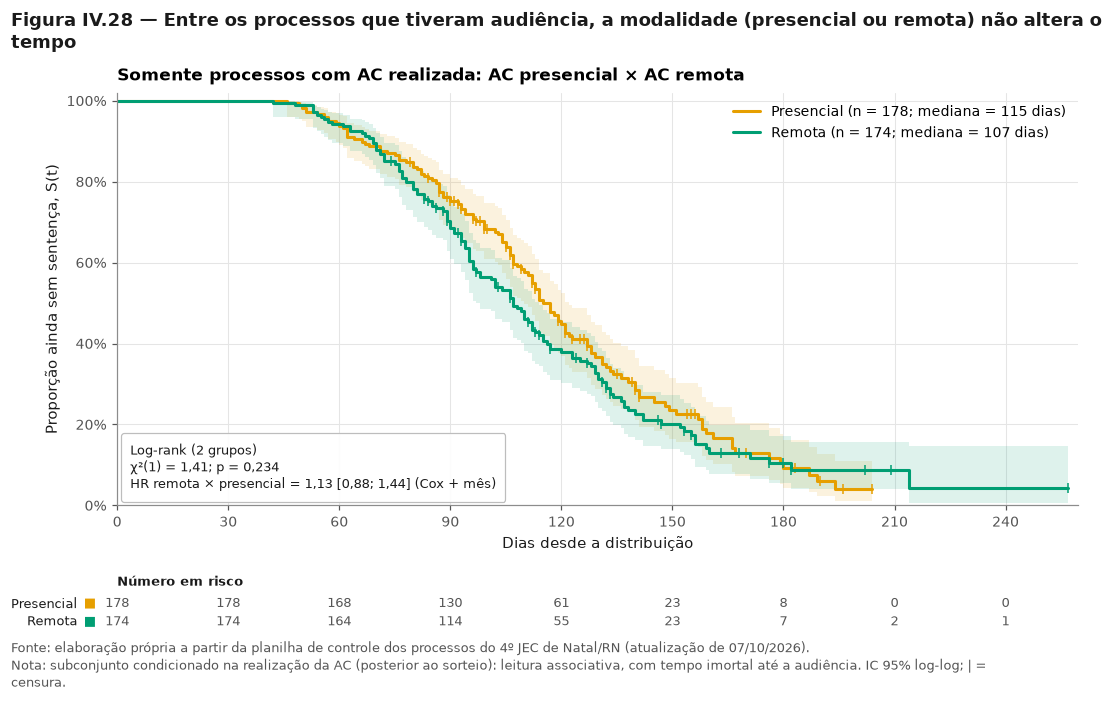

In [63]:
ac = sob[(sob.grupo != 'Controle') & (sob['ac_realizada'] == True)].copy()
ac['grupo2'] = ac['grupo'].astype(str)
print(f'Processos com AC realizada: {len(ac)} (Presencial {(ac.grupo2 == "Presencial").sum()}, Remota {(ac.grupo2 == "Remota").sum()}); '
      f'sentenças {ac.E.sum()}')
_ct = pd.crosstab(ac['grupo2'], ac['tipo_desfecho'].astype(str))
_ct = _ct[[c for c in ORDEM_DESFECHO if c in _ct.columns]].rename(columns=ROTULO_DESFECHO)
_ct.columns.name = None
tabela(_ct.assign(Total=_ct.sum(axis=1)).rename_axis('Grupo'), 'sob_ac_desfechos',
       'Processos com AC realizada: tipo de desfecho por modalidade (frequências)', secao='4.8.1',
       formatos={c: 'int' for c in list(_ct.columns) + ['Total']})
km_ac = {g: KaplanMeierFitter(label=ROTULO_GRUPO[g]).fit(ac.loc[ac.grupo2 == g, 'T'], ac.loc[ac.grupo2 == g, 'E']) for g in ['Presencial', 'Remota']}
lr_ac = logrank_test(ac.loc[ac.grupo2 == 'Presencial', 'T'], ac.loc[ac.grupo2 == 'Remota', 'T'],
                     ac.loc[ac.grupo2 == 'Presencial', 'E'], ac.loc[ac.grupo2 == 'Remota', 'E'])
cox_ac = CoxPHFitter().fit(ac[['T', 'E', 'Remota'] + COLS_MES], 'T', 'E')
hr_ac = tabela_hr(cox_ac, ['Remota']); hr_ac.index = ['AC remota × AC presencial (com AC realizada)']
sob_tabela(hr_ac.rename_axis('Termo'), 'sob_ac_cox', 'Cox entre os processos com AC realizada: AC remota × AC presencial '
           '(ajustado por mês)', secao='4.8.1', casas=3, colunas_p=('p (Wald)',),
           nota='comparação observacional (condiciona na realização da AC, posterior ao sorteio).')
print(f"Log-rank Presencial × Remota (com AC): χ² = {fmt_br(lr_ac.test_statistic, 2)}, p = {p_br(lr_ac.p_value)}")
print('Medianas (dias): ' + '; '.join(f'{g} {fmt_br(km_ac[g].median_survival_time_, 0)}' for g in km_ac))

fig, ax = plt.subplots(figsize=(10, 5.4))
plot_km(ax, ac, tempo='T', evento='E', grupo='grupo2', ordem=['Presencial', 'Remota'], passo=30)
eixo_pct(ax)
ax.set_title('Somente processos com AC realizada: AC presencial × AC remota')
_h = hr_ac.iloc[0]
anotar_teste(ax, texto_teste('Log-rank (2 grupos)', f'χ²(1) = {fmt_br(lr_ac.test_statistic, 2)}', lr_ac.p_value,
                             f'HR remota × presencial = {fmt_br(_h["HR"], 2)} [{fmt_br(_h["IC 95% inf."], 2)}; '
                             f'{fmt_br(_h["IC 95% sup."], 2)}] (Cox + mês)'), loc='lower left')
figura(fig, 'sob_ac_modalidade', 'Entre os processos que tiveram audiência, a modalidade (presencial ou remota) não altera o tempo',
       secao='4.8.1', nota='subconjunto condicionado na realização da AC (posterior ao sorteio): leitura associativa, com tempo '
                           'imortal até a audiência. IC 95% log-log; | = censura.')

### 4.8.2 Técnica de conciliação e audiência híbrida

**Técnica.** Seis técnicas sorteadas entre as audiências. H₀: o tempo até a sentença não depende da técnica. Teste: log-rank de 6 grupos (5 g.l.) e Cox com a técnica (referência = Padrões objetivos, a mais frequente) ajustado por modalidade e mês. Com ~47 a 67 processos por técnica, o poder para diferenças moderadas é baixo: um resultado não significativo **não** demonstra equivalência.

**Híbrida.** Audiência pautada como presencial em que uma parte participou remotamente (Res. CNJ 481/2022). É uma decisão posterior ao sorteio, tomada a pedido da parte: comparar híbridas com presenciais puras é observacional (o pedido pode estar associado ao perfil da parte). Restringe-se ao grupo Presencial com AC realizada.

Log-rank entre as 6 técnicas: χ² = 1,55, 5 g.l., p = 0,908


Técnica (vs. referência),HR,IC 95% inf.,IC 95% sup.,p (Wald)
Comunicação × Padrões objetivos,"1,197","0,8","1,8","0,393"
Separação × Padrões objetivos,"1,275","0,8","1,9","0,246"
Afago × Padrões objetivos,"1,041","0,7","1,6","0,852"
Parafraseamento × Padrões objetivos,"1,063","0,7","1,6","0,768"
Desconstrução × Padrões objetivos,"1,097","0,7","1,7","0,690"


Presencial com AC: híbridas 24, presenciais puras 154 | log-rank p = 0,907


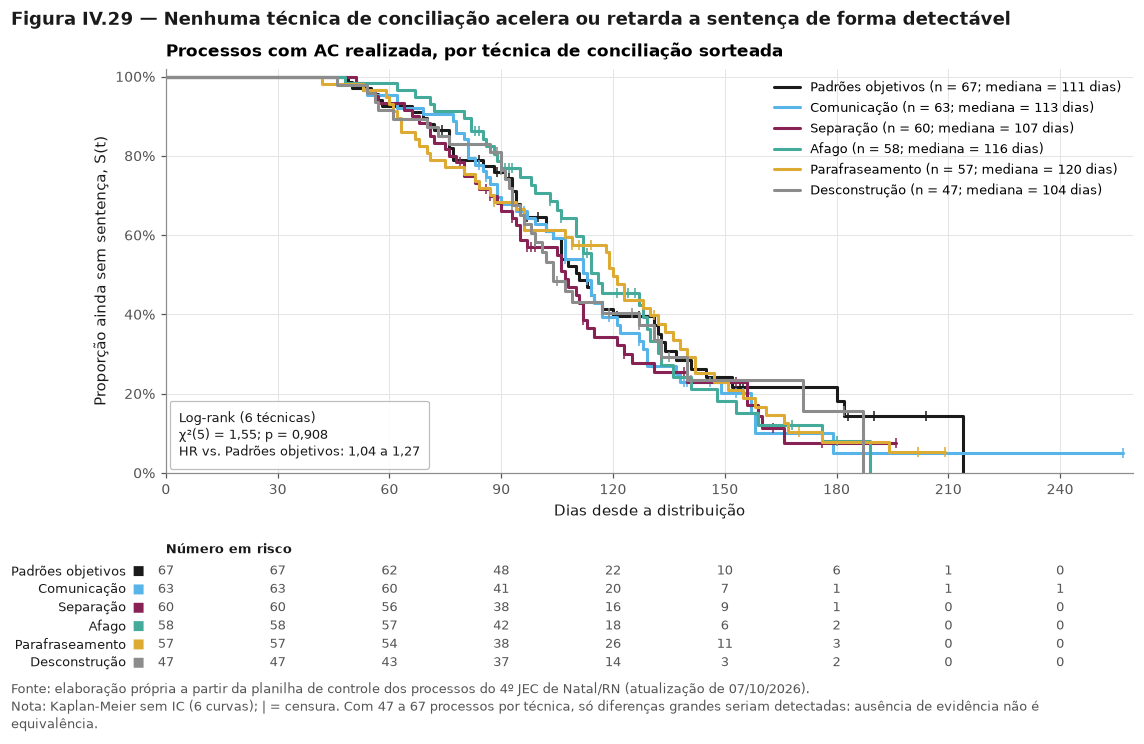

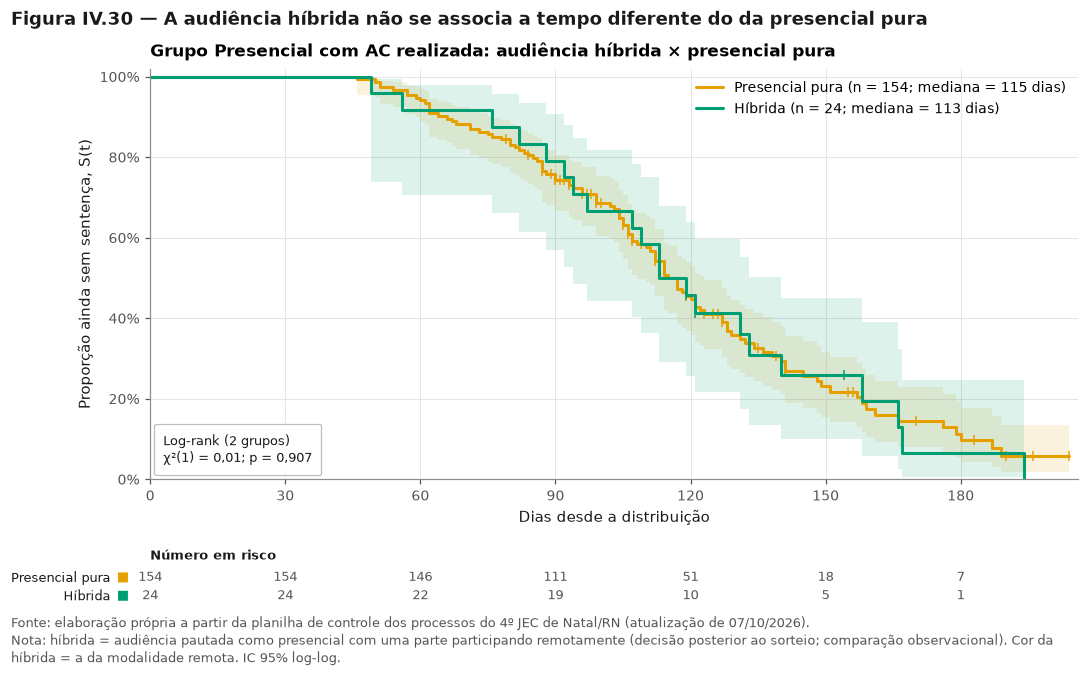

In [64]:
ac['tec'] = ac['tecnica_curta'].astype(str)
ORDEM_TEC = ac['tec'].value_counts().index.tolist()
lr_tec = multivariate_logrank_test(ac['T'], ac['tec'], ac['E'])
for t in ORDEM_TEC[1:]:
    ac[f'tec_{t}'] = (ac['tec'] == t).astype(int)
cols_tec = [f'tec_{t}' for t in ORDEM_TEC[1:]]
cox_tec = CoxPHFitter().fit(ac[['T', 'E', 'Remota'] + COLS_MES + cols_tec], 'T', 'E')
hr_tec = tabela_hr(cox_tec, cols_tec); hr_tec.index = [f'{t} × {ORDEM_TEC[0]}' for t in ORDEM_TEC[1:]]
print(f'Log-rank entre as 6 técnicas: χ² = {fmt_br(lr_tec.test_statistic, 2)}, {lr_tec.degrees_of_freedom} g.l., p = {p_br(lr_tec.p_value)}')
sob_tabela(hr_tec.rename_axis('Técnica (vs. referência)'), 'sob_ac_tecnica_cox',
           f'Cox da técnica de conciliação (referência = {ORDEM_TEC[0]}), ajustado por modalidade e mês', secao='4.8.2',
           casas=3, colunas_p=('p (Wald)',),
           nota=f'log-rank entre as 6 técnicas: χ² = {fmt_br(lr_tec.test_statistic, 2)} ({lr_tec.degrees_of_freedom} g.l.); '
                f'{p_txt(lr_tec.p_value)}.')

pres_ac = ac[ac.grupo2 == 'Presencial'].copy()
pres_ac['hib'] = pres_ac['hibrida'].fillna(False).astype(int)
lr_hib = logrank_test(pres_ac.loc[pres_ac.hib == 1, 'T'], pres_ac.loc[pres_ac.hib == 0, 'T'],
                      pres_ac.loc[pres_ac.hib == 1, 'E'], pres_ac.loc[pres_ac.hib == 0, 'E'])
print(f'Presencial com AC: híbridas {pres_ac.hib.sum()}, presenciais puras {(pres_ac.hib == 0).sum()} | '
      f'log-rank p = {p_br(lr_hib.p_value)}')

# técnicas: paleta própria (nenhuma cor de grupo, de desfecho ou de destaque)
CORES_TEC = dict(zip(ORDEM_TEC, ['#1a1a1a', '#56B4E9', '#882255', '#44AA99', '#DDAA33', '#8C8C8C']))
fig, ax = plt.subplots(figsize=(10.5, 6))
plot_km(ax, ac, tempo='T', evento='E', grupo='tec', ordem=ORDEM_TEC, cores=CORES_TEC, ic=False, passo=30, legenda=False)
eixo_pct(ax)
ax.legend(loc='upper right', fontsize=8.5)
ax.set_title('Processos com AC realizada, por técnica de conciliação sorteada')
anotar_teste(ax, texto_teste(f'Log-rank ({len(ORDEM_TEC)} técnicas)',
                             f'χ²({lr_tec.degrees_of_freedom}) = {fmt_br(lr_tec.test_statistic, 2)}', lr_tec.p_value,
                             f'HR vs. {ORDEM_TEC[0]}: {fmt_br(hr_tec["HR"].min(), 2)} a {fmt_br(hr_tec["HR"].max(), 2)}'),
             loc='lower left')
figura(fig, 'sob_ac_tecnica', 'Nenhuma técnica de conciliação acelera ou retarda a sentença de forma detectável',
       secao='4.8.2', nota='Kaplan-Meier sem IC (6 curvas); | = censura. Com 47 a 67 processos por técnica, só diferenças grandes '
                           'seriam detectadas: ausência de evidência não é equivalência.')

pres_ac['hib_txt'] = np.where(pres_ac['hib'] == 1, 'Híbrida', 'Presencial pura')
fig, ax = plt.subplots(figsize=(10, 5.4))
plot_km(ax, pres_ac, tempo='T', evento='E', grupo='hib_txt', ordem=['Presencial pura', 'Híbrida'],
        cores={'Presencial pura': CORES_GRUPO['Presencial'], 'Híbrida': CORES_GRUPO['Remota']}, passo=30)
eixo_pct(ax)
ax.set_title('Grupo Presencial com AC realizada: audiência híbrida × presencial pura')
anotar_teste(ax, texto_teste('Log-rank (2 grupos)', f'χ²(1) = {fmt_br(lr_hib.test_statistic, 2)}', lr_hib.p_value),
             loc='lower left')
figura(fig, 'sob_ac_hibrida', 'A audiência híbrida não se associa a tempo diferente do da presencial pura',
       secao='4.8.2', nota='híbrida = audiência pautada como presencial com uma parte participando remotamente (decisão posterior '
                           'ao sorteio; comparação observacional). Cor da híbrida = a da modalidade remota. IC 95% log-log.')

**Interpretação (subconjunto com AC realizada).**

- **Tamanho e composição.** 352 processos tiveram AC realizada (178 presenciais e 174 remotos). Os perfis de desfecho diferem: a remota tem mais extinções sem mérito (35 contra 20) e mais acordos (19 contra 14), e a presencial tem mais mérito (94 contra 81).
- **Modalidade.** Entre quem teve AC, a remota não difere da presencial: HR = 1,13 (0,88–1,44; p = 0,34) ajustado pelo mês; log-rank p = 0,234; medianas de 115 e 107 dias.
- **Tempo imortal.** Essas medianas são **maiores** que as dos grupos inteiros (96 e 95 dias), justamente porque quem teve AC precisou estar pendente até a data da audiência. Comparar esses processos com os que não tiveram AC (ou com o Controle) atribuiria à audiência um atraso que é, em parte, mecânico.
- **Técnica de conciliação.** Nenhuma diferença: log-rank de 6 grupos com χ²₅ = 1,55, p = 0,908; HRs entre 1,04 e 1,28 em relação a Padrões objetivos, todos com IC contendo 1. Com 47 a 67 processos por técnica, o estudo só detectaria diferenças grandes. A conclusão é "sem evidência de efeito da técnica sobre o tempo", não "técnicas equivalentes".
- **Audiência híbrida.** Dentro do grupo Presencial com AC, as 24 híbridas e as 154 presenciais puras têm tempos indistinguíveis (log-rank p = 0,907).
- **Ressalva.** Os três contrastes são **associativos**. Só a técnica foi sorteada, e mesmo ela só existe para quem chegou à audiência. A análise de *landmark* adequada exigiria a data da AC, que a planilha não registra: é um item a coletar numa replicação (via PJe/DataJud).

---

## 4.9 Análises de sensibilidade

Cada decisão de curadoria da Parte I (o que é evento, quem fica na base, como tratar datas suspeitas) poderia, em tese, mudar a conclusão. A tabela abaixo refaz a análise principal — **Cox grupo + mês (Efron)** e **log-rank de 3 grupos** — sob cenários alternativos. A conclusão é robusta se o HR e o p-valor mudarem pouco.

| Cenário | O que muda | Por quê |
|---|---|---|
| Principal | redistribuição censurada em T | análise de referência |
| (i-a) Redistribuição excluída | retira os 24 processos "Decisão" | eles saíram do juízo antes de receber o tratamento (inelegíveis pós-sorteio) |
| (i-b) Redistribuição competitiva | Fine-Gray da sentença (redistribuição competidora; log-rank → teste de permutação tipo Gray não repetido) | efeito sobre a incidência acumulada de sentença |
| (ii) Sem origem externa | retira os 12 processos vindos de outro órgão | chegaram com tramitação anterior |
| (iii-a) Sem desvio de protocolo | retira os 6 casos de híbrida incongruente (A12/A13) | registro duvidoso |
| (iii-b) Híbridas "como tratadas" | as 28 híbridas do grupo Presencial passam ao grupo Remota | parte participou remotamente (*as-treated*, não ITT) |
| (iv) Com as duplicatas | inclui as 6 linhas excluídas (reentradas e duplicatas) | E3: checar se a regra de exclusão importa |
| (v-a) Fim de semana deslocado | desfechos datados em sábado/domingo passam para a segunda-feira | A16: data de assinatura × data útil |
| (v-b) Fim de semana excluído | retira os 135 processos com desfecho em fim de semana | caso extremo (viesado: retira só eventos) |
| (vi) Censura comum em 65 dias | todos censurados em 65 dias (o menor seguimento) | neutraliza a entrada escalonada por completo |
| (vii) Dados ingênuos | "Decisão" contada como evento (como no notebook do professor, E10) | mostra o efeito do erro |
| (viii) Sem tempos zero | retira os 38 desfechos no dia da distribuição | A15: possíveis erros de data |

Cenário,n,sentenças,HR Presencial,IC P inf.,IC P sup.,HR Remota,IC R inf.,IC R sup.,p log-rank
Principal,938,708,"0,863","0,722","1,032","0,810","0,676","0,972","0,023"
(i-a) Redistribuição excluída,914,708,"0,865","0,723","1,035","0,817","0,681","0,980","0,028"
(i-b) Redistribuição competitiva (Fine-Gray),938,708,"0,805","0,674","0,963","0,770","0,642","0,923",–
(ii) Sem origem externa,926,699,"0,870","0,727","1,042","0,805","0,671","0,966","0,022"
(iii-a) Sem desvio de protocolo,932,704,"0,854","0,714","1,022","0,816","0,681","0,979","0,026"
(iii-b) Híbridas como tratadas (28 → Remota),938,708,"0,896","0,745","1,077","0,792","0,664","0,945","0,013"
(iv) Com as duplicatas (n = 944),944,708,"0,848","0,709","1,014","0,803","0,669","0,963","0,014"
(v-a) Fim de semana → segunda-feira,938,708,"0,863","0,721","1,032","0,810","0,675","0,971","0,023"
(v-b) Fim de semana excluído,803,573,"0,878","0,720","1,071","0,806","0,658","0,987","0,033"
(vi) Censura comum em 65 dias,938,305,"1,042","0,800","1,359","0,798","0,601","1,059","0,075"


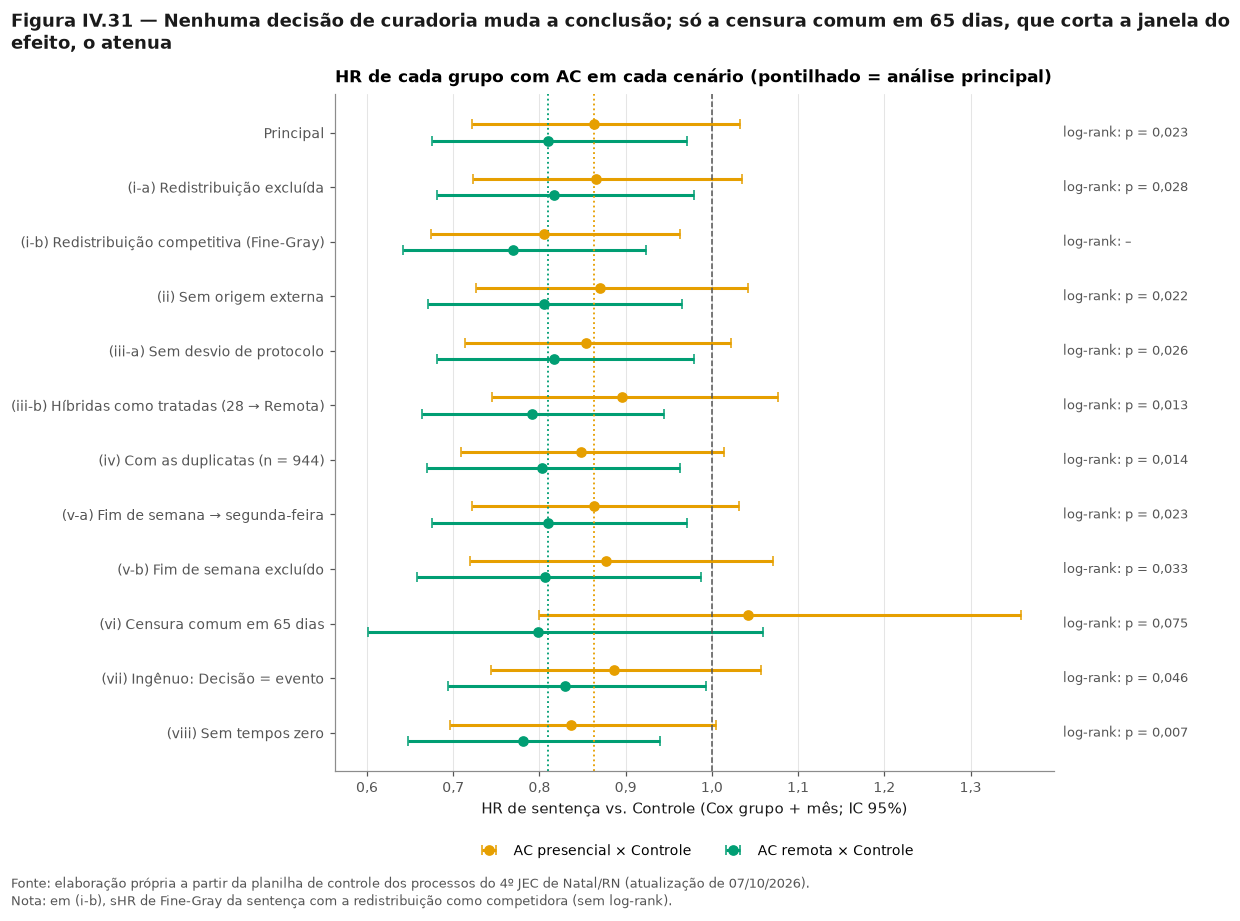

In [65]:
def cenario(df, nome, fine_gray=False):
    df = df[df['T'].notna()]
    if fine_gray:
        m = fine_gray_censura_conhecida(df, 1, X_CS)  # causa 1 aqui = sentença (K redefinido)
    else:
        m = CoxPHFitter().fit(df[['T', 'E'] + X_CS], 'T', 'E')
    t = tabela_hr(m, X_BASE, rotulo='HR')
    lr = multivariate_logrank_test(df['T'], df['grupo'].astype(str), df['E'])
    return {'Cenário': nome, 'n': len(df), 'sentenças': int(df['E'].sum()),
            'HR Presencial': t.iloc[0, 0], 'IC P inf.': t.iloc[0, 1], 'IC P sup.': t.iloc[0, 2],
            'HR Remota': t.iloc[1, 0], 'IC R inf.': t.iloc[1, 1], 'IC R sup.': t.iloc[1, 2],
            'p log-rank': lr.p_value if not fine_gray else np.nan}

sens = [cenario(sob, 'Principal')]
sens.append(cenario(sob[sob.CR != 2], '(i-a) Redistribuição excluída'))
sens.append(cenario(sob.assign(K=sob['CR']), '(i-b) Redistribuição competitiva (Fine-Gray)', fine_gray=True))
sens.append(cenario(sob[sob.origem_ext == 0], '(ii) Sem origem externa'))
sens.append(cenario(sob[~sob['desvio_protocolo'].astype(bool)], '(iii-a) Sem desvio de protocolo'))
_as = sob.copy()
_hib = (_as.grupo == 'Presencial') & (_as['hibrida'].fillna(False).astype(bool))
_as.loc[_hib, 'grupo'] = 'Remota'; _as['Presencial'] = (_as.grupo == 'Presencial').astype(int); _as['Remota'] = (_as.grupo == 'Remota').astype(int)
sens.append(cenario(_as, f'(iii-b) Híbridas como tratadas ({_hib.sum()} → Remota)'))
todas = pd.read_pickle(PROC / 'ed2_todas_linhas.pkl')
todas = todas[todas['tempo'].notna() & todas['evento'].notna()]
sens.append(cenario(preparar_sob(todas), f'(iv) Com as duplicatas (n = {len(todas)})'))
_fs = sob.copy()
_dow = _fs['dt_sentenca'].dt.dayofweek
_fs['T'] = _fs['T'] + np.where((_fs.CR > 0) & (_dow == 5), 2, 0) + np.where((_fs.CR > 0) & (_dow == 6), 1, 0)
sens.append(cenario(_fs, '(v-a) Fim de semana → segunda-feira'))
sens.append(cenario(sob[~sob['sentenca_fim_semana'].fillna(False).astype(bool)], '(v-b) Fim de semana excluído'))
_65 = sob.copy(); _65['E'] = ((_65.E == 1) & (_65['T'] <= 65)).astype(int); _65['T'] = _65['T'].clip(upper=65)
sens.append(cenario(_65, '(vi) Censura comum em 65 dias'))
sens.append(cenario(sob.assign(E=(sob.CR > 0).astype(int)), '(vii) Ingênuo: Decisão = evento'))
sens.append(cenario(sob[~sob['tempo_zero'].astype(bool)], '(viii) Sem tempos zero'))
SENS = pd.DataFrame(sens).set_index('Cenário')
sob_tabela(SENS, 'sob_sensibilidade', 'Sensibilidade do efeito do rito às decisões de curadoria (Cox grupo + mês e log-rank)',
           secao='4.9', casas=3, colunas_p=('p log-rank',), formatos={'n': 'int', 'sentenças': 'int'},
           nota='HR < 1 = sentença mais lenta que no Controle; IC 95% de Wald. No cenário (i-b), sHR de Fine-Gray e log-rank não '
                'aplicável (–). Destaque: log-rank p < 0,05.')

fig, ax = plt.subplots(figsize=(11, 7.5))
y = np.arange(len(SENS))[::-1]
for desl, g, col in [(0.15, 'Presencial', 'P'), (-0.15, 'Remota', 'R')]:
    hr = SENS[f'HR {g}']; li = SENS[f'IC {col} inf.']; ls = SENS[f'IC {col} sup.']
    ax.errorbar(hr, y + desl, xerr=[hr - li, ls - hr], fmt='o', ms=6, color=CORES_GRUPO[g], capsize=3, label=ROTULO_TERMO[g])
ax.axvline(1, color=TINTA_2, ls='--', lw=1)
ax.axvline(SENS.loc['Principal', 'HR Presencial'], color=CORES_GRUPO['Presencial'], ls=':', lw=1.2)
ax.axvline(SENS.loc['Principal', 'HR Remota'], color=CORES_GRUPO['Remota'], ls=':', lw=1.2)
for yi, pv in zip(y, SENS['p log-rank']):
    ax.annotate('log-rank: –' if pd.isna(pv) else f'log-rank: {p_txt(pv)}', (1, yi), xycoords=('axes fraction', 'data'),
                xytext=(6, 0), textcoords='offset points', va='center', fontsize=8.5, color=TINTA_2)
ax.set_yticks(y, SENS.index, fontsize=9); ax.set_ylim(-0.7, len(SENS) - 0.3)
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
ax.set_xlabel('HR de sentença vs. Controle (Cox grupo + mês; IC 95%)')
ax.set_title('HR de cada grupo com AC em cada cenário (pontilhado = análise principal)')
legenda_abaixo(ax, ncol=2, dy=-0.09)
figura(fig, 'sob_sensibilidade', 'Nenhuma decisão de curadoria muda a conclusão; só a censura comum em 65 dias, que corta '
       'a janela do efeito, o atenua', secao='4.9',
       nota='em (i-b), sHR de Fine-Gray da sentença com a redistribuição como competidora (sem log-rank).')

**Interpretação (sensibilidade).**

- **Robustez geral.** Em 11 dos 12 cenários, os HRs ficam em faixas estreitas e o log-rank continua significativo (p de 0,007 a 0,046):
  - **0,84–0,90 para a AC presencial**, com IC contendo ou tocando 1 em todos os cenários, exceto no Fine-Gray (i-b), em que o sHR é 0,81 (0,67–0,96);
  - **0,77–0,83 para a AC remota**, com IC sempre abaixo de 1.

  Excluir as redistribuições, a origem externa, os desvios de protocolo ou os tempos zero, reincluir as duplicatas, deslocar ou excluir as sentenças de fim de semana: **nenhuma decisão de curadoria muda a conclusão**.
- **(iii-b) Híbridas "como tratadas".** Passar as 28 híbridas para o grupo Remota aproxima a presencial de 1 (HR = 0,90) e fortalece a remota (0,79; log-rank p = 0,013). A conclusão não muda.
- **(i-b) Redistribuição como competidora (Fine-Gray da sentença).** Os sHR (0,81 e 0,77) são um pouco **menores** que os HRs, porque os grupos com AC têm o dobro de redistribuições: menos processos chegam a ter sentença no 4º JEC.
- **(vii) Dados ingênuos ("Decisão" = evento, como o notebook do professor; E10).** O efeito fica atenuado (HR = 0,89 e 0,83; log-rank p = 0,046): contar redistribuições como sentenças "acelera" artificialmente os grupos que mais as têm.
- **(vi) Censura comum em 65 dias: a exceção esperada.** HR = 1,04 (0,80–1,36) na presencial e 0,80 (0,60–1,06) na remota; p = 0,075. Até 65 dias o efeito da AC ainda não apareceu (seção 4.5.2: a diferença está na janela de 30 a 90 dias e sobretudo depois de 60). Esse cenário não refuta o resultado principal; mostra **em que momento** ele surge. Para neutralizar a entrada escalonada sem perder a janela relevante, a estratégia adequada é a estratificação por mês (4.3.4 e modelo b′), que mantém o efeito (p = 0,045 e HR remota = 0,80).

---

## 4.10 Síntese da análise de sobrevivência

A tabela reúne as medidas de efeito principais. Elas respondem a perguntas complementares: a **mediana** e o **RMST** em dias (escala de tempo), o **HR** em taxa diária (escala de risco), a **razão de tempos** do AFT e a **FIA a 90 dias** por tipo de desfecho (o que acontece com os processos).

In [66]:
sint = {}
for g in ORDEM_GRUPO:
    q = quartis.loc[ROTULO_GRUPO[g], 'Mediana']
    r180 = rmst_tab.query('`τ (dias)` == 180 and Grupo == @g').iloc[0]
    linha = {'n': int((sob.grupo == g).sum()), 'Sentenças': int(sob.loc[sob.grupo == g, 'E'].sum()),
             'Mediana KM, dias (IC 95%)': q,
             'RMST 180 d, dias (IC 95%)': f"{fmt_br(r180['RMST (dias)'], 1)} ({fmt_br(r180['IC 95% inf.'], 1)}–{fmt_br(r180['IC 95% sup.'], 1)})"}
    if g == 'Controle':
        linha |= {'ΔRMST 180 d vs. Controle (IC bootstrap)': 'referência', 'HR Cox (b) (IC 95%)': 'referência',
                  f'Razão de tempos {MELHOR_AFT} (IC 95%)': 'referência'}
    else:
        d = dif_rmst.query('`τ (dias)` == 180 and Contraste == @g + " − Controle"').iloc[0]
        h = HR_B.loc[ROTULO_TERMO[g]]
        tr = TR_AFT[(TR_AFT.Modelo == MELHOR_AFT)].loc[ROTULO_TERMO[g]]
        linha |= {'ΔRMST 180 d vs. Controle (IC bootstrap)': f"{fmt_br(d['Diferença (dias)'], 1)} ({fmt_br(d['IC 95% inf. (bootstrap)'], 1)} a {fmt_br(d['IC 95% sup. (bootstrap)'], 1)})",
                  'HR Cox (b) (IC 95%)': f"{fmt_br(h['HR'], 2)} ({fmt_br(h['IC 95% inf.'], 2)}–{fmt_br(h['IC 95% sup.'], 2)})",
                  f'Razão de tempos {MELHOR_AFT} (IC 95%)': f"{fmt_br(tr['Razão de tempos'], 2)} ({fmt_br(tr['IC 95% inf.'], 2)}–{fmt_br(tr['IC 95% sup.'], 2)})"}
    for k in (1, 2, 3):
        linha[f'FIA 90 d: {CAUSAS[k]}'] = CIF_TAB.loc[(CAUSAS[k], 90), g]
    sint[ROTULO_GRUPO[g]] = linha
SINTESE_SOB = pd.DataFrame(sint)
tabela(SINTESE_SOB.rename_axis('Medida'), 'sob_sintese', 'Síntese das medidas de efeito da análise de sobrevivência',
       secao='4.10', formatos={c: 'texto' for c in SINTESE_SOB.columns},
       nota='IC 95% entre parênteses. Mediana e RMST em dias; HR < 1 e razão de tempos > 1 = sentença mais lenta que no '
            'Controle; FIA = incidência acumulada (Aalen-Johansen).')
print(f"Testes globais: log-rank p = {p_br(lr_global.p_value)}; estratificado por mês p = {p_br(LR_ESTRAT_P)}; "
      f"riscos proporcionais violados? TRV janelas p = {p_br(P_TRV_C)}")
SINTESE_SOB.to_csv(PROC / 'ed2_sintese_sobrevivencia.csv', sep=';', encoding='utf-8-sig')

Medida,"Controle (rito atual, AC opcional)",AC presencial obrigatória,AC remota obrigatória
n,313,314,311
Sentenças,262,230,216
"Mediana KM, dias (IC 95%)",81 (75–84),96 (85–106),95 (89–102)
"RMST 180 d, dias (IC 95%)","82,1 (76,0–88,0)","88,6 (82,0–95,3)","92,9 (86,9–99,4)"
ΔRMST 180 d vs. Controle (IC bootstrap),referência,"6,5 (-2,1 a 15,8)","10,7 (1,9 a 19,5)"
HR Cox (b) (IC 95%),referência,"0,87 (0,72–1,04)","0,81 (0,67–0,97)"
Razão de tempos Weibull (IC 95%),referência,"1,11 (0,93–1,34)","1,21 (1,00–1,45)"
FIA 90 d: Homologação,"4,9% (2,5%–7,3%)","6,4% (3,7%–9,2%)","10,6% (7,0%–14,1%)"
FIA 90 d: Mérito,"31,1% (25,8%–36,3%)","7,8% (4,8%–10,9%)","7,5% (4,3%–10,6%)"
FIA 90 d: Sem mérito,"23,5% (18,8%–28,2%)","32,0% (26,8%–37,2%)","27,3% (22,3%–32,4%)"


Testes globais: log-rank p = 0,023; estratificado por mês p = 0,045; riscos proporcionais violados? TRV janelas p = 0,026


**Síntese e resposta à pergunta de pesquisa 2.**

**A AC obrigatória altera o tempo até a sentença?** Sim, e no sentido de **alongá-lo**, contra a expectativa que motivou o experimento.

| Medida | Controle | AC presencial | AC remota |
|---|---|---|---|
| Mediana (dias) | 81 | 96 | 95 |
| RMST em 180 dias (dias) | 82,1 | 88,6 | 92,9 |
| HR ajustado (Cox b) | referência | 0,87 (0,72–1,04) | 0,81 (0,67–0,97) |

- O log-rank global dá p = 0,023, e o estratificado por mês, p = 0,045.
- **Remota:** o efeito é estatisticamente sólido. ΔRMST₁₈₀ = +10,7 dias (IC 1,9 a 19,5); HR = 0,81; resultado robusto em 11 de 12 cenários de sensibilidade.
- **Presencial:** a direção é a mesma (+6,5 dias; HR = 0,87), mas o IC inclui o efeito nulo. Os dados não permitem afirmar que a presencial seja mais lenta que o Controle **no tempo total**.

**Quando o atraso acontece.** O atraso não é uniforme: concentra-se entre 30 e 90 dias (HR ≈ 0,62 nos dois grupos com AC), quando as audiências obrigatórias estão em pauta. Aos 90 dias, cerca de 13 a 14 p.p. a mais de processos estão sem sentença. Depois de 90 dias as taxas se igualam, mas o atraso já acumulado não é recuperado.

**A modalidade importa?** Para o **tempo**, não: Remota × Presencial tem log-rank p = 0,52, e entre os processos com AC realizada, HR = 1,13 (p = 0,34). Para **como** o processo termina, há indícios de diferença:

- a presencial produz mais extinções sem mérito (sHR = 1,46);
- a remota produz mais acordos (sHR = 1,87);
- ambas reduzem os julgamentos de mérito à metade (sHR ≈ 0,42–0,46).

**O achado principal é de mecanismo.** A comparação do tempo total **mascara efeitos opostos**: a AC obrigatória acelera extinções e acordos, mas atrasa fortemente o julgamento de mérito. Para a política judiciária, isso desloca a pergunta de "o rito é mais rápido?" para "o rito resolve mais conflitos?". Um ganho de acordos na remota (de 7,6% para 12,9% aos 180 dias) convive com mais extinções sem resolução e com menos e mais tardias decisões de mérito.

**Limitações.**

- O seguimento é curto: a cauda além de 180 dias não é estimável, e a pauta remota se estende até 24/11/2026.
- A data da AC não foi registrada, o que impede *landmark* e covariável tempo-dependente da audiência.
- O motivo da extinção sem mérito (ausência do autor ou outro) não está codificado; a hipótese do art. 51, I, é **compatível** com os dados, mas não verificada diretamente.
- É uma única unidade judiciária (validade externa).